**Farley Lab Group Thermochr(onology Data R)eduction at Caltech**

Ben J. Thyer, September 2022

TOC:

> 1. Dependencies
> 2. **Control Board**
> 3. Agilent 8800 ICP-MS
> > 3a. _Optional Manual Quality Control_
> 4. Pfeiffer Vacuum Prisma QMS 200 Quadrupole Mass Spectrometer
> 5. _Manual (U-Th-Sm)/He Age Calculator_
> 6. _Manual Alpha Recoil Retention Factor (Ft) Calculator_
> 7. Statement of assumptions
> 8. Works Cited

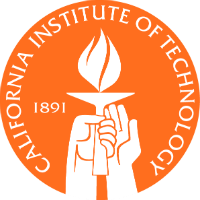

> **1. Dependencies**

Assuming all standards analyzed had 157.5 nCCSTP 4He and 3.57 pCCSTP 3He


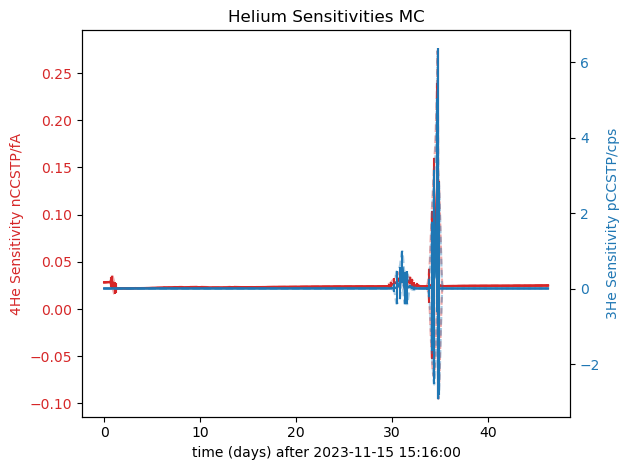

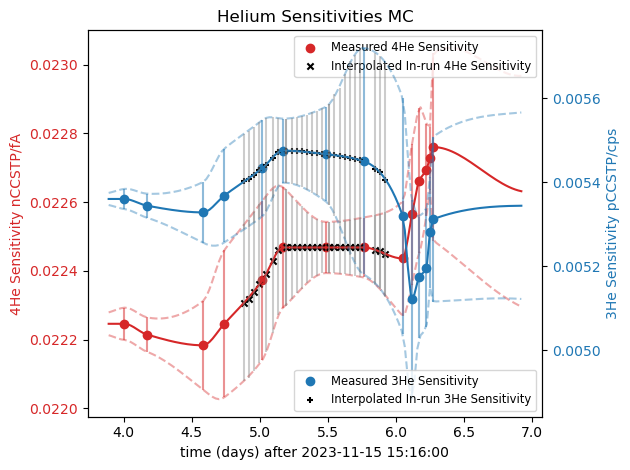

In [1]:
"""Run this first to install and/or load packages and homemade funtions Thermochedruction depends on"""
try:
    import pandas as pd
except:
    ! pip install pandas
    import pandas as pd
try:
    import numpy as np
except:
    ! pip install numpy
    import numpy as np
try:
    import matplotlib.pyplot as plt
except:
    ! pip install matplotlib
    import matplotlib.pyplot as plt
import matplotlib as mpl
try:
    from molmass import Formula  
except:
    ! pip install molmass
    from molmass import Formula 
try:
    import os
except:
    ! pip install os

try:
    from datetime import datetime
except:
    ! pip install datetime
    from dateime import datetime
    
#from scipy.interpolate import UnivariateSpline

import scipy.optimize
import scipy.interpolate

from matplotlib.legend_handler import HandlerTuple

plt.rcParams.update({
    "text.usetex": False,
    "font.family": 'DejaVu Sans'
})
    
def pull_number(string):
    """Pulls workable numbers from a string"""
    assert isinstance(string, str), 'Only a single string accepted'
    number_string = str('')
    for letter in string:
        if letter in '1234567890.':
            number_string += letter
    return float(number_string)

def remove_spaces(string):
    """Removes spaces in a string, returns space-free string"""
    assert isinstance(string, str), 'Only a single string accepted'
    spaceless = str('')
    for letter in string:
        if letter != ' ':
            spaceless += letter
    return spaceless

def outlier_stats(vector):
    """Function that removes outliers and returns mean and sd of vector, ignores nans"""
    nanloc = np.isnan(vector)
    vector = np.delete(vector, np.where(nanloc))
    x = np.mean(vector)
    s = np.std(vector)
    vector_copy = vector.flatten()[np.where(((x+(2*s)) > vector.flatten())*(vector.flatten() > (x-(2*s))))]
    xn = np.mean(vector_copy)
    sn = np.std(vector_copy)
    if xn != x:
        comment = 'Outlier Corrected '
    else:
        comment = ''
    return xn, sn, comment

lam_U238 = 1.55135895e-10
lam_U235 = 9.84584063e-10
lam_Th232 = np.log(2)/1.405E10
lam_Sm147 = np.log(2)/1.0625E11
Av = 6.0221408E23

def He_forward(U_mol, Th_mol, Sm_mol, t):
    Sm_at = Sm_mol*Av
    Th_at = Th_mol*Av
    U_at = U_mol*Av
    He_at = (8*(1-(1/137.88))*U_at*(np.exp(lam_U238*t)-1)) + (7*(U_at/137.88)*(np.exp(lam_U235*t)-1)) + (6*Th_at*(np.exp(lam_Th232*t)-1)) + (Sm_at*Formula('Sm').spectrum()[147][1]*(np.exp(lam_Sm147*t)-1))
    He_ncc = ((He_at/6.0221E23) * 22.71) * 1E12
    return He_ncc

def He_residual(t, He_ncc, U_mol, Th_mol, Sm_mol):
    Sm_at = Sm_mol*Av
    Th_at = Th_mol*Av
    U_at = U_mol*Av
    He_at = (8*(1-(1/137.88))*U_at*(np.exp(lam_U238*t)-1)) + (7*(U_at/137.88)*(np.exp(lam_U235*t)-1)) + (6*Th_at*(np.exp(lam_Th232*t)-1)) + (Sm_at*Formula('Sm').spectrum()[147][1]*(np.exp(lam_Sm147*t)-1))
    residual = He_ncc - (((He_at/6.0221E23) * 22.71) * 1E12)
    #print(f"{t/1E6}Ma: residual: {residual}")
    return residual

def He_derivative(t, U_mol, Th_mol, Sm_mol):
    Sm_at = Sm_mol*Av
    Th_at = Th_mol*Av
    U_at = U_mol*Av
    He_derivative_val =(((8*(1-(1/137.88))*U_at*lam_U238*(np.exp(lam_U238*t))) + (7*(U_at/137.88)*lam_U235*(np.exp(lam_U235*t))) + (6*Th_at*lam_Th232*(np.exp(lam_Th232*t))) + (Sm_at*Formula('Sm').spectrum()[147][1]*lam_Sm147*(np.exp(lam_Sm147*t))))/6.0221E23) * 22.71 * 1E12
    #print(f"derivative = {He_derivative_val}")
    return -1*He_derivative_val

#guess_const = (8*lam_U238)+((7/137.88)*lam_U235)
def MC_Age(inputArray, n = 1000, verbose = False):
    Hev = np.random.normal(inputArray[0],inputArray[1]/2,n)
    Uv = np.random.normal(inputArray[2],inputArray[3]/2,n)
    Thv = np.random.normal(inputArray[4],inputArray[5]/2,n)
    Smv = np.random.normal(inputArray[6],inputArray[7]/2,n)
    ages = []
    for i in range(n):
        He = Hev[i]
        U = Uv[i]
        Th = Thv[i]
        Sm = Smv[i]
        if He < 0: 
            He = 0
            #print("MC Random negative He")
        if U < 0:
            U = 0
            #print("MC Random negative U")
        if Th < 0: 
            Th = 0
            #print("MC Random negative Th")
        if Sm < 0: 
            Sm = 0
            #print("MC Random negative Sm")
        He_m = (He/(22.71*1E12)) #ncc -> mol
        eU = U + (0.24*Th)
        guess_t = He_m/(eU*lam_U238)
        #if guess_t > 4E9:
        #    guess_t = 4E9
        #print(f"Guess: eU*t*lam")
        def simple_res(t, verbose = verbose):
            res = He_residual(t, He, U, Th, Sm)
            if verbose: 
                print(f"At t = {t/1E6} Ma, Residual: {res}")
            return res
        def simple_d(t, verbose = verbose):
            delta = He_derivative(t, U, Th, Sm)
            if verbose:
                print(f"At t = {t/1E6} Ma, Derivative = {delta}")
            return delta
        age = scipy.optimize.newton(simple_res, guess_t, fprime=simple_d, tol = 1E-5, maxiter = 400)
        ages.append(age)
    return np.array([np.mean(np.array(ages))/1E6, 2*np.std(np.array(ages))/1E6])
    
                     
def isotope_dilution(Nb, Ra, Rb, Rab):
    """ Isotope Dilution equation that applies to two isotope systems or one isotope systems with an exotic isotope spike. 
    Returns unknown molar/atomic Na in the same units as known Nb given ratios of spike, target, and blend.
    Accepts Ra or Rb = 0 or infinity (numpy). 
    Also iterates to accept any length of input, so long as lengths are all 1 or the same.
    """
    lens = []
    for param in [Nb, Ra, Rb, Rab]:
        try:
            lens.append(len(param))
        except:
            lens.append(1)
    max_len = np.max(np.array(lens))
    assert all(lens) in [1, max], 'Improper lenths of parameters. Either 1 and a single non-1 number only'
    ans = []
    single = [leni == 1 for leni in lens]
    
    if single[0]:
        Nbi = Nb
    if single[1]:
        Rai = Ra
    if single[2]:
        Rbi = Rb
    if single[3]:
        Rabi = Rab
        
    for i in range(max_len):
        if single[0] == False:
            Nbi = Nb[i]
        if single[1] == False:
            Rai = Ra[i]
        if single[2] == False:
            Rbi = Rb[i]
        if single[3] == False:
            Rabi = Rab[i]
        
        if np.isinf(Rbi):
            T1 = 1
            T4 = 1
        else:
            T1 = (Rbi-Rabi)
            T4 = (1+Rbi)
        if np.isinf(Rai):
            T3 = 1
            T2 = -1
        else: 
            T2 = (Rabi-Rai)
            T3 = (1+Rai)
        ans.append(Nb*(T1/T2)*(T3/T4))
        
    return np.array(ans)

def iterative_solver(func, ans, epsilon = 0, bounds = [-1E15, 1E15], verbose = True, **kwargs):
    epsilon = np.abs(epsilon)
    if epsilon == 0:
        epsilon = np.abs(np.mean(ans)/1E6) # Default is to allow for one part in a million error
    test_X = np.linspace(bounds[0], bounds[1], 100)
    test_ans = []
    error = np.abs(epsilon)*2
    iterations = 0
    for kwa in kwargs:
        if isinstance(kwargs[kwa], str):
            unknown = kwa
    while np.abs(error) > np.abs(epsilon):
        for x in test_X:
            kwargs[unknown] = x
            test_ans.append(func(**kwargs))
        nan_ind = np.isnan(np.array(test_ans))
        test_X = np.delete(test_X, nan_ind)
        test_ans = np.delete(np.array(test_ans), nan_ind)
        winner_ind = np.argmin(np.abs(test_ans-ans))
        if winner_ind in [0,99]: # Reset to large default bounds if answer not found in original search
            bounds = [-1E15, 1E15]
            test_X = np.linspace(bounds[0], bounds[1], 100)
            test_ans = []
            for x in test_X:
                kwargs[unknown] = x
                test_ans.append(func(**kwargs))
            nan_ind = np.isnan(np.array(test_ans))
            test_X = np.delete(test_X, nan_ind)
            test_ans = np.delete(np.array(test_ans), nan_ind)
            winner_ind = np.argmin(np.abs(test_ans-ans))
        error = test_ans[winner_ind]-ans
        winner = test_X[winner_ind]
        test_X = np.linspace(test_X[winner_ind-1], test_X[winner_ind+1], 100)
        test_ans = []
        iterations += 1
    if verbose:
        print(f"Solved: {unknown} = {winner} which reproduces answer: {ans} with {np.abs(100*error/ans)}% error in {iterations} iterations")
    return winner

def mass_multiplier(Formula, normEl):
    """Function to return the multiplier from moles to mg's from a measurement of the normalizing element, 
    normEL of a phase with formula entered as a Formula object using molmass package
    """
    for element_data in Formula.composition():
        if element_data[0] == normEl:
            stochiometry = float(element_data[1])
    return 1000*Formula.mass/stochiometry # Units are mass-of-phase(mg)/moles-of-normEl

def He_Age(inputArray):
    auto_input = {
        'He': [inputArray[0],inputArray[1]], 
        'U': [inputArray[2],inputArray[3]],
        'Th': [inputArray[4],inputArray[5]],
        'Sm': [inputArray[6],inputArray[7]]
    }
    
    if np.sum(inputArray[3:]) == 0:
        #print('No Radionuclide Input for He age')
        return np.array([0,0])
    # Propagate errors by calculating 2 sigma upper and lower bounds in quadrature
    t_ans = iterative_solver(func = He_forward, ans = auto_input['He'][0], t = 'x',
                              U_mol = auto_input['U'][0], epsilon = auto_input['He'][0]/1E7,
                              Th_mol = auto_input['Th'][0], 
                              Sm_mol = auto_input['Sm'][0], verbose = False, bounds = [-1E6,5E9])
    errors = []
    for key in list(auto_input.keys()):
        auto_input[key][0] = auto_input[key][0] + auto_input[key][1]
        t_upper = iterative_solver(func = He_forward, ans = auto_input['He'][0], t = 'x',
                              U_mol = auto_input['U'][0], epsilon = auto_input['He'][0]/1E7,
                              Th_mol = auto_input['Th'][0], 
                              Sm_mol = auto_input['Sm'][0], verbose = False, bounds = [-1E6,5E9])
        errors.append(np.abs(t_ans-t_upper))
        auto_input[key][0] = auto_input[key][0] - 2*auto_input[key][1]
        t_lower = iterative_solver(func = He_forward, ans = auto_input['He'][0], t = 'x',
                              U_mol = auto_input['U'][0], epsilon = auto_input['He'][0]/1E7,
                              Th_mol = auto_input['Th'][0], 
                              Sm_mol = auto_input['Sm'][0], verbose = False, bounds = [-1E6,5E9])
        errors.append(np.abs(t_ans-t_lower))
        auto_input[key][0] = auto_input[key][0] + auto_input[key][1]
        #print(f"{key} Uppper Bound error: {100*np.abs(t_upper - t_ans)/t_ans}%\n{key} Lower Bound:{100*np.abs(t_lower - t_ans)/t_ans}%")
    error = np.sum((np.array(errors)**2)/2)**0.5 #2 sigma
    return np.array([t_ans, error])

def Ft(R, S, X):
    """Retention Factor Calculator. Input is Radius in microns and two vectors: 
    S: Length 4 numpy array Vector of mean stopping distances in microns for 238U, 235U, 232Th, 147Sm in that order
    X: Length 3 numpy array Vector U, Th, Sm abundances in atoms or moles"""
    total = (8*X[0]) + (7*X[0]/137.88) + (6*X[1]) + X[2]
    weights = np.array([8*X[0]/total, (7*(X[0]/137.88))/(total), 6*X[1]/total, Formula('Sm').spectrum()[147][1]*X[2]/total])
    fts = 1 - ((3/4)*(S/R)) + ((1/16)*((S**3)/(R**3)))
    ft = np.sum(fts*weights)
    return ft

def recoil_correct(r, inputArray):
    abundances = {
        'He': [inputArray[0],inputArray[1]], 
        'U': [inputArray[2],inputArray[3]],
        'Th': [inputArray[4],inputArray[5]],
        'Sm': [inputArray[6],inputArray[7]]
    }
    fts = []
    rs = np.random.normal(r[0], r[1]/2, 500)
    Us = np.random.normal(abundances['U'][0], abundances['U'][1]/2, 500)
    Ths = np.random.normal(abundances['Th'][0], abundances['Th'][1]/2, 500)
    Sms = np.random.normal(abundances['Sm'][0], abundances['Sm'][1]/2, 500)
    Hes = np.random.normal(abundances['He'][0], abundances['He'][1]/2, 500)
    for i in range(500):
        fts.append(Ft(R = rs[i], S = np.array(alpha_stopping_distances.loc[a_phase]), X = np.array([Us[i], Ths[i], Sms[i]])))
    Hes_corr = Hes/np.array(fts)
    ageInput = inputArray.copy()
    ageInput[0] = np.mean(Hes_corr)
    ageInput[1] = np.std(Hes_corr)*2
    return np.append(np.array([np.mean(fts), np.std(fts)*2, np.mean(Hes_corr), np.std(Hes_corr)*2]), He_Age(ageInput))

def MDD_diffusive_loss_correct(GDC, inputArray):
    FvLRD = GDC['FvLRD']
    HRD_def = GDC['HRD_deficit'] 
    newInput = inputArray.copy()
    correction = (inputArray[0]*FvLRD) + ((inputArray[0]/(1-HRD_def))-inputArray[0])
    newInput[0] += correction
    newInput[1] += correction # 100% error!
    return np.append(newInput[:2], He_Age(newInput))

def InvertFrequencyFactor(t, F, Fp): 
    """
    Time in Seconds, F: Cumulative yield of 1, Fp: previous cumulative yield
    EQN 5a-c from Fechtig and Kalbitzer, 1966
    """
    
    if F <= 0.1:
        D_a2 = ((F**2 - Fp**2)*np.pi) / (36*t)
    elif F < 0.9:
        D_a2 = (1/(np.pi**2*t)) * (   (((-(np.pi**2)/3) * (F - Fp))) + ( (-2*np.pi)* (((1-((np.pi/3)*F))**0.5) - ((1-((np.pi/3))*Fp)**0.5) )  )    ) 
    elif F < 1:
        D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )
    elif np.round(F, 3) == 1:
        return 0
    else:
        print(f"Time: {t/60} minutes; F = {F}; Fp = {Fp}")
        raise ValueError('Let F be fractional yield, within 0-1')
    return D_a2      

class Nonfunc:
    """class of objects that return their value repeated in an array of equal length to passed the array passed to its argument"""
    def __init__(self, value):
        self.v = value
    def __call__(self, vec = 1):
        return np.ones_like(vec) * self.v
    
def extract_times(dates):
    """Extracts cold blank times using Diff Cell timestamps"""
    times = [] # in seconds
    first = True
    closeT = False
    for stri in dates[1:]: # skipping first '\n'
        if first:
            oldtime = datetime.strptime(stri[1:-1], '%m/%d/%Y %I:%M:%S %p')
            print(oldtime)
            first = False
        if closeT:
            newtime = datetime.strptime(stri[1:-1], '%m/%d/%Y %I:%M:%S %p')
            times.append((newtime - oldtime).total_seconds())
            oldtime = newtime
            closeT = False # Skip next timestamp, which would close diffcell if it wasn't already closed
        else:
            #print(f"Skipped time: {datetime.strptime(stri[1:-1], '%m/%d/%Y %I:%M:%S %p')-oldtime}")
            closeT = True
    return np.array(times)

K0 = 8.25E9/np.exp(-5115/(1.987*287))
Rcal = 1.987
RccATM = 82.06 # cc atm /mol /K
Ratoms = 1.36E-22 # cc atm /atoms /K

def Jones(T):
    return 1.17*np.exp(-57/(Rcal*T))

def swets_K(T, D_out = False):
    """
    Returns Permeability of fused Silica in units: mol/cm/s/atm for a given T in Kelvin"""
    if T >= 573:
        DEa = 6613 # factor of 4 to convert from g Helium to moles
        SEa = -1174
        DFF = 7.40E-4
        SFF = 1.28E17
    else:
        DEa = 5580
        SEa = -680
        DFF = 3.04E-4
        SFF = 1.99E17
        
    D = DFF*np.exp(-DEa/(Rcal*T))
    if D_out: 
        return D
    S = SFF*np.exp(-SEa/(Rcal*T)) # K units: atom/cm/s/dP atm/
    #print(f"Solubility at T = {T-273}C: {S} atoms/cm3/atm")
    #print(f"Diffusivity at T = {T-273}C: {D} cm2/s")
    #print(f"Permeation at T = {T-273}C in mol/cm/s/atm: {D*S}")
    K = D*S#/6.022E23 #units: mol/cm/s/atm
    return K
    
def swets(L,T):
    """Returns Permeability, diffusivity, or solubility
    of fused Silica in units: mol/cm/s/atm for a given T in Kelvin"""
    if T >= 573:
        DEa = 6613 # factor of 4 to convert from g Helium to moles
        SEa = -1174
        DFF = 7.40E-4
        SFF = 1.28E17
    else:
        DEa = 5580
        SEa = -680
        DFF = 3.04E-4
        SFF = 1.99E17
    D = DFF*np.exp(-DEa/(Rcal*T))
    if L.upper() == 'D':
        return D
    S = SFF*np.exp(-SEa/(Rcal*T)) # K units: atom/cm/s/dP atm/
    if L.upper() == 'S':
        return S
    #print(f"Solubility at T = {T-273}C: {S} atoms/cm3/atm")
    #print(f"Diffusivity at T = {T-273}C: {D} cm2/s")
    #print(f"Permeation at T = {T-273}C in mol/cm/s/atm: {D*S}")
    K = D*S#/6.022E23 #units: mol/cm/s/atm
    if L.upper() == 'K':
        return K
    else:
        raise Exception("function is swets(L,T) where L is one of [D,S,K] for:\nDiffusivity, Solubility, and Permeability")
swets('K', 298)
                        
def tube_permeate2(T, t, ID, OD, He = '4He'):
    """Lengths in cm. Inner and outer diameter. F is fraction initial He remaining. 
    Returns n/n0, fraction of initial Helium"""
    K = swets_K(T)
    if He == '3He':
        K *= Jones(T)
    return(np.exp(-(K*Ratoms*T*2*t)/(np.log(OD/ID)*((ID/2)**2))))
                                   
alpha_stopping_distances = pd.read_csv('alpha_stopping_distances.csv', index_col=0) # Taken from Ketcham et al, 2011

# MC Sensitivity mapping: Crunches STD.csv to produce spline map of sensitivities as a function of time. 


def extract_timesMC(dates, form = '%m/%d/%Y  %I:%M %p'):
    """Extracts exact times duration for each step using timestamps on MC"""
    times = [] # in seconds
    first = True
    for stri in dates: 
        try:
            time = datetime.strptime(stri, form)
        except:
            try:
                form = '%m/%d/%Y  %H:%M:%S'
                time = datetime.strptime(stri, form)
            except:
                try:
                    form = '%m/%d/%Y  %H:%M'
                    time = datetime.strptime(stri, form)
                except:
                    form = '%m/%d/%Y  %I:%M:%S %p'
                    time = datetime.strptime(stri, form)
        if first:
            oldtime = time
            #print(oldtime)
            first = False
        else:
            newtime = time
            times.append((newtime - oldtime).total_seconds())
            oldtime = newtime
    return np.array(times)
                

def extract_times_from0(dates, form = '%m/%d/%Y  %I:%M %p'):
    """Extracts exact times from first anaysis using timestamps on MC"""
    times = [] # in seconds
    first = True
    for stri in dates: 
        try:
            time = datetime.strptime(stri, form)
        except:
            try:
                form = '%m/%d/%Y  %H:%M:%S'
                time = datetime.strptime(stri, form)
            except:
                try:
                    form = '%m/%d/%Y  %H:%M'
                    time = datetime.strptime(stri, form)
                except:
                    form = '%m/%d/%Y  %I:%M:%S %p'
                    time = datetime.strptime(stri, form)
        if first:
            firsttime = time
            first = False
        else:
            newtime = time
            times.append((newtime - firsttime).total_seconds())
    return np.array(times)


class MCHeReducer:
    """A Machine that maps signals on the MC to abundances, 
    trained on standards which are assumed to have constant abundances
    Time must be formatted as such:
    '%m/%d/%Y  %I:%M %p'
    see   https://docs.python.org/3/library/datetime.html  if confused
    Sometimes excel changes the date-time format if you edit it. The default output for the MC is used here for analyses.
    """
    def __init__(self, STD_name, form = '%m/%d/%Y  %I:%M %p'):
        self.std = pd.read_csv(STD_name, header=None).to_numpy()
        self.STD4 = 157.50 #nccSTP
        self.STD3 = 3.57 #pccSTP
        print(f"Assuming all standards analyzed had {self.STD4} nCCSTP 4He and {self.STD3} pCCSTP 3He")
        self.exist_ID = []
        self.clean_standard_rows = [] #remove redundant analyses
        for z, std in enumerate(self.std):
            if std[0] not in self.exist_ID:
                self.exist_ID.append(std[0])
                self.clean_standard_rows.append(z)
        #print(self.clean_standard_rows)
        self.std = self.std[self.clean_standard_rows]
        
        try:
            self.t0 = datetime.strptime(self.std[0,2], form)
        except:
            try:
                form = '%m/%d/%Y  %H:%M:%S'
                self.t0 = datetime.strptime(self.std[0,2], form)
            except:
                try:
                    form = '%m/%d/%Y  %H:%M'
                    self.t0 = datetime.strptime(self.std[0,2], form)
                except:
                    form = '%m/%d/%Y  %I:%M:%S %p'
                    self.t0 = datetime.strptime(self.std[0,2], form)
        #self.t0 = datetime.strptime(self.std[0,2], form) # save t0
        self.Dt = np.append(0,extract_times_from0(self.std[:,2])) # map time as seconds after t0
        self.std = self.std[np.argsort(self.Dt)]
        self.Dt = np.sort(self.Dt)
        self.sigma4 = []
        self.sigma3 = []
        #print(self.Dt)
        self.sens4 = self.STD4/self.std[:,6]
        self.sens3 = self.STD3/self.std[:,4]
        self.x = np.linspace(0, self.Dt[-1], 2000)
        self.inds = np.arange(len(self.sens4))
        for i in self.inds:
             self.sigma4.append(np.std(self.sens4[np.argsort(np.abs(self.inds-i))][:5])) # Uncertainty estimated as standard deviation of 5 sensitivity measurements. 2 before, 2 after. Only internal reproducibility handled here
             self.sigma3.append(np.std(self.sens3[np.argsort(np.abs(self.inds-i))][:5])) # Uncertainty estimated as standard deviation of 5 sensitivity measurements. 2 before, 2 after. Only internal reproducibility handled here
        self.model4 = scipy.interpolate.pchip_interpolate(self.Dt, self.sens4, self.x) 
        self.model3 = scipy.interpolate.pchip_interpolate(self.Dt, self.sens3, self.x) 
        self.model4sigma = scipy.interpolate.pchip_interpolate(self.Dt, np.array(self.sigma4), self.x)              
        self.model3sigma = scipy.interpolate.pchip_interpolate(self.Dt, np.array(self.sigma3), self.x) 
                                
    def saveSTDs(self, name):
        pd.DataFrame(self.std).to_csv(name)
        
    def plot(self):
        fig, ax1 = plt.subplots()
        
        self.color = 'tab:red'
        ax1.set_xlabel(f'time (days) after {self.t0}')
        ax1.set_ylabel('4He Sensitivity nCCSTP/fA', color=self.color)
        ax1.plot(self.x/(3600*24), self.model4, color=self.color)
        ax1.plot(self.x/(3600*24), self.model4+(2*self.model4sigma), alpha = 0.4, linestyle = '--', color=self.color)
        ax1.plot(self.x/(3600*24), self.model4-(2*self.model4sigma), alpha = 0.4, linestyle = '--', color=self.color)
        ax1.plot(self.x/(3600*24), self.model4, color=self.color)
        #ax1.scatter(self.Dt/(3600*24), self.sens4, color = self.color)
        ax1.errorbar(self.Dt/(3600*24), self.sens4, yerr = 2*np.array(self.sigma4), linestyle = None, color = self.color)
        ax1.tick_params(axis='y', labelcolor=self.color)

        ax2 = ax1.twinx() 
        self.color = 'tab:blue'
        ax2.set_ylabel('3He Sensitivity pCCSTP/cps', color=self.color)  # we already handled the x-label with ax1
        ax2.plot(self.x/(3600*24), self.model3, color=self.color)
        ax2.plot(self.x/(3600*24), self.model3+(2*self.model3sigma), alpha = 0.4, linestyle = '--', color=self.color)
        ax2.plot(self.x/(3600*24), self.model3-(2*self.model3sigma), alpha = 0.4, linestyle = '--', color=self.color)
        #ax2.scatter(self.Dt/(3600*24), self.sens3, color = self.color)
        ax2.errorbar(self.Dt/(3600*24), self.sens3, yerr = 2*np.array(self.sigma3), linestyle = None, color = self.color)
        ax2.tick_params(axis='y', labelcolor=self.color)
        
        plt.title('Helium Sensitivities MC')
        fig.tight_layout()  # otherwise the right y-label is slightly clipped
        plt.savefig('SensitivitiesHeMC.jpg', dpi = 256)
        plt.show()
        
    def reduce(self, DIFFCELL, form = '%m/%d/%Y  %I:%M %p', plot = False, sens_out = False, uncertainties = False):
        #self.analyses = pd.read_csv(Anal_name, header=None).to_numpy()
        self.analyses = DIFFCELL
        self.AnalDT = extract_times_from0(np.append(self.t0.strftime(form), self.analyses[:,2]), form = form)
        self.sensIND = []
        for tim in self.AnalDT:
            winner = np.argmin(np.abs(self.x-tim))
            #print(winner)
            self.sensIND.append(winner)
        self.sensIND = np.array(self.sensIND)
        self.Anal3He = (self.model3[self.sensIND]*self.analyses[:,4]).astype('float')
        self.Anal4He = self.model4[self.sensIND]*self.analyses[:,6].astype('float')
        if plot:
            fig, ax1 = plt.subplots()
            self.STDreltimes = (self.Dt > (min(self.AnalDT)-(3600*24))) * (self.Dt < (max(self.AnalDT)+(3600*24)))
            self.modelreltimes = (self.x > (min(self.AnalDT)-(3600*24))) * (self.x < (max(self.AnalDT)+(3600*24)))
            self.color = 'tab:red'
            ax1.set_xlabel(f'time (days) after {self.t0}')
            ax1.set_ylabel('4He Sensitivity nCCSTP/fA', color=self.color)
            ax1.plot(self.x[self.modelreltimes]/(3600*24), self.model4[self.modelreltimes], color=self.color)
            ax1.scatter(self.Dt[self.STDreltimes]/(3600*24), self.sens4[self.STDreltimes], color = self.color, label = 'Measured 4He Sensitivity')
            ax1.errorbar(self.Dt[self.STDreltimes]/(3600*24), self.sens4[self.STDreltimes], yerr = 2*np.array(self.sigma4)[self.STDreltimes], color = self.color, alpha = 0.5, linestyle = '')
            ax1.plot(self.x[self.modelreltimes]/(3600*24), self.model4[self.modelreltimes]+(2*self.model4sigma[self.modelreltimes]), alpha = 0.4, linestyle = '--', color=self.color)
            ax1.plot(self.x[self.modelreltimes]/(3600*24), self.model4[self.modelreltimes]-(2*self.model4sigma[self.modelreltimes]), alpha = 0.4, linestyle = '--', color=self.color)
            ax1.scatter(self.AnalDT/(3600*24), self.model4[self.sensIND], s = 20, marker = 'x', color = 'k', label = 'Interpolated In-run 4He Sensitivity')
            ax1.errorbar(self.AnalDT/(3600*24), self.model4[self.sensIND], yerr = 2*np.array(self.model4sigma[self.sensIND]), color = 'grey', alpha = 0.4, linestyle='')
            
            ax1.tick_params(axis='y', labelcolor=self.color)
            ax1.legend(loc = 'upper right', fontsize = 'small')
            
            ax2 = ax1.twinx() 
            self.color = 'tab:blue'
            ax2.set_ylabel('3He Sensitivity pCCSTP/cps', color=self.color)  # we already handled the x-label with ax1
            ax2.plot(self.x[self.modelreltimes]/(3600*24), self.model3[self.modelreltimes], color=self.color)
            ax2.scatter(self.Dt[self.STDreltimes]/(3600*24), self.sens3[self.STDreltimes], color = self.color, label = 'Measured 3He Sensitivity')
            ax2.errorbar(self.Dt[self.STDreltimes]/(3600*24), self.sens3[self.STDreltimes], yerr = 2*np.array(self.sigma3)[self.STDreltimes], color = self.color, alpha = 0.5, linestyle = '')
            ax2.plot(self.x[self.modelreltimes]/(3600*24), self.model3[self.modelreltimes]+(2*self.model3sigma[self.modelreltimes]), alpha = 0.4, linestyle = '--', color=self.color)
            ax2.plot(self.x[self.modelreltimes]/(3600*24), self.model3[self.modelreltimes]-(2*self.model3sigma[self.modelreltimes]), alpha = 0.4, linestyle = '--', color=self.color)
            ax2.scatter(self.AnalDT/(3600*24), self.model3[self.sensIND], s = 25, marker = '+', color = 'k', label = 'Interpolated In-run 3He Sensitivity')
            ax2.errorbar(self.AnalDT/(3600*24), self.model3[self.sensIND], yerr = 2*np.array(self.model3sigma[self.sensIND]), color = 'grey', alpha = 0.4, linestyle = '')
            ax2.tick_params(axis='y', labelcolor=self.color)
            
            #plt.xlim((min(self.AnalDT/(3600*24)) -1, max(self.AnalDT/(3600*24)) + 1))
            ax2.legend(loc='lower right', fontsize = 'small')#
            plt.title('Helium Sensitivities MC')
            fig.tight_layout()  # otherwise the right y-label is slightly clipped
            plt.savefig('interpSensitivitiesHeMC.jpg', dpi = 256)
        
        outlist = [self.Anal3He, self.Anal4He]
        if uncertainties:
            outlist += [self.Anal3He*(self.model3sigma[self.sensIND]/self.model3[self.sensIND]), self.Anal4He*(self.model4sigma[self.sensIND]/self.model4[self.sensIND])]
        if sens_out:
            outlist += [self.model3[self.sensIND], self.model4[self.sensIND]]
            #return ((self.Anal3He, self.Anal4He), (self.model3[self.sensIND], self.model4[self.sensIND]))
        return outlist
    
    
reducer = MCHeReducer('STD_nov.csv')
reducer.plot()

#big_reducer = MCHeReducer('STD.csv')
#big_reducer.plot()

analyses = pd.read_csv('111923SmallSIlicaTubeISOTHERMALS.csv', header=None).to_numpy()
reducer.reduce(analyses, form = '%m/%d/%Y  %H:%M:%S', plot = True)
#big_reducer.reduce(analyses, form = '%m/%d/%Y  %H:%M:%S', plot = True)
#big_reducer.saveSTDs('All_STDs_Clean120823BJT.csv')

def diffusion_reduction(HeVec, TimeSeconds, TempKelvin = None, newDiffName = 'manual_diffusion.csv', cumHe = 'A', total_yield = 'A'):

    """
    Requires vector of measured diffusant in arbitrary units and equal length vector of time in seconds. 
    If temperature given then it will be outputted and plotted in an arrhenius plot
    """
    if total_yield == 'A':
        total_yield = np.sum(HeVec)
    fcum = []
    Fp = 0
    DC_indices = []
    D_a2 = []
    lnD_a2 = []
    blank_corrected_yield = []
    
    for i, step_yield in enumerate(HeVec):
        if cumHe != 'A':
            Fp = cumHe[i]/total_yield
        F = Fp + (step_yield/total_yield)
        frequency_factor = InvertFrequencyFactor(t = TimeSeconds[i], F = F, Fp = Fp)
        D_a2.append(frequency_factor)
        lnD_a2.append(np.log(frequency_factor))
        blank_corrected_yield.append(step_yield)
        DC_indices.append(i)
        fcum.append(F)
        Fp = F

    if np.sum(TempKelvin):
        data = [(TempKelvin-273).tolist(), (TimeSeconds/60).tolist(), HeVec, fcum, D_a2, lnD_a2, (10000/TempKelvin).tolist()]
        columns = ['Temp (C)', 'Time (min)', 'He Yield (nCC@STP)', 'Fcum', 'D/a^2 ', 'ln(D/a^2)', '10^4/T']
        
        #Plotting...
        min_T = np.min(10000/TempKelvin[:-1])
        max_T = np.max(10000/TempKelvin[:-1])
        plt.plot(10000/TempKelvin[:-1], np.array(lnD_a2)[:-1], linestyle='--', marker='o', color='b', label = 'Data')
        plt.title(f"Diffusivity Inversion for Total Yield = {total_yield} ncc's")


        reference_D0_a2 = [(10**1.5)/((150/10000)**2), (10**1.5)/((250/10000)**2), np.exp(1.1939)] # /sec
        reference_Ea = [33000, 33000, 14701*1.987] # cal /mol



        reference_names = ['DApB 150 um', 'DApB 250 um', 'pyrite']
        R = 1.98 #cal /mol /T(K)


        if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
            T = [min_T, max_T]
            for i, D0_a2 in enumerate(reference_D0_a2):
                Ea = reference_Ea[i]
                min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
                max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
                plt.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[i])
        plt.show()

    else:
        data = [(TimeSeconds/60).tolist(), HeVec, fcum, D_a2, lnD_a2]
        columns = ['Time (min)', 'He Yield (nCC@STP)', 'Fcum', 'D/a^2 ', 'ln(D/a^2)']

    Reduced_Data = pd.DataFrame()
    for i, column in enumerate(columns):
        Reduced_Data[column] = data[i]
    Reduced_Data.to_csv(newDiffName)
    print(f"Done! Output file: {newDiffName} in {os.getcwd()}")
    return Reduced_Data

Rcal = 1.987
RccATM = 82.06 # cc atm /mol /K
Ratoms = 1.36E-22 # cc atm /atoms /K

def Jones(T):
    return 1.17*np.exp(-57/(Rcal*T))

def accumulate(v):
    vnew = [v[0]]
    for vnext in v[1:]:
        vnew.append(vnext+vnew[-1])
    return np.array(vnew)

def forward_permeate(t, lamb, n0):
    return(n0*(1-np.exp(-lamb*t)))

def KenColdInversion(t, He, plot = False):
    """Returns n0 and lambda for a time series of cold permeations from a tube at a single temperature, requires 3 or 4 data points"""
    cumHe = accumulate(He)
    cumt = accumulate(t)
    lamb = 6E-5 # order of magnitude estimation
    
    longt = np.linspace(0,cumt[-1],500)
    
    (out,covmat) = scipy.optimize.curve_fit(f = forward_permeate, xdata = cumt, ydata = cumHe, p0 = [lamb, He[0]/(1-np.exp(-lamb*t[0]))])
    if plot:
        plt.plot(longt, forward_permeate(longt, out[0], out[1]))
        plt.scatter(cumt, cumHe)
    return (out[0],out[1])

def make_grid():
    x_texts = ax.get_xticklabels()[1:-1]
    y_texts = ax.get_yticklabels()[1:-1]
    x_coords = []
    y_coords = []
    ylim = ax.get_ylim()
    xlim = ax.get_xlim()
    for xt in x_texts:
        x_coords.append(xt.get_position()[0])
    for yt in y_texts:
        y_coords.append(yt.get_position()[1])
    plt.vlines(x_coords, *ylim,linestyle = '--',color='Black', alpha = 0.2)
    plt.hlines(y_coords, *xlim,linestyle = '--',color='Black', alpha = 0.2)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

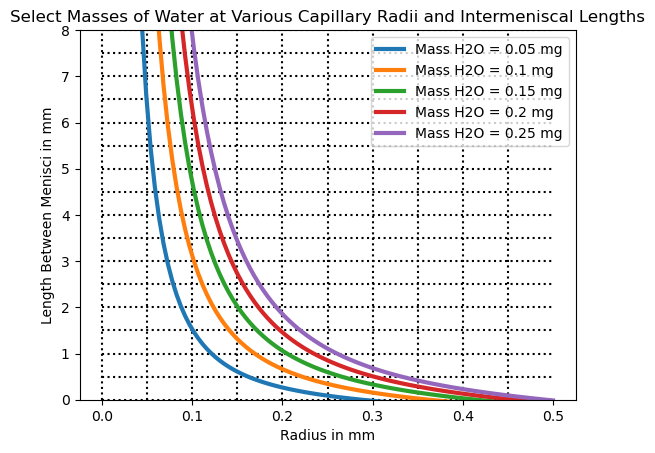

In [2]:


lam_U238 = 1.55135895e-10
lam_U235 = 9.84584063e-10

U_at = 10
t = 3E7
long = 8*U_at*(np.exp(lam_U238*t)-1) + (7*(U_at/137.88)*(np.exp(lam_U235*t)-1))
print(long)
short = (8*U_at*lam_U238*t) + ((7/137.88)*U_at*lam_U235*t)
print(short)

prod_rate = (8*lam_U238) + ((7/137.88)*lam_U235)
print(prod_rate)
print(U_at*prod_rate*t)

0.38841341850695327
0.3873219888202785
1.2910732960675951e-09
0.3873219888202785


> **2. Control Board**

This is the only part of Thermochreduction that you have to touch. If you'd like, you can complete this part and press Cell\Run All above.

In [6]:
"""Primary Control Board: This is where you input your data, define your phase and normal, ask for corrections for alpha recoil 
or diffusive loss, and choose if the program reduces ICPMS, Quadline, or SFT data"""


### READ IN YOUR ICPMS SPREADSHEET HERE ###
do_ICPMS = True
ICPMS_name = '2023_02_10_BJT_ratios_dilute_apatite.csv'
calc_ppm = False # outputs abundances as ppms according to phase stoichiometry defined below
phase = 'FeS2' # Any chemical formula works here
phase_mass_tracer = 'Fe' # The stochiometric element used to calculate sample mass, must be in above formula and measured

# Taken from Florian Hofmann's Normal Solution. Amounts are masses in grams delievered in 1mL.
# Obviously this can be customized as new normals are made. Keys must be valid elemental formulae.
Nnormal = { # 2/4/23 Pyrite normal BJT
'Fe': 1E-4,
'Cu': 1E-6,
'As': 1E-6,
'Zr': 1E-7,
'Ag': 1E-7,
'Sb': 1E-7,
'U': 1E-8,
'Th': 1E-8, 
'Sm': 1E-9,
#'Pt': 1E-6
}

############


### READ IN YOUR Quadrupole Laser He SPREADSHEET HERE ###
do_QUAD = False
QUAD_name = ''


### READ IN YOUR Quadrupole Diffusion cell He SPREADSHEET HERE ###
do_DIFFCELL = False
DIFFCELL_name = 'Batch 41.c'
total_yield = 1900 # in nCC STP

Pt_blanks = False # If true, program will identify Pt tube blanks as procedural blanks, using them instead of laser line blanks

do_diffusive_loss_corrections = True # from Shuster et al., 2005
goethite_diffusive_corrections = {
    'FvLRD': 0.05, # Fraction of the He volume produced in the Low Retention Diffusive Domain. All this fraction is lost.
    'HRD_deficit': 0.08} # Fraction of the He volume within the High Retention Diffusive Domain that is lost 

# from Farley et al., 1996: For alpha ejection retention factors (Ft). 
# If true, you must add a column called 'r' with radii in microns in the QUAD spreadsheet, assumes sphere. 
do_alpha_eject_corr = False


#############


### READ IN YOUR SFT He SPREADSHEET HERE ### ~~~Under construction, not live~~~
do_SFT = False
SFT_name = ''


#############

### Here we actually read the data input named above.
if do_ICPMS:
    ICPMS = pd.read_csv(ICPMS_name)
    
    # Automatically convert to moles! 
    for key in list(Nnormal.keys()): 
        Nnormal[key] /= Formula(key).mass 
    
    phase_mass_multiplier = mass_multiplier(Formula(phase), phase_mass_tracer) 
    # This is the factor that converts a mass of an element to the mass of it's phase. For example: mass(FeOOH)/mass(Fe)
    
if do_QUAD:
    QUAD = pd.read_csv(QUAD_name, na_values=[''])
    if do_ICPMS == False:
        outdf = pd.DataFrame([]) # So that the quad line reduction is not bugged by a lack of ICPMS data
if do_SFT:
    SFT = pd.read_csv(SFT_name)
    
if do_DIFFCELL:
    DIFFCELL = pd.read_csv(DIFFCELL_name)


> ***3. ICPMS DATA REDUCTION*** _Read measurement types, Organize data_

*ICPMS Chemistry Prep*:
 
In order for you to reduce the data, you need at least one analysis of each of the following types:

1. Spiked Normal Solution
2. Spike Blank
3. Spiked Procedural Blank
4. Spiked Samples (Of course!)

Data Structure: 

The ICPMS data must be a csv file and must be expressed in in ratios. Data must be given in replicates only, as in the photo below. There may be as many leading columns as you'd like, Thermochreduction ignores them. 
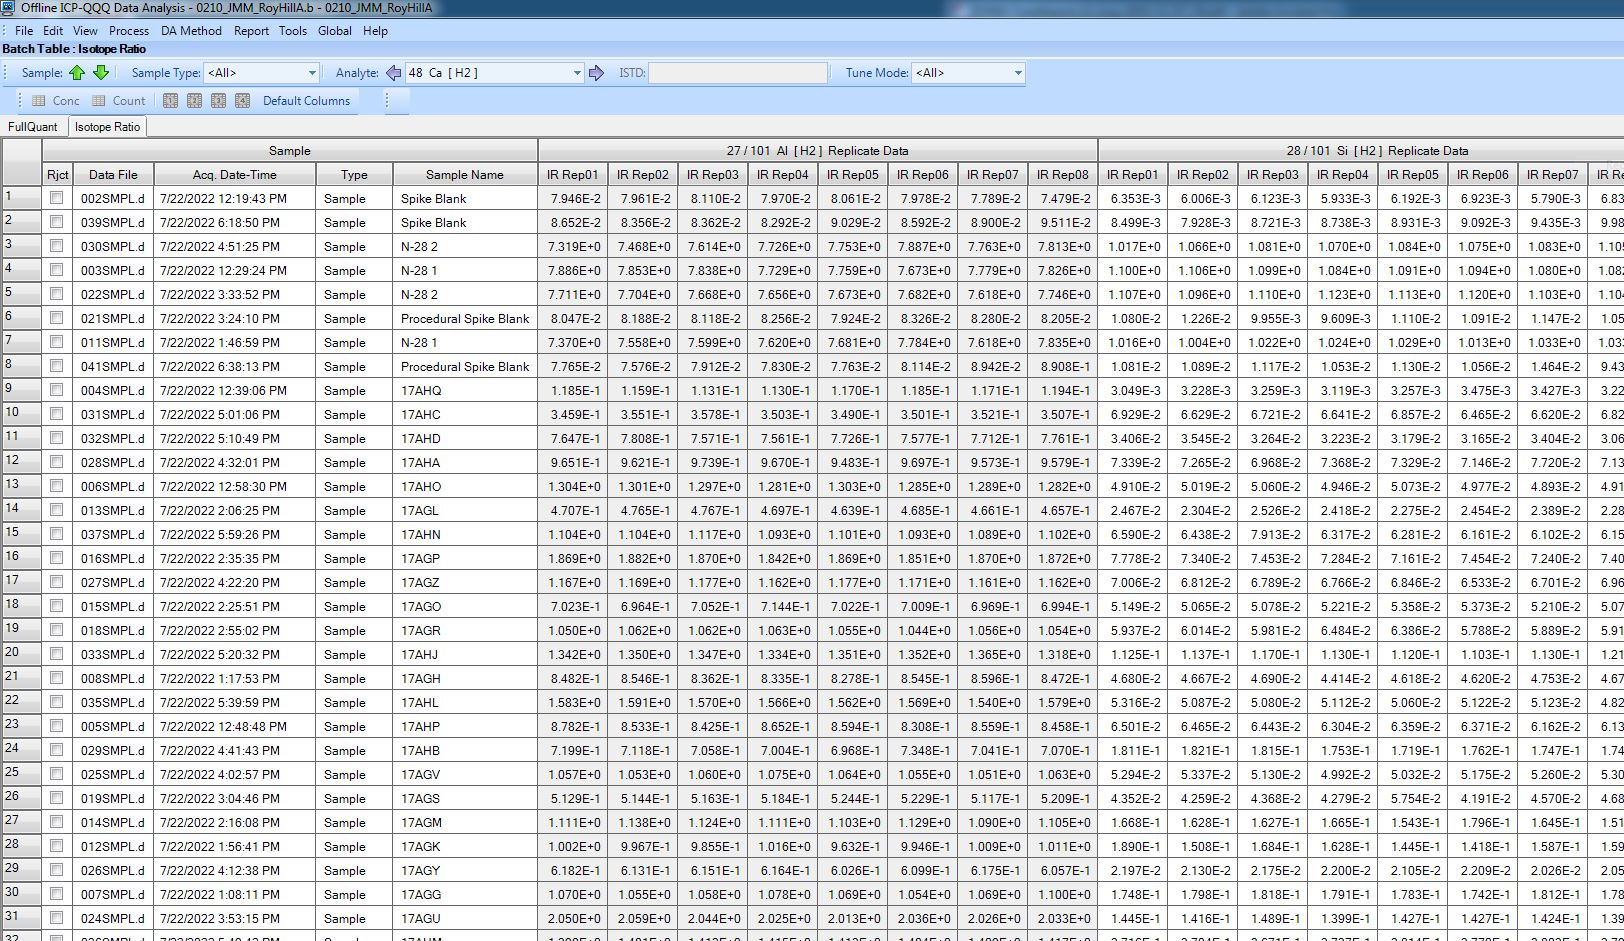

You can change Mass Hunter's data display by right-clicking the columns and taking away everything besides 'IR' in 'Denominator Replicates'

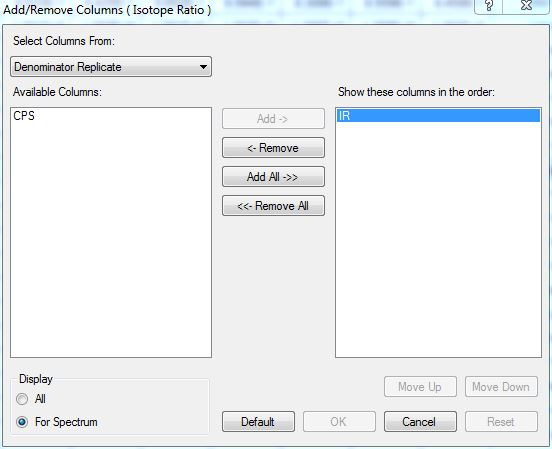


The following ratios are required for the program to proceed: 

1. ${}^{238}U/{}^{235}U$ 
2. ${}^{232}U/{}^{230}Th$
3. $Sm$ normalized to a rare-exotic spike isotope
4. An element stochiometric to the measured phase, e.g. Fe for FeOOH, FeS2, Fe2O3; Ca for Ca5(PO4)3F; Zr for ZrSiO4. Again, normalized to a rare or exotic spike isotope.

You can measure anything else so long as it is normalized to an exotic/rare isotope found in the spike, Ex: ${}^{101}Ru, {}^{230}Th$ or ${}^{235}U$. Elements measured relative to a spiked isotope with similar chemical behavior and mass will yield more accurate/reliable data, since the program assumes equal ionization efficiency for the natural ion and the exotic ion it is normalized to.

Note the following assumptions:

1. The program assumes everything is spiked with the same volume (Except for the spike blank, which could be any concentration that would be appropriate for the ICPMS)
2. The program does not know the concentration of the normal, only the mass delievered of the solutes you specifiy. The default that I have loaded assumes 1 mL of Florian's normal solution from his documentation. 
3. The program assumes that all samples are the same phase. This assumption may be violated for thermochronology, but the ppm output of non-radionuclides is only correct for the phase you specifiy.
4. The program only reduces data on species that are in the Normal solution in known amounts. Since Florian's normal does not contain any silver (Ag), for instance, the program will not interpret measurements of silver, unless you mix a new Normal solution with a known amount of silver and specify it in the top-level control board. 

Now we read in the spreadsheet and identify different types of measurements. Acid blanks (optional) are collected here if you did them, but are for manual quality control purposes only. 

In [18]:
"""Import pandas array into numpy, define labels"""
name_col = ICPMS.columns[ICPMS.iloc[0,:].isin(['Sample Name'])][0]
dat_col = ICPMS.columns[ICPMS.iloc[0,:].isin(['Acq. Date-Time'])][0]
analyses = ICPMS[name_col][1:].to_numpy() # rows
dates = ICPMS[dat_col][1:].to_numpy().tolist() # rows
times = [datetime.datetime.strptime(timestr, '%m/%d/%Y %I:%M:%S %p') for timestr in dates] #8/7/2023 3:17:33 PM
time0 = times[0]
minutes = np.array([(time - time0).total_seconds() / 60 for time in times])
element = [] # columns
replicates = 0 # which replicate, z-dimension

for i, column in enumerate(ICPMS.columns): # Define labels and find dimensionality of data
    if 'Replicate' in column:
        element.append(str(column.split(' [')[0]).strip())
    if 'Rep' in str(ICPMS.iat[0,i]):
        replicate_t = int(ICPMS.iat[0,i].split(' Rep')[1])
        if replicate_t > replicates:
            replicates = replicate_t
    

data = np.zeros((len(analyses), len(element), replicates)) # Make empty 3D tensor to populate with data along axes: [Analyses, Elements, Replicate#]
for i, column in enumerate(ICPMS.columns):
    if 'Replicate' in column:
        element_t = str(column.split(' [')[0]).strip()
        c = np.where(np.array(element) == element_t)[0][0]
    if 'Rep' in str(ICPMS.iat[0,i]):
        replicate_t = int(ICPMS.iat[0,i].split('Rep')[1])
        data[:, c, replicate_t-1] = ICPMS[column][1:]
        
        
# Label which samples are spike blanks, procedural blanks, acid blanks, normals
spike_blanks = []
procedural_blanks = []
acid_blanks = []
normals = []
samples = []
for i, name in enumerate(analyses):
    if 'blank' in name.lower() or 'SB' in name or '.p' in name.lower() or 'AB' in name:
        if 's-' in name.lower() or 'spike' in name.lower() or 'SB' in name:
            print('spike!')
            spike_blanks.append(i)
        elif 'p-' in name.lower() or 'pr' in name.lower() or  '.p' in name.lower():
            procedural_blanks.append(i)
        else:
            acid_blanks.append(i)
    elif 'normal' in name.lower() or 'n-' in name.lower() or 'N' in name:
        normals.append(i)
    else:
        samples.append(i)
spike_blanks = np.array(spike_blanks)
procedural_blanks = np.array(procedural_blanks)
acid_blanks = np.array(acid_blanks)
normals = np.array(normals)
samples = np.array(samples)

# Populate dictionaries to index the 3D data numpy array
isotope = {}
analysis = {}

for i, el in enumerate(element):
    isotope[remove_spaces(el)] = int(i)
for i, an in enumerate(analyses):
    analysis[an] = int(i)

spike!
spike!


> > ***3a. ICPMS DATA REDUCTION: Manual Quality Control***

See the plots below. You may exclude certain analyses from data reduction by entering the integer codes in the box parentheses in the rejects lists. Make sure to re-run the code block if you change anything! You'll see the plots come back without the excluded data, which means those data are also excluded from the data reduction calculations. 

The first code block shows the time-evolution of the spike isotope ratio and counts in acid blanks, the second and third code blocks plot analysis index on the x axis with measured procedural blanks in moles and ratio-sensitivity coefficients determined through analyses of the Normal solutions res

In [19]:
ICPMS

,Sample,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,57 / 51 Fe [ H2 ] Replicate Data,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 83,Unnamed: 84,238 / 235 U [ H2 ] Replicate Data,Unnamed: 86,Unnamed: 87,Unnamed: 88,Unnamed: 89,Unnamed: 90,Unnamed: 91,Unnamed: 92
0,Rjct,Data File,Acq. Date-Time,Type,Sample Name,IR Rep01,IR Rep02,IR Rep03,IR Rep04,IR Rep05,...,IR Rep07,IR Rep08,IR Rep01,IR Rep02,IR Rep03,IR Rep04,IR Rep05,IR Rep06,IR Rep07,IR Rep08
1,False,001SMPL.d,8/10/2023 11:04:00 PM,Sample,AB-B,1.077E+0,1.139E+0,1.054E+0,1.119E+0,1.146E+0,...,0.000E+0,0.000E+0,1.209E+1,1.353E+1,1.137E+1,3.220E+1,2.475E+1,1.161E+1,2.131E+1,1.031E+1
2,False,002SMPL.d,8/10/2023 11:09:16 PM,Sample,SB-B,3.251E-3,3.087E-3,3.154E-3,3.523E-3,3.412E-3,...,9.850E-4,9.914E-4,1.081E-3,1.054E-3,1.108E-3,1.006E-3,1.105E-3,1.015E-3,1.040E-3,1.053E-3
3,False,003SMPL.d,8/10/2023 11:14:30 PM,Sample,N-B,2.242E+0,2.235E+0,2.231E+0,2.242E+0,2.227E+0,...,1.392E-3,1.237E-3,1.157E+0,1.154E+0,1.154E+0,1.156E+0,1.152E+0,1.158E+0,1.154E+0,1.155E+0
4,False,004SMPL.d,8/10/2023 11:19:44 PM,Sample,597.p,1.478E-2,1.567E-2,1.480E-2,1.487E-2,1.384E-2,...,1.578E-3,1.053E-3,4.388E-3,4.402E-3,4.490E-3,4.350E-3,4.245E-3,4.416E-3,4.494E-3,4.504E-3
5,False,005SMPL.d,8/10/2023 11:24:58 PM,Sample,AB-B,1.103E+0,1.180E+0,1.045E+0,1.119E+0,1.239E+0,...,0.000E+0,0.000E+0,1.308E+1,1.362E+1,8.409E+0,7.783E+0,7.690E+0,6.654E+0,5.333E+0,4.824E+0
6,False,006SMPL.d,8/10/2023 11:30:12 PM,Sample,AB-B,1.087E+0,1.099E+0,1.009E+0,1.149E+0,1.144E+0,...,0.000E+0,0.000E+0,1.160E+1,8.952E+0,8.095E+0,1.469E+1,1.469E+1,7.955E+0,1.740E+1,1.343E+1
7,False,007SMPL.d,8/10/2023 11:35:28 PM,Sample,N-1D,2.255E+0,2.236E+0,2.250E+0,2.268E+0,2.258E+0,...,3.765E-4,2.268E-3,1.151E+0,1.167E+0,1.149E+0,1.165E+0,1.162E+0,1.164E+0,1.167E+0,1.154E+0
8,False,008SMPL.d,8/10/2023 11:40:42 PM,Sample,SB-1D,2.994E-3,2.862E-3,2.723E-3,2.505E-3,2.596E-3,...,1.570E-3,1.257E-3,2.203E-3,2.024E-3,2.944E-3,2.247E-3,2.227E-3,2.150E-3,3.262E-3,1.896E-3
9,False,009SMPL.d,8/10/2023 11:45:57 PM,Sample,597.12,7.597E-3,8.466E-3,7.263E-3,7.354E-3,7.669E-3,...,1.425E-3,7.271E-4,3.803E-1,3.752E-1,3.766E-1,3.827E-1,3.750E-1,3.771E-1,3.771E-1,3.803E-1


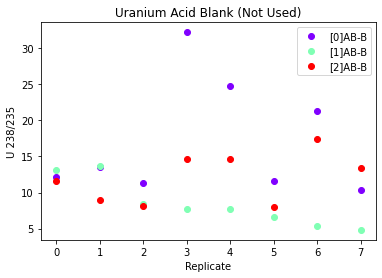

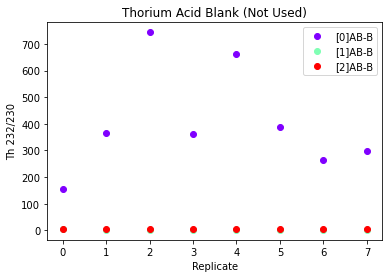

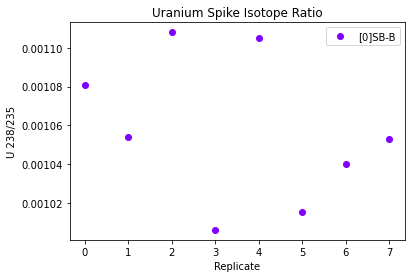

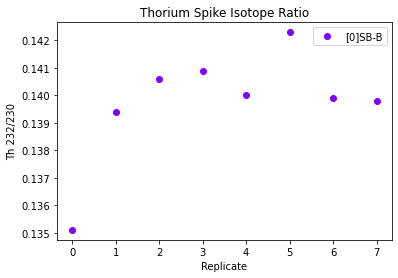

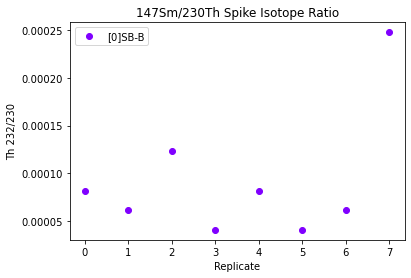

Outlier Corrected 232/230Th Spike: 0.14041428571428574 +/- 0.001799773228345561 2 sigma
238/235U Spike: 0.0010577499999999999 +/- 7.125833284606092e-05 2 sigma


In [22]:
"""Acid and Spike Blank Quality Control"""
acid_blank_rejects = []
spike_blank_rejects = [1]
##########################

acid_blanks_r = []
spike_blanks_r = []

for i, acid in enumerate(acid_blanks):
    if i not in acid_blank_rejects:
        acid_blanks_r.append(acid)
if len(acid_blanks_r):
    acid_cmap = plt.get_cmap('rainbow', len(acid_blanks_r))
    acid_colors = [mpl.colors.rgb2hex(acid_cmap(i)) for i in range(acid_cmap.N)]   

for i, spike in enumerate(spike_blanks):
    if i not in spike_blank_rejects:
        spike_blanks_r.append(spike)
if len(spike_blanks_r):
    spike_cmap = plt.get_cmap('rainbow', len(spike_blanks_r))
    spike_colors = [mpl.colors.rgb2hex(spike_cmap(i)) for i in range(spike_cmap.N)]  
        
for i, acid in enumerate(acid_blanks_r):
    plt.plot(np.arange(np.shape(data)[2]), data[acid,isotope['238/235U'],:], label = f"[{i}]{analyses[acid]}", marker='o', color = acid_colors[i], linestyle = '')
if len(acid_blanks_r) > 0:
    plt.xlabel('Replicate')
    plt.ylabel('U 238/235')
    plt.legend()
    plt.title('Uranium Acid Blank (Not Used)')
    plt.show()

for i, acid in enumerate(acid_blanks_r):
    plt.plot(np.arange(np.shape(data)[2]), data[acid,isotope['232/230Th'],:], label = f"[{i}]{analyses[acid]}", marker='o', color = acid_colors[i],  linestyle = '')
if len(acid_blanks_r) > 0:
    plt.xlabel('Replicate')
    plt.ylabel('Th 232/230')
    plt.legend()
    plt.title('Thorium Acid Blank (Not Used)')
    plt.show()

for i, spike in enumerate(spike_blanks_r):
    plt.plot(np.arange(np.shape(data)[2]),data[spike,isotope['238/235U'],:], label = f"[{i}]{analyses[spike]}", marker='o', color = spike_colors[i], linestyle = '')
plt.xlabel('Replicate')
plt.ylabel('U 238/235')
plt.legend()
plt.title('Uranium Spike Isotope Ratio')
plt.show()

for i, spike in enumerate(spike_blanks_r):
    plt.plot(np.arange(np.shape(data)[2]),data[spike,isotope['232/230Th'],:], label = f"[{i}]{analyses[spike]}", marker='o', color = spike_colors[i], linestyle = '')
plt.xlabel('Replicate')
plt.ylabel('Th 232/230')
plt.legend()
plt.title('Thorium Spike Isotope Ratio')
plt.show()

for i, spike in enumerate(spike_blanks_r):
    plt.plot(np.arange(np.shape(data)[2]),data[spike,isotope['147/230Sm'],:], label = f"[{i}]{analyses[spike]}", marker='o', color = spike_colors[i], linestyle = '')
plt.xlabel('Replicate')
plt.ylabel('Th 232/230')
plt.legend()
plt.title('147Sm/230Th Spike Isotope Ratio')
plt.show()

### Calculate Spike Isotope Ratios

RThspike, sRThspike, comment = outlier_stats(data[spike_blanks_r,isotope['232/230Th'],:])
print(f"{comment}232/230Th Spike: {RThspike} +/- {2*sRThspike} 2 sigma")
MCRThspike = np.random.normal(RThspike, sRThspike, 2000)
RUspike, sRUspike, comment = outlier_stats(data[spike_blanks_r,isotope['238/235U'],:])
print(f"{comment}238/235U Spike: {RUspike} +/- {2*sRUspike} 2 sigma")
MCRUspike = np.random.normal(RUspike, sRUspike, 2000)

**Normal Solution Standization Quality Control**

We use 'reverse isotope dilution' to calculate the abundance of U, Th in the spikes using the normals. Normals are assumed to have no procedural blank.

$N_a = N_b\left(\frac{R_b-R_{ab}}{R_{ab} - R_a}\right)\left(\frac{1+R_a}{1+R_b}\right)$

Here let $a$ be the spike abundance and $b$ be the abundance in the Normal.

$N_a$ is the molar abundance of U, Th in the spike

$N_b$ is given for both U and Th (abundance in the Normal). No uncertainties propagated here for now, values are assumed exact and are taken from the control board.

$R_a$ is calculated above for Th, U, and Ru

$R_{ab}$ is the measured ratio of the blend

$R_b$ is the natural isotopic abundances. Nonzero for U (and Sm, which is normalized to ${}^{235}U$)

For the rest of the elements, We calculate sensitivity ratios $K$ to calculate the elemental abundances of the samples. These ratios tie a measured natural/spike isotope ratio to a known abundance (explicitly defined in the Control Board).

${}^{el}K =  \frac{atoms\:or\:moles\:in\:Normal}{measured\:isotope\:ratio\:R_{ab}}$

where

$R_{ab} = \frac{natural\:isotope\:in\:Normal}{exotic/rare\:isotope\:in\:Spike}$


Spike Uranium content from N-B = 3.5881076528252516e-11 +/- 5.126293315271242e-14 1 sigma
Spike Uranium content from N-1D = 3.5738495310050533e-11 +/- 1.8909436653113436e-13 1 sigma
Spike Uranium content from N-1D = 3.5730465782954567e-11 +/- 1.1772017722077573e-13 1 sigma


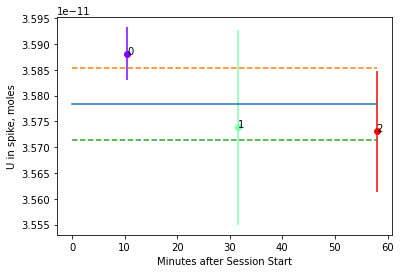

Spike Throrium content from N-B = 1.2390860184543677e-11 +/- 3.909698323069859e-14 1 sigma
Spike Throrium content from N-1D = 1.231434451047983e-11 +/- 6.683422824035908e-14 1 sigma
Spike Throrium content from N-1D = 1.2148982843119259e-11 +/- 7.064752830398771e-14 1 sigma


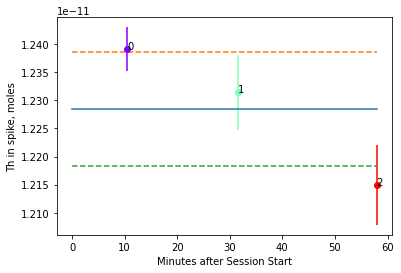

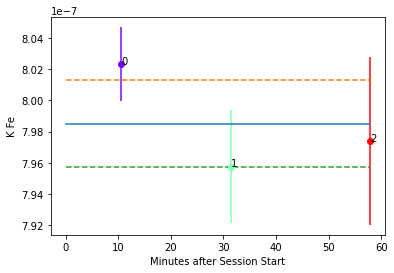

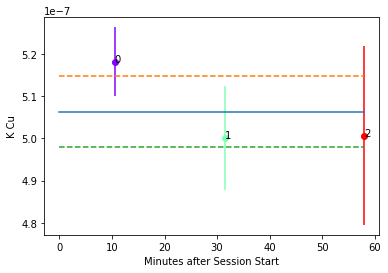

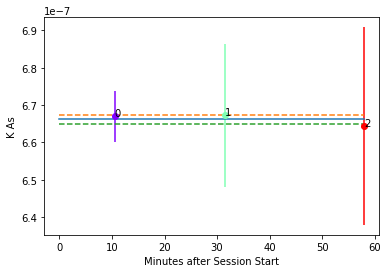

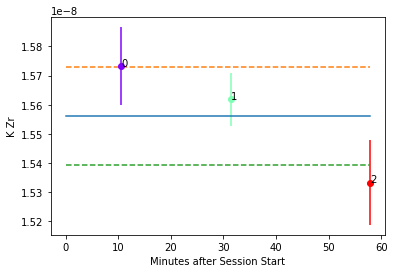

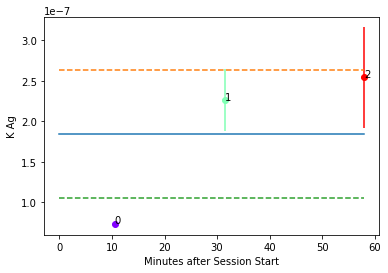

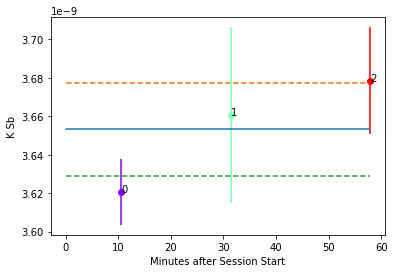

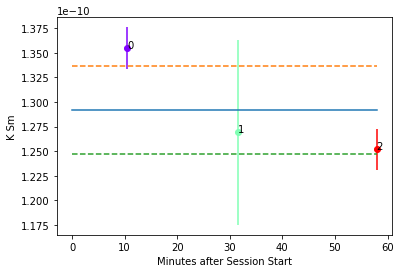

In [24]:
"""Normal Solution Quality Control"""

normal_rejects = []#[0,1,2,3,4,5,6,7,8,9,10,11]#[5,6,7,8,9,10,11,12,13]
do_not_spline = ['U','Th', 'Sm', 'Fe', 'Sb', 'As', 'Ag', 'Cu', 'Zr'] # List of elements NOT to spline, instead taking an average and standard deviation
#########################


RUnat = Formula('U').spectrum()[238][1]/Formula('U').spectrum()[235][1]
normals_r = []
for i, nor in enumerate(normals):
    if i not in normal_rejects:
        normals_r.append(i)
normals_r = normals[np.array(normals_r)]

norm_cmap = plt.get_cmap('rainbow', len(normals_r))
norm_colors = [mpl.colors.rgb2hex(norm_cmap(i)) for i in range(norm_cmap.N)]  

spike_U = []
spike_Us = []
spike_Th = []
spike_Ths = []

for i, nor in enumerate(normals_r):
    Rab, Rsab, comment1 = outlier_stats(data[nor,isotope['238/235U'],:])
    NU = isotope_dilution(Nb = Nnormal['U'], Ra = np.random.normal(RUspike, sRUspike, 2000), Rab = np.random.normal(Rab,Rsab,2000), Rb = RUnat)
    Nu, Nus, comment2 = outlier_stats(NU)
    print(f"{comment1}Spike Uranium content from {analyses[nor]} = {Nu} +/- {Nus} 1 sigma")
    spike_U.append(Nu)
    spike_Us.append(Nus)
    plt.errorbar(minutes[nor], spike_U[i], yerr = spike_Us[i], color = norm_colors[i], linestyle = '', marker = 'o')
    plt.text(minutes[nor], spike_U[i], i)
    
plot_minutes = np.linspace(0,np.max(minutes),100)
if 'U' in do_not_spline:
    mu,sig,c1 = outlier_stats(np.array(spike_U))
    NU_spike = Nonfunc(mu)
    NUs_spike = Nonfunc(sig)
else:
    NU_spike = UnivariateSpline(minutes[normals_r], spike_U, k = 2)
    NUs_spike = UnivariateSpline(minutes[normals_r], spike_Us+np.abs(spike_U - NU_spike(minutes[normals_r])), k = 2)
plt.plot(plot_minutes, NU_spike(plot_minutes))
plt.plot(plot_minutes, NU_spike(plot_minutes)+NUs_spike(plot_minutes), linestyle = '--')
plt.plot(plot_minutes, NU_spike(plot_minutes)-NUs_spike(plot_minutes), linestyle = '--')
plt.ylabel('U in spike, moles')
plt.xlabel('Minutes after Session Start')
plt.show()

for i, nor in enumerate(normals_r):
    Rab, Rsab, comment1 = outlier_stats(data[nor,isotope['232/230Th'],:])
    NTH = isotope_dilution(Nb = Nnormal['Th'], Ra = np.random.normal(RThspike, sRThspike, 2000), Rab = np.random.normal(Rab,Rsab,2000), Rb = np.inf)
    NTh, NThs, comment2 = outlier_stats(NTH)
    print(f"{comment1}Spike Throrium content from {analyses[nor]} = {NTh} +/- {NThs} 1 sigma")
    spike_Th.append(NTh)
    spike_Ths.append(NThs)
    plt.errorbar(minutes[nor], spike_Th[i], yerr = spike_Ths[i], color = norm_colors[i], linestyle = '', marker = 'o')
    plt.text(minutes[nor], spike_Th[i], i)
if 'Th' in do_not_spline:
    mu,sig, c1 = outlier_stats(np.array(spike_Th))
    NTh_spike = Nonfunc(mu)
    NThs_spike = Nonfunc(sig)
else:
    NTh_spike = UnivariateSpline(minutes[normals_r], spike_Th, k = 2)
    NThs_spike = UnivariateSpline(minutes[normals_r], spike_Ths+np.abs(spike_Th - NTh_spike(minutes[normals_r])), k = 2)
plt.plot(plot_minutes, NTh_spike(plot_minutes))
plt.plot(plot_minutes, NTh_spike(plot_minutes)+NThs_spike(plot_minutes), linestyle = '--')
plt.plot(plot_minutes, NTh_spike(plot_minutes)-NThs_spike(plot_minutes), linestyle = '--')

plt.ylabel('Th in spike, moles')
plt.xlabel('Minutes after Session Start')
plt.show()

"""if len(spike_U) == 1:
    NU_spike = spike_U
    NUs_spike = spike_Us
    NTh_spike = spike_Th
    NThs_spike = spike_Ths
else:
    NU_spike, NUs_spike, c1 = outlier_stats(np.array(spike_U))
    NTh_spike, NThs_spike, c1 = outlier_stats(np.array(spike_Th))""" #these are offline while splines handle drift

#splines!



KR = {} # Sensitivity ratios (SPLINES after 8/8/23)


for key in list(Nnormal.keys()):
    if key not in ['U', 'Th']:#, 'Fe']:
        el = [i for i, e in enumerate(isotope) if key in e]
        if len(el) == 1:
            Kl = []
            Ksl = []
            for i, nor in enumerate(normals_r):
                K, Ks, comment = outlier_stats(Nnormal[key]/data[nor,el,:])
                Kl.append(K)
                Ksl.append(Ks)
                plt.errorbar(minutes[nor], Kl[i], yerr = Ksl[i], color = norm_colors[i], linestyle = '', marker = 'o')
                plt.text(minutes[nor], Kl[i], i)
            plt.ylabel(f"K {key}")
            plt.xlabel('Minutes after Session Start')
            if key in do_not_spline:
                mu,sig, c1 = outlier_stats(np.array(Kl))
                KE = Nonfunc(mu)
                KErr = Nonfunc(sig)
            else:
                KE = UnivariateSpline(minutes[normals_r], Kl, k = 2)
                KErr = UnivariateSpline(minutes[normals_r], Ksl+np.abs(Kl - KE(minutes[normals_r])), k =2)
            plt.plot(plot_minutes, KE(plot_minutes))
            plt.plot(plot_minutes, KE(plot_minutes)+KErr(plot_minutes), linestyle = '--')
            plt.plot(plot_minutes, KE(plot_minutes)-KErr(plot_minutes), linestyle = '--')
            plt.show()
            #KE, KErr, comment1 = outlier_stats(np.array(Kl))
            #if len(Kl) == 1:
            #    KR[key] = [Kl[0], Ksl[0]]
            #else:
            #    KR[key] = [KE, KErr]
            KR[key] = [KE, KErr]
            #print(f"{comment1}K {key} = {KE} +/- {KErr} 1 sigma")

Procedural blanks: [3]


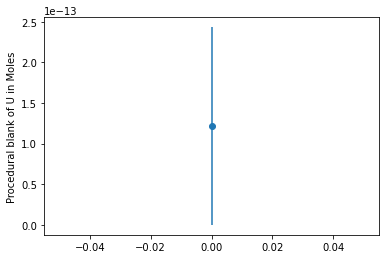

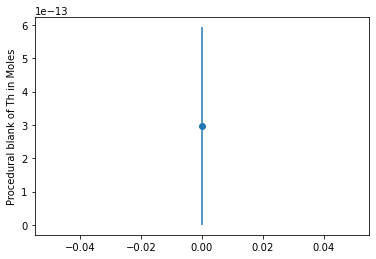

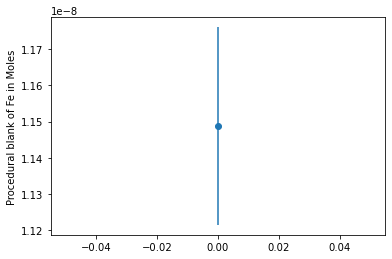

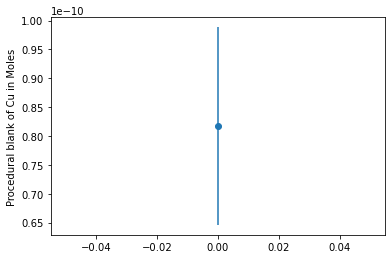

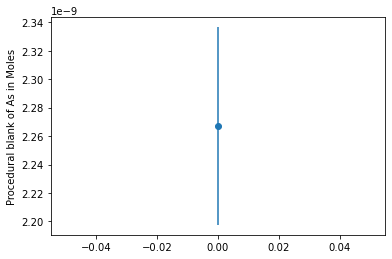

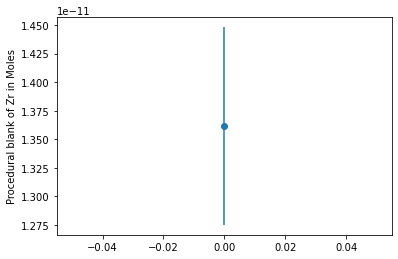

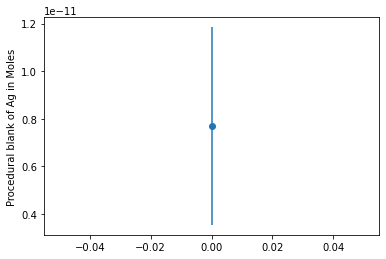

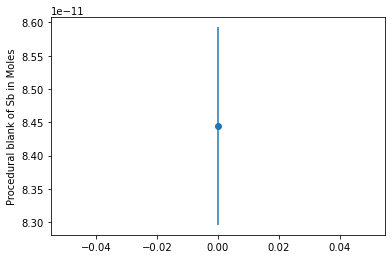

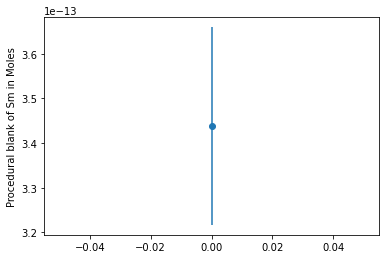

[1.21570408e-13 2.96544080e-13 1.14875621e-08 8.17277697e-11
 2.26701505e-09 1.36153952e-11 0.00000000e+00 8.44425730e-11
 3.43799865e-13]


In [25]:
"""Procedural Blank Quality Control"""

procedural_blanks_rejects = []
##########################
print(f"Procedural blanks: {procedural_blanks}")
if len(procedural_blanks) == 0 or (len(procedural_blanks)-len(procedural_blanks_rejects)) == 0:
    Nblanks = np.zeros(len(KR)+2)
    Nsblanks = np.zeros(len(KR)+2)
else:
    
    ipass = []
    procedural_blanks_r = []
    for i, pb in enumerate(procedural_blanks):
        if i not in procedural_blanks_rejects:
            ipass.append(i)
            procedural_blanks_r.append(pb)
    procedural_blanks_r = np.array(procedural_blanks_r)
    ipass = np.array(ipass)
    outelements = ['U','Th']#,'Fe']
    for k in list(KR.keys()):
        outelements.append(k)

    Nblanks = []
    Nsblanks = []
    NU = []
    NUs = []
    NTh = []
    NThs = []
    #NFe = []
    #NFes = []
    for pbr in procedural_blanks_r:
        Rab, Rabs, comment = outlier_stats(data[pbr,isotope['238/235U'],:])
        NUi, NUsi,comment = outlier_stats(isotope_dilution(Rab = np.random.normal(Rab,Rabs,2000), Nb = np.random.normal(NU_spike(minutes[pbr]), NUs_spike(minutes[pbr]), 2000), Ra = RUnat, Rb = np.random.normal(RUspike, sRUspike, 2000)))
        NU.append(NUi)
        NUs.append(NUsi)

        Rab, Rabs, comment = outlier_stats(data[pbr,isotope['232/230Th'],:])
        NThi, NThsi,comment = outlier_stats(isotope_dilution(Rab = np.random.normal(Rab,Rabs,2000), Nb = np.random.normal(NTh_spike(minutes[pbr]), NThs_spike(minutes[pbr]), 2000), Ra = np.inf, Rb = np.random.normal(RThspike, sRThspike, 2000)))
        NTh.append(NThi)
        NThs.append(NThsi)

    plt.errorbar(np.arange(len(procedural_blanks))[ipass], NU, yerr = NUi, linestyle = '', marker = 'o')
    plt.ylabel(f"Procedural blank of U in Moles")
    plt.show()
    plt.errorbar(np.arange(len(procedural_blanks))[ipass], NTh, yerr = NThi, linestyle = '', marker = 'o')
    plt.ylabel(f"Procedural blank of Th in Moles")
    plt.show()

    if len(NU) == 1:
        Nblanks.append(NU[0])
        Nsblanks.append(NUs[0])
        Nblanks.append(NTh[0])
        Nsblanks.append(NThs[0])                                   
    else:
        NUI, NUIs, c = outlier_stats(NU)
        NThI, NThIs, c = outlier_stats(NTh)
        Nblanks.append(NUI)
        Nsblanks.append(NUIs)
        Nblanks.append(NThI)
        Nsblanks.append(NThIs)      

    for key in list(KR.keys()):
        Nel = []
        Nsel = []
        el = [i for i, e in enumerate(isotope) if key in e] 
        for pcr in procedural_blanks_r:
            Rab, Rabs, comment = outlier_stats(data[pcr,el,:])
            Neli, Nseli, comment, = outlier_stats(np.random.normal(KR[key][0](minutes[pbr]), KR[key][1](minutes[pbr]), 2000)*np.random.normal(Rab, Rabs, 2000))
            Nel.append(Neli)
            Nsel.append(Nseli)
        plt.errorbar(np.arange(len(procedural_blanks))[ipass], Nel, yerr = Nsel, linestyle = '', marker = 'o')
        plt.ylabel(f"Procedural blank of {key} in Moles")
        plt.show()
        if len(Nel) == 1:
            Nblanks.append(Nel[0])
            Nsblanks.append(Nsel[0])
        else:
            NELI, NELIs, comment = outlier_stats(Nel)
            Nblanks.append(NELI)
            Nsblanks.append(NELIs)

    for i, NB in enumerate(Nblanks):
        if NB-(2*Nsblanks[i]) < 0:
            Nblanks[i] = 0
            Nsblanks[i] = 0

    Nblanks = np.array(Nblanks)
    Nsblanks = np.array(Nsblanks)
print(Nblanks)

In [32]:
"""Final Calculations for ICPMS Data Reduction, Output"""

outarray = np.zeros((len(samples)+len(procedural_blanks_r), len(outelements)*2))
print(np.shape(outarray))
# Use isotope dilution to determine U and Th abundance
for i, sam in enumerate(samples):
    Rab, Rabs, comment = outlier_stats(data[sam,isotope['238/235U'],:])
    NUi, NUsi,comment = outlier_stats(isotope_dilution(Rab = np.random.normal(Rab,Rabs,2000), Nb = np.random.normal(NU_spike(minutes[sam]), NUs_spike(minutes[sam]), 2000), Ra = RUnat, Rb = np.random.normal(RUspike, sRUspike, 2000)))
    outarray[i, 0] = NUi - Nblanks[0]
    outarray[i, 1] = (NUsi + Nsblanks[0])*2
        
    
    Rab, Rabs, comment = outlier_stats(data[sam,isotope['232/230Th'],:])
    NThi, NThsi,comment = outlier_stats(isotope_dilution(Rab = np.random.normal(Rab,Rabs,2000), Nb = np.random.normal(NTh_spike(minutes[sam]), NThs_spike(minutes[sam]), 2000), Ra = np.inf, Rb = np.random.normal(RThspike, sRThspike, 2000)))
    outarray[i, 2] = NThi - Nblanks[1]
    outarray[i, 3] = (NThsi + Nsblanks[1])*2
                                    
# Use sensitivities to calculate abundances of remaining elements
for ei, key in enumerate(list(KR.keys())):
    Nel = []
    Nsel = []
    el = [i for i, e in enumerate(isotope) if key in e] 
    for i, sam in enumerate(samples):
        Rab, Rabs, comment = outlier_stats(data[sam,el,:])
        Neli, Nseli, comment, = outlier_stats(np.random.normal(KR[key][0](minutes[sam]), KR[key][1](minutes[sam]), 2000)*np.random.normal(Rab, Rabs, 2000))
        outarray[i, 4+(ei*2)] = Neli - Nblanks[2+ei]
        outarray[i, 5+(ei*2)] = (Nseli + Nsblanks[2+ei])*2

for i, pc in enumerate(procedural_blanks_r):
    Rab, Rabs, comment = outlier_stats(data[pc,isotope['238/235U'],:])
    NUi, NUsi,comment = outlier_stats(isotope_dilution(Rab = np.random.normal(Rab,Rabs,2000), Nb = np.random.normal(NU_spike(minutes[pc]), NUs_spike(minutes[pc]), 2000), Ra = RUnat, Rb = np.random.normal(RUspike, sRUspike, 2000)))
    outarray[i+len(samples), 0] = NUi
    outarray[i+len(samples), 1] = NUsi * 2
    
    Rab, Rabs, comment = outlier_stats(data[pc,isotope['232/230Th'],:])
    NThi, NThsi,comment = outlier_stats(isotope_dilution(Rab = np.random.normal(Rab,Rabs,2000), Nb = np.random.normal(NTh_spike(minutes[pc]), NThs_spike(minutes[pc]), 2000), Ra = np.inf, Rb = np.random.normal(RThspike, sRThspike, 2000)))
    outarray[i+len(samples), 2] = NThi
    outarray[i+len(samples), 3] = NThsi * 2
                                    
for ei, key in enumerate(list(KR.keys())):
    Nel = []
    Nsel = []
    el = [i for i, e in enumerate(isotope) if key in e] 
    for i, pc in enumerate(procedural_blanks_r):
        Rab, Rabs, comment = outlier_stats(data[pc,el,:])
        Neli, Nseli, comment, = outlier_stats(np.random.normal(KR[key][0](minutes[pc]), KR[key][1](minutes[pc]), 2000)*np.random.normal(Rab, Rabs, 2000))
        outarray[i+len(samples), 4+(ei*2)] = Neli
        outarray[i+len(samples), 5+(ei*2)] = Nseli * 2
        
# Calculate sample mass with multiplier calculated at the Control Panel
if calc_ppm:
    mass_el = np.where(np.array(outelements) == phase_mass_tracer)[0][0]*2
    Sample_Mass_mg = outarray[:,mass_el]*phase_mass_multiplier
    mass_uncert = outarray[:,mass_el+1]*phase_mass_multiplier
    outarray = np.append(outarray, Sample_Mass_mg.reshape((np.shape(Sample_Mass_mg)[0]),1), axis = 1)
    outarray = np.append(outarray, mass_uncert.reshape((np.shape(Sample_Mass_mg)[0],1)), axis = 1)

# Define row names
row_names = analyses[samples].tolist()
for pc in procedural_blanks_r:
    row_names.append(analyses[pc])

# Copy and keep atomic abundances for U, Th, Sm but replace all other analyses with ppm data
Sm = [i for i, e in enumerate(outelements) if 'Sm' in e][0]
UThSm_block = np.copy(np.append(outarray[:,:4], outarray[:,(Sm*2):(Sm*2)+2], axis = 1))
print(np.shape(UThSm_block))
if calc_ppm:
    for a, analysis in enumerate(row_names):
        if analysis not in analyses[procedural_blanks_r]:
            mass = np.random.normal(outarray[a,-2], outarray[a,-1]/2, 2000)
            for el, element in enumerate(outelements):
                if element != phase_mass_tracer:
                    moles = np.random.normal(outarray[a,el*2], outarray[a,(el*2)+1]/2, 2000)
                    elmass = moles * Formula(element).mass * 1000 # moles to mg
                    ppm, ppmS, comment = outlier_stats(1E6*(elmass/mass))
                    outarray[a,el*2] = ppm
                    outarray[a,(el*2)+1] = ppmS*2
outarray = np.append(UThSm_block, outarray, axis = 1)

# Name columns and rows for output
column_names = ['U (moles)', 'U 2s (moles)', 'Th (moles)', 'Th 2s (moles)', 'Sm (moles)', 'Sm 2s (moles)']
for outel in outelements:
    if outel == phase_mass_tracer or calc_ppm == False:
        column_names.append(outel + ' (moles)')
        column_names.append(outel + ' 2s (moles)')
    else:
        column_names.append(outel + ' (ppm)')
        column_names.append(outel + ' 2s (ppm)')
if calc_ppm:
    column_names.append('Sample Mass (mg)')
    column_names.append('2s Mass')

    
# If no detection, replace analysis and errors with 0. 
for el in np.arange(int(np.shape(outarray)[1]/2)):
    for an in np.arange(np.shape(outarray)[0]):
        if (outarray[an,el*2] - (outarray[an,(el*2)+1])) < 0:
            print(f"Setting entry to zero: {row_names[an]} {column_names[el]}: {outarray[an,el*2]} +/- {(outarray[an,(el*2)+1])}")
            outarray[an,el*2] = 0
            #print(f"{row_names[an]} {column_names[el]}: {}")
            outarray

outdf = pd.DataFrame(outarray, columns = column_names, index = row_names)

new_ICPMS_name = ICPMS_name.split('.csv')[0]+'_reducedICPMS.csv'
outdf.to_csv(new_ICPMS_name)

print(f"Done! Output file: {new_ICPMS_name} in {os.getcwd()}")

(4, 18)
(4, 6)
Setting entry to zero: 597.12 Sm 2s (moles): -5.1715754353116904e-09 +/- 1.2087361343006746e-09
Setting entry to zero: 598.10 Sm 2s (moles): -2.878220965130056e-09 +/- 1.0523999513576584e-09
Setting entry to zero: 598.12 Sm 2s (moles): -2.6199207539549888e-09 +/- 1.9669963676452303e-09
Setting entry to zero: 597.12 U (moles): 6.496202874546359e-11 +/- 1.6015971371466557e-10
Setting entry to zero: 598.12 U (moles): 1.600359294723258e-11 +/- 9.231648278714421e-11
Setting entry to zero: 597.12 Th 2s (moles): 3.147385816425241e-11 +/- 3.632021345673347e-11
Setting entry to zero: 598.10 Th 2s (moles): 2.0785429288446098e-11 +/- 3.8292586300059254e-11
Setting entry to zero: 598.12 Th 2s (moles): 4.595067533083632e-11 +/- 5.616038745451333e-11
Setting entry to zero: 597.p Th 2s (moles): 7.648631092850027e-12 +/- 8.253944410024621e-12
Setting entry to zero: 597.12 Fe (moles): -4.639013012542905e-11 +/- 9.325952535080718e-12
Setting entry to zero: 598.10 Fe (moles): -5.8460301991

In [22]:
Formula('AuAr').spectrum()

{233: [232.934113895, 0.003336],
 235: [234.9293009, 0.000629],
 237: [236.9289519137, 0.996035]}

> **4. Pfeiffer Vacuum Prisma QMS 200 Quadrupole Mass Spectrometer**

This program automates additions of reextracts and subtraction of blanks (platinum tube or laser line blanks for samples, line blanks for standards) from batch files, and it matches He analyses to corresponding ICPMS data to calculate ages with propagated errors. It also automates alpha ejection or diffusive loss corrections as directed in the Control Board. 

See the manual alpha recoil corrections and the manual age algorithm below for more details on those procedures. 

Note that reextracts must contain 'Re' or 're' in the name. Only put 'Re' or 're' in sample names that are reextracts. 

To determine alpha retention factors ($F_t$), one must add a column with the title 'R' or 'r' to the quadline batch file, with radii in microns for each sample. If this column is not provided, Thermochreduction will skip the alpha retention evaluation and correction. 

In [210]:
"""QUAD LINE DATA REDUCTION"""
CITref = QUAD['\tCIT RefNo'].tolist()
quadAnalyses = QUAD['Name'].tolist()
quadType = QUAD['\tAnalysis'].tolist()
HeR = QUAD['\tRatio Int'].to_numpy()
HenCC = QUAD['\tCalc nCC'].to_numpy()
HeRef = QUAD['\tHe RefNo'].tolist()
try:
    quadR = QUAD['r'].to_numpy()
except:
    do_alpha_eject_corr = False
    print(f'No "r" column in {QUAD_name} detected, skipping alpha recoil corrections')

if do_alpha_eject_corr:
    try: 
        radii = QUAD['r'].to_numpy()
    except:
        try: 
            radii = QUAD['R'].to_numpy()
        except:
            do_alpha_eject_corr = False
            print(f"Could not find column in QUAD spreadsheet with mineral radii labelled 'r' or 'R'")
if do_ICPMS == False:
    outdf = pd.DataFrame([]) # Avoid bugging the code by defining empty object stand-in for ICPMS data when it doesn't exist. 
    
####
HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
####

# Label which analyses are line blanks, laser-line blanks, standards, samples
laser_blanks = []
line_blanks = []
Qprocedural_blanks = []
Qstandards = []
Qsamples = []

for i, qtype in enumerate(quadType):
    if 'LB' in qtype:
        if 'Laser' in qtype:
            laser_blanks.append(i)
    elif 'Line' in qtype:
        line_blanks.append(i)
    elif 'STD' in qtype:
        Qstandards.append(i)
    elif 'blank' in quadAnalyses[i].lower():
        Qprocedural_blanks.append(i)
    else: 
        Qsamples.append(i)
        
laser_blanks = np.array(laser_blanks)
line_blanks = np.array(line_blanks)
Qprocedural_blanks = np.array(Qprocedural_blanks)
Qstandards = np.array(Qstandards)
Qsamples = np.array(Qsamples)

if len(line_blanks) > 1:
    LB, LBs, comment = outlier_stats(HenCC[line_blanks])
else:
    LB = HenCC[line_blanks][0]
    LBs = HeSigma[line_blanks][0]
    comment = ''
print(f"{comment}Line blank: {LB} +/- {LBs} 1 sigma")

if Pt_blanks:
    if len(Qprocedural_blanks) > 1:
        LLB, LLBs, comment = outlier_stats(HenCC[Qprocedural_blanks])
        comment = 'Platinum Tube ' + comment
    else:
        LLB = HenCC[Qprocedural_blanks][0]
        LLBs = HeSigma[Qprocedural_blanks][0]
        comment = 'Platinum Tube '
else:
    if len(laser_blanks) > 1:
        LLB, LLBs, comment = outlier_stats(HenCC[laser_blanks])
    else:
        LLB = HenCC[laser_blanks][0]
        LLBs = HeSigma[laser_blanks][0]
        comment = ''
print(f"{comment}Laser Line blanks: {LLB} +/- {LLBs} 1 sigma\n")

# Produce new spreadsheet
if do_diffusive_loss_corrections:
    if do_alpha_eject_corr:
        print('Cannot correct for both diffusive loss and alpha recoil, ignoring alpha recoil.\n')
    do_alpha_eject_corr = False
    newHE = np.zeros((len(quadAnalyses),14))
elif do_alpha_eject_corr:
    newHE = np.zeros((len(quadAnalyses),16))
else: # No He loss Corrections
    newHE = np.zeros((len(quadAnalyses),10))    

# Subtract blanks, calculate ages
ref = 'zzz'
for i, name in enumerate(quadAnalyses):
    if i in Qstandards:
        newHE[i,:2] = np.array([HenCC[i]-LB, HeSigma[i]+(LBs*2)]).reshape((1,2))
    elif i in Qsamples:
        if 're' in name.lower(): # Add Previous if reextract for running total
            newHE[i,:2] = np.array([newHE[i-1,0]+HenCC[i]-LLB, newHE[i-1,1]+HeSigma[i]+(LLBs*2)]).reshape((1,2))
            matched_array = np.array(outdf.iloc[np.where(outdf.index == ref)[0],:6])
            if np.shape(matched_array)[0]:
                if np.shape(matched_array)[0] == 1:
                    UThSm = matched_array
                    UThSm[np.where(np.isnan(UThSm))] = 0
                    newHE[i,2:8] = UThSm
                    if np.sum(UThSm != 0):
                        newHE[i,8:10] = He_Age(newHE[i,:8]).reshape((1,2))
                if np.shape(matched_array)[0] > 1:
                    UThSm = np.array([])
                    for j in range(3):
                        jwin = np.nanargmin(matched_array[:,((j*2)+1)])
                        UThSm = np.append(UThSm, np.array(matched_array[jwin,(j*2):((j*2)+2)]))
                    UThSm[np.where(np.isnan(UThSm))] = 0
                    newHE[i,2:8] = UThSm
                    if np.sum(UThSm != 0):
                        newHE[i,8:10] = He_Age(newHE[i,:8]).reshape((1,2))
            print(f"Re-extract Sample {name} matched with CITreference {ref}, \nImported: {newHE[i,2:8]}\n Age Calculated: {newHE[i,8:10]}\n")
            print(np.sum(UThSm))
        else:
            newHE[i,:2] = np.array([HenCC[i]-LLB, HeSigma[i]+(LLBs*2)]).reshape((1,2))
            ref = CITref[i] # Reextracts pull from last original CITref
            matched_array = np.array(outdf.iloc[np.where(outdf.index == ref)[0],:6])
            if np.shape(matched_array)[0]:
                if np.shape(matched_array)[0] == 1:
                    UThSm = matched_array
                    UThSm[np.where(np.isnan(UThSm))] = 0
                    newHE[i,2:8] = UThSm
                    if np.sum(UThSm != 0):
                        newHE[i,8:10] = He_Age(newHE[i,:8]).reshape((1,2))
                if np.shape(matched_array)[0] > 1:
                    UThSm = np.array([])
                    for j in range(3):
                        jwin = np.nanargmin(matched_array[:,((j*2)+1)])
                        UThSm = np.append(UThSm, np.array(matched_array[jwin,(j*2):((j*2)+2)]))
                    UThSm[np.where(np.isnan(UThSm))] = 0
                    newHE[i,2:8] = UThSm
                    if np.sum(UThSm != 0):
                        newHE[i,8:10] = He_Age(newHE[i,:8]).reshape((1,2))
            print(f"Sample {name} matched with CITreference {ref}, \nImported: {newHE[i,2:8]}\n Age Calculated: {newHE[i,8:10]}\n")
            print(np.sum(UThSm))
# Define column names
column_names = ['He (nccSTP)', 'He 2sigma (nccSTP)', 'U (moles)', 'U 2 sigma (moles)', 'Th (moles)', 'Th 2 sigma (moles)', 'Sm (moles)', 'Sm 2 sigma (moles)', 'Age (Years)', 'Age 2 sigma(Years)']                     

# Do corrections                       
if do_alpha_eject_corr:
    for i, r in enumerate(radii):
        if np.isnan(r) == False:
            newHE[i,10:16] = recoil_correct(r = np.array([r,r*0.2]), inputArray= newHE[i,:8]).reshape((1,6))
    column_names += ['Ft', 'Ft 2sigma', 'Corrected He nccSTP', 'Corrected He nccSTP 2 sigma', 'Corrected Age', 'Corrected Age 2 sigma']
    
if do_diffusive_loss_corrections:
    for i in Qsamples:
        newHE[i,10:14] = MDD_diffusive_loss_correct(goethite_diffusive_corrections, newHE[i,:8]).reshape((1,4))
    column_names += ['Corrected He nccSTP', 'Corrected He nccSTP 2 sigma', 'Corrected Age', 'Corrected Age 2 sigma']
    
newHE = np.delete(newHE, np.append(np.append(line_blanks, Qprocedural_blanks), laser_blanks), axis = 0) # Remove blanks from output
Qindices = np.array(sorted(np.append(Qsamples,Qstandards)))

new_QUAD_name = QUAD_name.split('.csv')[0]+'_reducedQUAD.csv'
QuadOutDF = pd.DataFrame(newHE, columns = column_names, index = np.array(quadAnalyses)[Qindices])
QuadOutDF.to_csv(new_QUAD_name)

print(f"Done! Output file: {new_QUAD_name} in {os.getcwd()}")

NameError: name 'QUAD' is not defined

In [114]:
COLDS = pd.read_csv('Blanks/H2OBlankTvary.csv').to_numpy()[:27]
print(COLDS)

[['He30487.txt' 'H2OBlank021324: 1345_60.0_80.0 80.01' '2/13/2024 19:05'
  ... '#VALUE!' '#REF!' '#REF!']
 ['He30490.txt' 'H2OBlank021324: 1365_60.0_80.0 80.00' '2/13/2024 21:00'
  ... '#VALUE!' nan nan]
 ['He30494.txt' 'H2OBlank021324: 1385_60.0_80.0 80.00' '2/13/2024 22:26'
  ... '#VALUE!' nan nan]
 ...
 ['He30629.txt' 'H2OBlank021324: 2035_240.0_50.0 50.00' '2/18/2024 23:42'
  ... '#VALUE!' nan nan]
 ['He30636.txt' 'H2OBlank021324: 2055_240.0_50.0 50.00' '2/19/2024 4:09'
  ... '#VALUE!' nan nan]
 ['He30642.txt' 'H2OBlank021324: 2075_240.0_50.0 50.00' '2/19/2024 8:43'
  ... '#VALUE!' nan nan]]


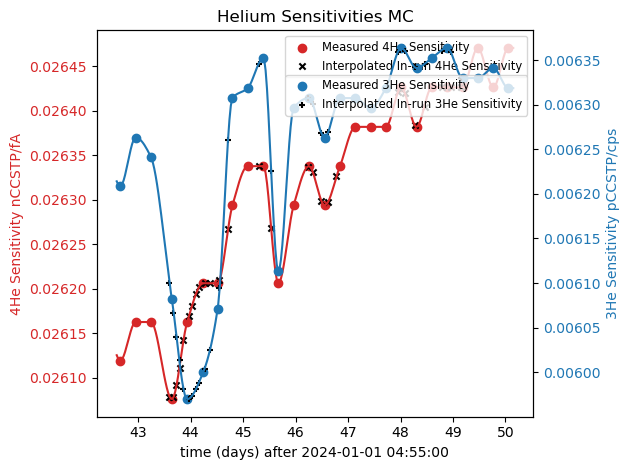

In [118]:
name = 'Blanks/H2OBlankTvary.csv'
COLDS = pd.read_csv('Blanks/H2OBlankTvary.csv').to_numpy()[:27]
He3, He4 = reducer.reduce(COLDS, plot = True)
outframe = pd.DataFrame()
outframe['3He'] = He3
outframe['4He'] = He4
outframe.to_csv(name.split('.csv')[0]+'REDUCED'+'.csv')

[False False False False False False False False False False  True  True
  True  True  True  True  True  True False False False False False False
 False False False False]
[1386.503583 1428.909156 4345.735786 1478.905287 4187.584823 523.9842734]


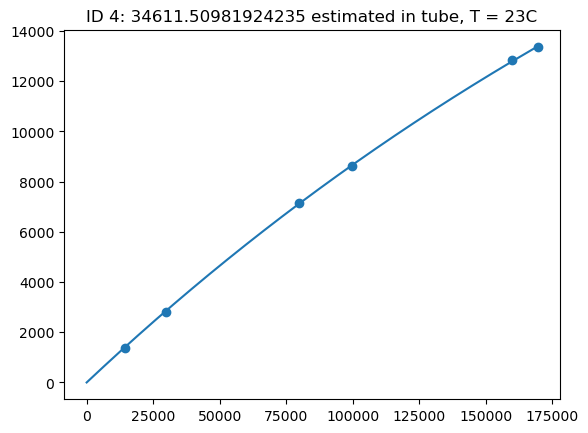

In [58]:
T = 23
sequenceID = COLDS[:,3] == T
print(sequenceID)
times = COLDS[sequenceID,7][2:]
He = COLDS[sequenceID,9][2:]
print(He)
ilambda, in0 = KenColdInversion(times, He, plot = True)
plt.title(f"ID {ID}: {in0} estimated in tube, T = {T}C")
plt.show()
    #print(COLDS[sequenceID==ID,5])

In [173]:
He3, He4 = 

array([['He30484.txt', 'H2OBlank021324: 1325_10.0_21.0 20.20',
        '2/13/2024 17:38', 0, 25.5, 0.0249, 29100.0],
       ['He30487.txt', 'H2OBlank021324: 1345_60.0_80.0 80.01',
        '2/13/2024 19:05', 80, 143.0, 0.638, 161000.0],
       ['He30490.txt', 'H2OBlank021324: 1365_60.0_80.0 80.00',
        '2/13/2024 21:00', 80, 144.0, 0.632, 163000.0],
       ['He30494.txt', 'H2OBlank021324: 1385_60.0_80.0 80.00',
        '2/13/2024 22:26', 80, 119.0, 0.543, 136000.0],
       ['He30497.txt', 'H2OBlank021324: 1405_60.0_80.0 80.00',
        '2/13/2024 23:53', 80, 110.0, 0.473, 127000.0],
       ['He30500.txt', 'H2OBlank021324: 1425_60.0_80.0 80.00',
        '2/14/2024 1:20', 80, 102.0, 0.385, 119000.0],
       ['He30505.txt', 'H2OBlank021324: 1445_60.0_100.0 100.02',
        '2/14/2024 3:58', 100, 158.0, 0.955, 186000.0],
       ['He30507.txt', 'H2OBlank021324: 1475_60.0_100.0 100.01',
        '2/14/2024 5:25', 100, 119.0, 0.617, 145000.0],
       ['He30510.txt', 'H2OBlank021324: 1495_60

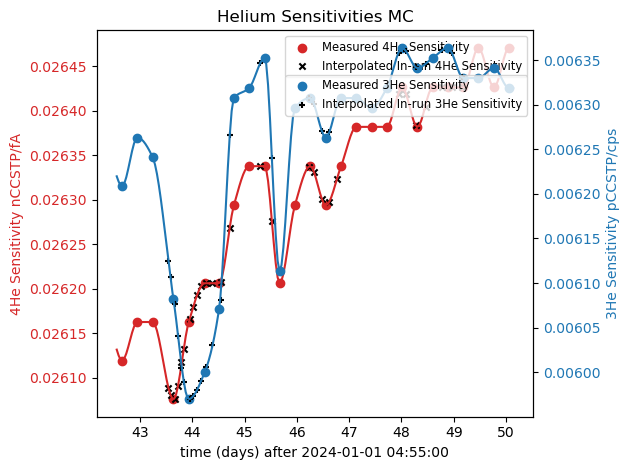

[  5220.   6900.   5160.   5220.   5220.   9480.   5220.   6780.   5220.
   9060.   9600.  14340.  15480.  50100.  19740.  60300.   9480.  12420.
  12420.  12480. 102060.  12420.  16020.  16020.  27480.  16020.  16440.]
[     0.   5220.   6900.   5160.   5220.   5220.   9480.   5220.   6780.
   5220.   9060.   9600.  14340.  15480.  50100.  19740.  60300.   9480.
  12420.  12420.  12480. 102060.  12420.  16020.  16020.  27480.  16020.
  16440.]
[ 9060.  9600. 14340. 15480. 50100. 19740. 60300.  9480.]


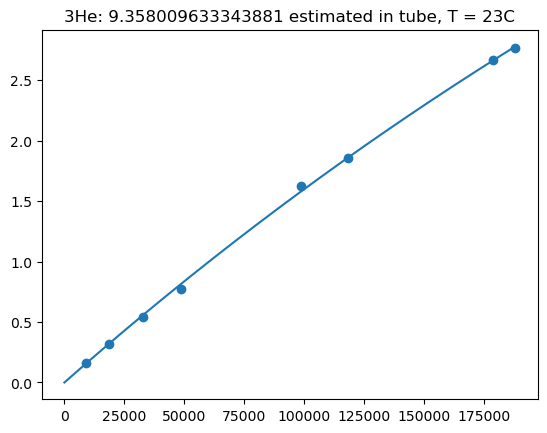

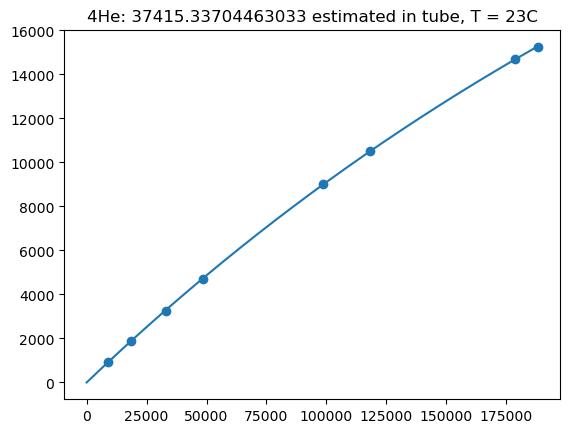

8
[3 4 5 6 7 8]
[ 9060.  9600. 14340.]
[ 9060.  9600. 14340. 15480.]
[ 9060.  9600. 14340. 15480. 50100.]
[ 9060.  9600. 14340. 15480. 50100. 19740.]
[ 9060.  9600. 14340. 15480. 50100. 19740. 60300.]
[ 9060.  9600. 14340. 15480. 50100. 19740. 60300.  9480.]


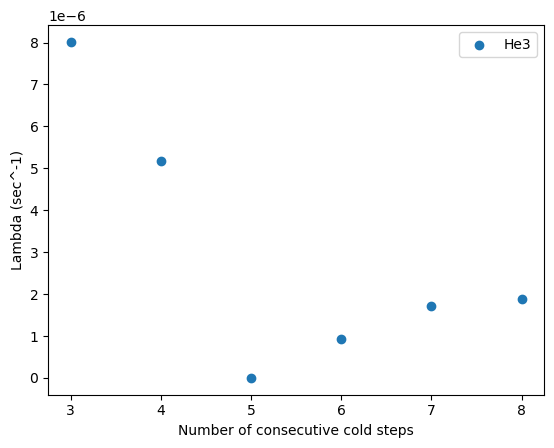

[8.014509426313389e-06, 5.170483984620557e-06, 0, 9.362090818983514e-07, 1.7104066611333015e-06, 1.8722355455529998e-06]


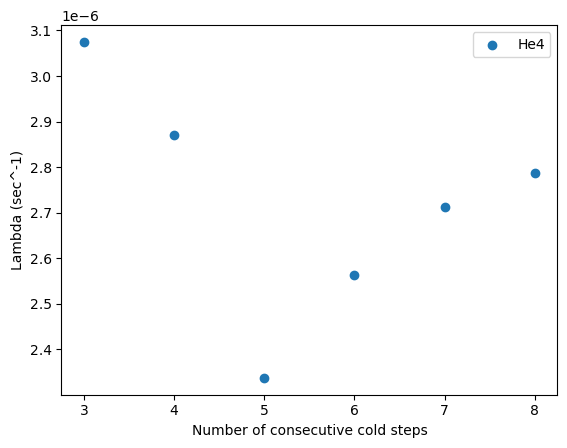

[3.074845160038986e-06, 2.8710785461812945e-06, 2.3369433342598975e-06, 2.5640177846464133e-06, 2.711651046357528e-06, 2.78769900061804e-06]


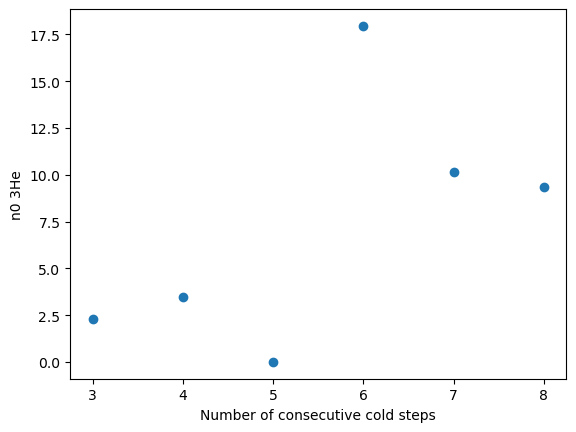

[ 2.31717159  3.46981541  0.         17.95067646 10.16502969  9.35800963]


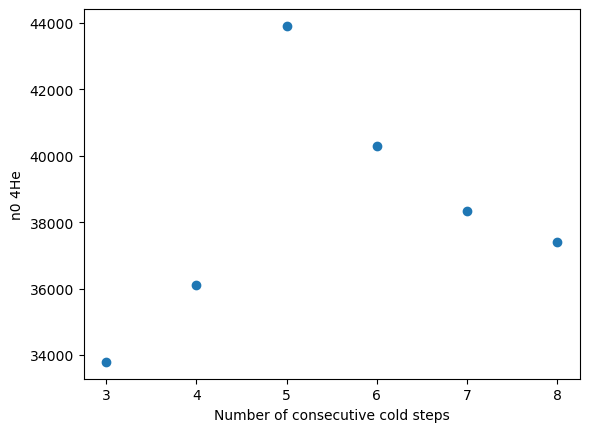

[33794.23844857 36100.7374129  43910.36253011 40285.09428389
 38330.32309572 37415.33704463]
[16020. 16020. 27480. 16020. 16440.]


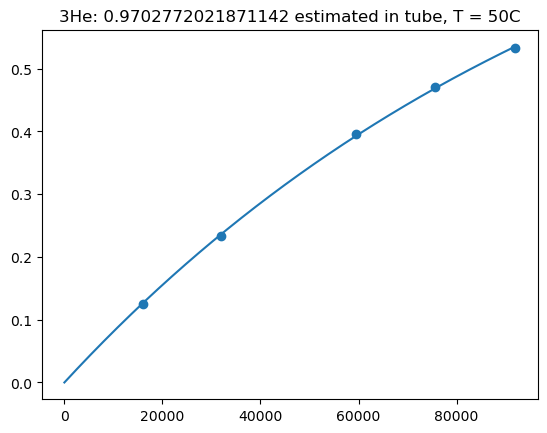

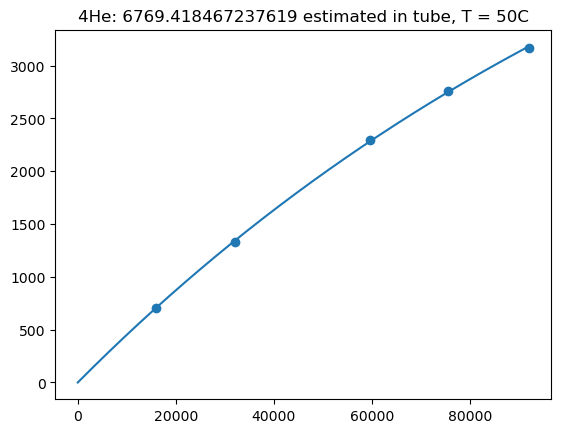

5
[3 4 5]
[16020. 16020. 27480.]
[16020. 16020. 27480. 16020.]
[16020. 16020. 27480. 16020. 16440.]


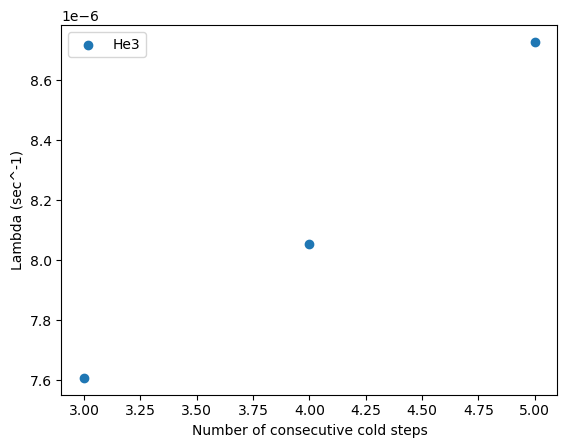

[7.606793535129951e-06, 8.054078960493029e-06, 8.727173624885009e-06]


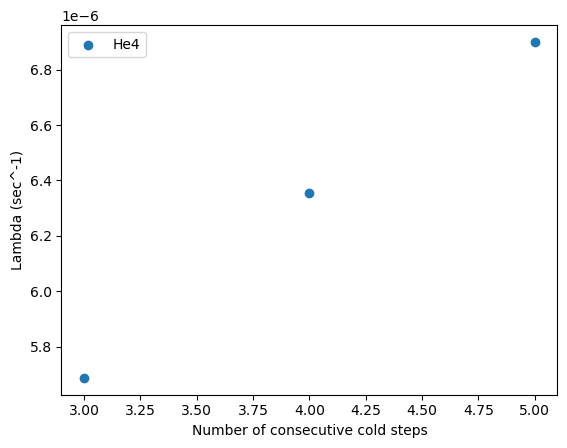

[5.687496505128922e-06, 6.355872743125356e-06, 6.899741034932414e-06]


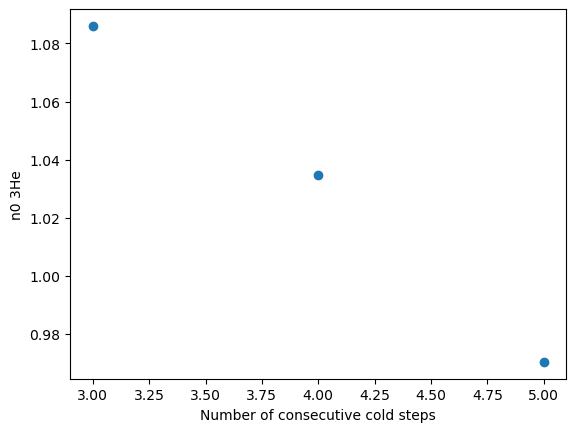

[1.08605544 1.03456076 0.9702772 ]


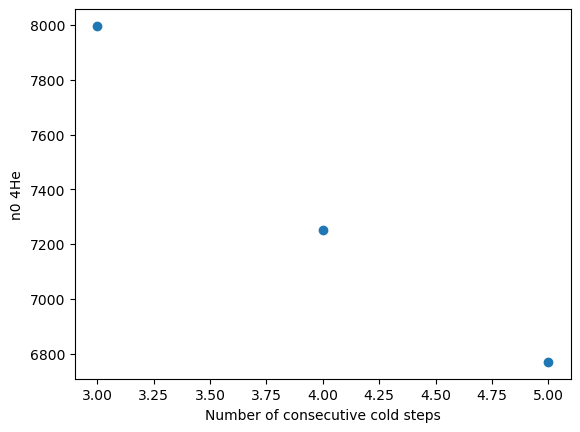

[7996.63487616 7250.47347504 6769.41846724]
[ 12420.  12420.  12480. 102060.  12420.]


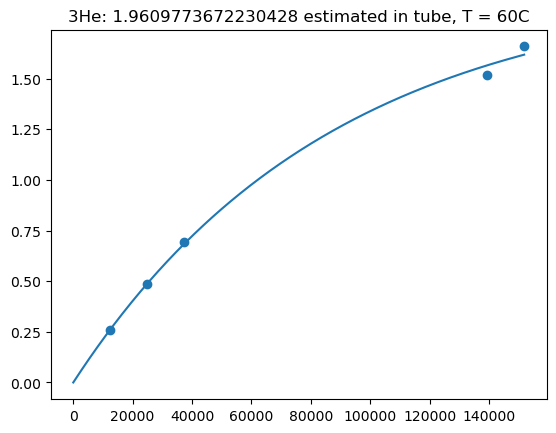

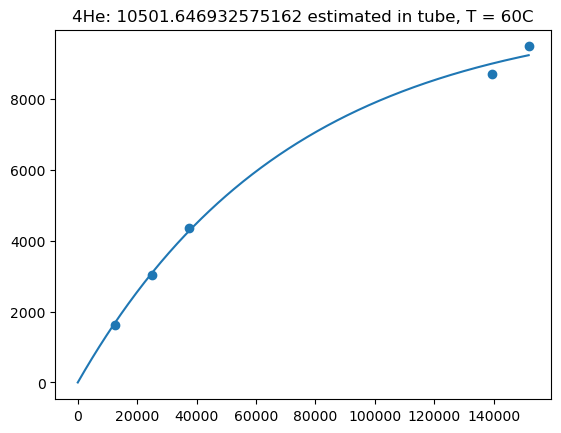

5
[3 4 5]
[12420. 12420. 12480.]
[ 12420.  12420.  12480. 102060.]
[ 12420.  12420.  12480. 102060.  12420.]


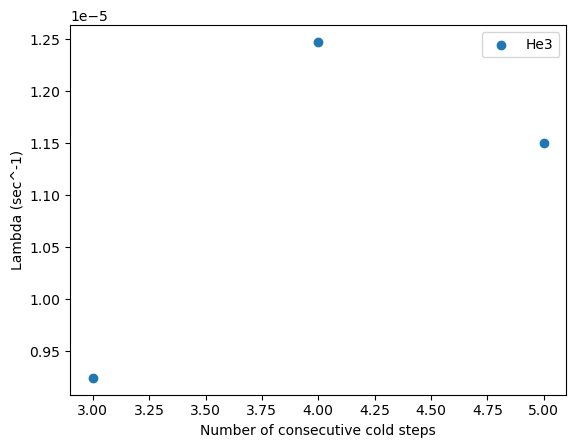

[9.243266986905897e-06, 1.2471923340220974e-05, 1.1496226751248621e-05]


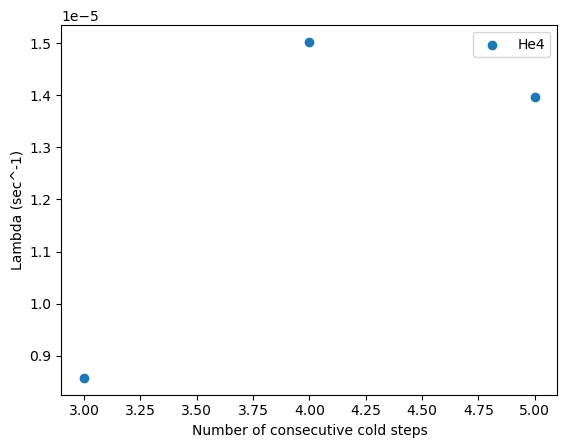

[8.57553105602731e-06, 1.5022500152438579e-05, 1.3963954706970784e-05]


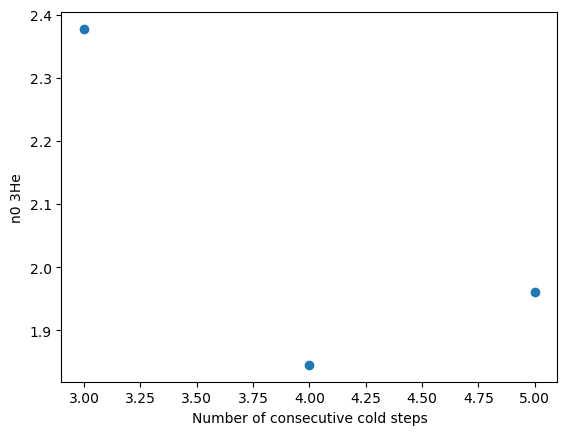

[2.37741499 1.84541511 1.96097737]


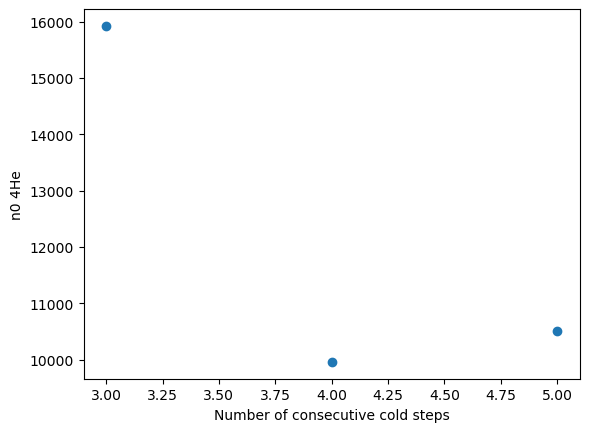

[15923.00555755  9959.67845555 10501.64693258]
[5220. 6900. 5160. 5220. 5220.]


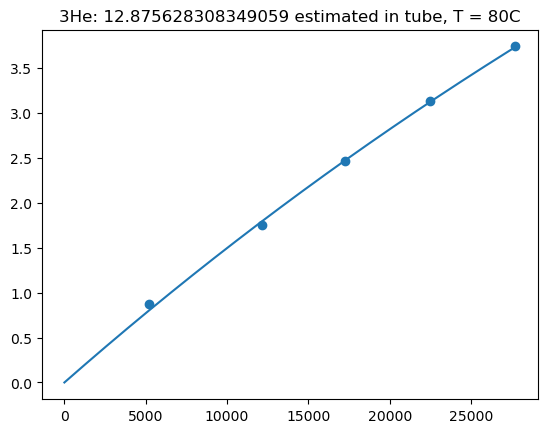

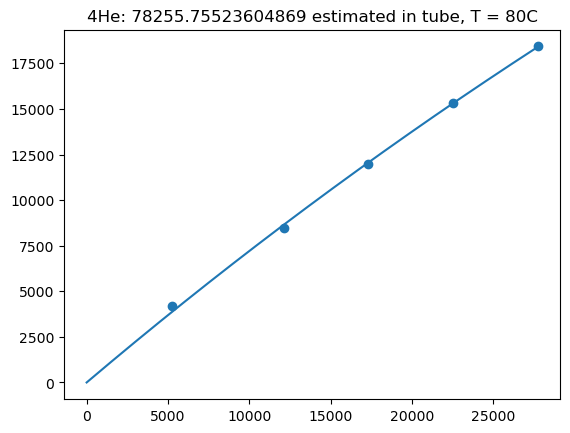

5
[3 4 5]
[5220. 6900. 5160.]
[5220. 6900. 5160. 5220.]
[5220. 6900. 5160. 5220. 5220.]


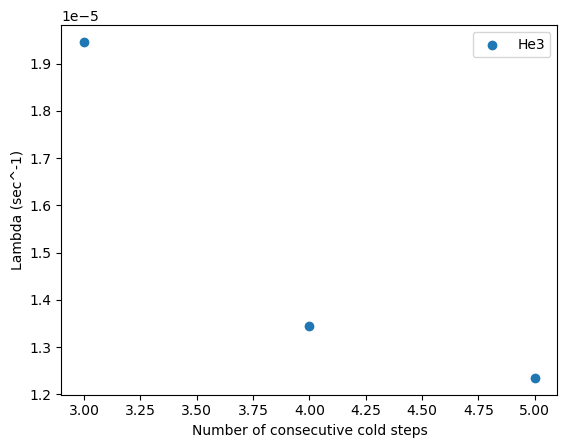

[1.9457171874458967e-05, 1.3458023040341594e-05, 1.234936915601111e-05]


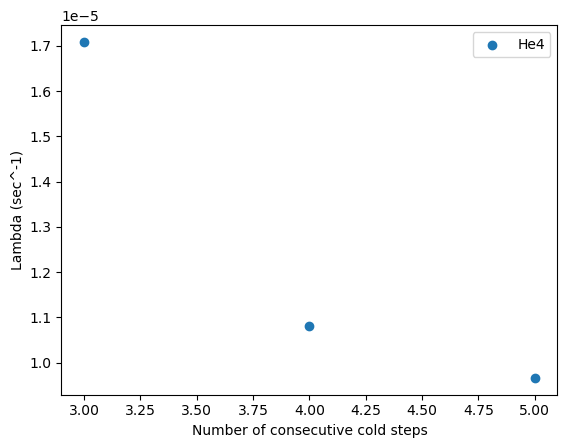

[1.708391086229015e-05, 1.0820940435271964e-05, 9.66576114533909e-06]


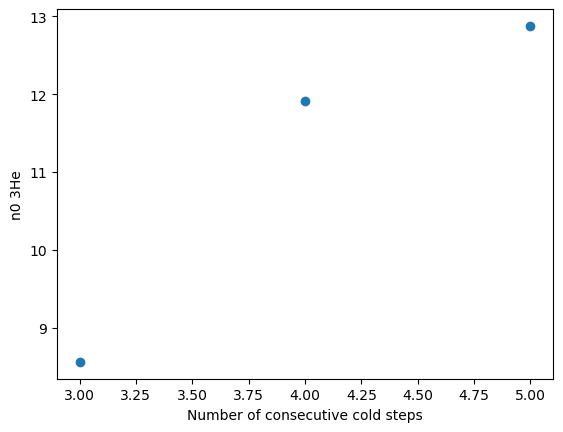

[ 8.56419239 11.91826924 12.87562831]


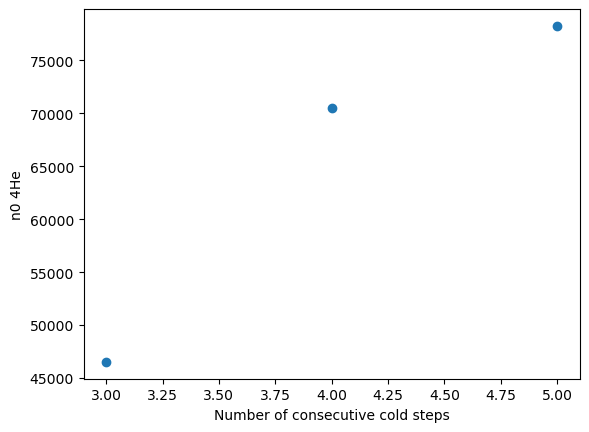

[46518.95118838 70547.02907509 78255.75523605]
[9480. 5220. 6780. 5220.]
[9480. 5220. 6780.]
[9480. 5220. 6780. 5220.]
[9480. 5220. 6780. 5220.]


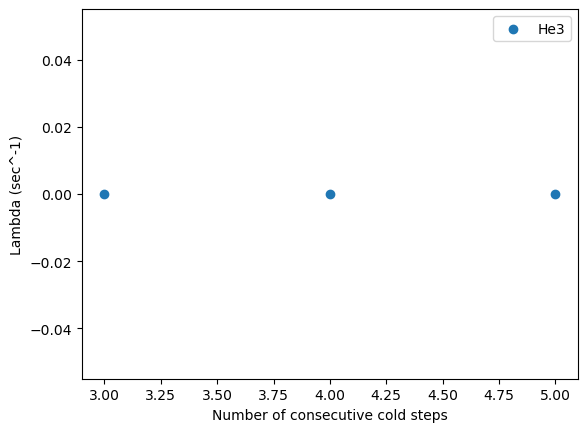

[0, 0, 0]


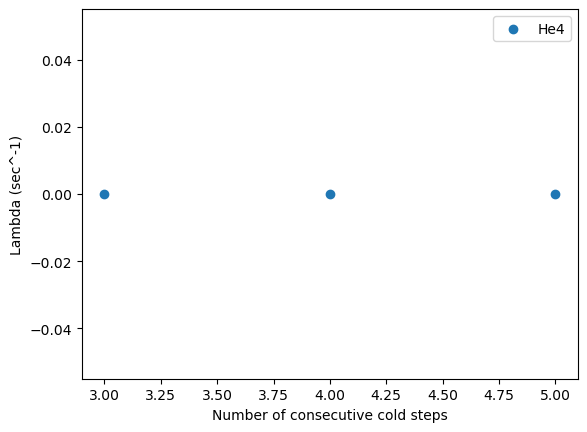

[0, 0, 0]


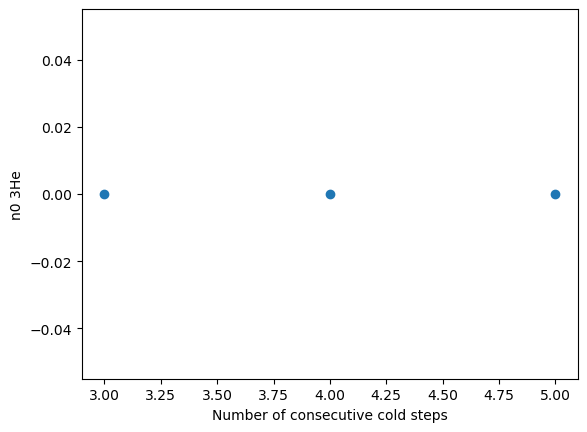

[0 0 0]


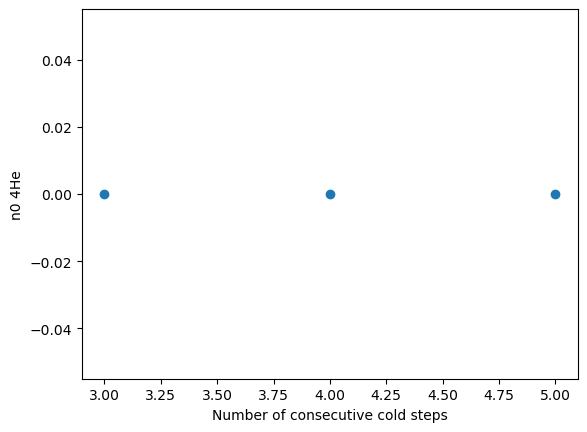

[0 0 0]
lambdas3: [1.8722355455529998e-06, 8.727173624885009e-06, 1.1496226751248621e-05, 1.234936915601111e-05, 0]
n03: [9.358009633343881, 0.9702772021871142, 1.9609773672230428, 12.875628308349059, 0]
lambdas4: [2.78769900061804e-06, 6.899741034932414e-06, 1.3963954706970784e-05, 9.66576114533909e-06, 0]
n04: [37415.33704463033, 6769.418467237619, 10501.646932575162, 78255.75523604869, 0]


In [20]:
COLDS = pd.read_csv('H2OBlank021324.csv', header = None).to_numpy()
T_unique = np.unique(COLDS[:,3])
#outlongn0 = np.zeros_like(sequenceID, dtype = float)
#outlonglambda = np.zeros_like(sequenceID, dtype = float)
He3, He4 = reducer.reduce(COLDS, plot = True)
plt.show()
all_times = extract_timesMC(COLDS[:,2])
print(all_times)
all_times = np.append(0,all_times)
print(all_times)
lambdas3 = []
lambdas4 = []
n03 = []
n04 = []

for ID, T in enumerate(T_unique[1:]):
    sequenceID = T == COLDS[:,3] 
    try:
        times = all_times[sequenceID]
        print(times)
        He = He3[sequenceID]

        ilambda, in0 = KenColdInversion(times, He, plot = True)
        lambdas3.append(ilambda)
        plt.title(f"3He: {in0} estimated in tube, T = {T}C")
        plt.show()
        
        
        n03.append(in0)
        He = He4[sequenceID]
        ilambda, in0 = KenColdInversion(times, He, plot = True)
        lambdas4.append(ilambda)
        n04.append(in0)
        plt.title(f"4He: {in0} estimated in tube, T = {T}C")
        plt.show()
        #print(COLDS[sequenceID==ID,5])
        #"""
        
        points = np.sum(sequenceID)
        print(points)
        
        Ls = np.arange(3,points+1)
        print(Ls)
        lamb3 = []
        lamb4 = []
        n3 = []
        n4 = []
            
    except:
        lambdas3.append(0)
        n03.append(0)
        lambdas4.append(0)
        n04.append(0)
        #"""
    lamb3 = []
    lamb4 = []
    n3 = []
    n4 = []
    if points > 3:
        for L in Ls:
            print(times[:L])
            try:
                lam, n0 = KenColdInversion(times[:L], He3[sequenceID][:L])
                lamb3.append(lam)
                n3.append(n0)
            except:
                lamb3.append(0)
                n3.append(0)
            try:
                lam, n0 = KenColdInversion(times[:L], He4[sequenceID][:L])
                lamb4.append(lam)
                n4.append(n0)
            except:
                lamb4.append(0)
                n4.append(0)
        n3 = np.array(n3)
        n4 = np.array(n4)
        plt.scatter(Ls, lamb3, label = 'He3')
        plt.legend()
        plt.xlabel('Number of consecutive cold steps')
        plt.ylabel('Lambda (sec^-1)')
        plt.show()
        print(lamb3)
        plt.scatter(Ls, lamb4, label = 'He4')
        plt.legend()
        plt.xlabel('Number of consecutive cold steps')
        plt.ylabel('Lambda (sec^-1)')
        plt.show()
        print(lamb4)
        plt.scatter(Ls, n3) 
        plt.xlabel('Number of consecutive cold steps')
        plt.ylabel('n0 3He')
        plt.show()
        print(n3)
        plt.scatter(Ls, n4)
        plt.xlabel('Number of consecutive cold steps')
        plt.ylabel('n0 4He')
        plt.show()
        print(n4)
    
print(f"lambdas3: {lambdas3}")
print(f"n03: {n03}")
print(f"lambdas4: {lambdas4}")
print(f"n04: {n04}")

In [175]:
sequenceID

array([False, False, False, False, False, False,  True,  True,  True,
        True, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False])

C:\Users\dashf\anaconda3\lib\site-packages\scipy\optimize\_minpack_py.py:906: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


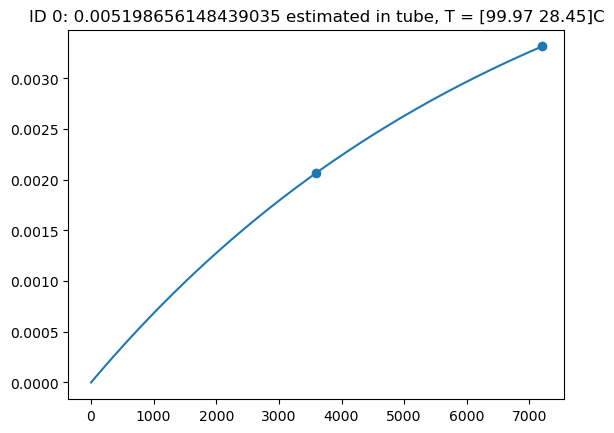

[9177.815 9128.275]


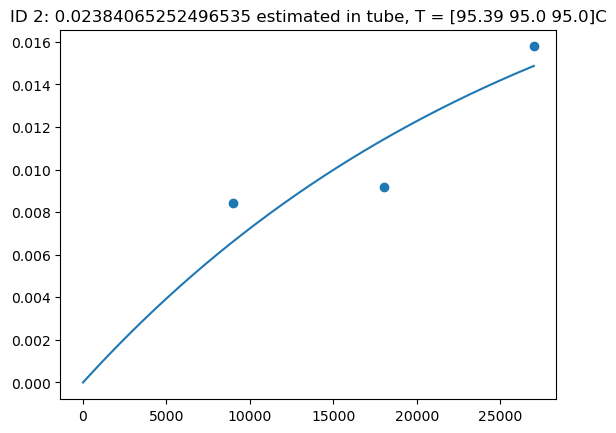

[7329.714 2878.405 2902.802]


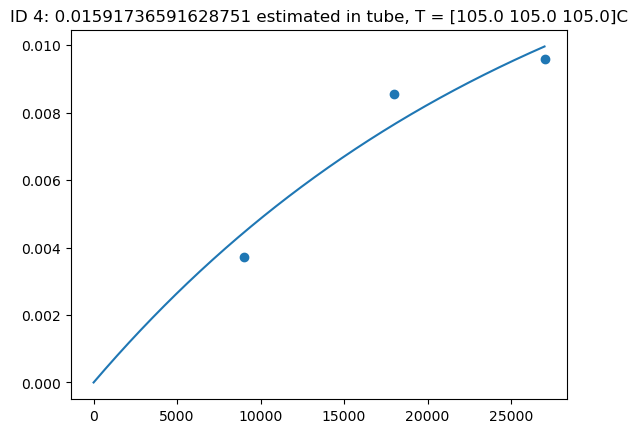

[9129.026 9127.555 9129.528]


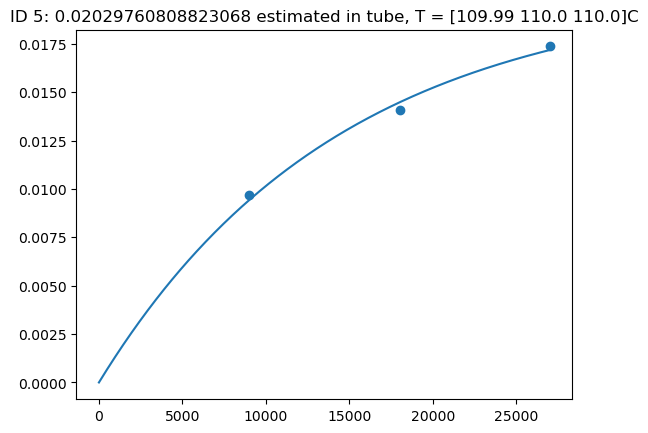

[9128.359 9129.162 9128.907]


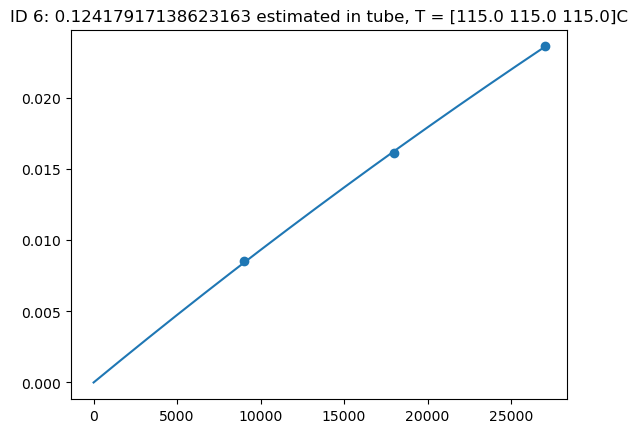

[9127.936 9128.579 9128.275]


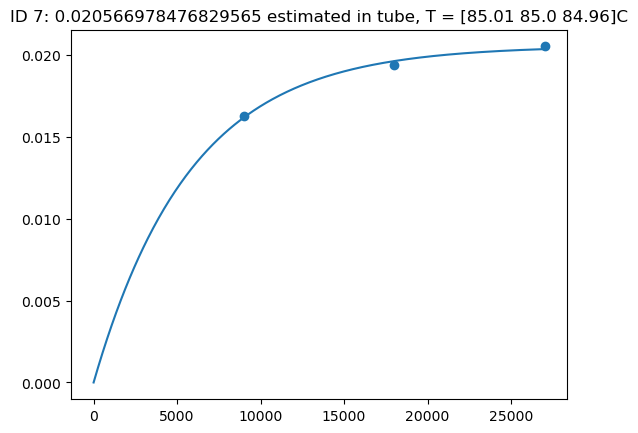

[9124.291 9127.531 8219.518]


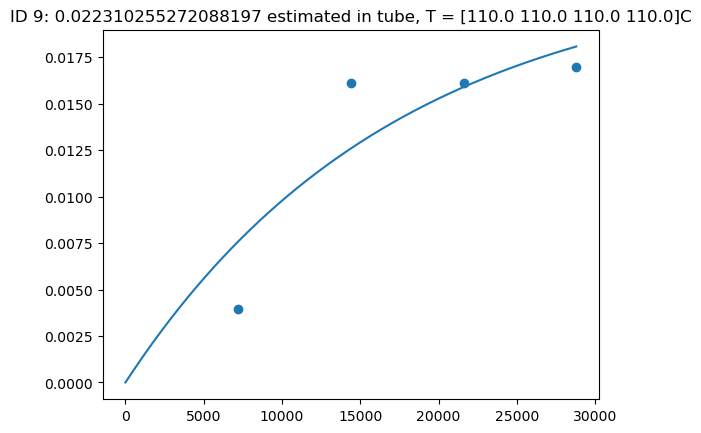

[7324.437 7328.951 7329.33 7329.801]


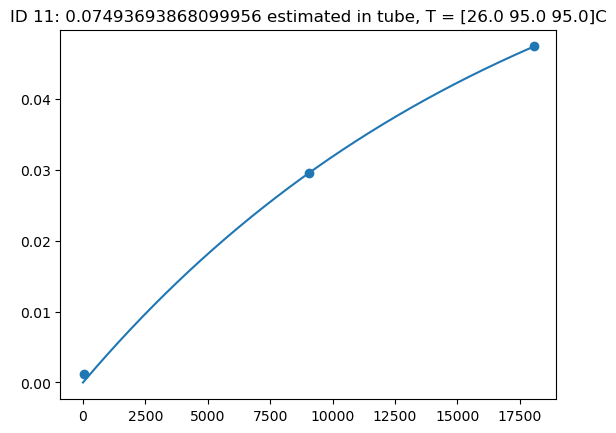

[186.582 9128.522 9125.996]


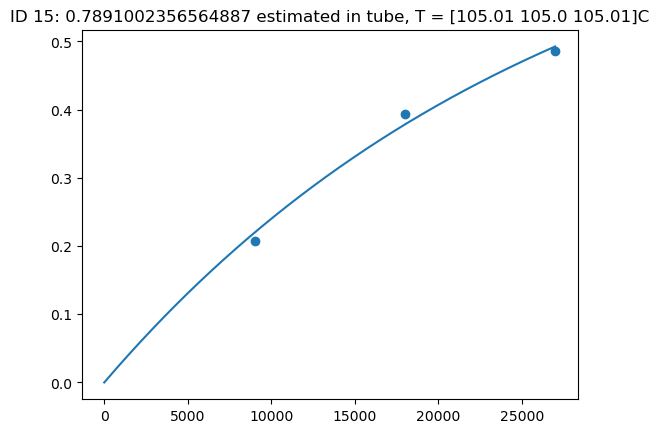

[9125.939 9127.269 9126.263]


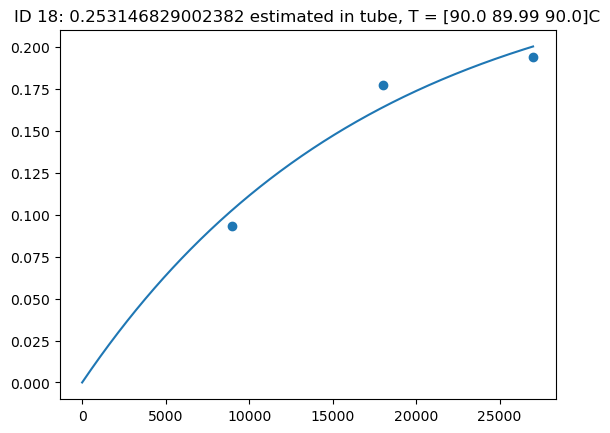

[9130.185 9124.847 9127.547]


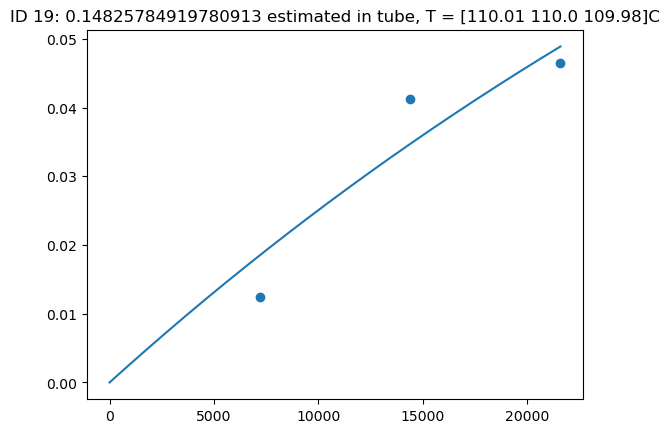

[7328.183 7329.714 7329.033]


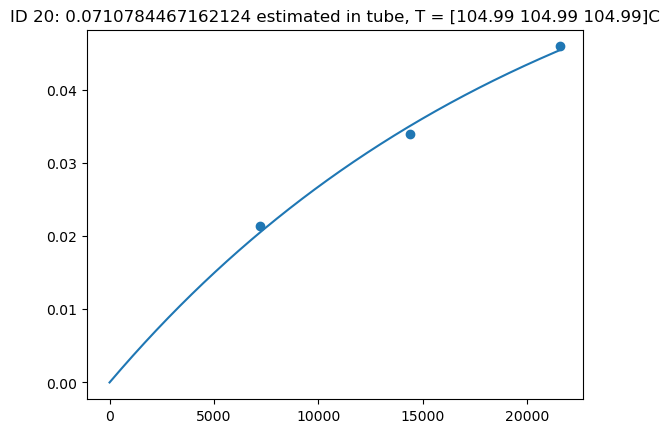

[7329.526 7328.208 7329.22]


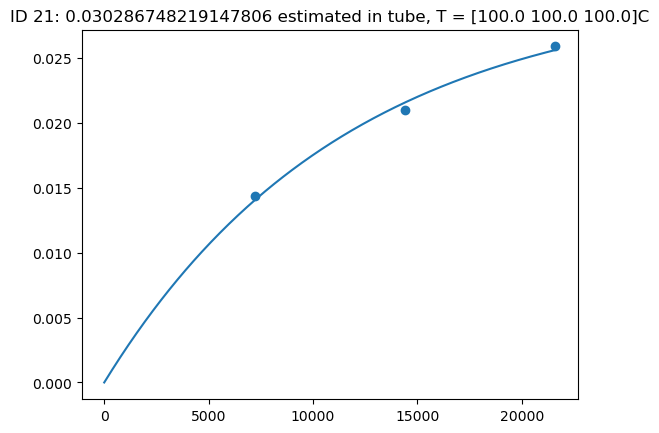

[7328.533 7328.068 7326.649]


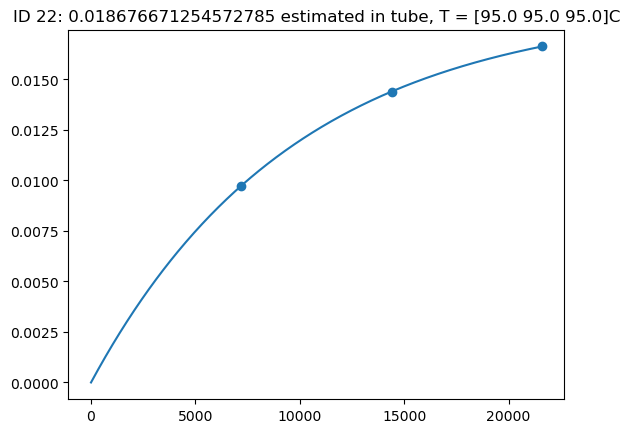

[7324.382 7324.593 7329.596]


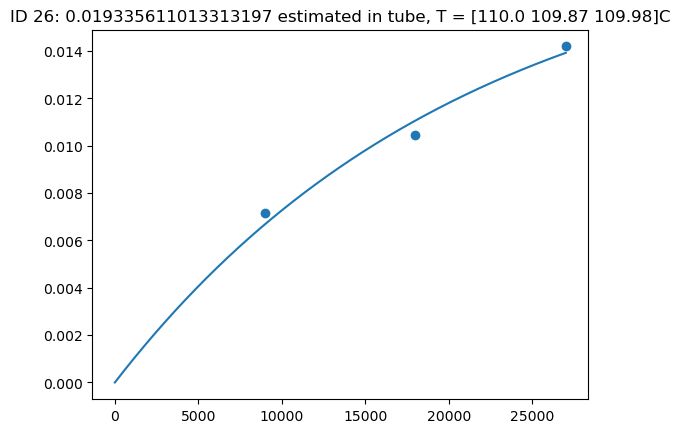

[9127.425 9129.154 9124.452]


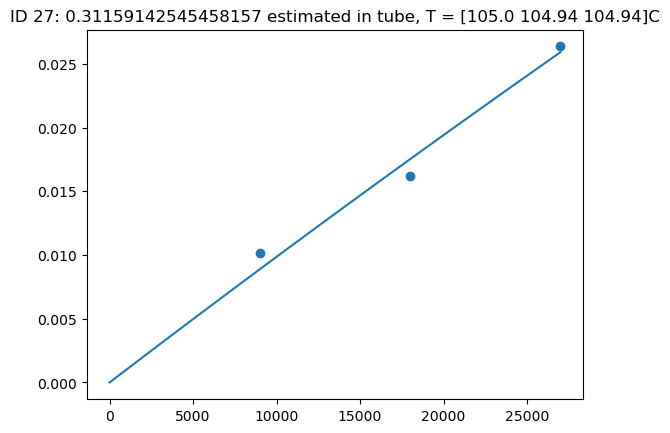

[9128.473 9129.461 9126.295]


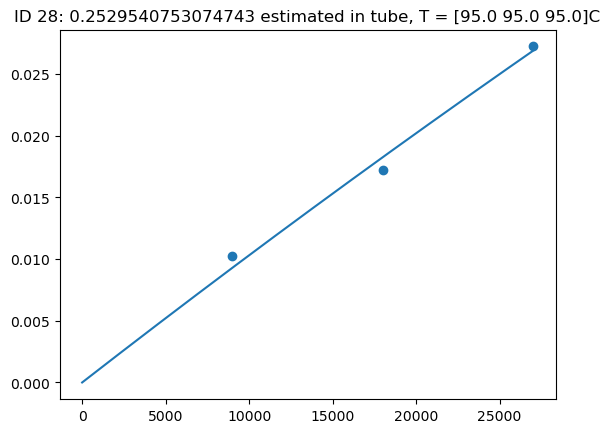

[9130.32 9125.318 26342.478]


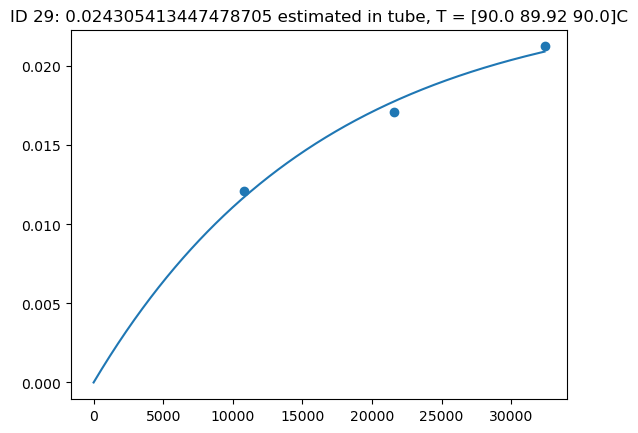

[10929.633 10928.4 10926.404]


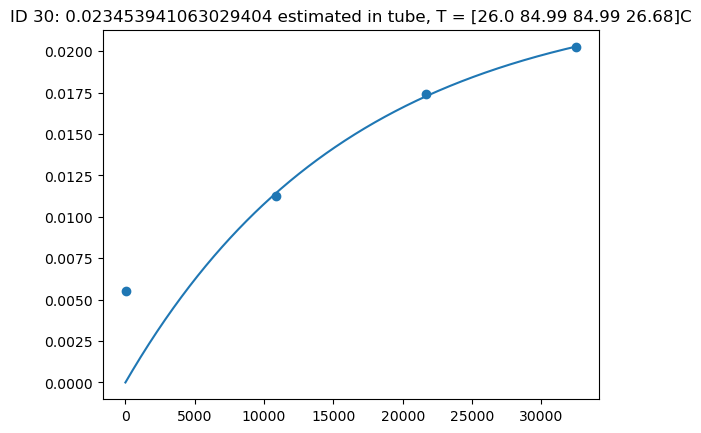

[186.233 10924.35 10929.771 10979.954]


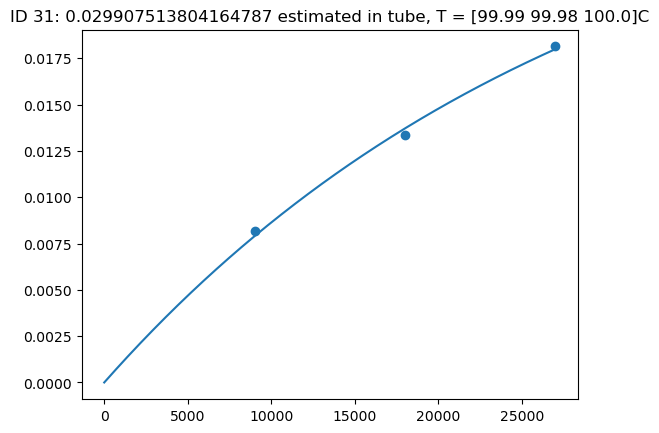

[9124.266 9124.285 9124.287]


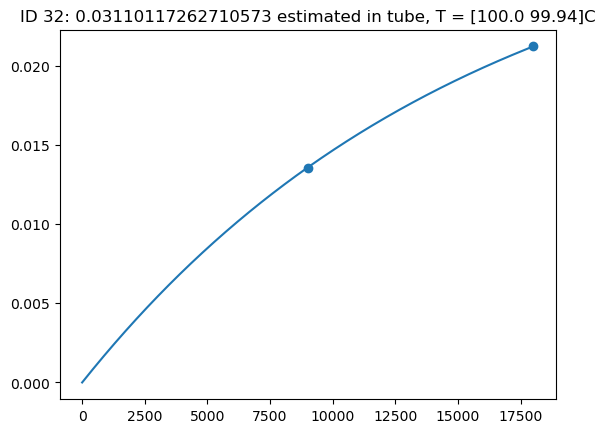

[9121.188 9124.411]
lambdas: [0.00014097631165001058, 0, 3.618841923786079e-05, 0, 3.6435423583501295e-05, 6.936501175378937e-05, 7.802468326895975e-06, 0.0001720152278740244, 0, 5.76755075139713e-05, 0, 5.5393311847770476e-05, 0, 0, 0, 3.6256141012978116e-05, 0, 0, 5.792840612496437e-05, 1.8521333630632955e-05, 4.7203822861423404e-05, 8.634093292302445e-05, 0.0001023850844440499, 0, 0, 0, 4.719035352836908e-05, 3.2152185365892762e-06, 4.161210997459147e-06, 6.09007887835092e-05, 6.157631222787125e-05, 3.4061859476625576e-05, 6.374435850287472e-05, 0, 0]
n0s: [0.005198656148439035, 0, 0.02384065252496535, 0, 0.01591736591628751, 0.02029760808823068, 0.12417917138623163, 0.020566978476829565, 0, 0.022310255272088197, 0, 0.07493693868099956, 0, 0, 0, 0.7891002356564887, 0, 0, 0.253146829002382, 0.14825784919780913, 0.0710784467162124, 0.030286748219147806, 0.018676671254572785, 0, 0, 0, 0.019335611013313197, 0.31159142545458157, 0.2529540753074743, 0.024305413447478705, 0.023453941063029

In [63]:
COLDS = pd.read_csv('IrrWin0601bTube012624TC4He_COLDS_TubeReduced.csv').to_numpy()
sequenceID = []
currentID = 0
count = 1
for cold in COLDS[:,1]: 
    
    if float(cold.split(' ')[0]) == float(count):
        #print(f"{float(cold.split(' ')[0])} == {float(count)}: {float(cold.split(' ')[0]) == float(count)}")
        count += 1
    else:
        #print('Break')
        #print(f"{float(cold.split(' ')[0])} == {float(count)}: {float(cold.split(' ')[0]) == float(count)}")
        count = 2
        currentID += 1
        
    sequenceID.append(currentID)
    #print(cold.split(' ')[0])
sequenceID = np.array(sequenceID)
lambdas = []
n0s = []

outlongn0 = np.zeros_like(sequenceID, dtype = float)
outlonglambda = np.zeros_like(sequenceID, dtype = float)

for ID in range(currentID+1):
    try:
        times = COLDS[sequenceID==ID,3]
        ilambda, in0 = KenColdInversion(COLDS[sequenceID==ID,3], COLDS[sequenceID==ID,13], plot = True)
        plt.title(f"ID {ID}: {in0} estimated in tube, T = {COLDS[sequenceID==ID,2]}C")
        plt.show()
        print(COLDS[sequenceID==ID,5])
        
    except:
        (ilambda, in0) = (0,0)
    outlongn0[sequenceID==ID] = in0
    outlonglambda[sequenceID==ID] = ilambda
    lambdas.append(ilambda)
    n0s.append(in0)
    
print(f"lambdas: {lambdas}")
print(f"n0s: {n0s}")

In [67]:
T = [90,
95,
100,
105,
110]
for t in T:
    print(np.log(swets('K',t+273)))

24.940129520836724
25.03243208662803
25.12226005280027
25.209711617751026
25.294879852024213


Assuming all standards analyzed had 157.5 nCCSTP 4He and 3.57 pCCSTP 3He
Done! Output file: manualSulfurBlankRed.csv in C:\Users\dashf\pyrite


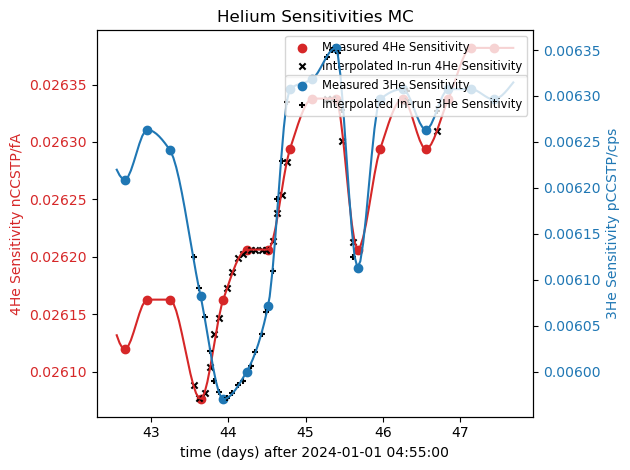

In [3]:
DIFFCELL = pd.read_csv('SulfurBlank021324.csv', header = None).to_numpy()
reducer = MCHeReducer('2024STDsMC.csv')
(He3, He4), (sens3, sens4) = reducer.reduce(DIFFCELL, plot = True, sens_out = True)
#plt.savefig('IrrWinsMCSens.jpg', dpi = 256)
data = [He3, He4, sens3, sens4]
columns = ['3He (pccSTP)', '4He (nccSTP)', 'Sensitivity 3He (pccSTP/cps)', 'Sensitivity 4He (nccSTP/cps)']
Reduced_Data = pd.DataFrame()
for j, column in enumerate(columns):
    Reduced_Data[column] = data[j]
newDiffName = 'manualSulfurBlankRed.csv'
Reduced_Data.to_csv(newDiffName)
print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

In [64]:
lambdas_out = pd.DataFrame()
lambdas_out['lambda'] = outlonglambda
lambdas_out['n0'] = outlongn0
lambdas_out.to_csv('lambda_expfit4He.csv')

In [205]:
DIFFCELL = pd.read_csv('IrrWin0601bTube012624TC.csv', header = None).to_numpy()
reducer = MCHeReducer('2024STDsMC.csv')
He3, He4 = reducer.reduce(DIFFCELL)
data = [He3, He4]
columns = ['3He', '4He']
Reduced_Data = pd.DataFrame()
T_cutoff = 273 + 130

He4_Blank = 0.001245588 #ncc

rest_He = [total_3He, total_4He]
metadata = DIFFCELL[:,1]
TimeSeconds = np.array([60*pull_number((str(datum).split(' ')[1]).split('_')[1]) for datum in metadata])
TempKelvin = np.array([273+pull_number(str(datum).split(' ')[2]) for datum in metadata])
TargetTemp = np.array([273+pull_number((str(datum).split(' ')[1]).split('_')[2]) for datum in metadata]) 
recordedTimeSeconds = np.array([get_real_time((str(datum).split(' ')[1]).split('_')[0]) for datum in metadata])
coldtimes = np.array([0] + list(extract_timesMC(DIFFCELL[:,2])))


#total_4He = 55*1.18 # 122 nccSTP 4He total_yield 
#total_3He = 105*1.18 # pccSTP 3He total_yield
#146.0787046	147.8545425

total_4He = 147.86 #nccSTP 4He total_yield 
total_3He = 146.08 # pccSTP 3He total_yield

OD = 800/1E4
ID = 510/1E4

G = 2/(np.log(OD/ID)*((ID/2)**2))

n0UB = []
ntUB = []
ntLB = []
wUB = []
wLB = []
HTind = []
P = 0
first = True
cumHeRec = []
cumHe = 0

for i, HeUC in enumerate(He4):
    He = HeUC - He4_Blank
    if He < 0:
        He = 0
    Tk = TempKelvin[i]
    if Tk > T_cutoff:
        if first:
            n0UB.append(0)
            first = False
            nss_complex = He/((lam*TimeSeconds[i])-1)
        else: 
            cumHe += P
            if P > ntUB[-1]:
                print(f'Measured P higher than ntUB for previous HT step to {i}. P = {P}')
                #nss_complex = ((He+(n0UB[-1]*np.exp(-lam*TimeSeconds[i])))/(lam*TimeSeconds[i]))/(1-(1-(np.exp(-lam*TimeSeconds[i]))/(lam*TimeSeconds[i])))
                #nss_complex = ((He+(n0UB[-1]*np.exp(-lam*t_last)))/(lam*t_last))/(1-(1-(np.exp(-lam*t_last))/(lam*t_last)))
                #ntUB[-1] = np.max([nss_complex, nss_complex+((n0UB[-1]-nss_complex)*np.exp(-lam*t_last))])
                #if P > ntUB[-1]: 
                #    print("Dang, still didn't fix the problem")
            ntLB.append(P) # For previous sample
            
            n0UB.append(ntUB[-1] - P)
            
        lam = Tk*Ratoms*G*swets('K',Tk)
        cumHeRec.append(cumHe)
        if n0UB[-1] < 0:
            print(f'NEGATIVE n0UB! step: {i} T = {TempKelvin[i]-273} C, t = {TimeSeconds[i]/60} min')
            n0UB[-1] = ntUB[-1]
        HTind.append(i)
        
        nss = He/((lam*TimeSeconds[i])-1)
       
        
        #print(f"step: {i} simple: {nss_simple}\tcomplex: {nss_complex}")
        #nss = np.max([nss_simple, nss_complex])
        if nss < 0:
            print(f'NEGATIVE nss! step: {i}')
            nss = He/((lam*TimeSeconds[i]))
        #print(nss)
        #print(n0UB[-1])
        if nss > n0UB[-1]:
            ntUB.append(nss)
        else:
            print(f'High n0UB step: {i}')
            ntUB.append(nss+((n0UB[-1]-nss)*np.exp(-lam*TimeSeconds[i])))
        cumHe += He
        t_last = TimeSeconds[i]
        P = 0
        He_last = He
    else: 
        P += He
ntLB.append(P) #Final He,     

omegaLB = He4[HTind] + np.array(ntLB) - np.array(n0UB) 
omegaUB = He4[HTind] + np.array(ntUB)


columns = ['Temp (C)','Time (m)','Cum Prev Measured','Omega LB', 'Measured', 'Omega UB', 'n0UB','ntLB','ntUB']
data = [TempKelvin[HTind]-273, TimeSeconds[HTind]/60, cumHeRec, omegaLB, He4[HTind], omegaUB, n0UB, ntLB, ntUB]
for j, column in enumerate(columns):
    Reduced_Data[column] = data[j]
newDiffName = 'bounded4HeIrrWins.csv'
Reduced_Data.to_csv(newDiffName)
print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

Assuming all standards analyzed had 157.5 nCCSTP 4He and 3.57 pCCSTP 3He
High n0UB step: 30
High n0UB step: 35
Measured P higher than ntUB for previous HT step to 44. P = 0.01816538508599593
NEGATIVE n0UB! step: 44 T = 195.0 C, t = 1106.0 min
High n0UB step: 44
Measured P higher than ntUB for previous HT step to 48. P = 0.043718334790255275
NEGATIVE n0UB! step: 48 T = 185.0 C, t = 740.0 min
High n0UB step: 48
Measured P higher than ntUB for previous HT step to 52. P = 0.014460316537313434
NEGATIVE n0UB! step: 52 T = 175.0 C, t = 920.0 min
Measured P higher than ntUB for previous HT step to 56. P = 0.005154545373396968
NEGATIVE n0UB! step: 56 T = 200.0 C, t = 260.0 min
Measured P higher than ntUB for previous HT step to 62. P = 0.4827564340087288
NEGATIVE n0UB! step: 62 T = 219.98000000000002 C, t = 1167.0 min
High n0UB step: 62
Measured P higher than ntUB for previous HT step to 66. P = 0.2700052860578567
NEGATIVE n0UB! step: 66 T = 229.99 C, t = 370.0 min
Measured P higher than ntUB f

In [ ]:
DIFFCELL = pd.read_csv('IrrWin0601bTube012624TC.csv', header = None).to_numpy()
reducer = MCHeReducer('2024STDsMC.csv')
He3, He4 = reducer.reduce(DIFFCELL)
data = [He3, He4]
columns = ['3He', '4He']
Reduced_Data = pd.DataFrame()
T_cutoff = 273 + 130

He4_Blank = 0.001245588 #ncc

rest_He = [total_3He, total_4He]
metadata = DIFFCELL[:,1]
TimeSeconds = np.array([60*pull_number((str(datum).split(' ')[1]).split('_')[1]) for datum in metadata])
TempKelvin = np.array([273+pull_number(str(datum).split(' ')[2]) for datum in metadata])
TargetTemp = np.array([273+pull_number((str(datum).split(' ')[1]).split('_')[2]) for datum in metadata]) 
recordedTimeSeconds = np.array([get_real_time((str(datum).split(' ')[1]).split('_')[0]) for datum in metadata])
coldtimes = np.array([0] + list(extract_timesMC(DIFFCELL[:,2])))


#total_4He = 55*1.18 # 122 nccSTP 4He total_yield 
#total_3He = 105*1.18 # pccSTP 3He total_yield
#146.0787046	147.8545425

total_4He = 147.86 #nccSTP 4He total_yield 
total_3He = 146.08 # pccSTP 3He total_yield

OD = 800/1E4
ID = 510/1E4

G = 2/(np.log(OD/ID)*((ID/2)**2))

n0UB = []
ntUB = []
ntLB = []
wUB = []
wLB = []
HTind = []
P = 0
first = True
cumHeRec = []
cumHe = 0

for i, HeUC in enumerate(He4):
    He = HeUC - He4_Blank
    if He < 0:
        He = 0
    Tk = TempKelvin[i]
    if Tk > T_cutoff:
        if first:
            n0UB.append(0)
            first = False
            nss_complex = He/((lam*TimeSeconds[i])-1)
        else: 
            cumHe += P
            if P > ntUB[-1]:
                print(f'Measured P higher than ntUB for previous HT step to {i}. P = {P}')
                #nss_complex = ((He+(n0UB[-1]*np.exp(-lam*TimeSeconds[i])))/(lam*TimeSeconds[i]))/(1-(1-(np.exp(-lam*TimeSeconds[i]))/(lam*TimeSeconds[i])))
                #nss_complex = ((He+(n0UB[-1]*np.exp(-lam*t_last)))/(lam*t_last))/(1-(1-(np.exp(-lam*t_last))/(lam*t_last)))
                #ntUB[-1] = np.max([nss_complex, nss_complex+((n0UB[-1]-nss_complex)*np.exp(-lam*t_last))])
                #if P > ntUB[-1]: 
                #    print("Dang, still didn't fix the problem")
            ntLB.append(P) # For previous sample
            
            n0UB.append(ntUB[-1] - P)
            
        lam = Tk*Ratoms*G*swets('K',Tk)
        cumHeRec.append(cumHe)
        if n0UB[-1] < 0:
            print(f'NEGATIVE n0UB! step: {i} T = {TempKelvin[i]-273} C, t = {TimeSeconds[i]/60} min')
            n0UB[-1] = ntUB[-1]
        HTind.append(i)
        
        nss = He/((lam*TimeSeconds[i])-1)
       
        
        #print(f"step: {i} simple: {nss_simple}\tcomplex: {nss_complex}")
        #nss = np.max([nss_simple, nss_complex])
        if nss < 0:
            print(f'NEGATIVE nss! step: {i}')
            nss = He/((lam*TimeSeconds[i]))
        #print(nss)
        #print(n0UB[-1])
        if nss > n0UB[-1]:
            ntUB.append(nss)
        else:
            print(f'High n0UB step: {i}')
            ntUB.append(nss+((n0UB[-1]-nss)*np.exp(-lam*TimeSeconds[i])))
        cumHe += He
        t_last = TimeSeconds[i]
        P = 0
        He_last = He
    else: 
        P += He
ntLB.append(P) #Final He,     

omegaLB = He4[HTind] + np.array(ntLB) - np.array(n0UB) 
omegaUB = He4[HTind] + np.array(ntUB)


columns = ['Temp (C)','Time (m)','Cum Prev Measured','Omega LB', 'Measured', 'Omega UB', 'n0UB','ntLB','ntUB']
data = [TempKelvin[HTind]-273, TimeSeconds[HTind]/60, cumHeRec, omegaLB, He4[HTind], omegaUB, n0UB, ntLB, ntUB]
for j, column in enumerate(columns):
    Reduced_Data[column] = data[j]
newDiffName = 'bounded4HeIrrWins.csv'
Reduced_Data.to_csv(newDiffName)
print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

In [115]:
ntLB

[0.003314705882352941,
 0.016296650913757944,
 0.016296650913757944,
 0.015778516636986907,
 0.015778516636986907,
 0.010026160224407447,
 0.010026160224407447,
 0.009595348759486115,
 0.009595348759486115,
 0.017360159196387396,
 0.017360159196387396,
 0.02362574569313466,
 0.02362574569313466,
 0.02052948929159802,
 0.02052948929159802,
 0.015646439231568575,
 0.015646439231568575,
 0.016829851239669423,
 0.016829851239669423,
 0.02190214908599593,
 0.02190214908599593,
 0.0473862050051313,
 0.0473862050051313,
 0.01788134328358209,
 0.01788134328358209,
 0.008891309373396966,
 0.008891309373396966,
 0.00014536873007356884,
 0.00014536873007356884,
 0.48649319800872876,
 0.48649319800872876,
 0.2737420500578567,
 0.2737420500578567,
 0.05276493500996479,
 0.05276493500996479,
 0.19401511037666183,
 0.19401511037666183,
 0.046498832069756066,
 0.046498832069756066,
 0.045903190403904705,
 0.045903190403904705,
 0.02587017443610174,
 0.02587017443610174,
 0.016631470588235293,
 0.01663

In [103]:
molMl=(5.2E-6/(Ratoms*298))/6.02214E23 #mol/mL
nccMl = 1E9*molMl/4.46E-5

#Chat gpt
molMl = 2.69E19/6.02214E23
nccMl = 1E9*molMl/4.46E-5
((2*np.pi*((OD/2)**2))-((2*np.pi*((ID/2)**2))))*4777*0.0225

0.6413970084237887

In [99]:
OD = 800/1E4
ID = 510/1E4



Assuming all standards analyzed had 157.5 nCCSTP 4He and 3.57 pCCSTP 3He


C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\1107171875.py:190: RuntimeWarning: divide by zero encountered in scalar divide
  n1_measured.append(HenCC[i]/((1/(1-(m*TimeSeconds[i]))-1)))
C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\1107171875.py:185: RuntimeWarning: invalid value encountered in scalar divide
  n1_n0_measured = (HenCC[i]/TimeSeconds[i])/(HenCC[i-1]/TimeSeconds[i-1]) # Assume unchanging abundance, time normalize
C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\1107171875.py:185: RuntimeWarning: divide by zero encountered in scalar divide
  n1_n0_measured = (HenCC[i]/TimeSeconds[i])/(HenCC[i-1]/TimeSeconds[i-1]) # Assume unchanging abundance, time normalize
C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\1107171875.py:223: RuntimeWarning: divide by zero encountered in divide
  lambdas = -np.log((np.array(n1_measured)/np.array(n0_measured)))/(TempKelvin[Smeas]*Rel_times*Ratoms)
C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\1107171875.py:223: RuntimeWarning: inva

COLD 1 FELL THROUGH
COLD 45 FELL THROUGH
COLD 119 FELL THROUGH
COLD 122 FELL THROUGH
Done! Output file: IrrWin0601bTube012624TC3He_COLDS_TubeReduced.csv in C:\Users\dashf\pyrite
n1:[0.004737384258720968, 0.18732222507571225, 0.07914640775290718, 0.06775807012992276, 0.06076889195360546, 0.06075601392840188, 0.06093418322094113, 0.06355242275248475, 0.04454072302291426, 0.03012234904644861, 0.008491261999727419, 0.013805565264146554, 0.0023279063839489215, 0.009138343589782305, 0.010314403881429783, 0.020478593855018608, 0.03240920723013842, 0.04733599719713834, 0.1836962611865039, 0.07559384634128104, 0.08385623521815026, 0.05922597401816368, 0.038279390973495156, 0.028929117245343923, 0.02805743819006513, 0.026006202395216952, 0.012796447518062507, 0.03757891724771596, 0.056593794553934956, 0.03964364573666793, 0.019647731928345766, 0.03954917770100432, 0.04127521161582248, 0.11653042777742052, 2.1110765407855627]
n0:[0.0, 0.07034399697881026, 0.02123582540073394, 0.03332848427296086,

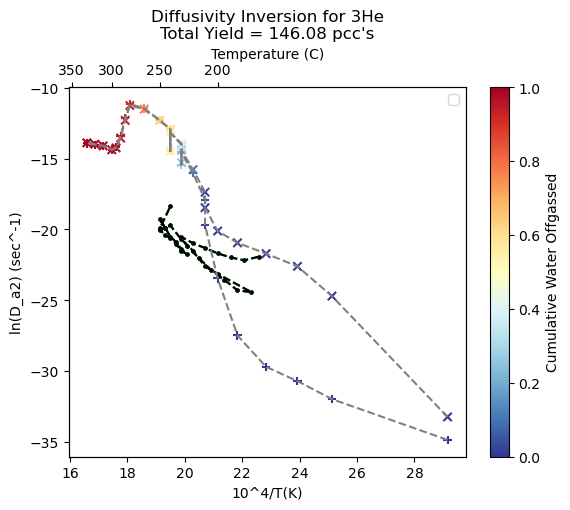

COLD 1 FELL THROUGH
COLD 45 FELL THROUGH
COLD 119 FELL THROUGH
COLD 122 FELL THROUGH
Done! Output file: IrrWin0601bTube012624TC4He_COLDS_TubeReduced.csv in C:\Users\dashf\pyrite
n1:[0.0020691176470588233, 0.05761637940365181, 0.04141819763838709, 0.027221460559370393, 0.012789143563694134, 0.026348957599073144, 0.041994100684290464, 0.02606195299177963, 0.03216114615250577, 0.02015726807887614, 0.049205787773934626, 0.11672350281343145, 0.05697937045767887, 0.017904293562916968, 0.000781448639214314, 0.774313849556702, 0.7273845652395526, 0.20226163770721597, 0.2668265639749876, 0.06511592322346745, 0.09346313844574419, 0.047587933142738514, 0.027736340804958695, 0.03219305827143478, 0.03257609636214106, 0.07182527808166604, 0.02451845300937324, 0.05773101758279085, 0.06605584933786202, 0.03600305813911052, 0.017405016041906536, 0.03472929566033656, 0.04774335769407207, 0.043493195022565934, 2.9978898400051204]
n0:[0.0, 0.041319728489893875, 0.02563968100140019, 0.017195300334962946, 0

C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\1107171875.py:190: RuntimeWarning: divide by zero encountered in scalar divide
  n1_measured.append(HenCC[i]/((1/(1-(m*TimeSeconds[i]))-1)))
C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\1107171875.py:185: RuntimeWarning: divide by zero encountered in scalar divide
  n1_n0_measured = (HenCC[i]/TimeSeconds[i])/(HenCC[i-1]/TimeSeconds[i-1]) # Assume unchanging abundance, time normalize
C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\1107171875.py:223: RuntimeWarning: divide by zero encountered in divide
  lambdas = -np.log((np.array(n1_measured)/np.array(n0_measured)))/(TempKelvin[Smeas]*Rel_times*Ratoms)
C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\1107171875.py:223: RuntimeWarning: invalid value encountered in divide
  lambdas = -np.log((np.array(n1_measured)/np.array(n0_measured)))/(TempKelvin[Smeas]*Rel_times*Ratoms)
C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\1107171875.py:229: RuntimeWarning: invalid value encountered in

PermissionError: [Errno 13] Permission denied: 'IrrWin0601bTube012624TC_4He_reduced.csv'

In [335]:
## MC Diff Cell Data Reduction

def get_real_time(ID):
    with open(f'NGL Watlow Heat Log/DC{ID} Watlow.txt') as lines:
        t = []
        T = []
        for line in lines.readlines():
            [lt,lT] = line.split('\t')
            t.append(float(lt))
            T.append(float(lT))
        #plt.scatter(t,T)
        #plt.title(ID)
        #plt.show()
        return(t[-1])

def NGLplot(ID):
    with open(f'NGL Watlow Heat Log/DC{ID} Watlow.txt') as lines:
        t = []
        T = []
        for line in lines.readlines():
            [lt,lT] = line.split('\t')
            t.append(float(lt))
            T.append(float(lT))
        plt.scatter(t,T)
        plt.title(ID)
        plt.show()
        return(t[-1])
    
data_holder_MC = {}


""" 
DIFFCELL_name = '112123LVCOPyIrrOG.csv'#DIFFCELL_name
rest_4He = 7.27*2.34 # nccSTP 4He total_yield 
rest_3He = 51.77*2.34 # pccSTP 3He total_yield
OD = 1552/1E4
ID = 828/1E4

DIFFCELL_name = '112123SalAspIrr.csv'#DIFFCELL_name
total_4He = 13.47*0.8 # nccSTP 4He total_yield 
total_3He = 51.77*0.8 # pccSTP 3He total_yield
OD = 967/1E4
ID = 533/1E4
DIFFCELL = pd.read_csv(DIFFCELL_name, header = None).to_numpy()
metadata = DIFFCELL[:,1]
TempKelvin = np.array([273+pull_number(str(datum).split(' ')[2]) for datum in metadata])
DIFFCELL = DIFFCELL[(TempKelvin>(273+70))*((TempKelvin>(370+273))+(TempKelvin<(220+273))),:]
DIFFCELL = DIFFCELL[(DIFFCELL[:,4]>0)*(DIFFCELL[:,6]>0),:]
"""

DIFFCELL_name = 'IrrWin0601bTube012624TC.csv'#DIFFCELL_name
DIFFCELL = pd.read_csv(DIFFCELL_name, header = None).to_numpy()
#total_4He = 55*1.18 # 122 nccSTP 4He total_yield 
#total_3He = 105*1.18 # pccSTP 3He total_yield

total_4He = 147.86 #nccSTP 4He total_yield 
total_3He = 146.08 # pccSTP 3He total_yield

OD = 800/1E4
ID = 510/1E4

G = 2/(np.log(OD/ID)*((ID/2)**2))

perm_model = 'modeled'
    
Ra = 1.39E-6
#sens4He = 2.29E-2 #ncc/fA
#sens3He = 5.28E-3 #pcc/cps


reducer = MCHeReducer('2024STDsMC.csv')
He3, He4 = reducer.reduce(DIFFCELL)



#CB_lim = 100 +273  # max temperature of cold blanks
#ignore_lim = 250 +273

Tcutoff = [30+273, 65+273, 130+273]

rest_He = [total_3He, total_4He]
metadata = DIFFCELL[:,1]
TimeSeconds = np.array([60*pull_number((str(datum).split(' ')[1]).split('_')[1]) for datum in metadata])
TempKelvin = np.array([273+pull_number(str(datum).split(' ')[2]) for datum in metadata])
TargetTemp = np.array([273+pull_number((str(datum).split(' ')[1]).split('_')[2]) for datum in metadata]) 
recordedTimeSeconds = np.array([get_real_time((str(datum).split(' ')[1]).split('_')[0]) for datum in metadata])
coldtimes = np.array([0] + list(extract_timesMC(DIFFCELL[:,2])))

metaFrame = pd.DataFrame()
columns = ['Temperature (C)','Nominal (Heated) Time', 'Watlow Time', 'Total Step Time']
data = [TempKelvin-273, TimeSeconds, recordedTimeSeconds, coldtimes]
for i, col in enumerate(columns):
    metaFrame[col] = data[i]
metaFrame.to_csv('IrrWinMetaDataComp.csv')



He3signal = DIFFCELL[:,4].astype('float')
He4signal = (DIFFCELL[:,6].astype('float'))
#He3 = He3signal*sens3He # pccSTP
#He4 = He4signal*sens4He # nccSTP
signals = [He3signal, He4signal]
IR = np.array((He3/(He4*1E3))/Ra)
total_yields = []

for j, He in enumerate([He3,He4]):
    total_yield = [total_3He, total_4He][j]
    name = ['3He', '4He'][j]
    HenCC = He
    HenCC[HenCC < 0] = 0 
    Names = DIFFCELL[:,0]
    
    # Information for tube corrections
    n0_modeled = [] # calc for every cold blank, cold indices apply
    n1_modeled = []
    n0_measured = [] # calc for consectutive cold blanks, indices in Smeas
    n1_measured = []
    Smeas = [] #indices of consecutive cold blanks
    colds = [] #indices of all cold blanks
    Smeascolds = []
    M = [] #measured CB proportionality (1 - n1/n0)/sec

    # Diffusivity data
    fcum = []
    Fp = 0
    DC_indices = []
    D_a2 = []
    lnD_a2 = []
    n1_n0_mod = []
    n1_n0_mes = []

    ####
    HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
    ####
    prev_cold = 0
    prev_inter = 0
    cold_counter = -1
    total_colds = 0
    Rel_times = []
    for i, datum in enumerate(metadata):
        # First, manage permeability corrections
        if TempKelvin[i] < Tcutoff[2] :
            colds.append(i)
            cold_counter += 1  
            total_colds += 1
            if TempKelvin[i] > Tcutoff[1]: # Logic to only report values where temperature control is valid. Later model room temp as cooling curve
                if perm_model == 'modeled' or perm_model == 'modelled':
                    n1_n0_modeled = tube_permeate2(t = TimeSeconds[i], T = TempKelvin[i], ID = ID, OD = OD, He = name)
                elif perm_model == 'measured':
                    n1_n0_modeled = tube_permeate3(t = TimeSeconds[i], T = TempKelvin[i], K0G=K0G, Ea=Ea) 
            elif (TempKelvin[i] < Tcutoff[0]) and prev_cold > 0:
                if perm_model == 'modeled' or perm_model == 'modelled':
                    n1_n0_modeled = tube_permeate2(t = coldtimes[i], T = TempKelvin[i], ID = ID, OD = OD, He = name) 
                elif perm_model == 'measured':
                    n1_n0_modeled = tube_permeate3(t = coldtimes[i], T = TempKelvin[i], K0G=K0G, Ea=Ea) 
            else: 
                n1_n0_modeled = 0
                print(f'COLD {i} FELL THROUGH')
            n1_n0_mod.append(n1_n0_modeled)
            if n1_n0_modeled:
                n0_modeled.append(HenCC[i]/(1-n1_n0_modeled))
                n1_modeled.append(HenCC[i]/((1/n1_n0_modeled)-1))
            else:
                n0_modeled.append(0)
                n1_modeled.append(0)
            if ((prev_cold >= 2) and (TempKelvin[i] < Tcutoff[0])):# and (HenCC[i] > 0.0175)):
                Smeascolds.append(cold_counter)
                #Smeas.append(i-1)
                Smeas.append(i)
                Rel_times.append(coldtimes[i])
                n1_n0_measured = (HenCC[i]/coldtimes[i])/(HenCC[i-1]/coldtimes[i-1]) # Assume unchanging abundance, time normalize
                m = (1 - n1_n0_measured)/np.mean([coldtimes[i], coldtimes[i-1]]) # Assume n1/n0 linear: no significant degassing
                #n0_measured.append(HenCC[i-1]/(m*coldtimes[i-1]))
                #n1_measured.append(HenCC[i-1]/((1/(1-(m*coldtimes[i-1]))-1)))
                n0_measured.append(HenCC[i]/(m*coldtimes[i]))
                n1_measured.append(HenCC[i]/((1/(1-(m*coldtimes[i]))-1)))
                n1_n0_mes.append(n1_n0_measured)
                M.append(m)
                #M.append(m)
            elif ((prev_inter >= 1) and ((TempKelvin[i] > Tcutoff[1]) and (np.abs(TempKelvin[i] - TempKelvin[i-1]) < 2))):# and (HenCC[i] > 0.01)):
                Smeascolds.append(cold_counter)
                Rel_times.append(TimeSeconds[i])
                #Smeas.append(i-1)
                Smeas.append(i)
                n1_n0_measured = (HenCC[i]/TimeSeconds[i])/(HenCC[i-1]/TimeSeconds[i-1]) # Assume unchanging abundance, time normalize
                m = (1 - n1_n0_measured)/np.mean([TimeSeconds[i], TimeSeconds[i-1]]) # Assume n1/n0 linear: no significant degassing
                #n0_measured.append(HenCC[i-1]/(m*coldtimes[i-1]))
                #n1_measured.append(HenCC[i-1]/((1/(1-(m*coldtimes[i-1]))-1)))
                n0_measured.append(HenCC[i]/(m*TimeSeconds[i]))
                n1_measured.append(HenCC[i]/((1/(1-(m*TimeSeconds[i]))-1)))
                n1_n0_mes.append(n1_n0_measured)
                M.append(m)

            if (TempKelvin[i] < (Tcutoff[0]+40)):
                prev_cold += 1
                prev_inter = 0
            else:
                prev_inter += 1
                prev_cold = 0

            Names[i] = str(total_colds)+' in sequence ' + metadata[i]
        else:
            prev_cold = 0
            prev_inter = 0
            total_colds = 0

    n1_measured = np.array(n1_measured)
    n0_measured = np.array(n0_measured)
    n1_modeled = np.array(n1_modeled)
    n0_modeled = np.array(n0_modeled)

    n1_measured_out = np.zeros_like(n1_modeled)
    n1_measured_out[Smeascolds] = n1_measured
    n0_measured_out = np.zeros_like(n0_modeled)
    n0_measured_out[Smeascolds] = n0_measured
    n1_n0_mes_out = np.zeros_like(n0_modeled)
    n1_n0_mes_out[Smeascolds] = n1_n0_mes

    #molHe = HenCC/(22.4*1E12) #convert from nccSTP to moles
    #PHeATM = ((molHe*RccATM*TempKelvin)/V)
    #PHe = (PHeATM/1.01325)*1E6 # Conv. Atmospheres to microbars

    lambdas = -np.log((np.array(n1_measured)/np.array(n0_measured)))/(TempKelvin[Smeas]*Rel_times*Ratoms)
    K_meas = (lambdas*np.log(OD/ID)*((ID/2)**2))/2
    K_ref = []

    for Temp in TempKelvin[Smeas]:
        K_ref.append(swets_K(Temp))
    DK_swets = np.log(K_meas)-np.log(np.array(K_ref))
    lnlambdas = np.log(lambdas)
    lambdas_out = np.zeros_like(n0_modeled)
    lnlambdas_out = np.zeros_like(n0_modeled)
    lambdas_out[Smeascolds] = lambdas
    lnlambdas_out[Smeascolds] = lnlambdas
    K_meas_out = np.zeros_like(n0_modeled)
    DK_swets_out = np.zeros_like(n0_modeled)
    K_meas_out[Smeascolds] = np.array(K_meas)
    DK_swets_out[Smeascolds] = DK_swets

    """
    plt.scatter(HenCC[Smeas]/coldtimes[Smeas], M, c = PHe[Smeas])
    for H, hen in enumerate(HenCC[Smeas]/coldtimes[Smeas]):
        plt.text(hen, M[H], Smeas[H])
    plt.ylabel('M (1-(n1/n0))/sec')
    plt.xlabel('Permeation rate (nccSTP/sec)')
    cbar = plt.colorbar()
    cbar.set_label('Pressure (Microbars)')
    plt.ylim((0,max(M)))
    plt.show()

    plt.scatter(1E4/TempKelvin[Smeas], np.log(lambdas), c = HenCC[Smeas])
    plt.ylabel('ln(Lambda) ((K*A)/(V*d)) (atoms /sec /atm /cm^3)')
    plt.xlabel('10^4/T (K)')
    plt.title('Simultaneous measurements of K and geometric factor')
    cbar = plt.colorbar()
    cbar.set_label('4He Yield (nccSTP)')
    plt.show()

    #plt.scatter(Smeas, M, c = PHe[Smeas], label = 'Consecutive Cold Blank Measured M')
    plt.scatter(Smeas, (1-(np.array(n1_measured)/np.array(n0_measured)))/coldtimes[Smeas], c = PHe[Smeas], label = 'Consecutive Cold Blank Measured M')
    plt.plot(colds, (1-(np.array(n1_modeled)/np.array(n0_modeled)))/coldtimes[colds], color = 'k', label = 'Permeability Modelled M')
    plt.ylabel('M (1-(n1/n0))/sec')
    plt.xlabel('Analysis Number')
    plt.ylim((0,max((1-(np.array(n1_measured)/np.array(n0_measured)))/coldtimes[Smeas])))
    plt.legend()
    cbar = plt.colorbar()
    cbar.set_label('Pressure (Microbars)')
    plt.show()

    plt.scatter((n1_measured/n0_measured)-(n1_modeled/n0_modeled)[Smeascolds], (n0_measured-n1_measured)-HenCC[Smeas], c = PHe[Smeas], label = 'Consecutive Cold Blank Measured M')
    #plt.scatter(colds, (n0_modeled-n1_modeled)-HenCC[colds], color = 'k', label = 'Permeability Modelled M', marker = '+')
    plt.ylabel('Residuals: m-(n0-n1)')
    plt.xlabel('n1/n0 measured - n1/n0 modelled')
    cbar = plt.colorbar()
    cbar.set_label('Pressure (Microbars)')
    plt.show()

    plt.scatter(colds, (n0_modeled-n1_modeled)-HenCC[colds], c = PHe[colds], label = 'Permeability Modelled M', marker = '+')
    plt.scatter(Smeas, (n0_measured-n1_measured)-HenCC[Smeas], c = PHe[Smeas], label = 'Permeability Modelled M', marker = 'o')
    plt.ylabel('Residuals: m-(n0-n1)')
    plt.xlabel('Analysis Number')
    plt.legend()
    cbar = plt.colorbar()
    cbar.set_label('Pressure (Microbars)')
    plt.show()
    """


    """    plt.scatter(1E4/TempKelvin[Smeas], DK_swets, c = HenCC[Smeas])
    plt.ylabel('Delta K (wrt Swets et al.)')
    plt.xlabel('10^4/T (K)')
    plt.title('Delta K plot')
    cbar = plt.colorbar()
    cbar.set_label('4He Yield (nccSTP)')
    plt.show()

    plt.plot(1E4/TempKelvin[Smeas], np.log(np.array(K_ref)*(2/(np.log(OD/ID)*((ID/2)**2)))), label = 'Swets et al K and Measured Geometry')
    plt.plot(1E4/TempKelvin[Smeas], np.log(K0G*np.exp(-Ea/(Rcal*TempKelvin[Smeas]))), linestyle = '--', label = 'Used Values')
    plt.scatter(1E4/TempKelvin[Smeas], lnlambdas, c = HenCC[Smeas], label = 'Measured K(G)')
    plt.ylabel('Lambda')
    plt.xlabel('10^4/T (K)')
    plt.title('Lambda plot')
    plt.legend()
    cbar = plt.colorbar()
    cbar.set_label('4He Yield (nccSTP)')
    plt.savefig(DIFFCELL_name[:-4] + 'LambdaPlot' + '.jpg', dpi = 256)
    plt.show()"""

    data = [np.array(Names)[colds].tolist(), (TempKelvin[colds]-273).tolist(), (TimeSeconds[colds]).tolist(), coldtimes[colds], recordedTimeSeconds[colds], lambdas_out, n1_n0_mod, n1_n0_mes_out, n0_modeled, n0_measured_out, n1_modeled, n1_measured_out, HenCC[colds], K_meas_out, DK_swets_out, 1E4/TempKelvin[colds], lnlambdas_out]
    columns = ['Names', 'Temp (C)', ' Nominal/Hot Time (sec)', 'Total/Cold Time (sec)', 'Watlow Times (sec)', 'lambda', 'n1/n0 modeled', 'n1/n0 measured', 'n0_modeled', 'n0_measured', 'n1_modeled', 'n1_measured', 'He Measured (nCC@STP)', 'K measured (atoms/atm/cm/sec)', 'Delta K (ln(K_swets)-ln(K_meas))', '10^4/T (K)', 'ln(lambda)']
    Reduced_Data = pd.DataFrame()
    for k, column in enumerate(columns):
        Reduced_Data[column] = data[k]
    newDiffName = DIFFCELL_name[:-4] + name + '_COLDS_TubeReduced' + '.csv'
    Reduced_Data.to_csv(newDiffName)
    print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

    HTind = []
    prev_cold = 0
    n0 = [] # Values For correction
    n1 = []
    prev_hot = 1

    for i, measured in reversed(list(enumerate(HenCC))): # Traverse steps in reverse, second/last cold step always proper temp.
    #for i, measured in enumerate(HenCC):
        # First, manage permeability correction
        if TempKelvin[i] < Tcutoff[2]:
            prev_hot = 0
            if prev_cold == 0:
                #print(n0_modeled[np.array(colds) == i])
                n1.append(n0_modeled[np.array(colds) == i][0]) # Collect tube contents after previous HT step
                n0.append(n1_modeled[np.array(colds) == i][0]) # Collect tube contents preceding next HT step
            else:
                n1[-1] += measured # Account for permeate lost during cold steps
            prev_cold += 1
        else:
            prev_cold = 0
            if prev_hot:
                n0.append(-1) # Make placeholders for high temperature corrections
                n1.append(-1)
            prev_hot +=1
            HTind.append(i)
    if prev_hot:
        n0.append(0) # if no tube measurement before run, assume empty tube
        n1.append(0)
        print('No initial cold permeation, assuming n0=0')
    HTind.reverse()
    n0.reverse()
    n1.reverse()
    print(f"n1:{n1}")
    print(f"n0:{n0}")
    HTind = np.array(HTind)
    n0 = np.array(n0)[:-1]
    n1 = np.array(n1)[1:]
    print(len(n1))
    print(len(HenCC))
    
    corrtype = ['Cold Correction'] * len(HTind)
    
    for k, ind in enumerate(HTind): #High Temperature corrections when low T measurements weren't made
        if n1[k] < 0 or name == '4He':
            corrtype[k] = 'Hot Correction'
            measured = HenCC[ind]
            temp = TempKelvin[ind]
            time = TimeSeconds[ind]
            Beta = time*temp*Ratoms*G*swets_K(temp)
            if name == '3He':
                Beta *= Jones(temp)
            hotCorr = ((((measured-n0[k])/Beta)*(1-np.exp(-Beta))) + (n0[k]*np.exp(-Beta))) / (1 - ((1/Beta)*(1-np.exp(-Beta))))
            n1[k] = hotCorr
            if k < (len(HTind)-1):
                n0[k+1] = hotCorr

            


    """
                denom = TimeSeconds[j]*temp*Ratoms*G*swets_K(temp)
                if name == '3He':
                    #print(Jones(temp))
                    denom *= Jones(temp)
                if len(n1) == 0:
                    n1.append((He[j]/denom)/(1-(1/denom)))
                else:
                    n1.append(((He[j]-n1[-1])/denom)/(1-(1/denom)))
    

    for j, temp in enumerate(TempKelvin):
        if temp >= Tcutoff[2]:
            denom = TimeSeconds[j]*temp*Ratoms*G*swets_K(temp)
            print(f"for step {j} for {TimeSeconds[j]/3600} hours at {temp-273}C we have a yield of {HenCC[j]}nCC and get a denominator {denom}")
            print(f'previous n1: {n1HT[-1]}')
            n1HT.append(((HenCC[j]-n1HT[-1])/denom)/(1-(1/denom)))   
            print(f"We calculate an n1 of {n1HT[-1]} with a cold bracket calculation of {n1[counter]}\n")
    """
    HT_corr = np.array(HenCC)[HTind] + n1 - n0 # Correct high temperature steps for gas inside tube before and after high temperature steps
    HT_corr[HT_corr < 0] = 0 
    
    #total_yield = np.sum(He)+rest_He[i]
    total_yields.append(total_yield)
    
    for j, step_yield in enumerate(HT_corr):
        F = Fp + (step_yield/total_yield)
        frequency_factor = InvertFrequencyFactor(t = TimeSeconds[HTind][j], F = F, Fp = Fp)
        D_a2.append(frequency_factor)
        lnD_a2.append(np.log(frequency_factor))
        #blank_corrected_yield.append(step_yield)
        #DC_indices.append(j)
        fcum.append(F)
        Fp = F

    #DC_indices = np.array(DC_indices)
    #data = [np.array(Names)[DC_indices].tolist(), (TempKelvin[DC_indices]-273).tolist(), (TimeSeconds[DC_indices]*60).tolist(), blank_corrected_yield, fcum, D_a2, lnD_a2, (10000/TempKelvin[DC_indices]).tolist()]
    data = [DIFFCELL[HTind,1], (TempKelvin[HTind]-273).tolist(), (TimeSeconds[HTind]/60).tolist(), (recordedTimeSeconds[HTind]/60).tolist(), He[HTind], HT_corr, fcum, D_a2, (10000/TempKelvin[HTind]).tolist(), lnD_a2, n0, n1, corrtype]
    columns = ['Names','Temp (C)', 'Time (min)', 'Recorded Time (min)',  f"{name} measured ({['p','n'][i]}CC@STP)", f"Corrected {name} Yield ({['p','n'][i]}CC@STP)", 'Fcum', 'D/a^2 ', '10^4/T', 'ln(D/a^2)', 'n0', 'n1', 'n1 Correction Type']
    Reduced_Data = pd.DataFrame()
    for j, column in enumerate(columns):
        Reduced_Data[column] = data[j]
    newDiffName = DIFFCELL_name[:-4] + '_' + name +'_reduced' + '.csv'
    data_holder_MC[name] = Reduced_Data
    Reduced_Data.to_csv(newDiffName)
    print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

    min_T = np.min(10000/TempKelvin[HTind])
    max_T = np.max(10000/TempKelvin[HTind])
    fig = plt.figure()
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twiny()
    ax1.plot(data_holder_MC['3He']['10^4/T'], data_holder_MC['3He']['ln(D/a^2)'], linestyle = '--', color = 'green')
    ax1.scatter(data_holder_MC['3He']['10^4/T'], data_holder_MC['3He']['ln(D/a^2)'], s = 5, color = 'green', label = '3He')
    Ctemps = np.linspace(200,700, 11,dtype = int)
    ax1.plot(10000/TempKelvin[HTind], np.array(lnD_a2), linestyle='--', color = 'black')
    ax1.scatter(10000/TempKelvin[HTind], np.array(lnD_a2), s = 5, color = 'black', label = '4He')#, c = np.log10(IR[real_steps][good_steps]), label = 'Data')
    plt.title(f"Diffusivity Inversion for {name}\nTotal Yield = {total_yield} {['p','n'][i]}cc's")

    #reference_D0_a2 = [(10**0.9)/((212/10000)**2), (10**2.1)/((180/10000)**2), np.exp(1.1939)] # /sec
    #reference_Ea = [33000, 33000, 14701*1.987] # cal /mol
    #for j, no in enumerate(['3','4']): # Plot Win-G from HDM and KAF
    #ax1.plot(Winsor_Data[f'He{no}HDM']['10^4/T'][:-1], Winsor_Data[f'He{no}HDM']['ln(D/a^2)'][:-1], linestyle='--', linewidth = 1, marker=['x','+'][j], color='g', label = f'HDM {no}He Data')
    for j, no in enumerate(['3','4']):
        ax1.plot(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], linestyle='--', color = 'grey')
        ax1.scatter(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], marker=['x','+'][j], c=Diffdat1['watercum'][:-1]/max(Diffdat1['watercum']), cmap = 'RdYlBu_r', label = f'KAF {no}He Data')

    cbar = plt.colorbar(mappable = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap='RdYlBu_r'))
    cbar.set_label('Cumulative Water Offgassed')
    """
    reference_names = ['200 um LVCO Pyrite', 'Apatite r=250 um','Tc = 93.6 C','Tc = 104.8 C','Tc = 134.6 C','Tc = 146.7 C', 'Tc = 112.8']
    R = 1.98 #cal /mol /T(K)
    reference_D0_a2 = [np.exp(4.2623), (10**1.5)/((250/10000)**2)]#,1.84,0.03,3.81,6.96] # /sec
    reference_Ea = [(R*2.2015*10000), 33000]#,26030,23845,29607,30997] # cal /mol

    if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
        T = [min_T, max_T]
        for j, D0_a2 in enumerate(reference_D0_a2):
            Ea = reference_Ea[j]
            min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
            max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
            plt.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[j])
            #print(T, min_log_frequency_factor, max_log_frequency_factor)
    """

    ax2.set_xticks(1E4/(Ctemps+273))
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticklabels(Ctemps)
    ax2.set_xlabel('Temperature (C)')
    ax1.set_xlabel('10^4/T(K)')
    ax1.set_ylabel('ln(D_a2) (sec^-1)')
    plt.legend()#fontsize = 10)
    plt.savefig(newDiffName+'.jpg', dpi = 256)
    plt.show()
    """
        fcum = np.array(fcum)
    
    reference_Diff = np.log(reference_D0_a2[0]*np.exp(-reference_Ea[0]/((realTempKelvin)*R)))
    plt.axhline(0, color = 'k')
    delta_Diff = np.array(lnD_a2)[good_steps] - reference_Diff[good_steps]
    plt.plot(fcum[good_steps], delta_Diff)
    plt.scatter(fcum[good_steps], delta_Diff, c = np.log10(IR[real_steps][good_steps]))
    cbar = plt.colorbar()
    cbar.set_label('3/4He (Ra)')
    plt.show()
    """

"""
min_T = np.min(10000/TempKelvin[HTind])
max_T = np.max(10000/TempKelvin[HTind])
fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()



#reference_D0_a2 = [(10**0.9)/((212/10000)**2), (10**2.1)/((180/10000)**2), np.exp(1.1939)] # /sec
#reference_Ea = [33000, 33000, 14701*1.987] # cal /mol
#for j, no in enumerate(['3','4']): # Plot Win-G from HDM and KAF
#ax1.plot(Winsor_Data[f'He{no}HDM']['10^4/T'][:-1], Winsor_Data[f'He{no}HDM']['ln(D/a^2)'][:-1], linestyle='--', linewidth = 1, marker=['x','+'][j], color='g', label = f'HDM {no}He Data')
for j, no in enumerate(['3','4']):
    ax1.plot(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], linestyle='--', color = 'grey')
    ax1.scatter(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], marker=['x','+'][j], c=Diffdat['watercum'][:-1]/max(Diffdat['watercum']), cmap = 'RdYlBu_r', label = f'KAF {no}He Data')

cbar = plt.colorbar(mappable = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap='RdYlBu_r'))
cbar.set_label('Cumulative Water Offgassed')

Ctemps = np.linspace(200,700, 11,dtype = int)
ax1.plot(data_)
ax1.plot(10000/TempKelvin[HTind], np.array(lnD_a2), linestyle='--')
ax1.scatter(10000/TempKelvin[HTind], np.array(lnD_a2))#, c = np.log10(IR[real_steps][good_steps]), label = 'Data')
plt.title(f"Diffusivity Inversion for {name}\nTotal Yield = {total_yield} {['p','n'][i]}cc's")
"""
reference_names = ['200 um LVCO Pyrite', 'Apatite r=250 um','Tc = 93.6 C','Tc = 104.8 C','Tc = 134.6 C','Tc = 146.7 C', 'Tc = 112.8']
R = 1.98 #cal /mol /T(K)
reference_D0_a2 = [np.exp(4.2623), (10**1.5)/((250/10000)**2)]#,1.84,0.03,3.81,6.96] # /sec
reference_Ea = [(R*2.2015*10000), 33000]#,26030,23845,29607,30997] # cal /mol

if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
    T = [min_T, max_T]
    for j, D0_a2 in enumerate(reference_D0_a2):
        Ea = reference_Ea[j]
        min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
        max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
        plt.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[j])
        #print(T, min_log_frequency_factor, max_log_frequency_factor)
"""

ax2.set_xticks(1E4/(Ctemps+273))
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (C)')
ax1.set_xlabel('10^4/T(K)')
ax1.set_ylabel('ln(D_a2) (sec^-1)')
plt.legend(fontsize = 10)
plt.savefig(newDiffName+'.svg')
plt.show()


"""


In [165]:
print((Winsor_Data['He4HDM']['He Yield (nCC@STP)']/Winsor_Data['He3HDM']['He Yield (nCC@STP)'])/(cum4HM[-1]/cum3HM[-1]))
(Winsor_Data['He4KAF']['He Yield (nCC@STP)']/Winsor_Data['He3KAF']['He Yield (nCC@STP)'])/(cum4KF[-1]/cum3KF[-1])

0     0.110132
1     0.025418
2     0.033748
3     0.022325
4     0.021232
5     0.028604
6     0.141955
7     0.839359
8     0.973404
9     0.985099
10    0.940036
11    1.016825
12    0.998310
13    1.005323
14    0.970395
15    0.990919
16    1.049996
17    1.012147
18    0.997422
19    1.045173
20    1.051227
21    1.069508
22    1.081781
23    1.079537
24    1.072972
25    1.083330
26    0.913631
27    0.904190
28    0.909240
29    0.906240
30    0.891141
31    0.918102
32    0.923452
33    0.922918
34    0.947494
35    0.939966
36    0.944673
37    0.934473
38    0.937586
39    0.946440
40    0.950586
41    0.943979
42    0.873522
Name: He Yield (nCC@STP), dtype: float64


0     0.444170
1     0.021134
2     0.014598
3     0.018183
4     0.054400
5     0.352725
6     0.800397
7     0.949056
8     0.977293
9     0.983877
10    0.961824
11    1.003460
12    1.002329
13    1.014141
14    1.016902
15    1.023692
16    1.034483
17    1.029520
18    1.045163
19    1.047606
20    1.059518
21    1.081978
22    1.104784
23    1.057727
24    0.927618
25    0.899988
26    0.897088
27    0.897205
28    0.893098
29    0.905395
Name: He Yield (nCC@STP), dtype: float64

C:\Users\dashf\AppData\Local\Temp\ipykernel_62920\110037600.py:681: RuntimeWarning: divide by zero encountered in log
  lnD_a2.append(np.log(frequency_factor))


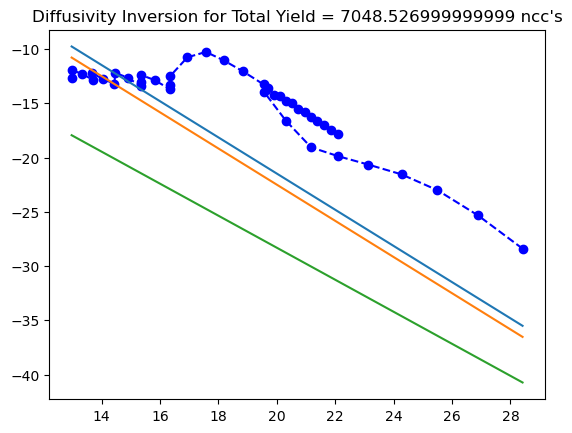

C:\Users\dashf\AppData\Local\Temp\ipykernel_62920\110037600.py:681: RuntimeWarning: divide by zero encountered in log
  lnD_a2.append(np.log(frequency_factor))


Done! Output file: He3_HDMwinsor_diffusion.csv in C:\Users\dashf\pyrite


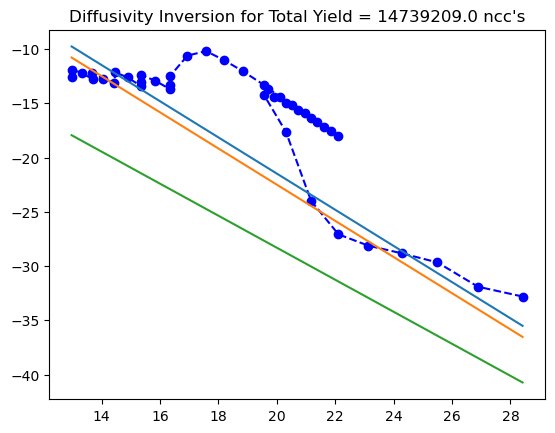

Done! Output file: He4_HDMwinsor_diffusion.csv in C:\Users\dashf\pyrite


C:\Users\dashf\AppData\Local\Temp\ipykernel_62920\110037600.py:681: RuntimeWarning: divide by zero encountered in log
  lnD_a2.append(np.log(frequency_factor))


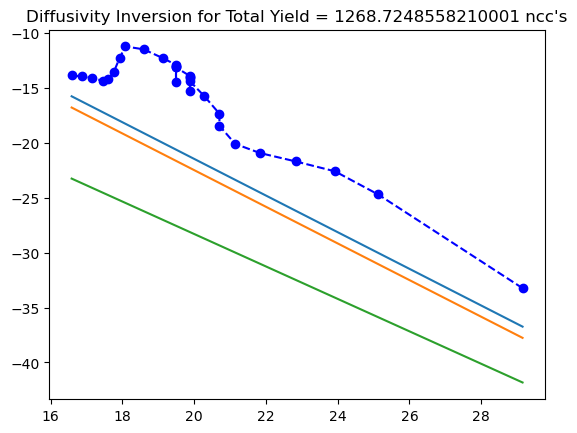

Done! Output file: He3_KAFwinsor_diffusion.csv in C:\Users\dashf\pyrite


C:\Users\dashf\AppData\Local\Temp\ipykernel_62920\110037600.py:341: RuntimeWarning: divide by zero encountered in scalar divide
  D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )


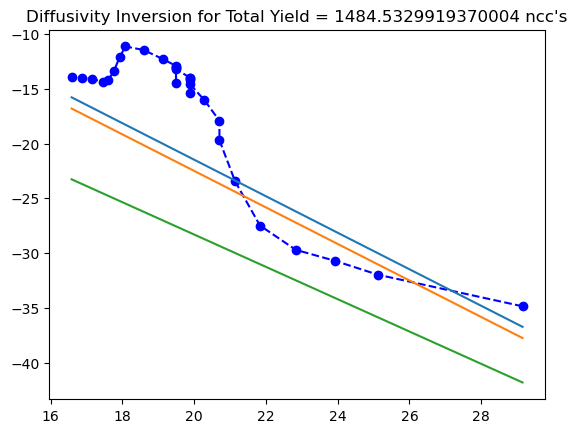

Done! Output file: He4_KAFwinsor_diffusion.csv in C:\Users\dashf\pyrite


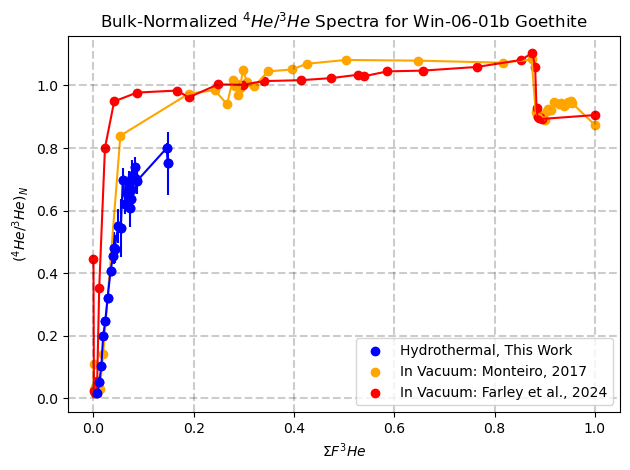

In [557]:


DiffdatBJT = {}

DiffdatBJT['3'] = pd.read_csv('diffusivitiesHTWin0601b3He.csv')
DiffdatBJT['4'] = pd.read_csv('diffusivitiesHTWin0601b4He.csv')

Diffdat = pd.read_csv('HM_Win_06_01B.csv')
#print(Diffdat['Time (h)'])
TempKelvin = np.array(Diffdat['Temp (C)']) + 273
TimeSeconds = np.array(Diffdat['Time (h)']) * 3600

Winsor_Data = {}

for i, name in enumerate(['3HeCPS','4HeCPS']):
    newDiffName = f'He{["3","4"][i]}_HDMwinsor_diffusion.csv'
    HeVec = np.array(Diffdat[name]).astype('float') #Helium (or other diffusant) in arbitrary units, put ready values here. no blanks/stds handled etc
    Winsor_Data[f'He{["3","4"][i]}HDM'] = diffusion_reduction(HeVec, TimeSeconds=TimeSeconds, TempKelvin=TempKelvin, newDiffName=newDiffName)

Diffdat1 = pd.read_csv('Winsor_waterKAF_BJT.csv', skiprows=1)[:30]
    
TempKelvin = np.array(Diffdat1['Temp (C)']) + 273
TimeSeconds = np.array(Diffdat1['Time (h)']) * 3600

for i, name in enumerate(['3He PCC','4He NCC']):
    newDiffName = f'He{["3","4"][i]}_KAFwinsor_diffusion.csv'
    HeVec = np.array(Diffdat1[name]).astype('float') #Helium (or other diffusant) in arbitrary units, put ready values here. no blanks/stds handled etc
    Winsor_Data[f'He{["3","4"][i]}KAF'] = diffusion_reduction(HeVec, TimeSeconds=TimeSeconds, TempKelvin=TempKelvin, newDiffName=newDiffName)


    
    #3GH 4IJ 146.148	1.083	145.815	1.123

AG5 = DiffdatBJT['3'].to_numpy()[:,3]
AH5 = DiffdatBJT['3'].to_numpy()[:,4]
AI5 = DiffdatBJT['4'].to_numpy()[:,3]
AJ5 = DiffdatBJT['4'].to_numpy()[:,4]
R = 1000*AI5/AG5
Rbulk = R / (1000*145.8/146.1)
Rerr = 2*((AH5*1000*AI5/(2*AG5**2))**2+(1000*AJ5/(AG5*2))**2)**0.5 
Rbulkerr = Rerr / (1000*145.8/146.1)

lowerr = (Rbulkerr < 0.15) * (Rbulk > 0)

fig, ax = plt.subplots()

plt.errorbar(accumulate(AG5)[lowerr]/146.1, Rbulk[lowerr], yerr = Rbulkerr[lowerr], marker = 'o', color = 'Blue')
plt.scatter(accumulate(AG5)[lowerr]/146.1, Rbulk[lowerr], color = 'Blue', label = 'Hydrothermal, This Work')
cum3HM = accumulate(Winsor_Data['He3HDM']['He Yield (nCC@STP)'])
cum4HM = accumulate(Winsor_Data['He4HDM']['He Yield (nCC@STP)'])

plt.plot(cum3HM/cum3HM[-1], (Winsor_Data['He4HDM']['He Yield (nCC@STP)']/Winsor_Data['He3HDM']['He Yield (nCC@STP)'])/(cum4HM[-1]/cum3HM[-1]), color = 'Orange')
plt.scatter(cum3HM/cum3HM[-1], (Winsor_Data['He4HDM']['He Yield (nCC@STP)']/Winsor_Data['He3HDM']['He Yield (nCC@STP)'])/(cum4HM[-1]/cum3HM[-1]), color = 'Orange', label = 'In Vacuum: Monteiro, 2017')
#plt.ylim((0,1.5))

cum3KF = accumulate(Winsor_Data['He3KAF']['He Yield (nCC@STP)'])
cum4KF = accumulate(Winsor_Data['He4KAF']['He Yield (nCC@STP)'])
plt.plot(cum3KF/cum3KF[-1], (Winsor_Data['He4KAF']['He Yield (nCC@STP)']/Winsor_Data['He3KAF']['He Yield (nCC@STP)'])/(cum4KF[-1]/cum3KF[-1]), color = 'Red')#c = Diffdat1['watercum']/max(Diffdat1['watercum']))
plt.scatter(cum3KF/cum3KF[-1], (Winsor_Data['He4KAF']['He Yield (nCC@STP)']/Winsor_Data['He3KAF']['He Yield (nCC@STP)'])/(cum4KF[-1]/cum3KF[-1]), color = 'Red', label = 'In Vacuum: Farley et al., 2024')
make_grid()
plt.title(r'Bulk-Normalized $^4He/^3He$ Spectra for Win-06-01b Goethite')
plt.xlabel(r'$\Sigma F^3He$')
plt.ylabel(r'$\left(^4He/^3He\right)_N$')
plt.legend()
plt.tight_layout()
plt.savefig('Comparative_Ratios_Dtplot_WinsorGT.jpg', dpi = 256)

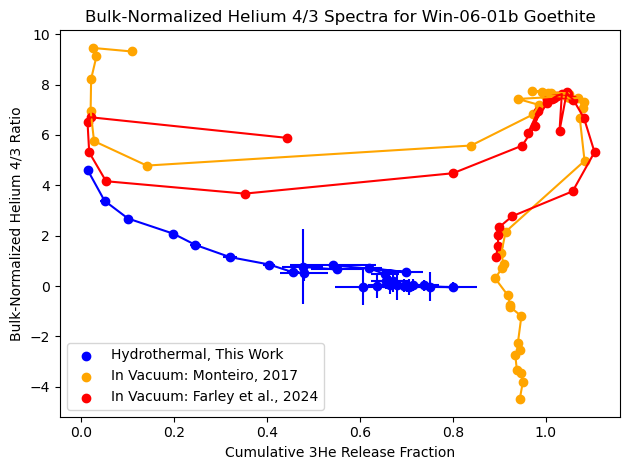

In [547]:
Deltas = {}

for i, l in enumerate(['KAF','HDM']):
    for j, n in enumerate(['3']):
        refs = np.log(D_a2reg(Winsor_Data[f"He3{l}"]['Temp (C)']+273))
        Deltas[l]= Winsor_Data[f"He{n}{l}"]['ln(D/a^2)'] - refs
        #plt.scatter(Winsor_Data[f"He3{l}"]['Fcum'], Deltas, color = ['orange', 'red'][i], marker = ['x','s'][j], alpha = 0.5)
        #plt.plot(Winsor_Data[f"He3{l}"]['Fcum'], Deltas, color = ['red','orange'][i], linestyle = '--', marker = ['s','o'][j],  alpha = 0.5, label = f"Vacuum He{n}: {['Farley et al., 2024','Monteiro, 2017'][i]}")
for j, n in enumerate(['3']):
    refs = np.log(D_a2reg(DiffdatBJT[n]['Temp ©']+273))
    Deltas['BJT']=DiffdatBJT[n]['ln(d/a^2)'] - refs
    #plt.errorbar(DiffdatBJT['3']['Fi+1'], Deltas, yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],  marker = ['s','o'][j], color = 'blue', markeredgecolor = ['pink','green'][j], ecolor = ['pink','green'][j], linestyle = '--', label = f'Hydrothermal He{n}: This Study', capsize = 5, alpha = [0.8,0.7][j])# ecolor = ['green','grey'][j], yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],
    #plt.plot(DiffdatBJT['3']['Fi+1'], Deltas,  marker = ['o','s'][j], color = 'blue', markeredgecolor = ['green','pink'][j], linestyle = '--', label = f'Hydrothermal He{n}: This Study', alpha = 0.5)# ecolor = ['green','grey'][j], yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],
    #plt.scatter(DiffdatBJT[n]['Fi+1'], Deltas, label = f"He{n}{l}")
    #plt.plot(Winsor_Data[f"He3{l}"]['Fcum'], Deltas)
    
    #3GH 4IJ 146.148	1.083	145.815	1.123

AG5 = DiffdatBJT['3'].to_numpy()[:,3]
AH5 = DiffdatBJT['3'].to_numpy()[:,4]
AI5 = DiffdatBJT['4'].to_numpy()[:,3]
AJ5 = DiffdatBJT['4'].to_numpy()[:,4]
R = 1000*AI5/AG5
Rbulk = R / (1000*145.8/146.1)
Rerr = 2*((AH5*1000*AI5/(2*AG5**2))**2+(1000*AJ5/(AG5*2))**2)**0.5 
Rbulkerr = Rerr / (1000*145.8/146.1)

lowerr = (Rbulkerr < 0.15) * (Rbulk > 0)

#fig, ax = plt.subplots()

plt.errorbar(Rbulk[lowerr], Deltas['BJT'][lowerr], xerr = Rbulkerr[lowerr], yerr = DiffdatBJT['3']["2 sigma.6"][lowerr] , color = 'Blue')
plt.scatter(Rbulk[lowerr], Deltas['BJT'][lowerr], color = 'Blue', label = 'Hydrothermal, This Work')
cum3HM = accumulate(Winsor_Data['He3HDM']['He Yield (nCC@STP)'])
cum4HM = accumulate(Winsor_Data['He4HDM']['He Yield (nCC@STP)'])

plt.plot((Winsor_Data['He4HDM']['He Yield (nCC@STP)']/Winsor_Data['He3HDM']['He Yield (nCC@STP)'])/(cum4HM[-1]/cum3HM[-1]), Deltas['HDM'], color = 'Orange')
plt.scatter((Winsor_Data['He4HDM']['He Yield (nCC@STP)']/Winsor_Data['He3HDM']['He Yield (nCC@STP)'])/(cum4HM[-1]/cum3HM[-1]), Deltas['HDM'], color = 'Orange', label = 'In Vacuum: Monteiro, 2017')
#plt.ylim((0,1.5))

cum3KF = accumulate(Winsor_Data['He3KAF']['He Yield (nCC@STP)'])
cum4KF = accumulate(Winsor_Data['He4KAF']['He Yield (nCC@STP)'])
plt.plot((Winsor_Data['He4KAF']['He Yield (nCC@STP)']/Winsor_Data['He3KAF']['He Yield (nCC@STP)'])/(cum4KF[-1]/cum3KF[-1]), Deltas['KAF'],  color = 'Red')#c = Diffdat1['watercum']/max(Diffdat1['watercum']))
plt.scatter((Winsor_Data['He4KAF']['He Yield (nCC@STP)']/Winsor_Data['He3KAF']['He Yield (nCC@STP)'])/(cum4KF[-1]/cum3KF[-1]),Deltas['KAF'], color = 'Red', label = 'In Vacuum: Farley et al., 2024')
#make_grid()
plt.title('Bulk-Normalized Helium 4/3 Spectra for Win-06-01b Goethite')
plt.xlabel('Cumulative 3He Release Fraction')
plt.ylabel('Bulk-Normalized Helium 4/3 Ratio')
plt.legend()
plt.tight_layout()
#plt.savefig('Ratios_Delta_WinsorGT.jpg', dpi = 256)

In [560]:
sum(lowerr)

28

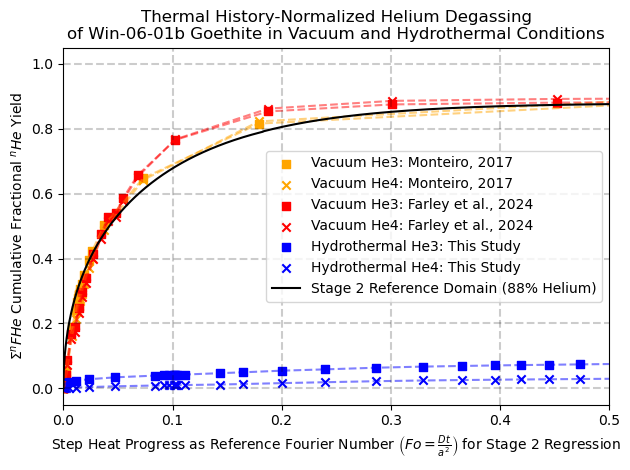

In [542]:
def D_a2reg(T):
    Ea = 38033.18815
    D0_a2 = 17623836.64
    return D0_a2*(np.exp(-Ea/(1.987*T)))
def D_a2Decomp(T):
    Ea = 35600
    D0_a2 = 2780000000
    return D0_a2*(np.exp(-Ea/(1.987*T)))

fig, ax = plt.subplots()
for i, l in enumerate(['HDM','KAF']):
    for j, n in enumerate(['3','4']):
        step_power = D_a2Decomp(Winsor_Data[f"He{n}{l}"]['Temp (C)']+273)*(Winsor_Data[f"He{n}{l}"]['Time (min)']*60)
        plt.scatter(accumulate(step_power), Winsor_Data[f"He{n}{l}"]['Fcum'], label = f"Vacuum He{n}: {['Monteiro, 2017','Farley et al., 2024'][i]}", marker = ['s','x'][j], color = ['orange','red'][i])    
        plt.plot(accumulate(step_power), Winsor_Data[f"He{n}{l}"]['Fcum'], color = ['orange','red'][i], linestyle = '--', alpha = 0.5)
        
            
for j, n in enumerate(['3','4']):
        step_power = D_a2Decomp(DiffdatBJT[n]['Temp ©']+273)*(DiffdatBJT[n]['Minutes']*60)
        plt.scatter(accumulate(step_power), DiffdatBJT[n]['Fi+1'], label = f"Hydrothermal He{n}: This Study", marker = ['s','x'][j], color = 'blue')
        plt.plot(accumulate(step_power), DiffdatBJT[n]['Fi+1'], color = 'blue', linestyle = '--', alpha = 0.5)
            
Dt_a2refs = np.linspace(0,1,10000)
Fcumrefs = 0.88*np.array([Forward_Diffuse(n) for n in Dt_a2refs])
plt.plot(Dt_a2refs, Fcumrefs, color = 'black', label = 'Stage 2 Reference Domain (88% Helium)')
plt.title('Thermal History-Normalized Helium Degassing\nof Win-06-01b Goethite in Vacuum and Hydrothermal Conditions')
plt.xlabel(r'Step Heat Progress as Reference Fourier Number $\left(Fo = \frac{Dt}{a^2}\right)$ for Stage 2 Regression')
plt.ylabel(r'$\Sigma ^nFHe$ Cumulative Fractional $^nHe$ Yield')
plt.xlim((0,0.5))
make_grid()
plt.legend(loc = 'center right')
plt.tight_layout()
plt.savefig('CumDtPlot_WinsorGT_decompref.jpg', dpi = 256)

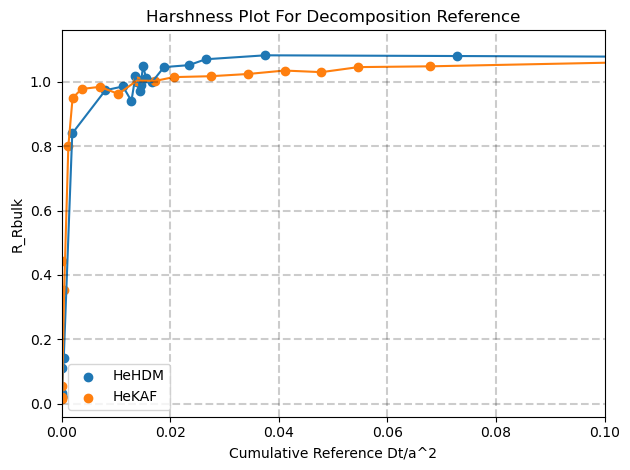

In [150]:
def D_a2reg(T):
    Ea = 38033.18815
    D0_a2 = 17623836.64
    return D0_a2*(np.exp(-Ea/(1.987*T)))
def D_a2Decomp(T):
    Ea = 35600
    D0_a2 = 2780000000
    return D0_a2*(np.exp(-Ea/(1.987*T)))

fig, ax = plt.subplots()

step_power = D_a2Decomp(Winsor_Data[f"He3HDM"]['Temp (C)']+273)*(Winsor_Data[f"He3HDM"]['Time (min)']*60)
plt.scatter(accumulate(step_power), (Winsor_Data['He4HDM']['He Yield (nCC@STP)']/Winsor_Data['He3HDM']['He Yield (nCC@STP)'])/(cum4HM[-1]/cum3HM[-1]), label = f"HeHDM")    
plt.plot(accumulate(step_power), (Winsor_Data['He4HDM']['He Yield (nCC@STP)']/Winsor_Data['He3HDM']['He Yield (nCC@STP)'])/(cum4HM[-1]/cum3HM[-1]))    
step_power = D_a2Decomp(Winsor_Data[f"He3KAF"]['Temp (C)']+273)*(Winsor_Data[f"He3KAF"]['Time (min)']*60)
plt.scatter(accumulate(step_power), (Winsor_Data['He4KAF']['He Yield (nCC@STP)']/Winsor_Data['He3KAF']['He Yield (nCC@STP)'])/(cum4KF[-1]/cum3KF[-1]), label = f"HeKAF")    
plt.plot(accumulate(step_power), (Winsor_Data['He4KAF']['He Yield (nCC@STP)']/Winsor_Data['He3KAF']['He Yield (nCC@STP)'])/(cum4KF[-1]/cum3KF[-1]))    
   


        
Dt_a2refs = np.linspace(0,1,1000)
Fcumrefs = 0.89*np.array([Forward_Diffuse(n) for n in Dt_a2refs])
#plt.plot(Dt_a2refs, Fcumrefs, linestyle = '--', label = 'Reference Domain')
plt.title('Harshness Plot For Decomposition Reference')
plt.xlabel('Cumulative Reference Dt/a^2')
plt.ylabel('R_Rbulk')
plt.xlim((0,0.1))
make_grid()
plt.legend()
plt.tight_layout()
plt.savefig('RatioDtPlot_WinsorGT.jpg', dpi = 256)

GC-S1a
GC-S1b
GC-S1c
GC-S1d
GC-S1-CuOx
MI-43-d1
MI-43-d2
MI-43-d4
MI-81-d1
MI-81-d2
MI-45-d1
YAN-0201D2
LYNN-A1D1
CAPL2-D1
CAPL3D1
CAP-L4D1
CAPL4D2
CAP-L4M
CAP-L4L
CAP-L5
YAN-0201AC
ROY-0202C3B
RS-34TLCM
Win0601bHDM
Win0601bKAF
HT-Win-06-01bBJT


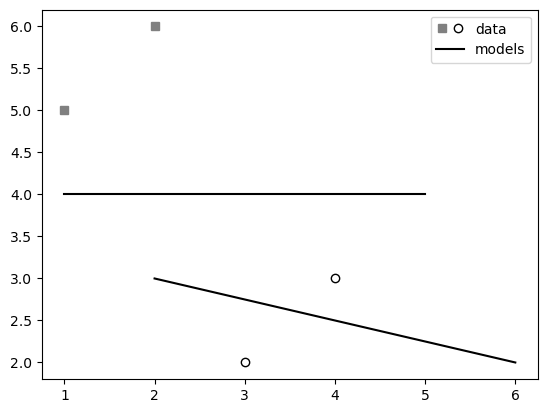

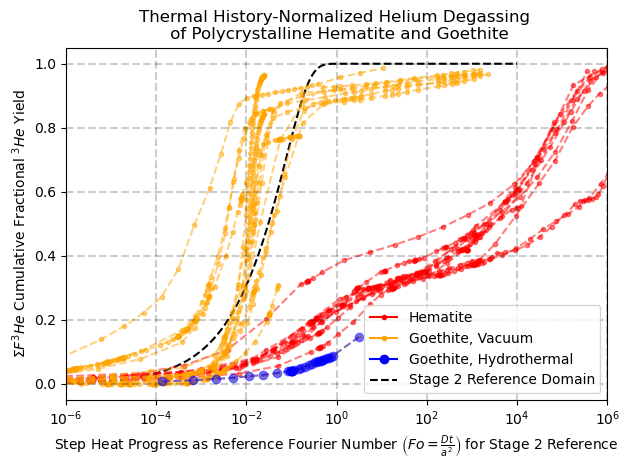

In [487]:

fig, ax1 = plt.subplots(1, 1)

# First plot: two legend keys for a single entry
p2, = ax1.plot([3, 4], [2, 3], 'o', mfc="white", mec="k")
p1, = ax1.plot([1, 2], [5, 6], 's', mfc="gray", mec="gray")
# `plot` returns a list, but we want the handle - thus the comma on the left
p3, = ax1.plot([1, 5], [4, 4], "-k")
p4, = ax1.plot([2, 6], [3, 2], "-k")

# Assign two of the handles to the same legend entry by putting them in a tuple
# and using a generic handler map (which would be used for any additional
# tuples of handles like (p1, p3)).
l = ax1.legend([(p1, p2), p3], ['data', 'models'],
               handler_map={tuple: HandlerTuple(ndivide=None)})
IDs = ['GC', 'MI-43', 'MI-81', ]


def D_a2HemMicron(T):
    """Farley, 2018 Hematite Diffusion for 1 micron Diffusion Domain"""
    Ea = 171000 #J/mol
    D0_a2 = np.exp(-0.66)/((1E-4)**2)
    return D0_a2*(np.exp(-Ea/(8.314*T)))

fig, ax = plt.subplots()
handles = {}
hematite_sheets = pd.read_excel('MDD_Step_heat_compilation.xlsx', None)
count = 0

Dt_a2refs = np.logspace(-10,4,10000)
Fcumrefs = np.array([Forward_Diffuse(n) for n in Dt_a2refs])
plt.semilogx(Dt_a2refs, Fcumrefs, linestyle = '--', color = 'Black', label = 'Hematite: 1 micron Domain')

for label, sheet in hematite_sheets.items():
    print(label)
    if any(['GC' in label, 'MI' in label]):
        lamps = sheet['T(oC)'][:-1] < 1000
        step_power = D_a2Decomp(sheet['T(oC)'][:-1][lamps].astype(float)+273)*(sheet['time (hrs)'][:-1][lamps].astype(float)*3600)
        #plt.scatter(accumulate(step_power), sheet['F3He'][:-1][lamps].astype(float), alpha = 0.5, color = 'red', label = f"Hematite")    
        plt.semilogx(accumulate(step_power), sheet['F3He'][:-1][lamps].astype(float), alpha = 0.5, marker = '.', color = 'red', linestyle = '--')
    #if any(['Win' in label, 'CAP' in label, 'BAH' in label]):
    else:
        lamps = sheet['T(oC)'][:-1] < 1000
        step_power = D_a2Decomp(sheet['T(oC)'][:-1][lamps].astype(float)+273)*(sheet['time (hrs)'][:-1][lamps].astype(float)*3600)
        #plt.scatter(accumulate(step_power), sheet['F3He'][:-1][lamps].astype(float), alpha = 0.5, color = 'orange', label = f"Goethite, Vacuum")    
        plt.semilogx(accumulate(step_power), sheet['F3He'][:-1][lamps].astype(float), alpha = 0.5, marker = '.', color = 'orange', linestyle = '--')
    #plt.scatter(sheet['F3He'][:-1][lamps].astype(float), accumulate(step_power)**0.5,  alpha = 0.5, label = f"Subsample '{label}'")    
    #plt.plot(sheet['F3He'][:-1][lamps].astype(float), accumulate(step_power)**0.5, alpha = 0.5, linestyle = '--')
    count += 1

#plt.plot(Fcumrefs, Dt_a2refs**0.5, linestyle = '--', label = '1 micron Reference Domain')
sheet = hematite_sheets['HT-Win-06-01bBJT']
step_power = D_a2Decomp(sheet['T(oC)'][:-1][lamps].astype(float)+273)*(sheet['time (hrs)'][:-1][lamps].astype(float)*3600)
#plt.scatter(accumulate(step_power), sheet['F3He'][:-1][lamps].astype(float), alpha = 0.5, color = 'blue', label = f"Goethite, Hydrothermal")    
plt.semilogx(accumulate(step_power), sheet['F3He'][:-1][lamps].astype(float), alpha = 0.5, marker = 'o', color = 'blue', linestyle = '--')

legend_elements = [mpl.lines.Line2D([0], [0], marker='.', color='red', label='Hematite',
                          markerfacecolor='red'),
                   mpl.lines.Line2D([0], [0], marker='.', color='orange', label='Goethite, Vacuum',
                          markerfacecolor='orange'),
                   mpl.lines.Line2D([0], [0], marker='o', color='blue', label='Goethite, Hydrothermal',
                          markerfacecolor='blue'),
                   mpl.lines.Line2D([0], [0], color='black', linestyle = '--', label='Stage 2 Reference Domain')]

plt.title('Thermal History-Normalized Helium Degassing \n of Polycrystalline Hematite and Goethite')
plt.xlabel(r'Step Heat Progress as Reference Fourier Number $\left(Fo = \frac{Dt}{a^2}\right)$ for Stage 2 Reference')
plt.ylabel(r'$\Sigma F^3He$ Cumulative Fractional $^3He$ Yield')
plt.xlim((10**-6,10**6))
make_grid()
plt.legend(handles=legend_elements)#, loc = 'upper left')
plt.tight_layout()
plt.savefig('Fo_Plot_stage_2_ref_AllGoe.jpg', dpi = 256)

In [489]:
DiffdatBJT['3'].columns

Index(['Step', 'Temp ©', 'Minutes', '3He Corrected (pccSTP)', 'Unnamed: 4',
       'Seconds', 'Cum 3He', '2 sigma', 'Fi+1', '2 sigma.1', 'Unnamed: 10',
       'D<10%', '2 sigma.2', 'D<90%', '2 sigma.3', 'D>90%', '2 sigma.4',
       'D/a^2', '2 sigma.5', '10000/TK', 'ln(d/a^2)', '2 sigma.6', 'Log(D/a2)',
       'Regression Reference ln(D/a2)', 'Delta Regression', 'Unnamed: 25',
       'Derivatives for Error Propagation (signs don't matter, terms are squared)',
       '0', '0.1', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32',
       'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36',
       'Unnamed: 37', 'Unnamed: 38', '0.033248729', '0.647861597'],
      dtype='object')

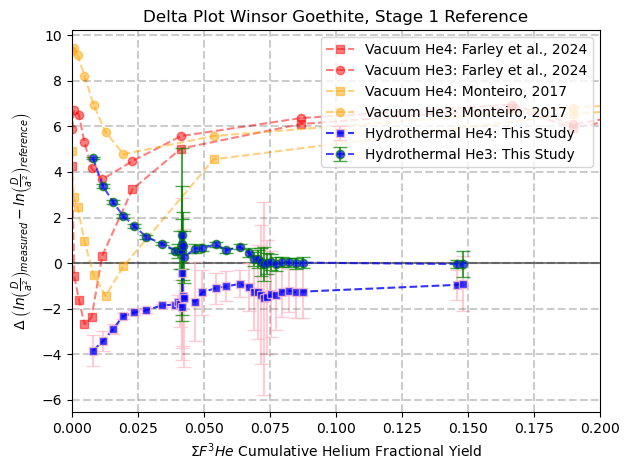

In [527]:
fig, ax = plt.subplots()
plt.hlines(0,0,1, color = 'black', alpha = 0.5)#linestyle = '--')
for i, l in enumerate(['KAF','HDM']):
    for j, n in enumerate(['4','3']):
        refs = np.log(D_a2reg(Winsor_Data[f"He3{l}"]['Temp (C)']+273))
        Deltas = Winsor_Data[f"He{n}{l}"]['ln(D/a^2)'] - refs
        #plt.scatter(Winsor_Data[f"He3{l}"]['Fcum'], Deltas, color = ['orange', 'red'][i], marker = ['x','s'][j], alpha = 0.5)
        plt.plot(Winsor_Data[f"He3{l}"]['Fcum'], Deltas, color = ['red','orange'][i], linestyle = '--', marker = ['s','o'][j],  alpha = 0.5, label = f"Vacuum He{n}: {['Farley et al., 2024','Monteiro, 2017'][i]}")
for j, n in enumerate(['4','3']):
    refs = np.log(D_a2reg(DiffdatBJT[n]['Temp ©']+273))
    Deltas = DiffdatBJT[n]['ln(d/a^2)'] - refs
    plt.errorbar(DiffdatBJT['3']['Fi+1'], Deltas, yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],  marker = ['s','o'][j], color = 'blue', markeredgecolor = ['pink','green'][j], ecolor = ['pink','green'][j], linestyle = '--', label = f'Hydrothermal He{n}: This Study', capsize = 5, alpha = [0.8,0.7][j])# ecolor = ['green','grey'][j], yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],
    #plt.plot(DiffdatBJT['3']['Fi+1'], Deltas,  marker = ['o','s'][j], color = 'blue', markeredgecolor = ['green','pink'][j], linestyle = '--', label = f'Hydrothermal He{n}: This Study', alpha = 0.5)# ecolor = ['green','grey'][j], yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],
    #plt.scatter(DiffdatBJT[n]['Fi+1'], Deltas, label = f"He{n}{l}")
    #plt.plot(Winsor_Data[f"He3{l}"]['Fcum'], Deltas)
Dt_a2refs = np.linspace(0,1,1000)
Fcumrefs = 0.89*np.array([Forward_Diffuse(n) for n in Dt_a2refs])
#plt.plot(Dt_a2refs, Fcumrefs, linestyle = '--', label = 'Reference Domain')
plt.title('Delta Plot Winsor Goethite, Stage 1 Reference')
plt.ylabel(r'$\Delta$ $\left(ln\left(\frac{D}{a^2}\right)_{measured} - ln\left(\frac{D}{a^2}\right)_{reference}\right)$')
plt.xlabel(r'$\Sigma F^3He$ Cumulative Helium Fractional Yield')
plt.xlim((0,0.2))
make_grid()
plt.legend(loc = 'upper right')#bbox_to_anchor=(0.15, 0.72))
plt.tight_layout()
plt.savefig('DeltasWinsorGTzoomin.jpg', dpi = 256)

In [ ]:
fig, ax = plt.subplots()
plt.hlines(0,0,1, color = 'black', alpha = 0.5)#linestyle = '--')
for i, l in enumerate(['KAF','HDM']):
    for j, n in enumerate(['4','3']):
        refs = np.log(D_a2reg(Winsor_Data[f"He3{l}"]['Temp (C)']+273))
        Deltas = Winsor_Data[f"He{n}{l}"]['ln(D/a^2)'] - refs
        #plt.scatter(Winsor_Data[f"He3{l}"]['Fcum'], Deltas, color = ['orange', 'red'][i], marker = ['x','s'][j], alpha = 0.5)
        plt.plot(Winsor_Data[f"He3{l}"]['Fcum'], Deltas, color = ['red','orange'][i], linestyle = '--', marker = ['s','o'][j],  alpha = 0.5, label = f"Vacuum He{n}: {['Farley et al., 2024','Monteiro, 2017'][i]}")
for j, n in enumerate(['4','3']):
    refs = np.log(D_a2reg(DiffdatBJT[n]['Temp ©']+273))
    Deltas = DiffdatBJT[n]['ln(d/a^2)'] - refs
    plt.errorbar(DiffdatBJT['3']['Fi+1'], Deltas, yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],  marker = ['s','o'][j], color = 'blue', markeredgecolor = ['pink','green'][j], ecolor = ['pink','green'][j], linestyle = '--', label = f'Hydrothermal He{n}: This Study', capsize = 5, alpha = [0.8,0.7][j])# ecolor = ['green','grey'][j], yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],
    #plt.plot(DiffdatBJT['3']['Fi+1'], Deltas,  marker = ['o','s'][j], color = 'blue', markeredgecolor = ['green','pink'][j], linestyle = '--', label = f'Hydrothermal He{n}: This Study', alpha = 0.5)# ecolor = ['green','grey'][j], yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],
    #plt.scatter(DiffdatBJT[n]['Fi+1'], Deltas, label = f"He{n}{l}")
    #plt.plot(Winsor_Data[f"He3{l}"]['Fcum'], Deltas)
Dt_a2refs = np.linspace(0,1,1000)
Fcumrefs = 0.89*np.array([Forward_Diffuse(n) for n in Dt_a2refs])
#plt.plot(Dt_a2refs, Fcumrefs, linestyle = '--', label = 'Reference Domain')
plt.title('Delta Plot Winsor Goethite, Stage 1 Reference')
plt.ylabel(r'$\Delta$ $\left(ln\left(\frac{D}{a^2}\right)_{measured} - ln\left(\frac{D}{a^2}\right)_{reference}\right)$')
plt.xlabel(r'$\Sigma F^3He$ Cumulative Helium Fractional Yield')
plt.xlim((0,0.2))
make_grid()
plt.legend(loc = 'upper right')#bbox_to_anchor=(0.15, 0.72))
plt.tight_layout()
plt.savefig('DeltasWinsorGTzoomin.jpg', dpi = 256)

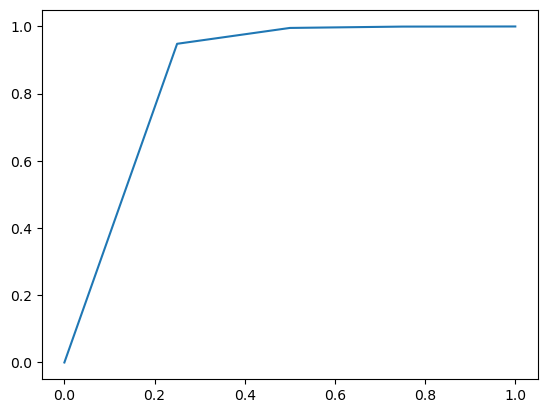

In [125]:
def Forward_Diffuse(Dt_a2):
    """Input is cumulative Dt_a2. 
    Equations 4a-c Fechtig and Kalbitzer, 1966"""
    
    Bt = (np.pi**2) * Dt_a2
    
    F = (6/(np.pi**(3/2))) * (Bt**(1/2)) # Small Yield Approx
    if F > 0.1:
        F = 1 - ((6/(np.pi**2)) * np.exp(-Bt)) # High Yield Approx
    if F < 0.9:
        F =(6/(np.pi**(3/2))) * (Bt**(1/2)) - ((3/(np.pi**2)) * Bt) # Mid-Yield Approx
        
    return F
ns = np.linspace(0,1,5)
plt.plot(ns, [Forward_Diffuse(n) for n in ns])

In [286]:

2780000000*np.exp(-np.array(xlim)*35600/(1.987))
np.exp(-np.array(xlim)*35.600/(1.987))

array([2.18773572e-101, 1.40653867e-227])

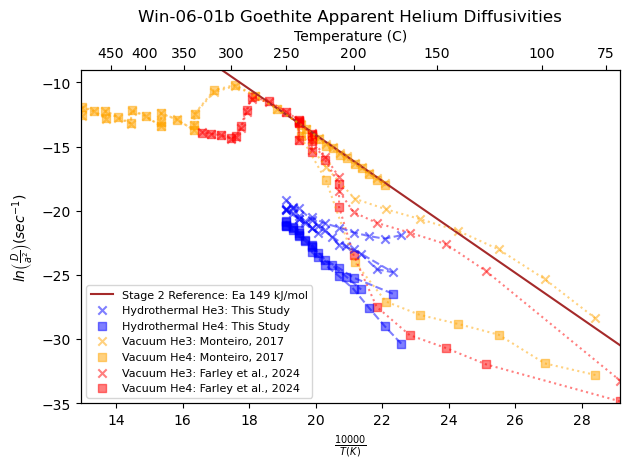

In [541]:
fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()
Ctemps = np.array([75,100,150,200,250,300,350,400,450])
#Ctemps = np.array([150,175,200,225,250])


def detect_segments(x):
    """
    Detects segments of monotonic behavior in x, including both ascending and descending breaks.
    
    Parameters:
        x (np.ndarray): The x data to analyze.
        
    Returns:
        list of np.ndarray: A list of indices for each monotonic segment, including breaks.
    """
    direction = np.sign(np.diff(x))  # Determine the direction of changes (+1, 0, -1)
    segment_breaks = np.where(direction[:-1] != direction[1:])[0] + 1
    
    # Include breaks at the start and end of x
    breaks = np.concatenate(([0], segment_breaks, [len(x)]))
    
    # Create segments, including breaks
    segments = [np.arange(breaks[i], breaks[i + 1]) for i in range(len(breaks) - 1)]
    return segments

#xlim = [1E4/(273+270),1E4/(273+150)] #[1E4/(273+500),1E4/(273+70)]
xlim = [1E4/(273+500),1E4/(273+70)]
#ax1.plot(xlim, (-1.9141*np.array(xlim))+16.685, label = 'Stage 1 Reference: Ea 160 kJ/mol', color = 'green',alpha = 0.5)
ax1.plot(xlim, np.log(2780000000*np.exp(-np.array(xlim)*3.5600/(1.987))), label = 'Stage 2 Reference: Ea 149 kJ/mol', color = 'brown')


for i, l in enumerate(['HDM','KAF']):
    for j, n in enumerate(['4','3']):
        ax1.plot(Winsor_Data[f"He{n}{l}"]['10^4/T'],Winsor_Data[f"He{n}{l}"]['ln(D/a^2)'], alpha = 0.5, color = ['orange','red'][i], linestyle = ':')
        ax1.scatter(Winsor_Data[f"He{n}{l}"]['10^4/T'],Winsor_Data[f"He{n}{l}"]['ln(D/a^2)'], label = f"Vacuum He{n}: {['Monteiro, 2017','Farley et al., 2024'][i]}", marker = ['s','x'][j], color = ['orange','red'][i], alpha = 0.5)


    #plt.plot(DiffdatBJT[n]['10000/TK'], DiffdatBJT[n]['ln(d/a^2)'], linestyle = '--', color = 'blue',  alpha = 0.5)# ecolor = ['green','grey'][j], yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],
    #plt.scatter(DiffdatBJT[n]['10000/TK'], DiffdatBJT[n]['ln(d/a^2)'], marker = ['x','s'][j], color = 'blue',  alpha = 0.5, label = f'Hydrothermal He{n}')# ecolor = ['green','grey'][j], yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],
for j, n in enumerate(['4','3']):
    y_upper = DiffdatBJT[n]['ln(d/a^2)'] + DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"]
    y_lower = DiffdatBJT[n]['ln(d/a^2)'] - DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"]
    ax1.plot(DiffdatBJT[n]['10000/TK'], DiffdatBJT[n]['ln(d/a^2)'], linestyle = '--', color = 'blue',  alpha = 0.5)# 
    #ax1.errorbar(DiffdatBJT[n]['10000/TK'], DiffdatBJT[n]['ln(d/a^2)'], yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],  marker = ['s','o'][j], color = 'blue', markeredgecolor = ['pink','green'][j], ecolor = ['pink','green'][j], linestyle = ' ', label = f'Hydrothermal He{n}: This Study', capsize = 5, alpha = [0.8,0.5][j])# ecolor = ['green','grey'][j], yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],
    ax1.scatter(DiffdatBJT[n]['10000/TK'], DiffdatBJT[n]['ln(d/a^2)'], marker = ['s','x'][j], color = 'blue',  alpha = 0.5, label = f'Hydrothermal He{n}: This Study')# ecolor = ['green','grey'][j], yerr = DiffdatBJT[n][f"2 sigma.{['7','6'][j]}"],
    """
    # Detect monotonic segments
    segments = detect_segments(DiffdatBJT[n]['10000/TK'])

    # Plot each segment as a separate filled polygon
    for segment in segments:
        x_segment = DiffdatBJT[n]['10000/TK'][segment]
        y_upper_segment = y_upper[segment]
        y_lower_segment = y_lower[segment]

        # Construct polygon for the segment
        x_polygon = np.concatenate([x_segment, x_segment[::-1]])
        y_polygon = np.concatenate([y_upper_segment, y_lower_segment[::-1]])

        ax1.fill(x_polygon, y_polygon, color = ['grey','green'][j], alpha=0.2)  # Add shaded region
    
    #ax1.fill_between(DiffdatBJT[n]['10000/TK'], y_lower, y_upper, color = ['green','grey'][j], alpha=0.3)"""


handles, labels = ax1.get_legend_handles_labels()
# Reorder the handles and labels
order = [0,6,5,2,1,4,3]  # New order: Confidence Interval first, then Mean Prediction
handles = [handles[i] for i in order]
labels = [labels[i] for i in order]
ax1.set_xlim(xlim)
ax1.set_ylim([-35,-9])
#ax1.set_ylim([-32,-17])#[-35,-9])
ax2.set_xticks(1E4/(Ctemps+273))
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (C)')
ax1.set_xlabel(r'$\frac{10000}{T^{ }(K)}$')
ax1.set_ylabel(r'$ln\left(\frac{D}{a^2}\right) \left(sec^{-1}\right)$')
#ax1.legend(loc = 'upper right', fontsize = 8)

ax1.legend(handles, labels, loc = 'lower left', fontsize = 8)
plt.title('Win-06-01b Goethite Apparent Helium Diffusivities')
fig.tight_layout()
plt.savefig('winsor_goethite_Big_Diffusivities.jpg', dpi = 256)
plt.show()

In [4]:
ApatiteDat = pd.read_csv('apatite_tube_plotables.csv')
ApatiteDat

,10000/TK,Cor ln(d/a^2),UncCor,Reference
0,26.809651,-28.357808,-28.437449,-32.672052
1,23.640662,-30.121820,-27.024244,-27.409009
2,21.137180,-23.681297,-25.058728,-23.251239
3,19.113150,-20.191127,-24.050215,-19.889739
4,18.406037,-19.041920,-22.552551,-18.715370
5,17.752530,-17.876284,-21.136511,-17.630028
6,17.442875,-17.345373,-20.106926,-17.115754
7,17.911517,-18.043947,-20.682069,-17.894073
8,18.241518,-18.651418,-19.867485,-18.442137
9,18.932223,-20.187302,-20.252388,-19.589256


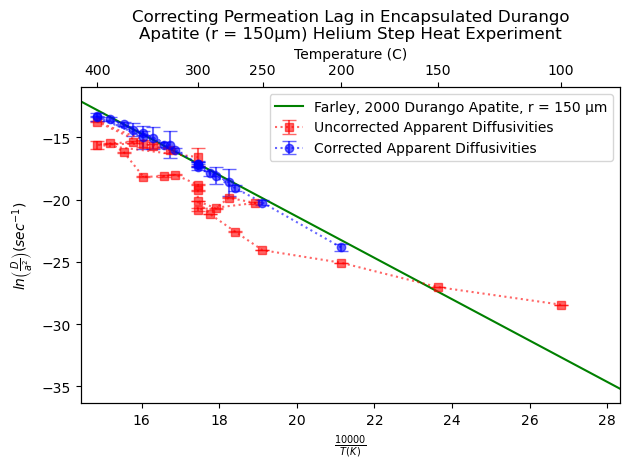

In [285]:
fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()
Ctemps = np.array([100,150,200,250,300,400])

ApatiteDat = pd.read_csv('apatite_tube_plotables.csv')

plotable = ApatiteDat['2s'] < 2

#xlim = [1E4/(273+270),1E4/(273+150)] #[1E4/(273+500),1E4/(273+70)]
xlim = [1E4/(273+420),1E4/(273+80)]
#ax1.plot(xlim, (-1.9141*np.array(xlim))+16.685, label = 'Stage 1 Reference: Ea 160 kJ/mol', color = 'green',alpha = 0.5)
ax1.plot(xlim, np.log(((10**1.5)/(0.015**2))*np.exp(-33000/(1.987*(273+np.array([420,80]))))), label = 'Farley, 2000 Durango Apatite, r = 150 µm', color = 'green')
ax1.errorbar(ApatiteDat['10000/TK'],ApatiteDat['UncCor'],yerr = ApatiteDat['U2s'], marker = 's', capsize = 5, color = 'red', alpha = 0.6, linestyle = ':', label = 'Uncorrected Apparent Diffusivities')
ax1.errorbar(ApatiteDat['10000/TK'][plotable],ApatiteDat['Cor ln(d/a^2)'][plotable], yerr = ApatiteDat['2s'][plotable], capsize = 5, alpha = 0.6, marker = 'o', color = 'blue', linestyle = ':', label = 'Corrected Apparent Diffusivities')




ax1.set_xlim(xlim)
#ax1.set_ylim([-35,-9])
#ax1.set_ylim([-32,-17])#[-35,-9])
ax2.set_xticks(1E4/(Ctemps+273))
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (C)')
ax1.set_xlabel(r'$\frac{10000}{T^{ }(K)}$')
ax1.set_ylabel(r'$ln\left(\frac{D}{a^2}\right) \left(sec^{-1}\right)$')
#ax1.legend(loc = 'upper right', fontsize = 8)

ax1.legend()
plt.title('Correcting Permeation Lag in Encapsulated Durango\nApatite (r = 150µm) Helium Step Heat Experiment')
fig.tight_layout()
plt.savefig('encapsulated_DApErr.jpg', dpi = 256)
plt.show()

In [294]:
print(1-np.exp(-(1*60)*(273+26)*swets('K',(273+26))*Ratoms*6000))

0.00023190301204067953


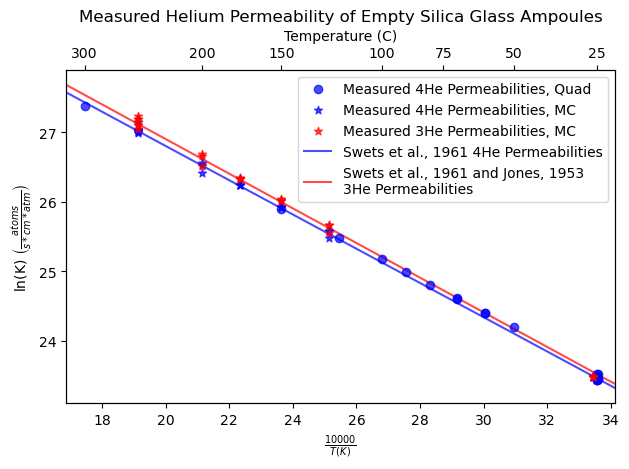

In [185]:
fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()
Ctemps = np.array([25,50,75,100,150,200,300])

TubeDat = pd.read_excel('EmptyTubeQuad1.xlsx', skiprows=1)
predDat = pd.read_excel('plotableEmptyTubes.xlsx', sheet_name=None)
labels = ['Empty Ampoule, Quad', 'Empty Ampoule, MC', 'Encapsulated Sulfur, MC', 'Encapsulated Water, MC']


xliminp = [20,320]

#xlim = [1E4/(273+270),1E4/(273+150)] #[1E4/(273+500),1E4/(273+70)]
xlim = [1E4/(273+xliminp[1]),1E4/(273+xliminp[0])]
#ax1.plot(xlim, (-1.9141*np.array(xlim))+16.685, label = 'Stage 1 Reference: Ea 160 kJ/mol', color = 'green',alpha = 0.5)

MCDat = predDat['MC Measured']
isreal = np.isnan(MCDat['4He ln(K)']) == False

ax1.scatter(TubeDat['10000/T(K)'][3:],TubeDat['ln(K)'][3:], marker = 'o', color = 'blue', label = 'Measured 4He Permeabilities, Quad', zorder = 2,alpha = 0.7)
ax1.scatter(MCDat['10000/T'][isreal][:-1],MCDat['4He ln(K)'][isreal][:-1], marker = '*', color = 'blue', label = 'Measured 4He Permeabilities, MC', zorder = 4, alpha= 0.7)
ax1.scatter(MCDat['10000/T'][isreal][:-1],MCDat['3He ln(K)'][isreal][:-1], marker = '*', color = 'red', label = 'Measured 3He Permeabilities, MC', zorder = ,alpha=0.7)
ax1.plot(xlim, np.log((0.000304*199000000000000000)*np.exp(-(5580-680)/(1.987*(np.flip(xliminp)+273)))), label = 'Swets et al., 1961 4He Permeabilities', color = 'blue', zorder = 0,alpha = 0.7)
ax1.plot(xlim, np.log(Jones(np.flip(xliminp)+273)*(0.000304*199000000000000000)*np.exp(-(5580-680)/(1.987*(np.flip(xliminp)+273)))), label = 'Swets et al., 1961 and Jones, 1953\n3He Permeabilities', color = 'red', zorder = 1, alpha = 0.7)



ax1.set_xlim(xlim)
#ax1.set_ylim([-35,-9])
#ax1.set_ylim([-32,-17])#[-35,-9])
ax2.set_xticks(1E4/(Ctemps+273))
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (C)')
ax1.set_xlabel(r'$\frac{10000}{T^{ }(K)}$')
ax1.set_ylabel(r'ln(K) $\left(\frac{atoms}{s⁡*cm*atm}\right)$')
#ax1.legend(loc = 'upper right', fontsize = 8)

ax1.legend()
plt.title('Measured Helium Permeability of Empty Silica Glass Ampoules')
fig.tight_layout()
plt.savefig('PermeabilityMeasurements.jpg', dpi = 256)
plt.show()

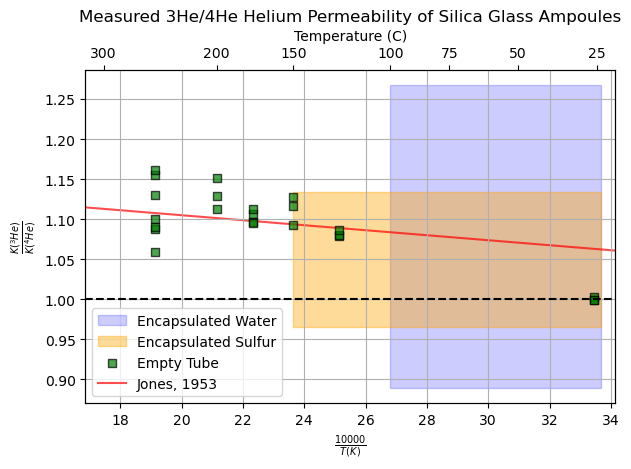

In [243]:
from matplotlib.patches import Polygon
fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()
Ctemps = np.array([25,50,75,100,150,200,300])

TubeDat = pd.read_excel('EmptyTubeQuad1.xlsx', skiprows=1)
predDat = pd.read_excel('plotableEmptyTubes.xlsx', sheet_name=None)
labels = ['Empty Ampoule, Quad', 'Empty Ampoule, MC', 'Encapsulated Sulfur, MC', 'Encapsulated Water, MC']


xliminp = [20,320]

#xlim = [1E4/(273+270),1E4/(273+150)] #[1E4/(273+500),1E4/(273+70)]
xlim = [1E4/(273+xliminp[1]),1E4/(273+xliminp[0])]
#ax1.plot(xlim, (-1.9141*np.array(xlim))+16.685, label = 'Stage 1 Reference: Ea 160 kJ/mol', color = 'green',alpha = 0.5)

MCDat = predDat['MC Measured']
SDat = predDat['MC Sulfur']
WDat = predDat['MC Water']
isreal = np.isnan(MCDat['4He ln(K)']) == False



waterpoly = Polygon(np.array([[10000/(24+273),1.0786E+00-1.8912E-01],
                [10000/(24+273),1.0786E+00+1.8912E-01],
                [10000/(100+273),1.0786E+00+1.8912E-01],
                [10000/(100+273),1.0786E+00-1.8912E-01]]), color = 'blue', alpha = 0.2, label = 'Encapsulated Water')
sulfurpoly = Polygon(np.array([[10000/(24+273),1.04953E+00-8.41327E-02],
                [10000/(24+273),1.04953E+00+8.41327E-02],
                [10000/(150+273),1.04953E+00+8.41327E-02],
                [10000/(150+273),1.04953E+0-8.41327E-02]]), color = 'orange', alpha = 0.4, label = 'Encapsulated Sulfur')

ax1.add_patch(waterpoly)
ax1.add_patch(sulfurpoly)

#ax1.plot(xlim, [(4/3)**0.5,(4/3)**0.5], color = 'red', label = r"Graham's law: $\frac{D_{3He}}{D_{4He}}=\sqrt{\frac{4}{3}}$")
ax1.scatter(MCDat['10000/T'][isreal][:-1],MCDat['K3/4'][isreal][:-1], marker = 's', edgecolor = 'black', color = 'green', label = 'Empty Tube', zorder = 2, alpha= 0.7)
ax1.plot(xlim, Jones(np.flip(xliminp)+273), label = 'Jones, 1953', color = 'red', zorder = 1, alpha = 0.7)
ax1.plot(xlim,[1,1],linestyle = '--',color='black')

ax1.set_xlim(xlim)
#ax1.set_ylim([-35,-9])
#ax1.set_ylim([-32,-17])#[-35,-9])
ax2.set_xticks(1E4/(Ctemps+273))
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (C)')
ax1.set_xlabel(r'$\frac{10000}{T^{ }(K)}$')
ax1.set_ylabel(r'$\frac{K\left(^3He\right)}{K\left(^4He\right)}$')
#ax1.legend(loc = 'upper right', fontsize = 8)

ax1.legend(loc = 'lower left')
plt.title('Measured 3He/4He Helium Permeability of Silica Glass Ampoules')
ax1.grid(True)
fig.tight_layout()
plt.savefig('Relative_Permeabilities.jpg', dpi = 256)
plt.show()

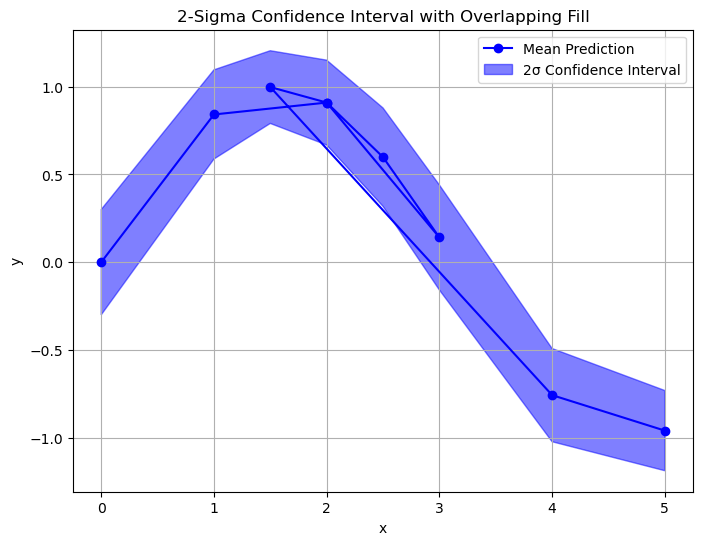

In [220]:
# Example data (non-monotonic x)
x = np.array([0, 1, 2, 3, 2.5, 2, 1.5, 4, 5])
y = np.sin(x)  # Example y values
sigma2 = 0.2 + 0.1 * np.abs(np.cos(x))  # Example 2-sigma uncertainties

# Calculate the upper and lower bounds of the confidence interval
y_upper = y + sigma2
y_lower = y - sigma2

# Sort x, y, y_upper, and y_lower by x for proper polygon construction
sort_indices = np.argsort(x)
x_sorted = x[sort_indices]
y_sorted = y[sort_indices]
y_upper_sorted = y_upper[sort_indices]
y_lower_sorted = y_lower[sort_indices]

# Combine the upper and lower bounds in reverse order for the polygon path
x_polygon = np.concatenate([x_sorted, x_sorted[::-1]])
y_polygon = np.concatenate([y_upper_sorted, y_lower_sorted[::-1]])

# Create the plot
plt.figure(figsize=(8, 6))
plt.plot(x, y, 'o-', label="Mean Prediction", color="blue")  # Plot the central line
plt.fill(x_polygon, y_polygon, color="blue", alpha=0.5, label="2σ Confidence Interval")  # Shaded region

# Add labels and legend
plt.xlabel("x")
plt.ylabel("y")
plt.title("2-Sigma Confidence Interval with Overlapping Fill")
plt.legend()
plt.grid(True)

# Show the plot
plt.show()

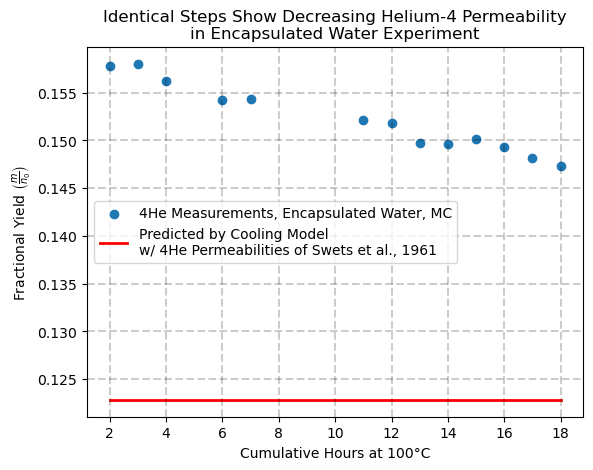

In [262]:
fig, ax = plt.subplots()
WaterData = pd.read_excel('MCEmptyTubeData.xlsx', sheet_name='H2O Isothermal OD734 ID487', skiprows= 1)
identicals = [1,2,3,5,6,10,11,12,13,14,15,16,17]
plt.scatter(WaterData['cumulative hot time (s)'][identicals]/3600, 1-WaterData['4He measured'][identicals], label = '4He Measurements, Encapsulated Water, MC')
plt.plot([np.min(WaterData['cumulative hot time (s)'][identicals]/3600), np.max(WaterData['cumulative hot time (s)'][identicals]/3600)], 1-np.array([0.877168987133026,0.877168987133026]), color = 'red', linewidth = 2, label = 'Predicted by Cooling Model\nw/ 4He Permeabilities of Swets et al., 1961')
make_grid()
plt.legend(loc = 'center left')
plt.xlabel('Cumulative Hours at 100°C')
plt.ylabel(r'Fractional Yield $\left(\frac{m}{n_0}\right)$')
plt.title('Identical Steps Show Decreasing Helium-4 Permeability\nin Encapsulated Water Experiment')
plt.savefig('ChangingYieldH2Otube.jpg', dpi = 256)

NameError: name 'Winsor_Data' is not defined

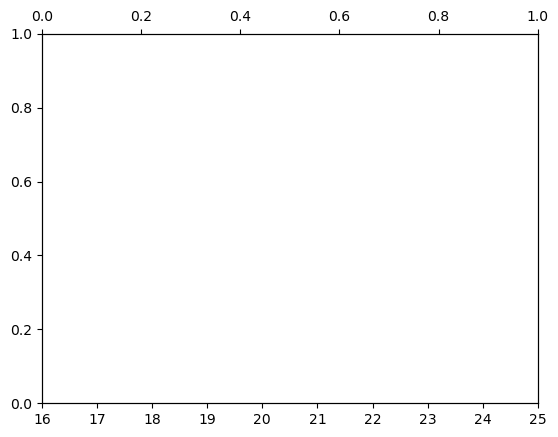

In [7]:
DiffdatBJT = {}

DiffdatBJT['3'] = pd.read_csv('diffusivitiesHTWin0601b3He.csv')
DiffdatBJT['4'] = pd.read_csv('diffusivitiesHTWin0601b4He.csv')

#ax1.plot(Diffdat['10^4/T'], Diffdat['ln(D/a^2)'])

Diffdat = pd.read_csv('Winsor4HeUB_BJT.csv')
invtemp = np.array(Diffdat['10^4/T'])
OmegaUB = np.array(Diffdat['ln(D/a^2)'])
Diffdat = pd.read_csv('Winsor4HeLB_BJT.csv')
OmegaLB = np.array(Diffdat['ln(D/a^2)'])
Diffdat = pd.read_csv('Winsor4HeM_BJT.csv')
OmegaM = np.array(Diffdat['ln(D/a^2)'])


#data_holder_MC['3He'] = pd.read_csv('Winsor3HeCustomReductionBJT.csv')[:-1]


#big_yields_i = data_holder_MC['3He']['He Yield (nCC@STP)'] >= .1
#small_yields_i = data_holder_MC['3He']['He Yield (nCC@STP)'] < .1

#min_T = np.min(data_holder_MC['3He']['10^4/T'])
min_T = 10000/(350+273)
#max_T = np.max(data_holder_MC['3He']['10^4/T'])
max_T = 10000/(100+273)

R = 1.987 #cal /mol /T(K)

fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()

valid = (OmegaUB - OmegaLB) > 0
#print(valid.astype('float') - (Diffdat['He Yield (nCC@STP)'] > 0.05).astype('float'))

#valid *= Diffdat['He Yield (nCC@STP)'] > 0.05

midpoints = OmegaLB + (0.5*(OmegaUB-OmegaLB))

#plt.scatter(invtemp[valid], OmegaUB[valid])

#plt.scatter(invtemp[valid], OmegaLB[valid])



#ax1.plot(data_holder_MC['3He']['10^4/T'], data_holder_MC['3He']['ln(D/a^2)'], linestyle = '--', color = 'green')
#ax1.scatter(data_holder_MC['3He']['10^4/T'], data_holder_MC['3He']['ln(D/a^2)'], s = 5, color = 'green', label = '3He')
Ctemps = np.linspace(100,500,9).astype(int)
#ax1.plot(10000/TempKelvin[HTind], np.array(lnD_a2), linestyle='--', color = 'black')
#ax1.scatter(10000/TempKelvin[HTind], np.array(lnD_a2), s = 5, color = 'black', label = '4He')#, c = np.log10(IR[real_steps][good_steps]), label = 'Data')
#plt.title(f"Diffusivity Inversion for {name}\nTotal Yield = {total_yield} {['p','n'][i]}cc's")

#reference_D0_a2 = [(10**0.9)/((212/10000)**2), (10**2.1)/((180/10000)**2), np.exp(1.1939)] # /sec
#reference_Ea = [33000, 33000, 14701*1.987] # cal /mol
#for j, no in enumerate(['3','4']): # Plot Win-G from HDM and KAF
#ax1.plot(Winsor_Data[f'He{no}HDM']['10^4/T'][:-1], Winsor_Data[f'He{no}HDM']['ln(D/a^2)'][:-1], linestyle='--', linewidth = 1, marker=['x','+'][j], color='g', label = f'HDM {no}He Data')


#ax1.plot(invtemp[valid], midpoints[valid], color = 'Orange')
#ax1.vlines(invtemp[valid], OmegaUB[valid], OmegaLB[valid], color = 'Orange')


#ax1.scatter(invtemp, OmegaM, marker = '*', color = 'Orange', s = 5, label = 'Hydrothermal 4He')
#ax1.plot(invtemp[big_yields_i*valid], midpoints[big_yields_i*valid], linestyle = ':', color = 'Grey')
#ax1.vlines(invtemp[big_yields_i*valid],OmegaUB[big_yields_i*valid], OmegaLB[big_yields_i*valid],  color = 'Orange')
#ax1.plot(data_holder_MC['3He']['10^4/T'][big_yields_i], data_holder_MC['3He']['ln(D/a^2)'][big_yields_i], linestyle = ':', color = 'grey')
#ax1.scatter(data_holder_MC['3He']['10^4/T'][big_yields_i], data_holder_MC['3He']['ln(D/a^2)'][big_yields_i], color = 'blue', marker = '*', label = "Hydrothermal 3He")
#ax1.scatter(data_holder_MC['3He']['10^4/T'][small_yields_i], data_holder_MC['3He']['ln(D/a^2)'][small_yields_i], s = 5, color = 'blue')

ax1.set_xlim((16,25))
for j, no in enumerate(['3','4']):
    ax1.plot(Winsor_Data[f'He{no}HDM']['10^4/T'][:-1], Winsor_Data[f'He{no}HDM']['ln(D/a^2)'][:-1], linestyle='--', color = 'grey')
    ax1.scatter(Winsor_Data[f'He{no}HDM']['10^4/T'][:-1], Winsor_Data[f'He{no}HDM']['ln(D/a^2)'][:-1], marker=['+','x'][j], color = ['Blue','Orange'][j], label = f'{no}He')#, c=Diffdat1['watercum'][:-1]/max(Diffdat1['watercum']), cmap = 'RdYlBu_r', label = f'KAF {no}He Data')\
    ax1.plot(DiffdatBJT[{no}]['10^4/T'], DiffdatBJT[{no}]['ln(D/a^2)'], linestyle='--', color = 'grey')
    ax1.scatter(DiffdatBJT[{no}]['10^4/T'], DiffdatBJT[{no}]['ln(D/a^2)'], marker=['8','s'][j], color = ['Blue','Orange'][j], label = f'BJT{no}He')#, c=Diffdat1['watercum'][:-1]/max(Diffdat1['watercum']), cmap = 'RdYlBu_r', label = f'KAF {no}He Data')
#ax1.set_xlim([1E4/(270+273),1E4/(150+273)])
#cbar = plt.colorbar(mappable = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap='RdYlBu_r'))
#cbar.set_label('Cumulative Water Offgassed')
ax2.set_xticks(1E4/(Ctemps+273))
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (C)')
ax1.set_xlabel('10^4/T(K)')
ax1.set_ylabel('ln(D/a^2) (sec^-1)')
plt.title('Apparent Helium Diffusivities of Irradiated Win-06-01B\nMonteiro, 2017')
ax1.legend()#fontsize = 10)
plt.tight_layout()
plt.savefig('TwoIsotopeALLWinsor.jpg', dpi = 256)
plt.show()

In [305]:
OmegaUB

array([-28.46009897, -27.78637636, -26.83603721, -25.54382865,
       -24.63076616, -23.78053366, -22.86670993, -23.31570319,
       -23.894395  , -24.62571352, -25.60194806, -26.55955463,
       -26.12290859, -24.85060714, -22.76972614, -23.17664912,
       -22.14665569, -21.13334637, -20.7246199 , -20.23788807,
       -20.79049204, -21.40973607, -21.7753965 , -22.31471738,
       -22.79882029, -22.42298611, -22.01738465, -21.59098738,
       -21.13974733, -20.72357162, -20.71653636, -20.73381406,
       -20.7772463 , -21.43801552])

In [307]:
Diffdat = pd.read_csv('Winsor4HeM_BJT.csv')

Temps = Diffdat['Temp (C)'] + 273
Reference = 16.864-(1.9259*(1E4/Temps[valid]))
data = [Temps[valid]-273, OmegaLB[valid]-Reference, midpoints[valid]-Reference, OmegaUB[valid]-Reference, Diffdat['Fcum'][valid]]
columns = ['Temp (C)','Delta Upper','Delta mid', 'Delta Lower','Fcum']


outdat = pd.DataFrame()

for i,col in enumerate(columns):
    outdat[col] = data[i]
    
outdat.to_csv('4HeHydrothermalForDeltaPlot.csv')

C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\4144773873.py:10: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  cbar = plt.colorbar(mappable = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap='RdYlBu_r'))
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


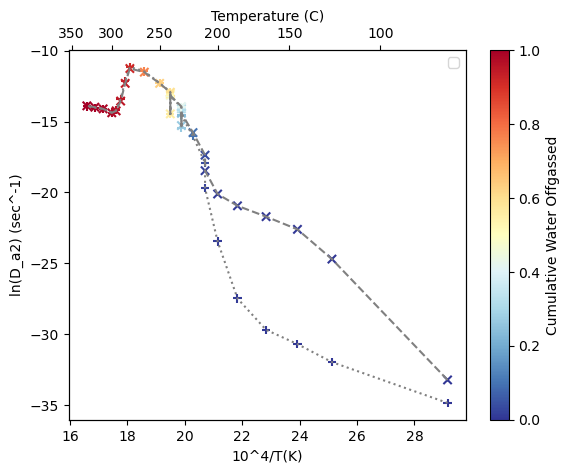

In [45]:

min_T = np.min(10000/TempKelvin[HTind])
max_T = np.max(10000/TempKelvin[HTind])
fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()
Ctemps = np.linspace(100,700, 13,dtype = int)
for j, no in enumerate(['3','4']):
    ax1.plot(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], linestyle=['--',':'][j], color = 'grey')
    ax1.scatter(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], marker=['x','+'][j], c=Diffdat1['watercum'][:-1]/max(Diffdat1['watercum']), cmap = 'RdYlBu_r', label = f'KAF {no}He Data')
cbar = plt.colorbar(mappable = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap='RdYlBu_r'))
cbar.set_label('Cumulative Water Offgassed')
ax2.set_xticks(1E4/(Ctemps+273))
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (C)')
ax1.set_xlabel('10^4/T(K)')
ax1.set_ylabel('ln(D_a2) (sec^-1)')
plt.legend()#fontsize = 10)
plt.savefig('KenColorPlot.jpg', dpi = 256)
plt.show()

In [2]:
## MC Diff Cell Data Reduction

def get_real_time(ID):
    with open(f'NGL Watlow Heat Log/DC{ID} Watlow.txt') as lines:
        return(float(lines.readlines()[-1].split('\t')[0])-25)

data_holder_MC = {}


""" 
DIFFCELL_name = '112123LVCOPyIrrOG.csv'#DIFFCELL_name
rest_4He = 7.27*2.34 # nccSTP 4He total_yield 
rest_3He = 51.77*2.34 # pccSTP 3He total_yield
OD = 1552/1E4
ID = 828/1E4

DIFFCELL_name = '112123SalAspIrr.csv'#DIFFCELL_name
total_4He = 13.47*0.8 # nccSTP 4He total_yield 
total_3He = 51.77*0.8 # pccSTP 3He total_yield
OD = 967/1E4
ID = 533/1E4
DIFFCELL = pd.read_csv(DIFFCELL_name, header = None).to_numpy()
metadata = DIFFCELL[:,1]
TempKelvin = np.array([273+pull_number(str(datum).split(' ')[2]) for datum in metadata])
DIFFCELL = DIFFCELL[(TempKelvin>(273+70))*((TempKelvin>(370+273))+(TempKelvin<(220+273))),:]
DIFFCELL = DIFFCELL[(DIFFCELL[:,4]>0)*(DIFFCELL[:,6]>0),:]
"""

DIFFCELL_name = 'IrrWin0601bTube012624TC.csv'#DIFFCELL_name
DIFFCELL = pd.read_csv(DIFFCELL_name, header = None).to_numpy()
total_4He = 122*1.18 # nccSTP 4He total_yield 
total_3He = 105*1.18 # pccSTP 3He total_yield
OD = 800/1E4
ID = 510/1E4


G = 2/(np.log(OD/ID)*((ID/2)**2))

perm_model = 'modeled'
    
Ra = 1.39E-6
#sens4He = 2.29E-2 #ncc/fA
#sens3He = 5.28E-3 #pcc/cps





reducer = MCHeReducer('2024STDsMC.csv')
He3, He4 = reducer.reduce(DIFFCELL)



#CB_lim = 100 +273  # max temperature of cold blanks
#ignore_lim = 250 +273

Tcutoff = [30+273, 65+273, 130+273]

rest_He = [rest_3He, rest_4He]
metadata = DIFFCELL[:,1]
TimeSeconds = np.array([60*pull_number((str(datum).split(' ')[1]).split('_')[1]) for datum in metadata])
TempKelvin = np.array([273+pull_number(str(datum).split(' ')[2]) for datum in metadata])
TargetTemp = np.array([273+pull_number((str(datum).split(' ')[1]).split('_')[2]) for datum in metadata]) 
recordedTimeSeconds = np.array([get_real_time((str(datum).split(' ')[1]).split('_')[0]) for datum in metadata])
coldtimes = np.array([0] + list(extract_timesMC(DIFFCELL[:,2])))


He3signal = DIFFCELL[:,4].astype('float')
He4signal = (DIFFCELL[:,6].astype('float'))
#He3 = He3signal*sens3He # pccSTP
#He4 = He4signal*sens4He # nccSTP
signals = [He3signal, He4signal]
IR = np.array((He3/(He4*1E3))/Ra)
total_yields = []

for j, He in enumerate([He3,He4]):
    total_yield = [total_3He, total_4He][j]
    name = ['3He', '4He'][j]
    HenCC = He
    HenCC[HenCC < 0] = 0 
    Names = DIFFCELL[:,0]
    
    # Information for tube corrections
    n0_modeled = [] # calc for every cold blank, cold indices apply
    n1_modeled = []
    n0_measured = [] # calc for consectutive cold blanks, indices in Smeas
    n1_measured = []
    Smeas = [] #indices of consecutive cold blanks
    colds = [] #indices of all cold blanks
    Smeascolds = []
    M = [] #measured CB proportionality (1 - n1/n0)/sec

    # Diffusivity data
    fcum = []
    Fp = 0
    DC_indices = []
    D_a2 = []
    lnD_a2 = []
    n1_n0_mod = []
    n1_n0_mes = []

    ####
    HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
    ####
    prev_cold = 0
    prev_inter = 0
    cold_counter = -1
    total_colds = 0
    Rel_times = []
    
    for i, datum in enumerate(metadata):
        # First, manage permeability corrections
        if TempKelvin[i] < Tcutoff[2] :
            colds.append(i)
            cold_counter += 1  
            total_colds += 1
            if TempKelvin[i] > Tcutoff[1]: # Logic to only report values where temperature control is valid. Later model room temp as cooling curve
                if perm_model == 'modeled' or perm_model == 'modelled':
                    n1_n0_modeled = tube_permeate2(t = TimeSeconds[i], T = TempKelvin[i], ID = ID, OD = OD, He = name)
                elif perm_model == 'measured':
                    n1_n0_modeled = tube_permeate3(t = TimeSeconds[i], T = TempKelvin[i], K0G=K0G, Ea=Ea) 
            elif (TempKelvin[i] < Tcutoff[0]) and prev_cold > 0:
                if perm_model == 'modeled' or perm_model == 'modelled':
                    n1_n0_modeled = tube_permeate2(t = coldtimes[i], T = TempKelvin[i], ID = ID, OD = OD, He = name) 
                elif perm_model == 'measured':
                    n1_n0_modeled = tube_permeate3(t = coldtimes[i], T = TempKelvin[i], K0G=K0G, Ea=Ea) 
            else: 
                n1_n0_modeled = 0
                print(f'COLD {i} FELL THROUGH')
            n1_n0_mod.append(n1_n0_modeled)
            if n1_n0_modeled:
                n0_modeled.append(HenCC[i]/(1-n1_n0_modeled))
                n1_modeled.append(HenCC[i]/((1/n1_n0_modeled)-1))
            else:
                n0_modeled.append(0)
                n1_modeled.append(0)
            if ((prev_cold >= 2) and (TempKelvin[i] < Tcutoff[0])):# and (HenCC[i] > 0.0175)):
                Smeascolds.append(cold_counter)
                #Smeas.append(i-1)
                Smeas.append(i)
                Rel_times.append(coldtimes[i])
                n1_n0_measured = (HenCC[i]/coldtimes[i])/(HenCC[i-1]/coldtimes[i-1]) # Assume unchanging abundance, time normalize
                m = (1 - n1_n0_measured)/np.mean([coldtimes[i], coldtimes[i-1]]) # Assume n1/n0 linear: no significant degassing
                #n0_measured.append(HenCC[i-1]/(m*coldtimes[i-1]))
                #n1_measured.append(HenCC[i-1]/((1/(1-(m*coldtimes[i-1]))-1)))
                n0_measured.append(HenCC[i]/(m*coldtimes[i]))
                n1_measured.append(HenCC[i]/((1/(1-(m*coldtimes[i]))-1)))
                n1_n0_mes.append(n1_n0_measured)
                M.append(m)
                #M.append(m)
            elif ((prev_inter >= 1) and ((TempKelvin[i] > Tcutoff[1]) and (np.abs(TempKelvin[i] - TempKelvin[i-1]) < 2))):# and (HenCC[i] > 0.01)):
                Smeascolds.append(cold_counter)
                Rel_times.append(TimeSeconds[i])
                #Smeas.append(i-1)
                Smeas.append(i)
                n1_n0_measured = (HenCC[i]/TimeSeconds[i])/(HenCC[i-1]/TimeSeconds[i-1]) # Assume unchanging abundance, time normalize
                m = (1 - n1_n0_measured)/np.mean([TimeSeconds[i], TimeSeconds[i-1]]) # Assume n1/n0 linear: no significant degassing
                #n0_measured.append(HenCC[i-1]/(m*coldtimes[i-1]))
                #n1_measured.append(HenCC[i-1]/((1/(1-(m*coldtimes[i-1]))-1)))
                n0_measured.append(HenCC[i]/(m*TimeSeconds[i]))
                n1_measured.append(HenCC[i]/((1/(1-(m*TimeSeconds[i]))-1)))
                n1_n0_mes.append(n1_n0_measured)
                M.append(m)

            if (TempKelvin[i] < (Tcutoff[0]+40)):
                prev_cold += 1
                prev_inter = 0
            else:
                prev_inter += 1
                prev_cold = 0

            Names[i] = str(total_colds)+' in sequence ' + metadata[i]
        else:
            prev_cold = 0
            prev_inter = 0
            total_colds = 0

    n1_measured = np.array(n1_measured)
    n0_measured = np.array(n0_measured)
    n1_modeled = np.array(n1_modeled)
    n0_modeled = np.array(n0_modeled)

    n1_measured_out = np.zeros_like(n1_modeled)
    n1_measured_out[Smeascolds] = n1_measured
    n0_measured_out = np.zeros_like(n0_modeled)
    n0_measured_out[Smeascolds] = n0_measured
    n1_n0_mes_out = np.zeros_like(n0_modeled)
    n1_n0_mes_out[Smeascolds] = n1_n0_mes

    #molHe = HenCC/(22.4*1E12) #convert from nccSTP to moles
    #PHeATM = ((molHe*RccATM*TempKelvin)/V)
    #PHe = (PHeATM/1.01325)*1E6 # Conv. Atmospheres to microbars

    lambdas = -np.log((np.array(n1_measured)/np.array(n0_measured)))/(TempKelvin[Smeas]*Rel_times*Ratoms)
    K_meas = (lambdas*np.log(OD/ID)*((ID/2)**2))/2
    K_ref = []

    for Temp in TempKelvin[Smeas]:
        K_ref.append(swets_K(Temp))
    DK_swets = np.log(K_meas)-np.log(np.array(K_ref))
    lnlambdas = np.log(lambdas)
    lambdas_out = np.zeros_like(n0_modeled)
    lnlambdas_out = np.zeros_like(n0_modeled)
    lambdas_out[Smeascolds] = lambdas
    lnlambdas_out[Smeascolds] = lnlambdas
    K_meas_out = np.zeros_like(n0_modeled)
    DK_swets_out = np.zeros_like(n0_modeled)
    K_meas_out[Smeascolds] = np.array(K_meas)
    DK_swets_out[Smeascolds] = DK_swets

    """
    plt.scatter(HenCC[Smeas]/coldtimes[Smeas], M, c = PHe[Smeas])
    for H, hen in enumerate(HenCC[Smeas]/coldtimes[Smeas]):
        plt.text(hen, M[H], Smeas[H])
    plt.ylabel('M (1-(n1/n0))/sec')
    plt.xlabel('Permeation rate (nccSTP/sec)')
    cbar = plt.colorbar()
    cbar.set_label('Pressure (Microbars)')
    plt.ylim((0,max(M)))
    plt.show()

    plt.scatter(1E4/TempKelvin[Smeas], np.log(lambdas), c = HenCC[Smeas])
    plt.ylabel('ln(Lambda) ((K*A)/(V*d)) (atoms /sec /atm /cm^3)')
    plt.xlabel('10^4/T (K)')
    plt.title('Simultaneous measurements of K and geometric factor')
    cbar = plt.colorbar()
    cbar.set_label('4He Yield (nccSTP)')
    plt.show()

    #plt.scatter(Smeas, M, c = PHe[Smeas], label = 'Consecutive Cold Blank Measured M')
    plt.scatter(Smeas, (1-(np.array(n1_measured)/np.array(n0_measured)))/coldtimes[Smeas], c = PHe[Smeas], label = 'Consecutive Cold Blank Measured M')
    plt.plot(colds, (1-(np.array(n1_modeled)/np.array(n0_modeled)))/coldtimes[colds], color = 'k', label = 'Permeability Modelled M')
    plt.ylabel('M (1-(n1/n0))/sec')
    plt.xlabel('Analysis Number')
    plt.ylim((0,max((1-(np.array(n1_measured)/np.array(n0_measured)))/coldtimes[Smeas])))
    plt.legend()
    cbar = plt.colorbar()
    cbar.set_label('Pressure (Microbars)')
    plt.show()

    plt.scatter((n1_measured/n0_measured)-(n1_modeled/n0_modeled)[Smeascolds], (n0_measured-n1_measured)-HenCC[Smeas], c = PHe[Smeas], label = 'Consecutive Cold Blank Measured M')
    #plt.scatter(colds, (n0_modeled-n1_modeled)-HenCC[colds], color = 'k', label = 'Permeability Modelled M', marker = '+')
    plt.ylabel('Residuals: m-(n0-n1)')
    plt.xlabel('n1/n0 measured - n1/n0 modelled')
    cbar = plt.colorbar()
    cbar.set_label('Pressure (Microbars)')
    plt.show()

    plt.scatter(colds, (n0_modeled-n1_modeled)-HenCC[colds], c = PHe[colds], label = 'Permeability Modelled M', marker = '+')
    plt.scatter(Smeas, (n0_measured-n1_measured)-HenCC[Smeas], c = PHe[Smeas], label = 'Permeability Modelled M', marker = 'o')
    plt.ylabel('Residuals: m-(n0-n1)')
    plt.xlabel('Analysis Number')
    plt.legend()
    cbar = plt.colorbar()
    cbar.set_label('Pressure (Microbars)')
    plt.show()
    """


    """    plt.scatter(1E4/TempKelvin[Smeas], DK_swets, c = HenCC[Smeas])
    plt.ylabel('Delta K (wrt Swets et al.)')
    plt.xlabel('10^4/T (K)')
    plt.title('Delta K plot')
    cbar = plt.colorbar()
    cbar.set_label('4He Yield (nccSTP)')
    plt.show()

    plt.plot(1E4/TempKelvin[Smeas], np.log(np.array(K_ref)*(2/(np.log(OD/ID)*((ID/2)**2)))), label = 'Swets et al K and Measured Geometry')
    plt.plot(1E4/TempKelvin[Smeas], np.log(K0G*np.exp(-Ea/(Rcal*TempKelvin[Smeas]))), linestyle = '--', label = 'Used Values')
    plt.scatter(1E4/TempKelvin[Smeas], lnlambdas, c = HenCC[Smeas], label = 'Measured K(G)')
    plt.ylabel('Lambda')
    plt.xlabel('10^4/T (K)')
    plt.title('Lambda plot')
    plt.legend()
    cbar = plt.colorbar()
    cbar.set_label('4He Yield (nccSTP)')
    plt.savefig(DIFFCELL_name[:-4] + 'LambdaPlot' + '.jpg', dpi = 256)
    plt.show()"""

    data = [np.array(Names)[colds].tolist(), (TempKelvin[colds]-273).tolist(), (TimeSeconds[colds]).tolist(), coldtimes[colds], recordedTimeSeconds[colds], lambdas_out, n1_n0_mod, n1_n0_mes_out, n0_modeled, n0_measured_out, n1_modeled, n1_measured_out, HenCC[colds], K_meas_out, DK_swets_out, 1E4/TempKelvin[colds], lnlambdas_out]
    columns = ['Names', 'Temp (C)', ' Nominal/Hot Time (sec)', 'Total/Cold Time (sec)', 'Watlow Times (sec)', 'lambda', 'n1/n0 modeled', 'n1/n0 measured', 'n0_modeled', 'n0_measured', 'n1_modeled', 'n1_measured', 'He Measured (nCC@STP)', 'K measured (atoms/atm/cm/sec)', 'Delta K (ln(K_swets)-ln(K_meas))', '10^4/T (K)', 'ln(lambda)']
    Reduced_Data = pd.DataFrame()
    for k, column in enumerate(columns):
        Reduced_Data[column] = data[k]
    newDiffName = DIFFCELL_name[:-4] + name + '_COLDS_TubeReduced' + '.csv'
    Reduced_Data.to_csv(newDiffName)
    print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

    HTind = []
    prev_cold = 0
    n0 = [] # Values For correction
    n1 = []
    prev_hot = 1

    for i, measured in reversed(list(enumerate(HenCC))): # Traverse steps in reverse, second/last cold step always proper temp.
    #for i, measured in enumerate(HenCC):
        # First, manage permeability correction
        if TempKelvin[i] < Tcutoff[2]:
            prev_hot = 0
            if prev_cold == 0:
                #print(n0_modeled[np.array(colds) == i])
                n1.append(n0_modeled[np.array(colds) == i][0]) # Collect tube contents after previous HT step
                n0.append(n1_modeled[np.array(colds) == i][0]) # Collect tube contents preceding next HT step
            else:
                n1[-1] += measured # Account for permeate lost during cold steps
            prev_cold += 1
        else:
            prev_cold = 0
            if prev_hot:
                n0.append(-1) # Make placeholders for high temperature corrections
                n1.append(-1)
            prev_hot +=1
            HTind.append(i)
    if prev_hot:
        n0.append(0) # if no tube measurement before run, assume empty tube
        n1.append(0)
        print('No initial cold permeation, assuming n0=0')
    HTind.reverse()
    n0.reverse()
    n1.reverse()
    print(f"n1:{n1}")
    print(f"n0:{n0}")
    HTind = np.array(HTind)
    n0 = np.array(n0)[:-1]
    n1 = np.array(n1)[1:]
    print(len(n1))
    print(len(HenCC))
    
    corrtype = ['Cold Correction'] * len(HTind)
    
    for k, ind in enumerate(HTind): #High Temperature corrections when low T measurements weren't made
        if n1[k] < 0:
            corrtype[k] = 'Hot Correction'
            measured = HenCC[ind]
            temp = TempKelvin[ind]
            time = TimeSeconds[ind]
            Beta = time*temp*Ratoms*G*swets_K(temp)
            if name == '3He':
                Beta *= Jones(temp)
            hotCorr = ((((measured-n0[k])/Beta)*(1-np.exp(-Beta))) + (n0[k]*np.exp(-Beta))) / (1 - ((1/Beta)*(1-np.exp(-Beta))))
            n1[k] = hotCorr
            if k < (len(HTind)-1):
                n0[k+1] = hotCorr
            
            


    """
                denom = TimeSeconds[j]*temp*Ratoms*G*swets_K(temp)
                if name == '3He':
                    #print(Jones(temp))
                    denom *= Jones(temp)
                if len(n1) == 0:
                    n1.append((He[j]/denom)/(1-(1/denom)))
                else:
                    n1.append(((He[j]-n1[-1])/denom)/(1-(1/denom)))
    

    for j, temp in enumerate(TempKelvin):
        if temp >= Tcutoff[2]:
            denom = TimeSeconds[j]*temp*Ratoms*G*swets_K(temp)
            print(f"for step {j} for {TimeSeconds[j]/3600} hours at {temp-273}C we have a yield of {HenCC[j]}nCC and get a denominator {denom}")
            print(f'previous n1: {n1HT[-1]}')
            n1HT.append(((HenCC[j]-n1HT[-1])/denom)/(1-(1/denom)))   
            print(f"We calculate an n1 of {n1HT[-1]} with a cold bracket calculation of {n1[counter]}\n")
    """
    HT_corr = np.array(HenCC)[HTind] + n1 - n0 # Correct high temperature steps for gas inside tube before and after high temperature steps
    HT_corr[HT_corr < 0] = 0 
    
    #total_yield = np.sum(He)+rest_He[i]
    total_yields.append(total_yield)
    
    for j, step_yield in enumerate(HT_corr):
        F = Fp + (step_yield/total_yield)
        frequency_factor = InvertFrequencyFactor(t = TimeSeconds[HTind][j], F = F, Fp = Fp)
        D_a2.append(frequency_factor)
        lnD_a2.append(np.log(frequency_factor))
        #blank_corrected_yield.append(step_yield)
        #DC_indices.append(j)
        fcum.append(F)
        Fp = F

    #DC_indices = np.array(DC_indices)
    #data = [np.array(Names)[DC_indices].tolist(), (TempKelvin[DC_indices]-273).tolist(), (TimeSeconds[DC_indices]*60).tolist(), blank_corrected_yield, fcum, D_a2, lnD_a2, (10000/TempKelvin[DC_indices]).tolist()]
    data = [DIFFCELL[HTind,1], (TempKelvin[HTind]-273).tolist(), (TimeSeconds[HTind]/60).tolist(), (recordedTimeSeconds[HTind]/60).tolist(), He[HTind], HT_corr, fcum, D_a2, (10000/TempKelvin[HTind]).tolist(), lnD_a2, n0, n1, corrtype]
    columns = ['Names','Temp (C)', 'Time (min)', 'Recorded Time (min)',  f"{name} measured ({['p','n'][i]}CC@STP)", f"Corrected {name} Yield ({['p','n'][i]}CC@STP)", 'Fcum', 'D/a^2 ', '10^4/T', 'ln(D/a^2)', 'n0', 'n1', 'n1 Correction Type']
    Reduced_Data = pd.DataFrame()
    for j, column in enumerate(columns):
        Reduced_Data[column] = data[j]
    newDiffName = DIFFCELL_name[:-4] + '_' + name +'_reduced' + '.csv'
    data_holder_MC[name] = Reduced_Data
    Reduced_Data.to_csv(newDiffName)
    print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

    min_T = np.min(10000/TempKelvin[HTind])
    max_T = np.max(10000/TempKelvin[HTind])
    fig = plt.figure()
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twiny()

    Ctemps = np.linspace(200,700, 11,dtype = int)
    ax1.plot(10000/TempKelvin[HTind], np.array(lnD_a2), linestyle='--')
    ax1.scatter(10000/TempKelvin[HTind], np.array(lnD_a2))#, c = np.log10(IR[real_steps][good_steps]), label = 'Data')
    plt.title(f"Diffusivity Inversion for {name}\nTotal Yield = {total_yield} {['p','n'][i]}cc's")

    #reference_D0_a2 = [(10**0.9)/((212/10000)**2), (10**2.1)/((180/10000)**2), np.exp(1.1939)] # /sec
    #reference_Ea = [33000, 33000, 14701*1.987] # cal /mol

    """
    reference_names = ['200 um LVCO Pyrite', 'Apatite r=250 um','Tc = 93.6 C','Tc = 104.8 C','Tc = 134.6 C','Tc = 146.7 C', 'Tc = 112.8']
    R = 1.98 #cal /mol /T(K)
    reference_D0_a2 = [np.exp(4.2623), (10**1.5)/((250/10000)**2)]#,1.84,0.03,3.81,6.96] # /sec
    reference_Ea = [(R*2.2015*10000), 33000]#,26030,23845,29607,30997] # cal /mol

    if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
        T = [min_T, max_T]
        for j, D0_a2 in enumerate(reference_D0_a2):
            Ea = reference_Ea[j]
            min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
            max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
            plt.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[j])
            #print(T, min_log_frequency_factor, max_log_frequency_factor)"""

    ax2.set_xticks(1E4/(Ctemps+273))
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticklabels(Ctemps)
    ax2.set_xlabel('Temperature (C)')
    ax1.set_xlabel('10^4/T(K)')
    ax1.set_ylabel('ln(D_a2) (sec^-1)')
    plt.legend(fontsize = 10)
    
    """
        fcum = np.array(fcum)
    
    reference_Diff = np.log(reference_D0_a2[0]*np.exp(-reference_Ea[0]/((realTempKelvin)*R)))
    plt.axhline(0, color = 'k')
    delta_Diff = np.array(lnD_a2)[good_steps] - reference_Diff[good_steps]
    plt.plot(fcum[good_steps], delta_Diff)
    plt.scatter(fcum[good_steps], delta_Diff, c = np.log10(IR[real_steps][good_steps]))
    cbar = plt.colorbar()
    cbar.set_label('3/4He (Ra)')
    plt.show()
    """
ax1.plot(data_holder_MC['3He']['10^4/T'], data_holder_MC['3He']['lnD_a2'], linestyle='--')
#ax1.scatter(10000/TempKelvin[HTind], np.array(lnD_a2))#, c = np.log10(IR[real_steps][good_steps]), label = 'Data')
plt.savefig(newDiffName+'.svg')
plt.show()

Assuming all standards analyzed had 157.5 nCCSTP 4He and 3.57 pCCSTP 3He


NameError: name 'rest_3He' is not defined

C:\Users\dashf\AppData\Local\Temp\ipykernel_11800\3700741017.py:7: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  cbar = plt.colorbar(mappable = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap='RdYlBu_r'))


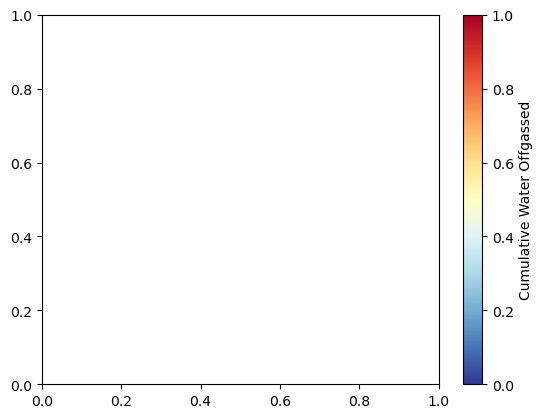

In [49]:
#for j, no in enumerate(['3','4']): # Plot Win-G from HDM and KAF
#    ax1.plot(Winsor_Data[f'He{no}HDM']['10^4/T'][:-1], Winsor_Data[f'He{no}HDM']['ln(D/a^2)'][:-1], linestyle='--', linewidth = 1, marker=['x','+'][j], color='g', label = f'HDM {no}He Data')
for j, no in enumerate(['3','4']):
    ax1.plot(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], linestyle='--', color = 'grey')
    ax1.scatter(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], marker=['x','+'][j], c=Diffdat['watercum'][:-1]/max(Diffdat['watercum']), cmap = 'RdYlBu_r', label = f'KAF {no}He Data')

cbar = plt.colorbar(mappable = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap='RdYlBu_r'))
cbar.set_label('Cumulative Water Offgassed')

In [36]:
## MC Diff Cell Data Reduction

def get_real_time(ID):
    with open(f'NGL Watlow Heat Log/DC{ID} Watlow.txt') as lines:
        return(float(lines.readlines()[-1].split('\t')[0])-25)

data_holder_MC = {}


""" 
DIFFCELL_name = '112123LVCOPyIrrOG.csv'#DIFFCELL_name
rest_4He = 7.27*2.34 # nccSTP 4He total_yield 
rest_3He = 51.77*2.34 # pccSTP 3He total_yield
OD = 1552/1E4
ID = 828/1E4
"""
DIFFCELL_name = '112123SalAspIrr.csv'#DIFFCELL_name
total_4He = 13.47*0.8 # nccSTP 4He total_yield 
total_3He = 51.77*0.8 # pccSTP 3He total_yield
OD = 967/1E4
ID = 533/1E4
DIFFCELL = pd.read_csv(DIFFCELL_name, header = None).to_numpy()
metadata = DIFFCELL[:,1]
TempKelvin = np.array([273+pull_number(str(datum).split(' ')[2]) for datum in metadata])
DIFFCELL = DIFFCELL[(TempKelvin>(273+70))*((TempKelvin>(370+273))+(TempKelvin<(220+273))),:]
DIFFCELL = DIFFCELL[(DIFFCELL[:,4]>0)*(DIFFCELL[:,6]>0),:]

G = 2/(np.log(OD/ID)*((ID/2)**2))

perm_model = 'modeled'
    
Ra = 1.39E-6
#sens4He = 2.29E-2 #ncc/fA
#sens3He = 5.28E-3 #pcc/cps





reducer = MCHeReducer('STD_nov.csv')
He3, He4 = reducer.reduce(DIFFCELL)



#CB_lim = 100 +273  # max temperature of cold blanks
#ignore_lim = 250 +273

Tcutoff = [30+273, 65+273, 225+273]

rest_He = [rest_3He, rest_4He]
metadata = DIFFCELL[:,1]
TimeSeconds = np.array([60*pull_number((str(datum).split(' ')[1]).split('_')[1]) for datum in metadata])
TempKelvin = np.array([273+pull_number(str(datum).split(' ')[2]) for datum in metadata])
TargetTemp = np.array([273+pull_number((str(datum).split(' ')[1]).split('_')[2]) for datum in metadata]) 
recordedTimeSeconds = np.array([get_real_time((str(datum).split(' ')[1]).split('_')[0]) for datum in metadata])
coldtimes = np.array([0] + list(extract_timesMC(DIFFCELL[:,2])))


He3signal = DIFFCELL[:,4].astype('float')
He4signal = (DIFFCELL[:,6].astype('float'))
#He3 = He3signal*sens3He # pccSTP
#He4 = He4signal*sens4He # nccSTP
signals = [He3signal, He4signal]
IR = np.array((He3/(He4*1E3))/Ra)
total_yields = []

for j, He in enumerate([He3,He4]):
    total_yield = [total_3He, total_4He][j]
    name = ['3He', '4He'][j]
    HenCC = He
    HenCC[HenCC < 0] = 0 
    Names = DIFFCELL[:,0]
    
    # Information for tube corrections
    n0_modeled = [] # calc for every cold blank, cold indices apply
    n1_modeled = []
    n0_measured = [] # calc for consectutive cold blanks, indices in Smeas
    n1_measured = []
    Smeas = [] #indices of consecutive cold blanks
    colds = [] #indices of all cold blanks
    Smeascolds = []
    M = [] #measured CB proportionality (1 - n1/n0)/sec

    # Diffusivity data
    fcum = []
    Fp = 0
    DC_indices = []
    D_a2 = []
    lnD_a2 = []
    n1_n0_mod = []
    n1_n0_mes = []

    ####
    HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
    ####
    prev_cold = 0
    prev_inter = 0
    cold_counter = -1
    total_colds = 0
    Rel_times = []
    
    for i, datum in enumerate(metadata):
        # First, manage permeability corrections
        if TempKelvin[i] < Tcutoff[2] :
            colds.append(i)
            cold_counter += 1  
            total_colds += 1
            if TempKelvin[i] > Tcutoff[1]: # Logic to only report values where temperature control is valid. Later model room temp as cooling curve
                if perm_model == 'modeled' or perm_model == 'modelled':
                    n1_n0_modeled = tube_permeate2(t = TimeSeconds[i], T = TempKelvin[i], ID = ID, OD = OD, He = name)
                elif perm_model == 'measured':
                    n1_n0_modeled = tube_permeate3(t = TimeSeconds[i], T = TempKelvin[i], K0G=K0G, Ea=Ea) 
            elif (TempKelvin[i] < Tcutoff[0]) and prev_cold > 0:
                if perm_model == 'modeled' or perm_model == 'modelled':
                    n1_n0_modeled = tube_permeate2(t = coldtimes[i], T = TempKelvin[i], ID = ID, OD = OD, He = name) 
                elif perm_model == 'measured':
                    n1_n0_modeled = tube_permeate3(t = coldtimes[i], T = TempKelvin[i], K0G=K0G, Ea=Ea) 
            else: 
                n1_n0_modeled = 0
                print(f'COLD {i} FELL THROUGH')
            n1_n0_mod.append(n1_n0_modeled)
            if n1_n0_modeled:
                n0_modeled.append(HenCC[i]/(1-n1_n0_modeled))
                n1_modeled.append(HenCC[i]/((1/n1_n0_modeled)-1))
            else:
                n0_modeled.append(0)
                n1_modeled.append(0)
            if ((prev_cold >= 2) and (TempKelvin[i] < Tcutoff[0])):# and (HenCC[i] > 0.0175)):
                Smeascolds.append(cold_counter)
                #Smeas.append(i-1)
                Smeas.append(i)
                Rel_times.append(coldtimes[i])
                n1_n0_measured = (HenCC[i]/coldtimes[i])/(HenCC[i-1]/coldtimes[i-1]) # Assume unchanging abundance, time normalize
                m = (1 - n1_n0_measured)/np.mean([coldtimes[i], coldtimes[i-1]]) # Assume n1/n0 linear: no significant degassing
                #n0_measured.append(HenCC[i-1]/(m*coldtimes[i-1]))
                #n1_measured.append(HenCC[i-1]/((1/(1-(m*coldtimes[i-1]))-1)))
                n0_measured.append(HenCC[i]/(m*coldtimes[i]))
                n1_measured.append(HenCC[i]/((1/(1-(m*coldtimes[i]))-1)))
                n1_n0_mes.append(n1_n0_measured)
                M.append(m)
                #M.append(m)
            elif ((prev_inter >= 1) and ((TempKelvin[i] > Tcutoff[1]) and (np.abs(TempKelvin[i] - TempKelvin[i-1]) < 2))):# and (HenCC[i] > 0.01)):
                Smeascolds.append(cold_counter)
                Rel_times.append(TimeSeconds[i])
                #Smeas.append(i-1)
                Smeas.append(i)
                n1_n0_measured = (HenCC[i]/TimeSeconds[i])/(HenCC[i-1]/TimeSeconds[i-1]) # Assume unchanging abundance, time normalize
                m = (1 - n1_n0_measured)/np.mean([TimeSeconds[i], TimeSeconds[i-1]]) # Assume n1/n0 linear: no significant degassing
                #n0_measured.append(HenCC[i-1]/(m*coldtimes[i-1]))
                #n1_measured.append(HenCC[i-1]/((1/(1-(m*coldtimes[i-1]))-1)))
                n0_measured.append(HenCC[i]/(m*TimeSeconds[i]))
                n1_measured.append(HenCC[i]/((1/(1-(m*TimeSeconds[i]))-1)))
                n1_n0_mes.append(n1_n0_measured)
                M.append(m)

            if (TempKelvin[i] < (Tcutoff[0]+40)):
                prev_cold += 1
                prev_inter = 0
            else:
                prev_inter += 1
                prev_cold = 0

            Names[i] = str(total_colds)+' in sequence ' + metadata[i]
        else:
            prev_cold = 0
            prev_inter = 0
            total_colds = 0

    n1_measured = np.array(n1_measured)
    n0_measured = np.array(n0_measured)
    n1_modeled = np.array(n1_modeled)
    n0_modeled = np.array(n0_modeled)

    n1_measured_out = np.zeros_like(n1_modeled)
    n1_measured_out[Smeascolds] = n1_measured
    n0_measured_out = np.zeros_like(n0_modeled)
    n0_measured_out[Smeascolds] = n0_measured
    n1_n0_mes_out = np.zeros_like(n0_modeled)
    n1_n0_mes_out[Smeascolds] = n1_n0_mes

    #molHe = HenCC/(22.4*1E12) #convert from nccSTP to moles
    #PHeATM = ((molHe*RccATM*TempKelvin)/V)
    #PHe = (PHeATM/1.01325)*1E6 # Conv. Atmospheres to microbars

    lambdas = -np.log((np.array(n1_measured)/np.array(n0_measured)))/(TempKelvin[Smeas]*Rel_times*Ratoms)
    K_meas = (lambdas*np.log(OD/ID)*((ID/2)**2))/2
    K_ref = []

    for Temp in TempKelvin[Smeas]:
        K_ref.append(swets_K(Temp))
    DK_swets = np.log(K_meas)-np.log(np.array(K_ref))
    lnlambdas = np.log(lambdas)
    lambdas_out = np.zeros_like(n0_modeled)
    lnlambdas_out = np.zeros_like(n0_modeled)
    lambdas_out[Smeascolds] = lambdas
    lnlambdas_out[Smeascolds] = lnlambdas
    K_meas_out = np.zeros_like(n0_modeled)
    DK_swets_out = np.zeros_like(n0_modeled)
    K_meas_out[Smeascolds] = np.array(K_meas)
    DK_swets_out[Smeascolds] = DK_swets

    """
    plt.scatter(HenCC[Smeas]/coldtimes[Smeas], M, c = PHe[Smeas])
    for H, hen in enumerate(HenCC[Smeas]/coldtimes[Smeas]):
        plt.text(hen, M[H], Smeas[H])
    plt.ylabel('M (1-(n1/n0))/sec')
    plt.xlabel('Permeation rate (nccSTP/sec)')
    cbar = plt.colorbar()
    cbar.set_label('Pressure (Microbars)')
    plt.ylim((0,max(M)))
    plt.show()

    plt.scatter(1E4/TempKelvin[Smeas], np.log(lambdas), c = HenCC[Smeas])
    plt.ylabel('ln(Lambda) ((K*A)/(V*d)) (atoms /sec /atm /cm^3)')
    plt.xlabel('10^4/T (K)')
    plt.title('Simultaneous measurements of K and geometric factor')
    cbar = plt.colorbar()
    cbar.set_label('4He Yield (nccSTP)')
    plt.show()

    #plt.scatter(Smeas, M, c = PHe[Smeas], label = 'Consecutive Cold Blank Measured M')
    plt.scatter(Smeas, (1-(np.array(n1_measured)/np.array(n0_measured)))/coldtimes[Smeas], c = PHe[Smeas], label = 'Consecutive Cold Blank Measured M')
    plt.plot(colds, (1-(np.array(n1_modeled)/np.array(n0_modeled)))/coldtimes[colds], color = 'k', label = 'Permeability Modelled M')
    plt.ylabel('M (1-(n1/n0))/sec')
    plt.xlabel('Analysis Number')
    plt.ylim((0,max((1-(np.array(n1_measured)/np.array(n0_measured)))/coldtimes[Smeas])))
    plt.legend()
    cbar = plt.colorbar()
    cbar.set_label('Pressure (Microbars)')
    plt.show()

    plt.scatter((n1_measured/n0_measured)-(n1_modeled/n0_modeled)[Smeascolds], (n0_measured-n1_measured)-HenCC[Smeas], c = PHe[Smeas], label = 'Consecutive Cold Blank Measured M')
    #plt.scatter(colds, (n0_modeled-n1_modeled)-HenCC[colds], color = 'k', label = 'Permeability Modelled M', marker = '+')
    plt.ylabel('Residuals: m-(n0-n1)')
    plt.xlabel('n1/n0 measured - n1/n0 modelled')
    cbar = plt.colorbar()
    cbar.set_label('Pressure (Microbars)')
    plt.show()

    plt.scatter(colds, (n0_modeled-n1_modeled)-HenCC[colds], c = PHe[colds], label = 'Permeability Modelled M', marker = '+')
    plt.scatter(Smeas, (n0_measured-n1_measured)-HenCC[Smeas], c = PHe[Smeas], label = 'Permeability Modelled M', marker = 'o')
    plt.ylabel('Residuals: m-(n0-n1)')
    plt.xlabel('Analysis Number')
    plt.legend()
    cbar = plt.colorbar()
    cbar.set_label('Pressure (Microbars)')
    plt.show()
    """


    """    plt.scatter(1E4/TempKelvin[Smeas], DK_swets, c = HenCC[Smeas])
    plt.ylabel('Delta K (wrt Swets et al.)')
    plt.xlabel('10^4/T (K)')
    plt.title('Delta K plot')
    cbar = plt.colorbar()
    cbar.set_label('4He Yield (nccSTP)')
    plt.show()

    plt.plot(1E4/TempKelvin[Smeas], np.log(np.array(K_ref)*(2/(np.log(OD/ID)*((ID/2)**2)))), label = 'Swets et al K and Measured Geometry')
    plt.plot(1E4/TempKelvin[Smeas], np.log(K0G*np.exp(-Ea/(Rcal*TempKelvin[Smeas]))), linestyle = '--', label = 'Used Values')
    plt.scatter(1E4/TempKelvin[Smeas], lnlambdas, c = HenCC[Smeas], label = 'Measured K(G)')
    plt.ylabel('Lambda')
    plt.xlabel('10^4/T (K)')
    plt.title('Lambda plot')
    plt.legend()
    cbar = plt.colorbar()
    cbar.set_label('4He Yield (nccSTP)')
    plt.savefig(DIFFCELL_name[:-4] + 'LambdaPlot' + '.jpg', dpi = 256)
    plt.show()"""

    data = [np.array(Names)[colds].tolist(), (TempKelvin[colds]-273).tolist(), (TimeSeconds[colds]).tolist(), coldtimes[colds], recordedTimeSeconds[colds], lambdas_out, n1_n0_mod, n1_n0_mes_out, n0_modeled, n0_measured_out, n1_modeled, n1_measured_out, HenCC[colds], K_meas_out, DK_swets_out, 1E4/TempKelvin[colds], lnlambdas_out]
    columns = ['Names', 'Temp (C)', ' Nominal/Hot Time (sec)', 'Total/Cold Time (sec)', 'Watlow Times (sec)', 'lambda', 'n1/n0 modeled', 'n1/n0 measured', 'n0_modeled', 'n0_measured', 'n1_modeled', 'n1_measured', 'He Measured (nCC@STP)', 'K measured (atoms/atm/cm/sec)', 'Delta K (ln(K_swets)-ln(K_meas))', '10^4/T (K)', 'ln(lambda)']
    Reduced_Data = pd.DataFrame()
    for k, column in enumerate(columns):
        Reduced_Data[column] = data[k]
    newDiffName = DIFFCELL_name[:-4] + name + '_COLDS_TubeReduced' + '.csv'
    Reduced_Data.to_csv(newDiffName)
    print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

    HTind = []
    prev_cold = 0
    n0 = [] # Values For correction
    n1 = []
    prev_hot = 1

    for i, measured in reversed(list(enumerate(HenCC))): # Traverse steps in reverse, second/last cold step always proper temp.
    #for i, measured in enumerate(HenCC):
        # First, manage permeability correction
        if TempKelvin[i] < Tcutoff[2]:
            prev_hot = 0
            if prev_cold == 0:
                #print(n0_modeled[np.array(colds) == i])
                n1.append(n0_modeled[np.array(colds) == i][0]) # Collect tube contents after previous HT step
                n0.append(n1_modeled[np.array(colds) == i][0]) # Collect tube contents preceding next HT step
            else:
                n1[-1] += measured # Account for permeate lost during cold steps
            prev_cold += 1
        else:
            prev_cold = 0
            if prev_hot:
                n0.append(-1) # Make placeholders for high temperature corrections
                n1.append(-1)
            prev_hot +=1
            HTind.append(i)
    if prev_hot:
        n0.append(0) # if no tube measurement before run, assume empty tube
        n1.append(0)
        print('No initial cold permeation, assuming n0=0')
    HTind.reverse()
    n0.reverse()
    n1.reverse()
    print(f"n1:{n1}")
    print(f"n0:{n0}")
    HTind = np.array(HTind)
    n0 = np.array(n0)[:-1]
    n1 = np.array(n1)[1:]
    print(len(n1))
    print(len(HenCC))
    
    corrtype = ['Cold Correction'] * len(HTind)
    
    for k, ind in enumerate(HTind): #High Temperature corrections when low T measurements weren't made
        if n1[k] < 0:
            corrtype[k] = 'Hot Correction'
            measured = HenCC[ind]
            temp = TempKelvin[ind]
            time = TimeSeconds[ind]
            Beta = time*temp*Ratoms*G*swets_K(temp)
            if name == '3He':
                Beta *= Jones(temp)
            hotCorr = ((((measured-n0[k])/Beta)*(1-np.exp(-Beta))) + (n0[k]*np.exp(-Beta))) / (1 - ((1/Beta)*(1-np.exp(-Beta))))
            n1[k] = hotCorr
            if k < (len(HTind)-1):
                n0[k+1] = hotCorr
            
            


    """
                denom = TimeSeconds[j]*temp*Ratoms*G*swets_K(temp)
                if name == '3He':
                    #print(Jones(temp))
                    denom *= Jones(temp)
                if len(n1) == 0:
                    n1.append((He[j]/denom)/(1-(1/denom)))
                else:
                    n1.append(((He[j]-n1[-1])/denom)/(1-(1/denom)))
    

    for j, temp in enumerate(TempKelvin):
        if temp >= Tcutoff[2]:
            denom = TimeSeconds[j]*temp*Ratoms*G*swets_K(temp)
            print(f"for step {j} for {TimeSeconds[j]/3600} hours at {temp-273}C we have a yield of {HenCC[j]}nCC and get a denominator {denom}")
            print(f'previous n1: {n1HT[-1]}')
            n1HT.append(((HenCC[j]-n1HT[-1])/denom)/(1-(1/denom)))   
            print(f"We calculate an n1 of {n1HT[-1]} with a cold bracket calculation of {n1[counter]}\n")
    """
    HT_corr = np.array(HenCC)[HTind] + n1 - n0 # Correct high temperature steps for gas inside tube before and after high temperature steps
    HT_corr[HT_corr < 0] = 0 
    
    #total_yield = np.sum(He)+rest_He[i]
    total_yields.append(total_yield)
    
    for j, step_yield in enumerate(HT_corr):
        F = Fp + (step_yield/total_yield)
        frequency_factor = InvertFrequencyFactor(t = TimeSeconds[HTind][j], F = F, Fp = Fp)
        D_a2.append(frequency_factor)
        lnD_a2.append(np.log(frequency_factor))
        #blank_corrected_yield.append(step_yield)
        #DC_indices.append(j)
        fcum.append(F)
        Fp = F

    #DC_indices = np.array(DC_indices)
    #data = [np.array(Names)[DC_indices].tolist(), (TempKelvin[DC_indices]-273).tolist(), (TimeSeconds[DC_indices]*60).tolist(), blank_corrected_yield, fcum, D_a2, lnD_a2, (10000/TempKelvin[DC_indices]).tolist()]
    data = [DIFFCELL[HTind,1], (TempKelvin[HTind]-273).tolist(), (TimeSeconds[HTind]/60).tolist(), (recordedTimeSeconds[HTind]/60).tolist(), He[HTind], HT_corr, fcum, D_a2, (10000/TempKelvin[HTind]).tolist(), lnD_a2, n0, n1, corrtype]
    columns = ['Names','Temp (C)', 'Time (min)', 'Recorded Time (min)',  f"{name} measured ({['p','n'][i]}CC@STP)", f"Corrected {name} Yield ({['p','n'][i]}CC@STP)", 'Fcum', 'D/a^2 ', '10^4/T', 'ln(D/a^2)', 'n0', 'n1', 'n1 Correction Type']
    Reduced_Data = pd.DataFrame()
    for j, column in enumerate(columns):
        Reduced_Data[column] = data[j]
    newDiffName = DIFFCELL_name[:-4] + '_' + name +'_reduced' + '.csv'
    data_holder_MC[name] = Reduced_Data
    Reduced_Data.to_csv(newDiffName)
    print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

    min_T = np.min(10000/TempKelvin[HTind])
    max_T = np.max(10000/TempKelvin[HTind])
    fig = plt.figure()
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twiny()

    Ctemps = np.linspace(200,700, 11,dtype = int)
    ax1.plot(10000/TempKelvin[HTind], np.array(lnD_a2), linestyle='--')
    ax1.scatter(10000/TempKelvin[HTind], np.array(lnD_a2))#, c = np.log10(IR[real_steps][good_steps]), label = 'Data')
    plt.title(f"Diffusivity Inversion for {name}\nTotal Yield = {total_yield} {['p','n'][i]}cc's")

    #reference_D0_a2 = [(10**0.9)/((212/10000)**2), (10**2.1)/((180/10000)**2), np.exp(1.1939)] # /sec
    #reference_Ea = [33000, 33000, 14701*1.987] # cal /mol

    """
    reference_names = ['200 um LVCO Pyrite', 'Apatite r=250 um','Tc = 93.6 C','Tc = 104.8 C','Tc = 134.6 C','Tc = 146.7 C', 'Tc = 112.8']
    R = 1.98 #cal /mol /T(K)
    reference_D0_a2 = [np.exp(4.2623), (10**1.5)/((250/10000)**2)]#,1.84,0.03,3.81,6.96] # /sec
    reference_Ea = [(R*2.2015*10000), 33000]#,26030,23845,29607,30997] # cal /mol

    if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
        T = [min_T, max_T]
        for j, D0_a2 in enumerate(reference_D0_a2):
            Ea = reference_Ea[j]
            min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
            max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
            plt.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[j])
            #print(T, min_log_frequency_factor, max_log_frequency_factor)"""

    ax2.set_xticks(1E4/(Ctemps+273))
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticklabels(Ctemps)
    ax2.set_xlabel('Temperature (C)')
    ax1.set_xlabel('10^4/T(K)')
    ax1.set_ylabel('ln(D_a2) (sec^-1)')
    plt.legend(fontsize = 10)
    plt.savefig(newDiffName+'.svg')
    plt.show()
    """
        fcum = np.array(fcum)
    
    reference_Diff = np.log(reference_D0_a2[0]*np.exp(-reference_Ea[0]/((realTempKelvin)*R)))
    plt.axhline(0, color = 'k')
    delta_Diff = np.array(lnD_a2)[good_steps] - reference_Diff[good_steps]
    plt.plot(fcum[good_steps], delta_Diff)
    plt.scatter(fcum[good_steps], delta_Diff, c = np.log10(IR[real_steps][good_steps]))
    cbar = plt.colorbar()
    cbar.set_label('3/4He (Ra)')
    plt.show()
    """


Assuming all standards analyzed had 157.5 nCCSTP 4He and 3.57 pCCSTP 3He
Done! Output file: 112123SalAspIrr3He_COLDS_TubeReduced.csv in C:\Users\dashf\pyrite
n1:[0.2015863391675894, 0.0037500685931401404, -1, -1, -1, 0.10806915444946648, -1, -1, 0.01798970305224992, 0.006683551561000512, 0.01039211379991077, 0.013371706704426565, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
n0:[0.0033924533543616296, 0.002522912184551149, -1, -1, -1, 0.07267064367997679, -1, -1, 0.012153036385583254, 0.004496218227667179, 0.006991442923736739, 0.00899647974014979, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
54
74


C:\Users\dashf\AppData\Local\Temp\ipykernel_11800\3938631252.py:185: RuntimeWarning: invalid value encountered in log
  lambdas = -np.log((np.array(n1_measured)/np.array(n0_measured)))/(TempKelvin[Smeas]*Rel_times*Ratoms)
C:\Users\dashf\AppData\Local\Temp\ipykernel_11800\3938631252.py:191: RuntimeWarning: invalid value encountered in log
  DK_swets = np.log(K_meas)-np.log(np.array(K_ref))
C:\Users\dashf\AppData\Local\Temp\ipykernel_11800\3938631252.py:192: RuntimeWarning: invalid value encountered in log
  lnlambdas = np.log(lambdas)
C:\Users\dashf\AppData\Local\Temp\ipykernel_11800\3938631252.py:368: RuntimeWarning: divide by zero encountered in log
  lnD_a2.append(np.log(frequency_factor))


PermissionError: [Errno 13] Permission denied: '112123SalAspIrr_3He_reduced.csv'

In [3]:
print(TempKelvin[colds])



print(HenCC)
print(len(HenCC))
print(He)
print(HTind)
print(len(HTind))
print(n1)
print(len(n1))
print(len(coldtimes))
print(len(colds))
print(recordedTimeSeconds)
for i, measured in reversed(list(enumerate(HenCC))):
    if i:
        print(f"{i}: {measured}")

[296.   373.4  296.97 296.98 373.   297.   297.   297.   473.06 299.25
 297.   296.   373.4  296.97 296.98 373.   297.   297.   297.   473.06
 299.25 297.   473.02 299.18 297.   309.   297.   309.98 298.02 305.45
 298.   297.96 298.   297.51 298.   307.06 299.   297.88 297.06 297.
 297.   311.18 298.57 302.51 298.   310.33 298.   473.04 473.06 473.05
 473.05 473.04 473.04 472.99 472.99 472.98 472.99 472.98 472.9  472.89
 472.97 472.98 472.99 472.92 472.11 472.91 472.9  472.89]
[4.09939442e-01 3.87976673e+00 1.65833214e-01 1.52910673e-01
 2.29993969e+00 1.10865991e-01 1.46359269e-01 1.01463456e-01
 3.31217830e+00 6.08393931e-02 5.19328207e-02 4.09939442e-01
 3.87976673e+00 1.65833214e-01 1.52910673e-01 2.29993969e+00
 1.10865991e-01 1.46359269e-01 1.01463456e-01 3.31217830e+00
 6.08393931e-02 5.19328207e-02 1.97949004e+00 1.54690311e-02
 6.01631024e-03 4.02083870e-01 4.40924578e-02 5.47027291e-03
 8.65064594e-02 0.00000000e+00 1.44928427e-02 2.71047508e-02
 9.51670771e-04 0.00000000e+00

In [ ]:
## MC Diff Cell Data Reduction

def get_real_time(ID):
    with open(f'NGL Watlow Heat Log/DC{ID} Watlow.txt') as lines:
        return(float(lines.readlines()[-1].split('\t')[0])-25)

data_holder_MC = {}

"""Diffusion Cell Data Reduction"""
rest_4He = 7.27*2.34 # nccSTP 4He total_yield 
rest_3He = 51.77*2.34 # pccSTP 3He total_yield
OD = 1552/1E4
ID = 828/1E4

G = 2/(np.log(OD/ID)*((ID/2)**2))

 
Ra = 1.39E-6
#sens4He = 2.29E-2 #ncc/fA
#sens3He = 5.28E-3 #pcc/cps
DIFFCELL_name = '112123LVCOPyIrr.csv'#DIFFCELL_name
DIFFCELL = pd.read_csv(DIFFCELL_name, header = None).to_numpy()

summer_reducer = MCHeReducer('STD_nov.csv')
He3, He4 = summer_reducer.reduce(DIFFCELL)

CB_lim = 100 +273  # max temperature of cold blanks
ignore_lim = 250 +273


rest_He = [rest_3He, rest_4He]
metadata = DIFFCELL[:,1]
TimeSeconds = np.array([60*pull_number((str(datum).split(' ')[1]).split('_')[1]) for datum in metadata])
TempKelvin = np.array([273+pull_number(str(datum).split(' ')[2]) for datum in metadata])
TargetTemp = np.array([273+pull_number((str(datum).split(' ')[1]).split('_')[2]) for datum in metadata]) 
recordedTimeSeconds = np.array([get_real_time((str(datum).split(' ')[1]).split('_')[0]) for datum in metadata])

He3signal = DIFFCELL[:,4].astype('float')
He4signal = (DIFFCELL[:,6].astype('float'))
#He3 = He3signal*sens3He # pccSTP
#He4 = He4signal*sens4He # nccSTP
signals = [He3signal, He4signal]
IR = np.array((He3/(He4*1E3))/Ra)
total_yields = []

for i, He in enumerate([He3,He4]):
    n1 = []
    n1C = []
    HeM = np.copy(He)
    name = ['3He', '4He'][i]
    signal = signals[i]
    #print(He)
    ## add reextracts, do blank corrections
    CB = 0
    real_i = False
    real_steps = []
    good_steps = []
    for j, temp in enumerate(TempKelvin):
        if temp < ignore_lim:
            #He[j-1] += He[j]
            n1C[-1] = He[j]
            print(f"ignoring {name} step {j}, real temp: {temp}, target temp: {TargetTemp[j]} with signal {signal[j]}")
        else:
            real_steps.append(j)
            denom = TimeSeconds[j]*temp*Ratoms*G*swets_K(temp)
            if name == '3He':
                #print(Jones(temp))
                denom *= Jones(temp)
            if len(n1) == 0:
                n1.append((He[j]/denom)/(1-(1/denom)))
            else:
                n1.append(((He[j]-n1[-1])/denom)/(1-(1/denom)))
            n1C.append(0)
            if len(n1) == 1:
                He[j] += n1[-1]
            else:
                He[j] += (n1[-1] - n1[-2])
            if np.abs(temp-TargetTemp[j]) < 1 and temp > ignore_lim: #Bad Temperature Control; exclude from reduced data, but do count towards total yields
            #He[j] -= CB #Bad cold blanks on first round of MC Sulfide diffusions, commented out
                good_steps.append(1)
            else:
                good_steps.append(0)

    good_steps = np.array(good_steps).astype(bool)
    real_steps = np.array(real_steps)

    realTempKelvin = TempKelvin[real_steps]
    realTimeSeconds = TimeSeconds[real_steps]
    realLogTime = recordedTimeSeconds[real_steps]
    HenCC = He[real_steps]
    ##


    fcum = []
    Fp = 0
    #DC_indices = []
    D_a2 = []
    lnD_a2 = []

    ####
    HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
    ####
    
    total_yield = np.sum(He)+rest_He[i]
    total_yields.append(total_yield)
    
    for j, step_yield in enumerate(HenCC):
        F = Fp + (step_yield/total_yield)
        frequency_factor = InvertFrequencyFactor(t = realTimeSeconds[j], F = F, Fp = Fp)
        D_a2.append(frequency_factor)
        lnD_a2.append(np.log(frequency_factor))
        #blank_corrected_yield.append(step_yield)
        #DC_indices.append(j)
        fcum.append(F)
        Fp = F

    #DC_indices = np.array(DC_indices)
    #data = [np.array(Names)[DC_indices].tolist(), (TempKelvin[DC_indices]-273).tolist(), (TimeSeconds[DC_indices]*60).tolist(), blank_corrected_yield, fcum, D_a2, lnD_a2, (10000/TempKelvin[DC_indices]).tolist()]
    data = [(realTempKelvin-273).tolist(), (realTimeSeconds/60).tolist(), (realLogTime/60).tolist(), HeM[real_steps], HenCC.tolist(), fcum, D_a2, (10000/realTempKelvin).tolist(), lnD_a2, n1, n1C, good_steps]
    columns = ['Temp (C)', 'Time (min)', 'Recorded Time (min)',  f"{name} measured ({['p','n'][i]}CC@STP)", f"Corrected {name} Yield ({['p','n'][i]}CC@STP)", 'Fcum', 'D/a^2 ', '10^4/T', 'ln(D/a^2)', 'n1', 'n1 by prev measure', 'good_steps']
    Reduced_Data = pd.DataFrame()
    for j, column in enumerate(columns):
        Reduced_Data[column] = data[j]
    newDiffName = DIFFCELL_name[:-4] + '_' + name +'_reduced' + '.csv'
    data_holder_MC[name] = Reduced_Data
    Reduced_Data.to_csv(newDiffName)
    print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

    min_T = np.min(10000/realTempKelvin[good_steps])
    max_T = np.max(10000/realTempKelvin[good_steps])
    fig = plt.figure()
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twiny()

    Ctemps = np.linspace(200,700, 11,dtype = int)
    ax1.plot(10000/realTempKelvin[good_steps], np.array(lnD_a2)[good_steps], linestyle='--')
    ax1.scatter(10000/realTempKelvin[good_steps], np.array(lnD_a2)[good_steps], c = np.log10(IR[real_steps][good_steps]), label = 'Data')
    plt.title(f"Diffusivity Inversion for {name}\nTotal Yield = {total_yield} {['p','n'][i]}cc's")

    #reference_D0_a2 = [(10**0.9)/((212/10000)**2), (10**2.1)/((180/10000)**2), np.exp(1.1939)] # /sec
    #reference_Ea = [33000, 33000, 14701*1.987] # cal /mol

    """
    reference_names = ['200 um LVCO Pyrite', 'Apatite r=250 um','Tc = 93.6 C','Tc = 104.8 C','Tc = 134.6 C','Tc = 146.7 C', 'Tc = 112.8']
    R = 1.98 #cal /mol /T(K)
    reference_D0_a2 = [np.exp(4.2623), (10**1.5)/((250/10000)**2)]#,1.84,0.03,3.81,6.96] # /sec
    reference_Ea = [(R*2.2015*10000), 33000]#,26030,23845,29607,30997] # cal /mol

    if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
        T = [min_T, max_T]
        for j, D0_a2 in enumerate(reference_D0_a2):
            Ea = reference_Ea[j]
            min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
            max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
            plt.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[j])
            #print(T, min_log_frequency_factor, max_log_frequency_factor)"""

    ax2.set_xticks(1E4/(Ctemps+273))
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticklabels(Ctemps)
    ax2.set_xlabel('Temperature (C)')
    ax1.set_xlabel('10^4/T(K)')
    ax1.set_ylabel('ln(D_a2) (sec^-1)')
    plt.legend(fontsize = 10)
    plt.savefig(newDiffName+'.svg')
    plt.show()
    
    fcum = np.array(fcum)
    
    reference_Diff = np.log(reference_D0_a2[0]*np.exp(-reference_Ea[0]/((realTempKelvin)*R)))
    plt.axhline(0, color = 'k')
    delta_Diff = np.array(lnD_a2)[good_steps] - reference_Diff[good_steps]
    plt.plot(fcum[good_steps], delta_Diff)
    plt.scatter(fcum[good_steps], delta_Diff, c = np.log10(IR[real_steps][good_steps]))
    cbar = plt.colorbar()
    cbar.set_label('3/4He (Ra)')
    plt.show()

C:\Users\dashf\AppData\Local\Temp\ipykernel_25752\3307486742.py:111: RuntimeWarning: invalid value encountered in log
  lnD_a2.append(np.log(frequency_factor))
C:\Users\dashf\AppData\Local\Temp\ipykernel_25752\3307486742.py:137: RuntimeWarning: invalid value encountered in log10
  ax1.scatter(10000/realTempKelvin[good_steps], np.array(lnD_a2)[good_steps], c = np.log10(IR[real_steps][good_steps]), label = 'Data')
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Assuming all standards analyzed had 157.5 nCCSTP 4He and 3.57 pCCSTP 3He
ignoring 3He step 1, real temp: 473.15, target temp: 473.0 with signal 0.0034
ignoring 3He step 3, real temp: 473.15, target temp: 473.0 with signal 0.177
ignoring 3He step 5, real temp: 473.14, target temp: 473.0 with signal 0.0199
ignoring 3He step 7, real temp: 473.14, target temp: 473.0 with signal 0.133
ignoring 3He step 9, real temp: 473.13, target temp: 473.0 with signal 0.0107
ignoring 3He step 11, real temp: 473.13, target temp: 473.0 with signal 0.025
ignoring 3He step 13, real temp: 473.14, target temp: 473.0 with signal 0.0
ignoring 3He step 15, real temp: 473.22, target temp: 473.0 with signal 0.0
ignoring 3He step 18, real temp: 473.22, target temp: 473.0 with signal 0.0
ignoring 3He step 20, real temp: 473.12, target temp: 473.0 with signal 0.305
ignoring 3He step 23, real temp: 473.12, target temp: 473.0 with signal 0.193
ignoring 3He step 25, real temp: 473.23, target temp: 473.0 with signal 0.077

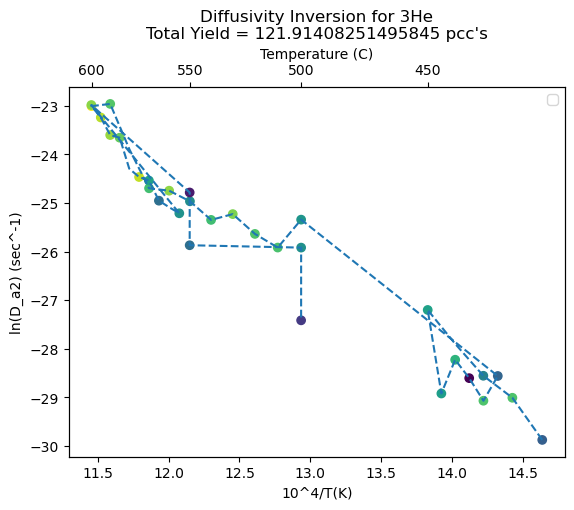

NameError: name 'reference_D0_a2' is not defined

In [11]:
## MC Diff Cell Data Reduction

def get_real_time(ID):
    with open(f'NGL Watlow Heat Log/DC{ID} Watlow.txt') as lines:
        return(float(lines.readlines()[-1].split('\t')[0])-25)

data_holder_MC = {}

"""Diffusion Cell Data Reduction"""
rest_4He = 7.27*2.34 # nccSTP 4He total_yield 
rest_3He = 51.77*2.34 # pccSTP 3He total_yield
OD = 1552/1E4
ID = 828/1E4

G = 2/(np.log(OD/ID)*((ID/2)**2))

 
Ra = 1.39E-6
#sens4He = 2.29E-2 #ncc/fA
#sens3He = 5.28E-3 #pcc/cps
DIFFCELL_name = '112123LVCOPyIrr.csv'#DIFFCELL_name
DIFFCELL = pd.read_csv(DIFFCELL_name, header = None).to_numpy()

summer_reducer = MCHeReducer('STD_nov.csv')
He3, He4 = summer_reducer.reduce(DIFFCELL)

CB_lim = 250 +273  # max temperature of cold blanks



rest_He = [rest_3He, rest_4He]
metadata = DIFFCELL[:,1]
TimeSeconds = np.array([60*pull_number((str(datum).split(' ')[1]).split('_')[1]) for datum in metadata])
TempKelvin = np.array([273+pull_number(str(datum).split(' ')[2]) for datum in metadata])
TargetTemp = np.array([273+pull_number((str(datum).split(' ')[1]).split('_')[2]) for datum in metadata]) 
recordedTimeSeconds = np.array([get_real_time((str(datum).split(' ')[1]).split('_')[0]) for datum in metadata])

He3signal = DIFFCELL[:,4].astype('float')
He4signal = (DIFFCELL[:,6].astype('float'))
#He3 = He3signal*sens3He # pccSTP
#He4 = He4signal*sens4He # nccSTP
signals = [He3signal, He4signal]
IR = np.array((He3/(He4*1E3))/Ra)
total_yields = []

for i, He in enumerate([He3,He4]):
    n1 = []
    n1C = []
    HeM = np.copy(He)
    name = ['3He', '4He'][i]
    signal = signals[i]
    #print(He)
    ## add reextracts, do blank corrections
    CB = 0
    real_i = False
    real_steps = []
    good_steps = []
    for j, temp in enumerate(TempKelvin):
        if temp < ignore_lim:
            #He[j-1] += He[j]
            n1C[-1] = He[j]
            print(f"ignoring {name} step {j}, real temp: {temp}, target temp: {TargetTemp[j]} with signal {signal[j]}")
        else:
            real_steps.append(j)
            denom = TimeSeconds[j]*temp*Ratoms*G*swets_K(temp)
            if name == '3He':
                #print(Jones(temp))
                denom *= Jones(temp)
            if len(n1) == 0:
                n1.append((He[j]/denom)/(1-(1/denom)))
            else:
                n1.append(((He[j]-n1[-1])/denom)/(1-(1/denom)))
            n1C.append(0)
            if len(n1) == 1:
                He[j] += n1[-1]
            else:
                He[j] += (n1[-1] - n1[-2])
            if np.abs(temp-TargetTemp[j]) < 1 and temp > ignore_lim: #Bad Temperature Control; exclude from reduced data, but do count towards total yields
            #He[j] -= CB #Bad cold blanks on first round of MC Sulfide diffusions, commented out
                good_steps.append(1)
            else:
                good_steps.append(0)

    good_steps = np.array(good_steps).astype(bool)
    real_steps = np.array(real_steps)

    realTempKelvin = TempKelvin[real_steps]
    realTimeSeconds = TimeSeconds[real_steps]
    realLogTime = recordedTimeSeconds[real_steps]
    HenCC = He[real_steps]
    ##21


    fcum = []
    Fp = 0
    #DC_indices = []
    D_a2 = []
    lnD_a2 = []

    ####
    HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
    ####
    
    total_yield = np.sum(He)+rest_He[i]
    total_yields.append(total_yield)
    
    for j, step_yield in enumerate(HenCC):
        F = Fp + (step_yield/total_yield)
        frequency_factor = InvertFrequencyFactor(t = realTimeSeconds[j], F = F, Fp = Fp)
        D_a2.append(frequency_factor)
        lnD_a2.append(np.log(frequency_factor))
        #blank_corrected_yield.append(step_yield)
        #DC_indices.append(j)
        fcum.append(F)
        Fp = F

    #DC_indices = np.array(DC_indices)
    #data = [np.array(Names)[DC_indices].tolist(), (TempKelvin[DC_indices]-273).tolist(), (TimeSeconds[DC_indices]*60).tolist(), blank_corrected_yield, fcum, D_a2, lnD_a2, (10000/TempKelvin[DC_indices]).tolist()]
    data = [(realTempKelvin-273).tolist(), (realTimeSeconds/60).tolist(), (realLogTime/60).tolist(), HeM[real_steps], HenCC.tolist(), fcum, D_a2, (10000/realTempKelvin).tolist(), lnD_a2, n1, n1C, good_steps]
    columns = ['Temp (C)', 'Time (min)', 'Recorded Time (min)',  f"{name} measured ({['p','n'][i]}CC@STP)", f"Corrected {name} Yield ({['p','n'][i]}CC@STP)", 'Fcum', 'D/a^2 ', '10^4/T', 'ln(D/a^2)', 'n1', 'n1 by prev measure', 'good_steps']
    Reduced_Data = pd.DataFrame()
    for j, column in enumerate(columns):
        Reduced_Data[column] = data[j]
    newDiffName = DIFFCELL_name[:-4] + '_' + name +'_reduced' + '.csv'
    data_holder_MC[name] = Reduced_Data
    Reduced_Data.to_csv(newDiffName)
    print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

    min_T = np.min(10000/realTempKelvin[good_steps])
    max_T = np.max(10000/realTempKelvin[good_steps])
    fig = plt.figure()
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twiny()

    Ctemps = np.linspace(200,700, 11,dtype = int)
    ax1.plot(10000/realTempKelvin[good_steps], np.array(lnD_a2)[good_steps], linestyle='--')
    ax1.scatter(10000/realTempKelvin[good_steps], np.array(lnD_a2)[good_steps], c = np.log10(IR[real_steps][good_steps]), label = 'Data')
    plt.title(f"Diffusivity Inversion for {name}\nTotal Yield = {total_yield} {['p','n'][i]}cc's")

    #reference_D0_a2 = [(10**0.9)/((212/10000)**2), (10**2.1)/((180/10000)**2), np.exp(1.1939)] # /sec
    #reference_Ea = [33000, 33000, 14701*1.987] # cal /mol

    """
    reference_names = ['200 um LVCO Pyrite', 'Apatite r=250 um','Tc = 93.6 C','Tc = 104.8 C','Tc = 134.6 C','Tc = 146.7 C', 'Tc = 112.8']
    R = 1.98 #cal /mol /T(K)
    reference_D0_a2 = [np.exp(4.2623), (10**1.5)/((250/10000)**2)]#,1.84,0.03,3.81,6.96] # /sec
    reference_Ea = [(R*2.2015*10000), 33000]#,26030,23845,29607,30997] # cal /mol

    if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
        T = [min_T, max_T]
        for j, D0_a2 in enumerate(reference_D0_a2):
            Ea = reference_Ea[j]
            min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
            max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
            plt.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[j])
            #print(T, min_log_frequency_factor, max_log_frequency_factor)"""

    ax2.set_xticks(1E4/(Ctemps+273))
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticklabels(Ctemps)
    ax2.set_xlabel('Temperature (C)')
    ax1.set_xlabel('10^4/T(K)')
    ax1.set_ylabel('ln(D_a2) (sec^-1)')
    plt.legend(fontsize = 10)
    plt.savefig(newDiffName+'.svg')
    plt.show()
    
    fcum = np.array(fcum)
    
    reference_Diff = np.log(reference_D0_a2[0]*np.exp(-reference_Ea[0]/((realTempKelvin)*R)))
    plt.axhline(0, color = 'k')
    delta_Diff = np.array(lnD_a2)[good_steps] - reference_Diff[good_steps]
    plt.plot(fcum[good_steps], delta_Diff)
    plt.scatter(fcum[good_steps], delta_Diff, c = np.log10(IR[real_steps][good_steps]))
    cbar = plt.colorbar()
    cbar.set_label('3/4He (Ra)')
    plt.show()

In [113]:
Ratoms

1.36e-22

Done! Output file: Batch 56_reduced.csv in C:\Users\dashf\pyrite
Done! Output file: Batch 55_clarity_reduced.csv in C:\Users\dashf\pyrite
9.75617021910422
21.225255820188572
33000
[9.75617021910422, 21.225255820188572] -6.814941511907985 -25.930084180381904
60946.46271510516
[11, 16] -13.3591459528362 -28.74966684048902


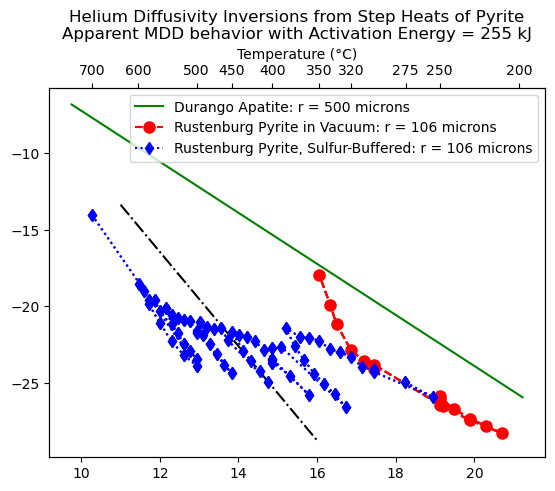

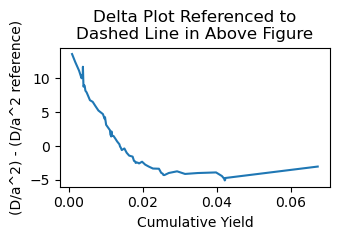

In [670]:
"""Diffusion Cell Data Reduction"""
total_yield = 200 #total_yield # defined in control panel, can be toggled here. 
DIFFCELL_name = 'Batch 56.csv'#DIFFCELL_name
DIFFCELL = pd.read_csv(DIFFCELL_name)

low_T_RE_threshold = 201 # Max temperature of reextract steps in C, 0 for no consideration of reextracts

try:
    TempKelvin = 273+DIFFCELL['Avg Temp'].to_numpy()
    TimeSeconds = 60*DIFFCELL['Time (min)'].to_numpy()
except:
    TempKelvin = 273+DIFFCELL['CIT RefNo'].to_numpy()
    TimeSeconds = 60*DIFFCELL['Position'].to_numpy()
    
Names = DIFFCELL['Name'].tolist()
Type = DIFFCELL['Analysis'].tolist()
HenCC = DIFFCELL['BC nCC'].to_numpy()

## add reextracts, do blank corrections
CB = 0
real_i = False
real_steps = []

for i, name in enumerate(Names):
        if Type[i] == 'Diff Cell' or Type[i] == 'DiffCell':
            if 'CB' in name:
                CB = HenCC[i]
            elif 'RE' in name or TempKelvin[i] < (low_T_RE_threshold+273):
                HenCC[real_i] += (HenCC[i] - CB)
            else: 
                HenCC[i] -= CB
                real_i = i
                real_steps.append(real_i)
real_steps = np.array(real_steps)

TempKelvin1 = TempKelvin[real_steps]
TimeSeconds = TimeSeconds[real_steps]
Names = DIFFCELL['Name'].to_numpy()[real_steps].tolist()
Type = DIFFCELL['Analysis'].to_numpy()[real_steps].tolist()
HenCC = DIFFCELL['BC nCC'].to_numpy()[real_steps]
##


fcum = []
Fp = 0
#DC_indices = []
D_a2 = []
lnD_a2a = []

####
HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
####

for i, name in enumerate(Names):
    step_yield = HenCC[i]
    F = Fp + (step_yield/total_yield)
    frequency_factor = InvertFrequencyFactor(t = TimeSeconds[i], F = F, Fp = Fp)
    D_a2.append(frequency_factor)
    lnD_a2a.append(np.log(frequency_factor))
    #blank_corrected_yield.append(step_yield)
    #DC_indices.append(i)
    fcum.append(F)
    Fp = F
            
#DC_indices = np.array(DC_indices)
#data = [np.array(Names)[DC_indices].tolist(), (TempKelvin[DC_indices]-273).tolist(), (TimeSeconds[DC_indices]*60).tolist(), blank_corrected_yield, fcum, D_a2, lnD_a2, (10000/TempKelvin[DC_indices]).tolist()]
data = [np.array(Names).tolist(), (TempKelvin1-273).tolist(), (TimeSeconds*60).tolist(), HenCC.tolist(), fcum, D_a2, lnD_a2a, (10000/TempKelvin1).tolist()]
columns = ['Names', 'Temp (C)', 'Time (min)', 'He Yield (nCC@STP, Blank Corrected)', 'Fcum', 'D/a^2 ', 'ln(D/a^2)', '10^4/T']
Reduced_Data = pd.DataFrame()
for i, column in enumerate(columns):
    Reduced_Data[column] = data[i]
newDiffName = DIFFCELL_name[:-4] + '_reduced' + '.csv'
Reduced_Data.to_csv(newDiffName)
print(f"Done! Output file: {newDiffName} in {os.getcwd()}")
fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()
#min_T = np.min(10000/TempKelvin)
#max_T = np.max(10000/TempKelvin)
Ctemps = np.array([200,250,275,320,350,400,450,500,600,700])#np.linspace(200,700, 11,dtype = int)
ax1.plot(10000/TempKelvin1, np.array(lnD_a2a), linestyle='--', marker='o', color='r', markersize = 7)#, label = 'Rustenburg Pyrite in Vaccuum, 106 microns')
#plt.title(r"Diffusivity Inversion for Total Yield = {total_yield} ncc's")


total_yield = 200#total_yield # defined in control panel, can be toggled here. 
DIFFCELL_name = 'Batch 55_clarity.csv'#DIFFCELL_name
DIFFCELL = pd.read_csv(DIFFCELL_name)

low_T_RE_threshold = 201 # Max temperature of reextract steps in C, 0 for no consideration of reextracts

try:
    TempKelvin = 273+DIFFCELL['Avg Temp'].to_numpy()
    TimeSeconds = 60*DIFFCELL['Time (min)'].to_numpy()
except:
    TempKelvin = 273+DIFFCELL['CIT RefNo'].to_numpy()
    TimeSeconds = 60*DIFFCELL['Position'].to_numpy()
    
Names = DIFFCELL['Name'].tolist()
Type = DIFFCELL['Analysis'].tolist()
HenCC = DIFFCELL['BC nCC'].to_numpy()

## add reextracts, do blank corrections
CB = 0
real_i = False
real_steps = []
for i, name in enumerate(Names):
        if Type[i] == 'Diff Cell' or Type[i] == 'DiffCell':
            if 'CB' in name:
                CB = HenCC[i]
            elif 'RE' in name or TempKelvin[i] < (low_T_RE_threshold+273):
                HenCC[real_i] += (HenCC[i] - CB)
            else: 
                HenCC[i] -= CB
                real_i = i
                real_steps.append(real_i)
real_steps = np.array(real_steps)

TempKelvin = TempKelvin[real_steps]
TimeSeconds = TimeSeconds[real_steps]
Names = DIFFCELL['Name'].to_numpy()[real_steps].tolist()
Type = DIFFCELL['Analysis'].to_numpy()[real_steps].tolist()
HenCC = DIFFCELL['BC nCC'].to_numpy()[real_steps]
##


fcum = []
Fp = 0
#DC_indices = []
D_a2 = []
lnD_a2 = []

####
HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
####

for i, name in enumerate(Names):
    step_yield = HenCC[i]
    F = Fp + (step_yield/total_yield)
    frequency_factor = InvertFrequencyFactor(t = TimeSeconds[i], F = F, Fp = Fp)
    D_a2.append(frequency_factor)
    lnD_a2.append(np.log(frequency_factor))
    #blank_corrected_yield.append(step_yield)
    #DC_indices.append(i)
    fcum.append(F)
    Fp = F
            
#DC_indices = np.array(DC_indices)
#data = [np.array(Names)[DC_indices].tolist(), (TempKelvin[DC_indices]-273).tolist(), (TimeSeconds[DC_indices]*60).tolist(), blank_corrected_yield, fcum, D_a2, lnD_a2, (10000/TempKelvin[DC_indices]).tolist()]
data = [np.array(Names).tolist(), (TempKelvin-273).tolist(), (TimeSeconds*60).tolist(), HenCC.tolist(), fcum, D_a2, lnD_a2, (10000/TempKelvin).tolist()]
columns = ['Names', 'Temp (C)', 'Time (min)', 'He Yield (nCC@STP, Blank Corrected)', 'Fcum', 'D/a^2 ', 'ln(D/a^2)', '10^4/T']
Reduced_Data = pd.DataFrame()
for i, column in enumerate(columns):
    Reduced_Data[column] = data[i]
newDiffName = DIFFCELL_name[:-4] + '_reduced' + '.csv'
Reduced_Data.to_csv(newDiffName)
print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

min_T = np.min(10000/TempKelvin)
max_T = np.max(10000/TempKelvin)
#plt.title(f"Diffusivity Inversion for Total Yield = {total_yield} ncc's")
#ax1.plot(10000/TempKelvin1, np.array(lnD_a2a), linestyle='--', marker='o', color='r', markersize = 7, label = 'Rustenburg Pyrite in Vaccuum, 106 microns')
ax1.plot(10000/TempKelvin1, np.array(lnD_a2a), linestyle='--', marker='o', color='r', markersize = 7)
ax1.plot(10000/TempKelvin[5:], np.array(lnD_a2)[5:], linestyle=':', marker='d', color='b')


#reference_D0_a2 = [(10**0.9)/((212/10000)**2), (10**2.1)/((180/10000)**2), np.exp(1.1939)] # /sec
#reference_Ea = [33000, 33000, 14701*1.987] # cal /mol

reference_D0_a2 = [(10**1.5)/((500/10000)**2), np.exp(20.5)]# (10**-6)/((4/10000)**2)] # /sec
reference_Ea = [33000, 1000*255/4.184]#29350] # cal /mol

reference_names = ['Durango Apatite: r = 500 microns', '', 'Ea = 255 kJ']#'Pyrite, Boschmann et al., 1984: r = 4 microns']
R = 1.98 #cal /mol /T(K)

"""
reference_names = ['Tc = 93.6 C','Tc = 104.8 C','Tc = 134.6 C','Tc = 146.7 C', 'Tc = 112.8']
R = 1.98 #cal /mol /T(K)
reference_D0_a2 = [1.84,0.03,3.81,6.96] # /sec
reference_Ea = [26030,23845,29607,30997] # cal /mol
"""
colors = ['g','k', 'purple']
liness = ['-', '-.', ':']
#ax1.axvline(1E4/(320+273), linestyle = ':', color = 'red')
#ax1.axvline(1E4/(700+273), linestyle = '-', color = 'blue')
min_T, max_T = ax1.get_xlim()
print(min_T)
print(max_T)


max_t2 = [max_T, 16]
min_t2 = [min_T, 11]
if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
    for i, D0_a2 in enumerate(reference_D0_a2):
        T = [min_t2[i], max_t2[i]]
        Ea = reference_Ea[i]
        print(Ea)
        min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_t2[i]**-1))*R)))
        max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_t2[i]**-1))*R)))
        ax1.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[i], color = colors[i], linestyle = liness[i])
        print(T, min_log_frequency_factor, max_log_frequency_factor)     


"""
if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
    for i, D0_a2 in enumerate(reference_D0_a2):
        T = [min_T, max_T]
        Ea = reference_Ea[i]
        print(Ea)
        min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
        max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
        ax1.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[i])
        print(T, min_log_frequency_factor, max_log_frequency_factor)     
"""


ax1.plot(10000/TempKelvin1, np.array(lnD_a2a), linestyle='--', marker='o', color='r', markersize = 8, label = r'Rustenburg Pyrite in Vacuum: r = 106 microns')
ax1.plot(10000/TempKelvin[5:], np.array(lnD_a2)[5:], linestyle=':', marker='d', color='b', label = r'Rustenburg Pyrite, Sulfur-Buffered: r = 106 microns')

#ax1.plot(LVCO2306['3He']['10^4/T'][LVCO2306['3He']['good_steps']], LVCO2306['3He']['ln(D/a^2)'][LVCO2306['3He']['good_steps']], linestyle = '--', marker = 'x', color = 'g', label = 'Irradiated Leadville Pyrite')

ax2.set_xticks(1E4/(Ctemps+273))
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (°C)')
#ax1.set_xlabel('10^4/T (1/°K)')
#ax1.set_ylabel('ln[D/(a^2)] (1/sec)')
ax1.legend(fontsize = 10)

plt.title('Helium Diffusivity Inversions from Step Heats of Pyrite\nApparent MDD behavior with Activation Energy = 255 kJ')
plt.savefig('double_natural_pyrite.jpg', dpi = 256, bbox_inches='tight')
plt.show()

plt.figure(figsize=(3.5,2.5))
D0_ref = np.exp(20.5) #np.exp(lnD_a2[5])/np.exp(-255000/(TempKelvin[5]*8.3145))
ref_lnD = np.log(D0_ref*np.exp(-255000/(TempKelvin*8.3145)))
delta = lnD_a2 - ref_lnD
plt.plot(fcum, delta)
plt.ylabel('(D/a^2) - (D/a^2 reference)')
plt.xlabel('Cumulative Yield')
plt.title('Delta Plot Referenced to\nDashed Line in Above Figure')
plt.tight_layout()
plt.savefig('MDDPlot.jpg', dpi = 2056)
plt.show()

In [707]:
tube_permeate2(OD =OD, ID = ID, T = 500+273, t = 3600)

0.08319782691426984

Done! Output file: Batch 78_reduced.csv in C:\Users\dashf\pyrite


NameError: name 'fixed_dat' is not defined

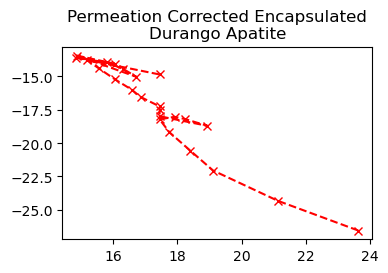

In [68]:
"""Diffusion Cell Data Reduction"""
total_yield = 3.18*197.5 #total_yield # defined in control panel, can be toggled here. 
DIFFCELL_name = 'Batch 78.csv'#DIFFCELL_name
DIFFCELL = pd.read_csv(DIFFCELL_name)

low_T_RE_threshold = 100 # Max temperature of reextract steps

try:
    TempKelvin = 273+DIFFCELL['Avg Temp'].to_numpy()
    TimeSeconds = 60*DIFFCELL['Time (min)'].to_numpy()
except:
    TempKelvin = 273+DIFFCELL['CIT RefNo'].to_numpy()
    TimeSeconds = 60*DIFFCELL['Position'].to_numpy()
    
Names = DIFFCELL['Name'].tolist()
Type = DIFFCELL['Analysis'].tolist()
HenCC = DIFFCELL['BC nCC'].to_numpy()

## add reextracts, do blank corrections
real_i = False
for i, name in enumerate(Names):
        if Type[i] == 'Diff Cell' or Type[i] == 'DiffCell':
            if 'CB' in name:
                CB = HenCC[i]
##

CB = 0
blank_corrected_yield = []
fcum = []
Fp = 0
DC_indices = []
D_a2 = []
lnD_a2 = []

####
HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
####

for i, name in enumerate(Names):
    if Type[i] == 'Diff Cell' or Type[i] == 'DiffCell':
        if 'CB' in name:
            CB = HenCC[i]
        else:
            step_yield = HenCC[i]-CB
            F = Fp + (step_yield/total_yield)
            frequency_factor = InvertFrequencyFactor(t = TimeSeconds[i], F = F, Fp = Fp)
            D_a2.append(frequency_factor)
            lnD_a2.append(np.log(frequency_factor))
            blank_corrected_yield.append(step_yield)
            DC_indices.append(i)
            fcum.append(F)
            Fp = F
            
DC_indices = np.array(DC_indices)
data = [np.array(Names)[DC_indices].tolist(), (TempKelvin[DC_indices]-273).tolist(), (TimeSeconds[DC_indices]*60).tolist(), blank_corrected_yield, fcum, D_a2, lnD_a2, (10000/TempKelvin[DC_indices]).tolist()]
columns = ['Names', 'Temp (C)', 'Time (min)', 'He Yield (nCC@STP, Blank Corrected)', 'Fcum', 'D/a^2 ', 'ln(D/a^2)', '10^4/T']
Reduced_Data = pd.DataFrame()
for i, column in enumerate(columns):
    Reduced_Data[column] = data[i]
newDiffName = DIFFCELL_name[:-4] + '_reduced' + '.csv'
Reduced_Data.to_csv(newDiffName)
print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

plt.figure(figsize=(4,2.5))
min_T = np.min(10000/TempKelvin[DC_indices][1:])
max_T = np.max(10000/TempKelvin[DC_indices][1:])
plt.plot(10000/TempKelvin[DC_indices][1:], np.array(lnD_a2)[1:], linestyle='--', marker='x', color='r', label = 'Apparent Diffusivity Data')
plt.title(f"Permeation Corrected Encapsulated\nDurango Apatite")
plt.plot(fixed_dat['10^4/T'], fixed_dat['ln(D/a^2)'], linestyle='--',markersize = 10, marker='.', color='g', label = 'Permeation-Lag Corrected Data')

reference_D0_a2 = [(10**1.5)/((150/10000)**2), (10**1.5)/((250/10000)**2), np.exp(1.1939)] # /sec
reference_Ea = [33000, 33000, 14701*1.987] # cal /mol



reference_names = ['DApB 150 um', 'DApB 250 um', 'pyrite']
R = 1.98 #cal /mol /T(K)

first_only = True
if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
    T = [min_T, max_T]
    for i, D0_a2 in enumerate(reference_D0_a2):
        if first_only:
            Ea = reference_Ea[i]
            min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
            max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
            plt.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[i])
            first_only = False
plt.legend(fontsize = 8)
plt.xlabel('10^4/T(K)')
plt.ylabel('ln(D/a^2)')
plt.tight_layout()
plt.savefig('lag_correction_demo.jpg', dpi = 256)

In [44]:
DiffdatBJT['4']

,Step,Temp ©,Minutes,4He Corrected (nccSTP),2 sigma,Seconds,Cum 4He,2 sigma.1,Fi+1,2 sigma.2,...,D>90%,2 sigma.5,D/a^2,2 sigma.6,10000/TK,ln(d/a^2),2 sigma.7,Log(D/a2),Reference,Delta Regression
0,1,170.00,300,0.0169,0.005687,18000,0.0169,0.005687,0.000116,0.000039,...,6.510000e-10,2.200000e-10,6.490000e-14,4.380000e-14,22.573363,-30.365946,0.6740,-13.187763,-26.521936,-3.844011
1,2,180.00,463,0.0281,0.005522,27780,0.0449,0.007927,0.000307,0.000054,...,6.990000e-10,2.960000e-10,2.550000e-13,1.140000e-13,22.075055,-28.998102,0.4460,-12.593716,-25.568146,-3.429957
2,3,190.00,550,0.0586,0.003948,33000,0.1040,0.008856,0.000709,0.000061,...,1.230000e-09,2.720000e-10,1.080000e-12,2.510000e-13,21.598272,-27.556062,0.2330,-11.967446,-24.655556,-2.900506
3,4,200.00,500,0.1070,0.004423,30000,0.2100,0.009899,0.001440,0.000068,...,2.470000e-09,2.960000e-10,4.560000e-12,6.120000e-13,21.141649,-26.114338,0.1340,-11.341313,-23.781553,-2.332784
4,5,210.00,475,0.1520,0.007127,28500,0.3620,0.012198,0.002480,0.000084,...,3.700000e-09,3.760000e-10,1.240000e-11,1.390000e-12,20.703934,-25.110286,0.1120,-10.905259,-22.943741,-2.166545
5,6,220.00,450,0.2140,0.009486,27000,0.5760,0.015452,0.003940,0.000106,...,5.520000e-09,4.980000e-10,3.040000e-11,2.980000e-12,20.283976,-24.216518,0.0981,-10.517100,-22.139918,-2.076601
6,7,230.00,425,0.3430,0.009684,25500,0.9190,0.018236,0.006290,0.000125,...,9.370000e-09,6.400000e-10,8.220000e-11,6.020000e-12,19.880716,-23.222307,0.0733,-10.085320,-21.368055,-1.854251
7,8,225.00,908,0.3520,0.007584,54480,1.2700,0.019750,0.008690,0.000135,...,4.510000e-09,5.610000e-10,5.770000e-11,6.570000e-12,20.080321,-23.574920,0.1140,-10.238457,-21.750112,-1.824808
8,9,215.00,450,0.0747,0.007480,27000,1.3500,0.021119,0.009210,0.000145,...,1.930000e-09,6.050000e-10,2.960000e-11,9.410000e-12,20.491803,-24.244574,0.3180,-10.529285,-22.537712,-1.706862
9,10,205.00,520,0.0338,0.012008,31200,1.3800,0.024294,0.009440,0.000167,...,7.580000e-10,7.740000e-10,1.210000e-11,1.230000e-11,20.920502,-25.141880,1.0200,-10.918980,-23.358265,-1.783615


C:\Users\dashf\AppData\Local\Temp\ipykernel_62920\1358374087.py:679: RuntimeWarning: divide by zero encountered in log
  lnD_a2.append(np.log(frequency_factor))


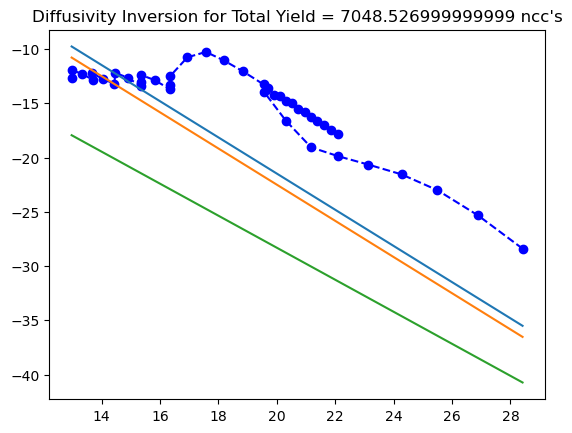

C:\Users\dashf\AppData\Local\Temp\ipykernel_62920\1358374087.py:679: RuntimeWarning: divide by zero encountered in log
  lnD_a2.append(np.log(frequency_factor))


Done! Output file: He3_HDMwinsor_diffusion.csv in C:\Users\dashf\pyrite


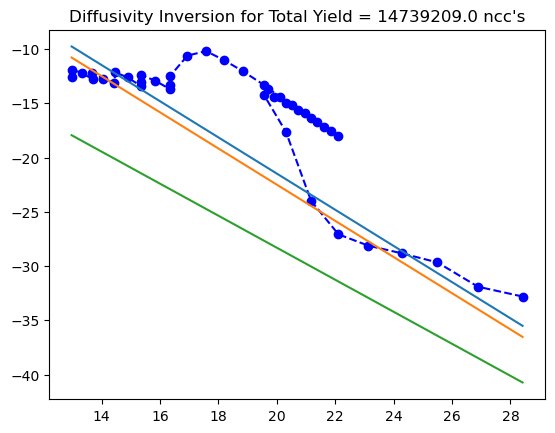

Done! Output file: He4_HDMwinsor_diffusion.csv in C:\Users\dashf\pyrite


C:\Users\dashf\AppData\Local\Temp\ipykernel_62920\1358374087.py:679: RuntimeWarning: divide by zero encountered in log
  lnD_a2.append(np.log(frequency_factor))


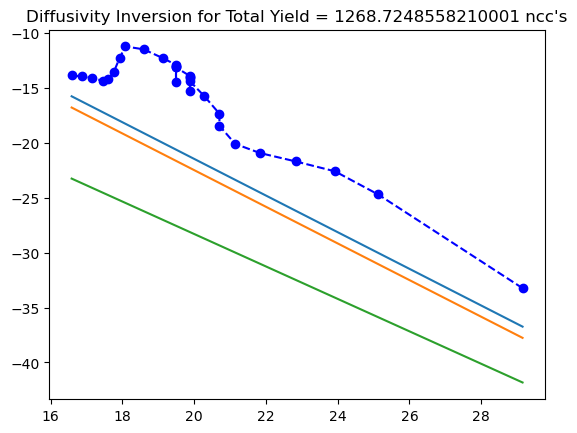

Done! Output file: He3_KAFwinsor_diffusion.csv in C:\Users\dashf\pyrite


C:\Users\dashf\AppData\Local\Temp\ipykernel_62920\1358374087.py:339: RuntimeWarning: divide by zero encountered in scalar divide
  D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )


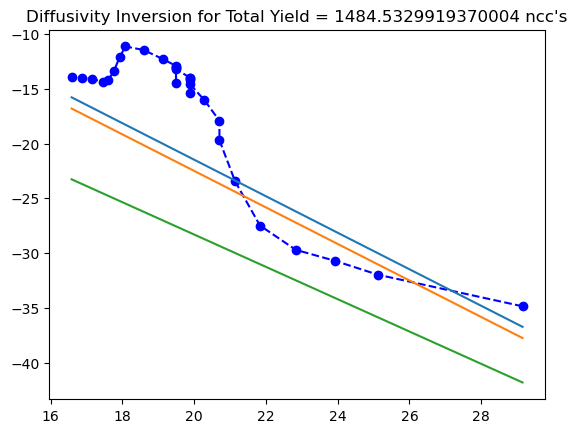

Done! Output file: He4_KAFwinsor_diffusion.csv in C:\Users\dashf\pyrite


In [8]:
"""Manual Diffusion Data Reduction"""
# Load values here

Diffdat = pd.read_csv('HM_Win_06_01B.csv')
#print(Diffdat['Time (h)'])
TempKelvin = np.array(Diffdat['Temp (C)']) + 273
TimeSeconds = np.array(Diffdat['Time (h)']) * 3600

Winsor_Data = {}

for i, name in enumerate(['3HeCPS','4HeCPS']):
    newDiffName = f'He{["3","4"][i]}_HDMwinsor_diffusion.csv'
    HeVec = np.array(Diffdat[name]).astype('float') #Helium (or other diffusant) in arbitrary units, put ready values here. no blanks/stds handled etc
    Winsor_Data[f'He{["3","4"][i]}HDM'] = diffusion_reduction(HeVec, TimeSeconds=TimeSeconds, TempKelvin=TempKelvin, newDiffName=newDiffName)

Diffdat1 = pd.read_csv('Winsor_waterKAF_BJT.csv', skiprows=1)[:30]
    
TempKelvin = np.array(Diffdat1['Temp (C)']) + 273
TimeSeconds = np.array(Diffdat1['Time (h)']) * 3600

for i, name in enumerate(['3He PCC','4He NCC']):
    newDiffName = f'He{["3","4"][i]}_KAFwinsor_diffusion.csv'
    HeVec = np.array(Diffdat1[name]).astype('float') #Helium (or other diffusant) in arbitrary units, put ready values here. no blanks/stds handled etc
    Winsor_Data[f'He{["3","4"][i]}KAF'] = diffusion_reduction(HeVec, TimeSeconds=TimeSeconds, TempKelvin=TempKelvin, newDiffName=newDiffName)



In [59]:
BJT = pd.read_excel('diffusivitiesHTWin0601b.xlsx',None)

In [60]:
BJT['Raw Data and Corrections']

,Raw Data,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 67,Unnamed: 68,Unnamed: 69,Unnamed: 70,Unnamed: 71,Unnamed: 72,Unnamed: 73,Unnamed: 74,Unnamed: 75,Unnamed: 76
0,HeRefNo,Name,Time (Pump out),Temperature (C),Nominal (Heated) Time (Minutes),Type,3He cps,4He Overspray cps,4He fA,Nominal (Heated) Time (seconds),...,2σ,4He Corrected (nccSTP),2σ,4He Correction %,26°C Permeability Solution,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,2024-01-31 17:22:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,He30238.txt,IrrWin0601bTube012624: 6305_60.0_21.0 28.45 (B...,2024-01-31 18:48:00,28.45,60,Blank,-0.00395,0,0.0484,3600,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,He30241.txt,IrrWin0601bTube012624: 8305_300.0_170.0 170.00,2024-02-01 00:14:00,170,300,Experimental,154,0,0.745,18000,...,0,0.016871,0.005687,22.519764,NaN,NaN,NaN,NaN,NaN,NaN
4,He30244.txt,IrrWin0601bTube012624: 1005_150.0_100.0 100.00,2024-02-01 03:10:00,100,150,Informed Bracket,9.62,0,0.129,9000,...,0.001394,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,NaN,NaN,CONSTANTS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
140,NaN,NaN,ID (cm),0.0505,0.054,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
141,NaN,NaN,OD (cm),0.0787,0.0832,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
142,NaN,NaN,G (cm^-1),7070.4547,6346.7896,6708.62215,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
min_T = np.min(10000/TempKelvin[HTind])
max_T = np.max(10000/TempKelvin[HTind])
fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()
ax1.plot(data_holder_MC['3He']['10^4/T'], data_holder_MC['3He']['ln(D/a^2)'], linestyle = '--', color = 'green')
ax1.scatter(data_holder_MC['3He']['10^4/T'], data_holder_MC['3He']['ln(D/a^2)'], s = 5, color = 'green', label = '3He')
Ctemps = np.linspace(200,700, 11,dtype = int)
ax1.plot(10000/TempKelvin[HTind], np.array(lnD_a2), linestyle='--', color = 'black')
ax1.scatter(10000/TempKelvin[HTind], np.array(lnD_a2), s = 5, color = 'black', label = '4He')#, c = np.log10(IR[real_steps][good_steps]), label = 'Data')
plt.title(f"Diffusivity Inversion for {name}\nTotal Yield = {total_yield} {['p','n'][i]}cc's")

#reference_D0_a2 = [(10**0.9)/((212/10000)**2), (10**2.1)/((180/10000)**2), np.exp(1.1939)] # /sec
#reference_Ea = [33000, 33000, 14701*1.987] # cal /mol
#for j, no in enumerate(['3','4']): # Plot Win-G from HDM and KAF
#ax1.plot(Winsor_Data[f'He{no}HDM']['10^4/T'][:-1], Winsor_Data[f'He{no}HDM']['ln(D/a^2)'][:-1], linestyle='--', linewidth = 1, marker=['x','+'][j], color='g', label = f'HDM {no}He Data')
for j, no in enumerate(['3','4']):
    ax1.plot(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], linestyle='--', color = 'grey')
    ax1.scatter(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], marker=['x','+'][j], c=Diffdat['watercum'][:-1]/max(Diffdat['watercum']), cmap = 'RdYlBu_r', label = f'KAF {no}He Data')

cbar = plt.colorbar(mappable = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap='RdYlBu_r'))
cbar.set_label('Cumulative Water Offgassed')
    """
    reference_names = ['200 um LVCO Pyrite', 'Apatite r=250 um','Tc = 93.6 C','Tc = 104.8 C','Tc = 134.6 C','Tc = 146.7 C', 'Tc = 112.8']
    R = 1.98 #cal /mol /T(K)
    reference_D0_a2 = [np.exp(4.2623), (10**1.5)/((250/10000)**2)]#,1.84,0.03,3.81,6.96] # /sec
    reference_Ea = [(R*2.2015*10000), 33000]#,26030,23845,29607,30997] # cal /mol

    if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
        T = [min_T, max_T]
        for j, D0_a2 in enumerate(reference_D0_a2):
            Ea = reference_Ea[j]
            min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
            max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
            plt.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[j])
            #print(T, min_log_frequency_factor, max_log_frequency_factor)
    """

    ax2.set_xticks(1E4/(Ctemps+273))
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticklabels(Ctemps)
    ax2.set_xlabel('Temperature (C)')
    ax1.set_xlabel('10^4/T(K)')
    ax1.set_ylabel('ln(D_a2) (sec^-1)')
    plt.legend()#fontsize = 10)
    plt.savefig(newDiffName+'.jpg', dpi = 256)
    plt.show()

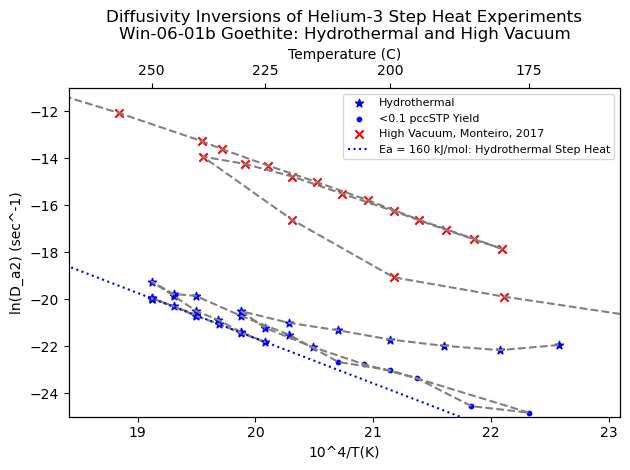

In [286]:
i = 0
total_yield = 123.9
data_holder_MC = {}
data_holder_MC['3He'] = pd.read_csv('Winsor3HeCustomReductionBJT.csv')[:-1]
name = 'Win-06-01b'

big_yields_i = data_holder_MC['3He']['He Yield (nCC@STP)'] >= .1
small_yields_i = data_holder_MC['3He']['He Yield (nCC@STP)'] < .1

min_T = np.min(data_holder_MC['3He']['10^4/T'])
min_T = 10000/(350+273)
max_T = np.max(data_holder_MC['3He']['10^4/T'])
max_T = 10000/(100+273)

R = 1.987 #cal /mol /T(K)

fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()
ax1.plot(data_holder_MC['3He']['10^4/T'], data_holder_MC['3He']['ln(D/a^2)'], linestyle = '--', color = 'grey')
ax1.scatter(data_holder_MC['3He']['10^4/T'][big_yields_i], data_holder_MC['3He']['ln(D/a^2)'][big_yields_i], color = 'blue', marker = '*', label = "Hydrothermal")
ax1.scatter(data_holder_MC['3He']['10^4/T'][small_yields_i], data_holder_MC['3He']['ln(D/a^2)'][small_yields_i], s = 10, color = 'blue', label = "<0.1 pccSTP Yield")
Ctemps = np.array([150,175,200,225,250])
#ax1.plot(10000/TempKelvin[HTind], np.array(lnD_a2), linestyle='--', color = 'black')
#ax1.scatter(10000/TempKelvin[HTind], np.array(lnD_a2), color = 'black', label = 'Hydrothermal Step Heat')#, c = np.log10(IR[real_steps][good_steps]), label = 'Data')
plt.title(f"Diffusivity Inversions of Helium-3 Step Heat Experiments\n{name} Goethite: Hydrothermal and High Vacuum")

#reference_D0_a2 = [(10**0.9)/((212/10000)**2), (10**2.1)/((180/10000)**2), np.exp(1.1939)] # /sec
#reference_Ea = [33000, 33000, 14701*1.987] # cal /mol
#for j, no in enumerate(['3','4']): # Plot Win-G from HDM and KAF
#ax1.plot(Winsor_Data[f'He{no}HDM']['10^4/T'][:-1], Winsor_Data[f'He{no}HDM']['ln(D/a^2)'][:-1], linestyle='--', linewidth = 1, marker=['x','+'][j], color='g', label = f'HDM {no}He Data')
no = 3
j = 0
ax1.plot(Winsor_Data[f'He{no}HDM']['10^4/T'][:-1], Winsor_Data[f'He{no}HDM']['ln(D/a^2)'][:-1], linestyle='--', color = 'grey')
ax1.scatter(Winsor_Data[f'He{no}HDM']['10^4/T'][:-1], Winsor_Data[f'He{no}HDM']['ln(D/a^2)'][:-1], marker=['x','+'][j], color = 'red', label = f'High Vacuum, Monteiro, 2017')

"""
ax1.plot(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], linestyle='--', color = 'grey')
ax1.scatter(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], marker=['x','+'][j], c=Diffdat1['watercum'][:-1]/max(Diffdat1['watercum']), cmap = 'RdYlBu_r', label = f'High Vacuum, Farley et al., 2024')

cbar = plt.colorbar(mappable = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap='RdYlBu_r'))
cbar.set_label('Cumulative Water Offgassed')
"""

"""
reference_names = ['200 um LVCO Pyrite', 'Apatite r=250 um','Tc = 93.6 C','Tc = 104.8 C','Tc = 134.6 C','Tc = 146.7 C', 'Tc = 112.8']

reference_D0_a2 = [np.exp(4.2623), (10**1.5)/((250/10000)**2)]#,1.84,0.03,3.81,6.96] # /sec
reference_Ea = [(R*2.2015*10000), 33000]#,26030,23845,29607,30997] # cal /mol
"""

reference_D0_a2 = 52430550.28
# [np.exp(4.2623), (10**1.5)/((250/10000)**2)]#,1.84,0.03,3.81,6.96] # /sec
reference_Ea = 38851.811
T = [min_T, max_T]
#    for j, D0_a2 in enumerate(reference_D0_a2)
Ea = reference_Ea
D0_a2 = reference_D0_a2
min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
#ax1.plot(T, [min_log_frequency_factor, max_log_frequency_factor], color = 'blue', linestyle = ':', label = 'Ea = 163 kJ/mol: Hydrothermal Step Heat')
ax1.plot(T, 16.864-1.9259*np.array(T), color = 'blue', linestyle = ':', label = 'Ea = 160 kJ/mol: Hydrothermal Step Heat')
 
    
reference_D0_a2 = 2780000000
# [np.exp(4.2623), (10**1.5)/((250/10000)**2)]#,1.84,0.03,3.81,6.96] # /sec
reference_Ea = 35600
#[(R*2.2015*10000), 33000]#,26030,23845,29607,30997] # cal /mol

#if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
T = [min_T, max_T]
#    for j, D0_a2 in enumerate(reference_D0_a2)
Ea = reference_Ea
D0_a2 = reference_D0_a2
min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
#ax1.plot(T, [min_log_frequency_factor, max_log_frequency_factor], color = 'red', linestyle = ':', label = 'Ea = 150 kJ/mol: Decomposed Goethite')
        #print(T, min_log_frequency_factor, max_log_frequency_factor)
    
    


reference_D0_a2 = 132222940.6
# [np.exp(4.2623), (10**1.5)/((250/10000)**2)]#,1.84,0.03,3.81,6.96] # /sec
reference_Ea = 34176.4
#[(R*2.2015*10000), 33000]#,26030,23845,29607,30997] # cal /mol

#if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
T = [min_T, max_T]
#    for j, D0_a2 in enumerate(reference_D0_a2)
Ea = reference_Ea
D0_a2 = reference_D0_a2
#min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
#max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
#ax1.plot(T, [min_log_frequency_factor, max_log_frequency_factor], color = 'Black', linestyle = '-', label = f'Ea = {int((Ea*4.184)/1000)} kJ/mol:\nReference Line: Farley et al., 2024')



ax1.set_xlim((1E4/(273+270),1E4/(273+160)))
ax1.set_ylim((-25,-11))
ax2.set_xticks(1E4/(Ctemps+273))
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (C)')
ax1.set_xlabel('10^4/T(K)')
ax1.set_ylabel('ln(D_a2) (sec^-1)')
ax1.legend(fontsize = 8)
fig.tight_layout()
plt.savefig('winsor_goethite_moneyplot.jpg', dpi = 256)
plt.show()

In [64]:
pd.read_csv('Winsor3HeCustomReductionBJT.csv')[:-1]

,Unnamed: 0,Temp (C),Time (min),He Yield (nCC@STP),Fcum,D/a^2,ln(D/a^2),10^4/T
0,0,170.00,300.0,1.137884,0.009184,4.089108e-10,-21.617524,22.573363
1,1,180.00,463.0,0.565805,0.013751,3.290017e-10,-21.834958,22.075055
2,2,190.00,550.0,0.576599,0.018404,3.957144e-10,-21.650328,21.598272
3,3,200.00,500.0,0.535694,0.022728,5.173128e-10,-21.382373,21.141649
4,4,210.00,475.0,0.613913,0.027683,7.648224e-10,-20.991377,20.703934
5,5,220.00,450.0,0.664139,0.033043,1.052071e-09,-20.672505,20.283976
6,6,230.00,425.0,0.855378,0.039947,1.724475e-09,-20.178343,19.880716
7,7,225.00,908.0,0.766948,0.046137,8.535444e-10,-20.881624,20.080321
8,8,215.00,450.0,0.152437,0.047367,3.718209e-10,-21.712609,20.491803
9,9,205.00,520.0,0.083884,0.048044,1.806765e-10,-22.434313,20.920502


C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\2900041502.py:646: RuntimeWarning: divide by zero encountered in log
  lnD_a2.append(np.log(frequency_factor))


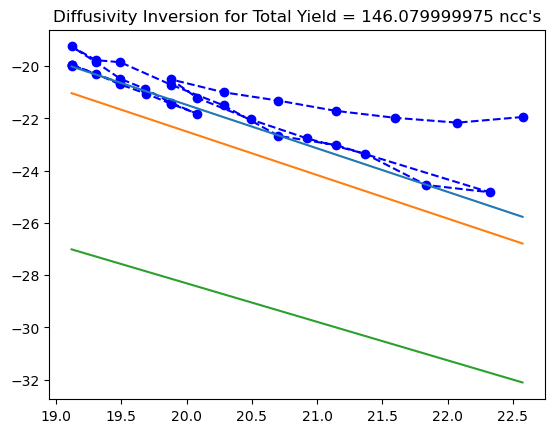

Done! Output file: Winsor3HeCustomReductionBJT.csv in C:\Users\dashf\pyrite


In [140]:
Diffdat = pd.read_csv('IrrWin0601bTube012624TC_Custom_3He.csv')
#print(Diffdat['Time (h)'])
TempKelvin = np.array(Diffdat['Temp (C)']) + 273
TimeSeconds = np.array(Diffdat['Time (min)']) * 60

Winsor_Data = {}

#newDiffName = f'He{["3","4"][i]}_HDMwinsor_diffusion.csv'
HeVec = np.array(Diffdat['Corrected yield']).astype('float') #Helium (or other diffusant) in arbitrary units, put ready values here. no blanks/stds handled etc
Winsor_Data = diffusion_reduction(HeVec, TimeSeconds=TimeSeconds, TempKelvin=TempKelvin, newDiffName='Winsor3HeCustomReductionBJT.csv')

Winsor_Data.to_csv('Winsor3HeCustomReductionBJT.csv')

In [170]:
omegaUB

array([0.04436406, 0.0446662 , 0.07293801, 0.1326976 , 0.18520443,
       0.26060385, 0.39853752, 0.38374261, 0.09049759, 0.0481976 ,
       0.03763289, 0.00953034, 0.01818775, 0.01815299, 0.26866977,
       0.34504535, 0.26870791, 0.5498995 , 0.54400045, 0.63495652,
       0.41570872, 0.24728096, 0.18987515, 0.12196875, 0.11412559,
       0.1246835 , 0.16404568, 0.2160875 , 0.28469665, 0.35161781,
       0.33607398, 0.31512632, 6.84648093, 0.20350756])

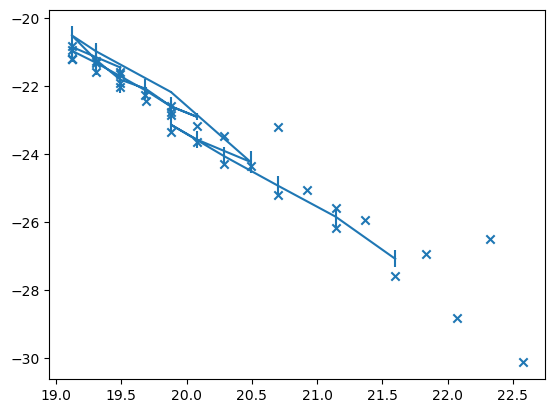

In [194]:
Diffdat = pd.read_csv('Winsor4HeUB_BJT.csv')
invtemp = np.array(Diffdat['10^4/T'])
OmegaUB = np.array(Diffdat['ln(D/a^2)'])
Diffdat = pd.read_csv('Winsor4HeLB_BJT.csv')
OmegaLB = np.array(Diffdat['ln(D/a^2)'])
Diffdat = pd.read_csv('Winsor4HeM_BJT.csv')
OmegaM = np.array(Diffdat['ln(D/a^2)'])

valid = (OmegaUB - OmegaLB) > 0
#print(valid.astype('float') - (Diffdat['He Yield (nCC@STP)'] > 0.05).astype('float'))

valid *= Diffdat['He Yield (nCC@STP)'] > 0.05

midpoints = OmegaLB + (0.5*(OmegaUB-OmegaLB))

#plt.scatter(invtemp[valid], OmegaUB[valid])

#plt.scatter(invtemp[valid], OmegaLB[valid])
plt.scatter(invtemp, OmegaM, marker = 'x')
plt.plot(invtemp[valid], midpoints[valid])
plt.vlines(invtemp[valid], OmegaUB[valid], OmegaLB[valid])

#plt.errorbar(invtemp[valid], midpoints[valid], yerr = [OmegaUB[valid]-midpoints[valid], midpoints[valid]-OmegaLB[valid]])

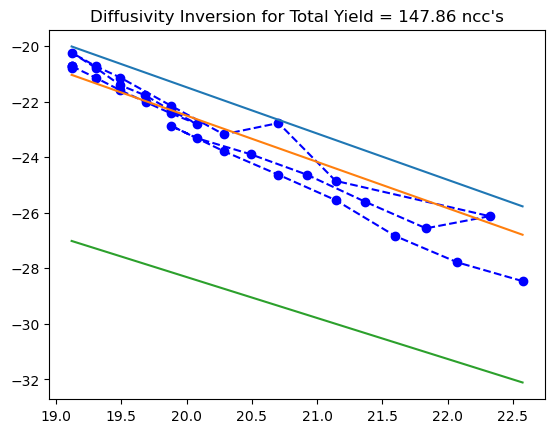

Done! Output file: Winsor4HeLBDiffBJT.csv in C:\Users\dashf\pyrite


PermissionError: [Errno 13] Permission denied: 'Winsor4HeUB_BJT.csv'

In [207]:
Diffdat = pd.read_csv('bounded4HeIrrWins.csv')
#print(Diffdat['Time (h)'])
TempKelvin = np.array(Diffdat['Temp (C)']) + 273
TimeSeconds = np.array(Diffdat['Time (m)']) * 60

Winsor_Data = {}

#newDiffName = f'He{["3","4"][i]}_HDMwinsor_diffusion.csv'
HeVec = np.array(Diffdat['Omega UB']).astype('float') #Helium (or other diffusant) in arbitrary units, put ready values here. no blanks/stds handled etc
Winsor_Data = diffusion_reduction(HeVec, TimeSeconds=TimeSeconds, TempKelvin=TempKelvin, newDiffName='Winsor4HeLBDiffBJT.csv', total_yield=147.86, )

Winsor_Data.to_csv('Winsor4HeUB_BJT.csv')

C:\Users\dashf\AppData\Local\Temp\ipykernel_30344\3349489988.py:613: RuntimeWarning: divide by zero encountered in log
  lnD_a2.append(np.log(frequency_factor))


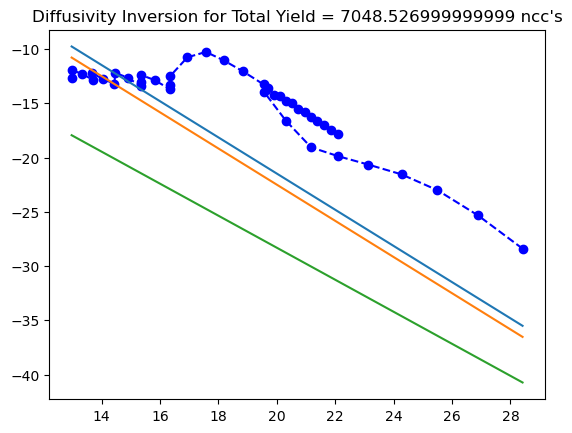

C:\Users\dashf\AppData\Local\Temp\ipykernel_30344\3349489988.py:613: RuntimeWarning: divide by zero encountered in log
  lnD_a2.append(np.log(frequency_factor))


Done! Output file: He3_HDMwinsor_diffusion.csv in C:\Users\dashf\pyrite


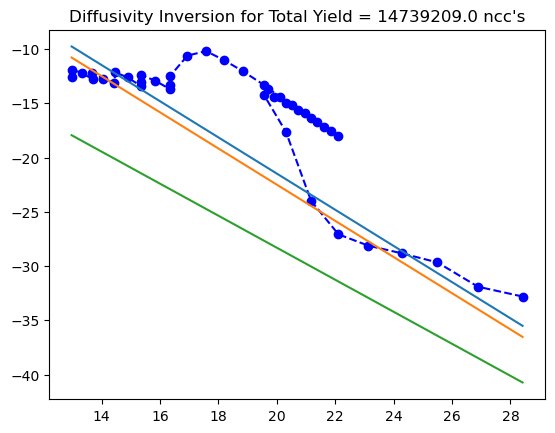

Done! Output file: He4_HDMwinsor_diffusion.csv in C:\Users\dashf\pyrite


In [88]:
Diffdat2 = pd.read_csv('HM_Win_06_01B.csv')
#print(Diffdat['Time (h)'])
TempKelvin = np.array(Diffdat2['Temp (C)']) + 273
TimeSeconds = np.array(Diffdat2['Time (h)']) * 3600

Winsor_Data = {}

for i, name in enumerate(['3HeCPS','4HeCPS']):
    newDiffName = f'He{["3","4"][i]}_HDMwinsor_diffusion.csv'
    HeVec = np.array(Diffdat2[name]).astype('float') #Helium (or other diffusant) in arbitrary units, put ready values here. no blanks/stds handled etc
    Winsor_Data[f'He{["3","4"][i]}HDM'] = diffusion_reduction(HeVec, TimeSeconds=TimeSeconds, TempKelvin=TempKelvin, newDiffName=newDiffName)


Done! Output file: Batch 76_reduced.csv in C:\Users\dashf\pyrite


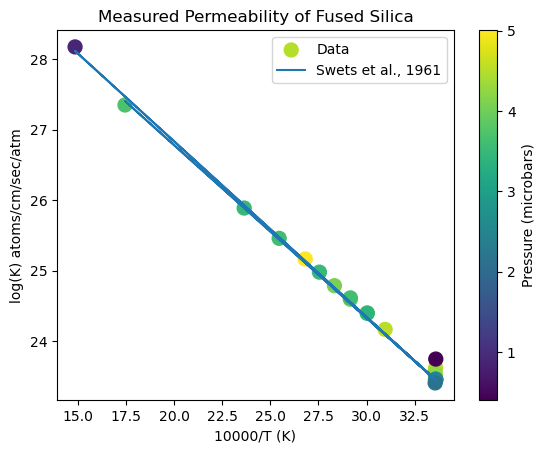

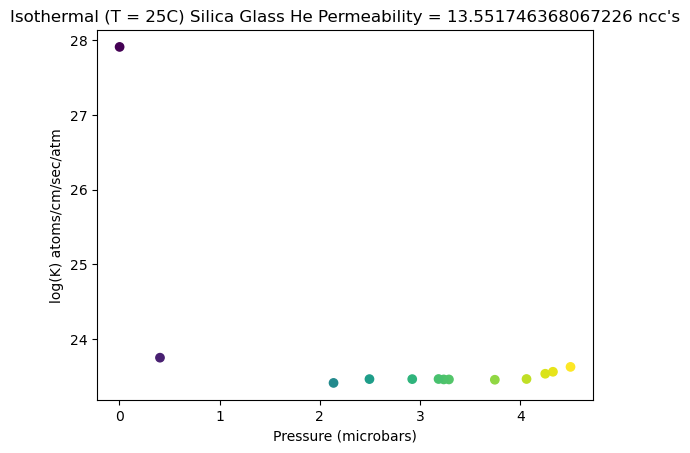

In [712]:
## Permeability Inversion!
K0 = 8.25E9/np.exp(-5115/(1.987*287))
Rcal = 1.987
RccATM = 82.06 # cc atm /mol /K
Ratoms = 1.36E-22 # cc atm /atoms /K

def swets_K(T):
    """Returns Permeability of fused Silica in units: atoms/cm/s/atm for a given T in Kelvin"""
    if T >= 573:
        DEa = 6613 # factor of 4 to convert from g Helium to moles
        SEa = -1174
        DFF = 7.40E-4
        SFF = 1.28E17
    else:
        DEa = 5580
        SEa = -680
        DFF = 3.04E-4
        SFF = 1.99E17
        
    D = DFF*np.exp(-DEa/(Rcal*T))
    S = SFF*np.exp(-SEa/(Rcal*T)) # K units: atom/cm/s/dP atm/
    #print(f"Solubility at T = {T-273}C: {S} atoms/cm3/atm")
    #print(f"Diffusivity at T = {T-273}C: {D} cm2/s")
    #print(f"Permeation at T = {T-273}C in mol/cm/s/atm: {D*S}")
    K = D*S#/6.022E23 #units: mol/cm/s/atm
    return K

## Will consider Helium lost from dynamic vacuum portion of routine. Should we consider a different diffusion gradient when spike is introduced? 
## Will significant 3He diffuse into the tube from the spike? Will this affect the measurement? 



DIFFCELL_name = 'Batch 76.csv' #DIFFCELL_name
h = 1.04 #cm, length of tube
OD = 960 #microns, outer diameter
ID = 630 #microns, inner diameter

total_yield = 0 #nccSTP. Enter 0 if run went to completion

cold_accum_time = 30 # minutes (room temperature time where helium permeate is added to previous step)
cold_loss_time = 15 # minutes (time in dynamic vaccuum where helium permeate is lost, accounted for in total yields)
cold_correct_method = 'measured' # For now, only "measured" is valid. Corrects on the basis of cold permeation data or later by permeability calculations
DIFFCELL = pd.read_csv(DIFFCELL_name)

ID /= 10000 #Convert to cm
OD /= 10000 #Convert to cm
V = h*np.pi*((ID/2)**2) #cc
 
Type = DIFFCELL['Analysis'].to_numpy()
reldata = ((Type == 'Diff Cell').astype('float') + (Type ==  'DiffCell').astype('float')).astype('bool')
Names = DIFFCELL['Name'].to_numpy()[reldata]

try:
    TempKelvin = 273+DIFFCELL['Avg Temp'].to_numpy()[reldata]
    TimeSeconds = 60*DIFFCELL['Time (min)'].to_numpy()[reldata]
except:
    TempKelvin = 273+DIFFCELL['CIT RefNo'].to_numpy()[reldata]
    TimeSeconds = 60*DIFFCELL['Position'].to_numpy()[reldata]

HenCC = DIFFCELL['BC nCC'].to_numpy()[reldata]

### Cold permeation per second
cold_corrected_yield = [] # vector of cold permeate corrected data
cumYield = [0]

####
HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
####
colds = []
for i, Temp in enumerate(TempKelvin):
    if Temp < 300:
        colds.append(i)
        CPps = HenCC[i] / (TimeSeconds[i]+(cold_accum_time*60))
    cold_corrected_yield.append(HenCC[i] - (CPps*cold_accum_time*60))
    cumYield.append(cumYield[-1] + cold_corrected_yield[-1] + (CPps*(cold_accum_time+cold_loss_time)*60))
        
plotable = np.arange(len(cold_corrected_yield))
if total_yield == 0:
    total_yield = cumYield[-1]
    plotable = plotable[:-1]

colds = np.array(colds)
cumYield = np.array(cumYield)
fcum = cumYield/total_yield
n0 = total_yield - cumYield
molHe = n0[:-1]/(22.4*1E12) #convert from nccSTP to moles
PHeATM = ((molHe*RccATM*TempKelvin)/V)
PHe = (PHeATM/1.01325)*1E6 # Conv. Atmospheres to microbars
n_n0 = (n0[:-1]-cold_corrected_yield)/n0[:-1]


K = ((-((ID/2)**2)*np.log(OD/ID)*np.log(n_n0))/(TimeSeconds*Ratoms*TempKelvin*2)) # atoms / atm / cm / sec 

data = [np.array(Names).tolist(), (TempKelvin-273).tolist(), (TimeSeconds/60).tolist(), cold_corrected_yield, fcum[1:], K, PHe, (10000/TempKelvin).tolist(), np.log(K)]
columns = ['Names', 'Temp (C)', 'Time (min)', 'He Yield (nCC@STP, Cold Permeate Corrected)', 'Fcum', 'K (atom /atm /sec /cm)', 'Pressure (Bars)', '10^4/T', 'ln(K)']
Reduced_Data = pd.DataFrame()
for i, column in enumerate(columns):
    Reduced_Data[column] = data[i]
newDiffName = DIFFCELL_name[:-4] + '_reduced' + '.csv'
Reduced_Data.to_csv(newDiffName)
print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

min_T = np.min(10000/TempKelvin[plotable])
max_T = np.max(10000/TempKelvin[plotable])
#plt.plot(10000/TempKelvin[plotable], np.log(K)[plotable], linestyle='--')
#plt.plot(10000/TempKelvin[plotable], np.log(K)[plotable], linestyle='--')
plt.scatter(10000/TempKelvin[plotable], np.log(K)[plotable], marker='o', c=PHe[plotable], s= 100, label = 'Data')
cbar = plt.colorbar()
cbar.set_label('Pressure (microbars)')
plt.title(f"Measured Permeability of Fused Silica")
plt.xlabel('10000/T (K)')
plt.ylabel('log(K) atoms/cm/sec/atm')

#reference_D0_a2 = [(10**0.9)/((212/10000)**2), (10**2.1)/((180/10000)**2), np.exp(1.1939)] # /sec
#reference_Ea = [33000, 33000, 14701*1.987] # cal /mol


reference_K = []
for TK in TempKelvin:
    reference_K.append(swets_K(TK))
reference_K = np.array(reference_K)

#reference_names = ['DApB 212 um, logD0 = 0.9', 'DApB 180 um, log D0 = 2.1', 'pyrite']
#R = 1.98 #cal /mol /T(K)


#if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):

plt.plot(10000/TempKelvin, np.log(reference_K), label = 'Swets et al., 1961')
plt.legend()
plt.savefig('silica_permeability.jpg', dpi = 256)
plt.show()


plt.scatter(PHe[colds], np.log(K)[colds], marker='o', c=PHe[colds], label = 'Data')
plt.title(f"Isothermal (T = 25C) Silica Glass He Permeability = {total_yield} ncc's")
plt.xlabel('Pressure (microbars)')
plt.ylabel('log(K) atoms/cm/sec/atm')
#plt.savefig('silica_permeability_cold.jpg', dpi = 256)
plt.show()

In [5]:
swets_K(273+25)

15410772668.121315

In [268]:
def extract_times(dates):
    """Extracts cold blank times using Diff Cell timestamps"""
    times = [] # in seconds
    first = True
    permT = 
    pumpT = False
    for stri in dates[1:]: # skipping first '\n'
        if first:
            oldtime = datetime.strptime(stri[1:-1], '%m/%d/%Y %I:%M:%S %p')
            print(oldtime)
            first = False
        if closeT:
            newtime = datetime.strptime(stri[1:-1], '%m/%d/%Y %I:%M:%S %p')
            times.append((newtime - oldtime).total_seconds())
            oldtime = newtime
            closeT = False # Skip next timestamp, which would close diffcell if it wasn't already closed
        else:
            #print(f"Skipped time: {datetime.strptime(stri[1:-1], '%m/%d/%Y %I:%M:%S %p')-oldtime}")
            closeT = True
    return np.array(times)


with open(timestamp_names, "r") as TIMES:
    timestrings = TIMES.readlines()
    for time in timestrings[1:]:
        print(time[1:-1])
    #coldtimes = extract_timesMC(timestrings)
    
print(coldtimes)
len(coldtimes)

11/5/2023 9:43:36 AM
11/5/2023 10:26:49 AM
11/5/2023 10:42:41 AM
11/5/2023 11:26:04 AM
11/5/2023 11:41:56 AM
11/5/2023 12:25:13 PM
11/5/2023 2:20:16 PM
11/5/2023 6:49:24 PM
11/5/2023 7:05:15 PM
11/5/2023 7:48:32 PM
11/5/2023 8:06:20 PM
11/5/2023 8:49:42 PM
11/5/2023 9:05:32 PM
11/5/2023 9:48:53 PM
11/5/2023 10:04:44 PM
11/6/2023 2:34:07 AM
11/6/2023 2:49:52 AM
11/6/2023 3:33:13 AM
11/6/2023 3:49:07 AM
11/6/2023 4:32:26 AM
11/6/2023 4:48:16 AM
11/6/2023 5:31:36 AM
11/6/2023 5:47:26 AM
11/6/2023 10:16:28 AM
11/6/2023 10:32:17 AM
11/6/2023 11:15:42 AM
11/6/2023 11:31:32 AM
11/6/2023 12:14:57 PM
11/6/2023 12:30:53 PM
11/6/2023 1:14:26 PM
11/6/2023 1:30:16 PM
11/6/2023 2:59:38 PM
11/6/2023 3:15:22 PM
11/6/2023 3:58:47 PM
11/6/2023 4:14:45 PM
11/6/2023 4:58:07 PM
11/6/2023 5:14:02 PM
11/6/2023 5:57:36 PM
11/6/2023 6:14:42 PM
11/6/2023 7:44:14 PM
11/6/2023 8:00:00 PM
11/6/2023 8:43:37 PM
11/6/2023 8:59:34 PM
11/6/2023 9:42:59 PM
11/6/2023 9:58:55 PM
11/6/2023 11:28:18 PM
11/6/2023 11:44:10 PM

98

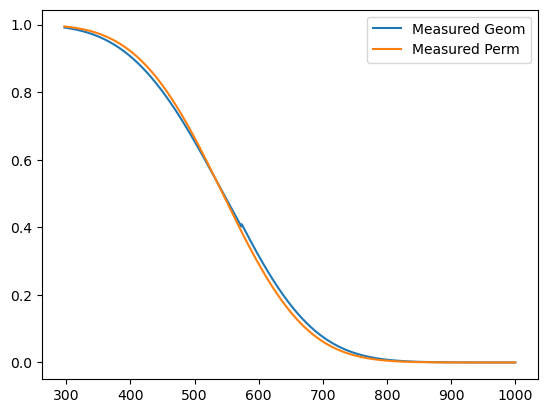

41442679526997.68
1.987


0.9939313880954115

In [276]:
t = 3600
Temps = np.linspace(297,1000,1000)
K0G = 4.25482E17
Ea = 5505.977
M1 = []
M2 = []
for tk in Temps:
    M1.append(tube_permeate2(t = t, T = tk, ID = ID, OD = OD))
    M2.append(tube_permeate3(t = t, T = tk, K0G=K0G, Ea=Ea))
    
plt.plot(Temps, M1, label = 'Measured Geom')
plt.plot(Temps, M2, label = 'Measured Perm')
plt.legend()
plt.show()


#K0G = 3.85603E16
#Ea = 3417.64
tube_permeate3(t = 3600, T = 300, K0G=K0G, Ea=Ea)
lam = K0G*np.exp(-Ea/(Rcal*300))
def tube_permeate3(T, t, K0G, Ea):
    """Permeation with measured geometric infinite T permeability and activation energy in cal/mol"""
    lam = K0G*np.exp(-Ea/(Rcal*T))
    return(np.exp(-(lam*Ratoms*T*t)))
print(lam)
print

print(Rcal)
np.exp(-(lam*Ratoms*300*t))

In [264]:
timestamp_names = "Batch78DApTube111623.txt"
with open(timestamp_names, "r") as TIMES:
    timestrings = TIMES.readlines()
    coldtimes = extract_times(timestrings) # function definied in dependencies, considers 1st line blank '\n' Coldtimes is of length of reldata
print(coldtimes)

2023-11-05 09:43:36
[ 2593.  3555.  3549. 23051.  3548.  3670.  3551. 17114.  3546.  3553.
  3550. 17092.  3554.  3555.  3569.  6312.  3549.  3560.  3569.  6398.
  3563.  3562.  6319.  3555.  3555.  6312.  3553.  3553.  3551.  6311.
  3546.  3547.  7501.  3554.  3560.  8701.  3540.  3545.  6308.  3547.
  3556.  9903.  3550.  3556. 13504.  3554.  3647.  6331.  3557.  3560.
  6350.  3557.  3561.  6331.  3556.  3555.  6331.  3565.  3560.  6330.
  3558.  3569.  6334.  3562.  3555.  6337.  3552.  3560.  8737.  3554.
  3558. 17121.  3550.  3547.  8129.  3622.  3550.  6335.  3559.  3555.
  9919.  3564.  3564.  6340.  3558.  3557.  3560.  3557.  3562. 13517.
  3550.  3554.  6334.  3550.  3549. 17056.  3561.  3565.]


2023-11-05 09:43:36
Done! Output file: Batch 78_COLDS_TubeReduced.csv in C:\Users\dashf\pyrite
Done! Output file: Batch 78_HOTS_TubeReduced2.csv in C:\Users\dashf\pyrite


C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\3170824901.py:244: RuntimeWarning: invalid value encountered in log
  DK_swets = np.log(K_meas)-np.log(np.array(K_ref))
C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\3170824901.py:245: RuntimeWarning: invalid value encountered in log
  lnlambdas = np.log(lambdas)
C:\Users\dashf\AppData\Local\Temp\ipykernel_8312\3170824901.py:416: RuntimeWarning: divide by zero encountered in log
  lnD_a2.append(np.log(frequency_factor))


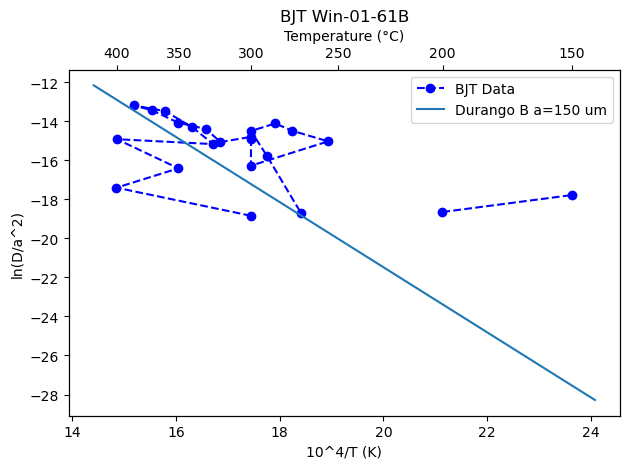

In [88]:
"""Diffusion Cell Data Reduction for encapsulated phases correcting for permeation lag"""



total_yield =   3.18*197.5
DIFFCELL_name = 'Batch 78.csv'#DIFFCELL_name
timestamp_names = "Batch78DApTube111623.txt"
h = 1.05 #cm, length of tube
OD = 1350 #microns, outer diameter
ID = 850 #microns, inner diameter

ID /= 10000 #Convert to cm
OD /= 10000 #Convert to cm

# Three temperatures for use in data reduction. 
#1st temp asks if room temperature 
#2nd asks the temp at which cold permeation is effectively negligible (permeation is 10x at 120C and 20x at 175)
#3rd asks the temperature at which helium starts degassing from the encapsulated phase
Tcutoff = [(26 + 273), (90 + 273), (120 + 273)] 



"""# Big Bahia cml goethite: 134.4 nccSTP/mg
h = 1.75 #cm, length of tube
OD = 1075 #microns, outer diameter
ID = 725 #microns, inner diameter"""




#total_yield =  120*2.36 #3.18*197.5 #total_yield # defined in control panel, can be toggled here. 
skip_plotting = 0 # How many high temp steps to skip when plotting. 
skip_reducing = 0

"""DIFFCELL_name = 'Batch 80.csv'#DIFFCELL_name
timestamp_names = 'DC Timestamps.txt'
plot_title = 'BJT Win-01-61B'
# Geometric measurements not necesary if using tube_permeate3


h = 1.573 #cm, length of tube
OD = 1050 #microns, outer diameter
ID = 650 #microns, inner diameter"""


'''
#DAp
h = 1.05 #cm, length of tube
OD = 1350 #microns, outer diameter
ID = 850 #microns, inner diameter

ID /= 10000 #Convert to cm
OD /= 10000 #Convert to cm

#K0G = 3.85603E16
#Ea = 3417.64
#K0G = 4.25482E17
#Ea = 5505.977

#K0G = 3.985E16
#Ea = 3435.52

K0G = 4.06591E+16
Ea = 3435.523

Ea = 5200
kogs = 10**np.linspace(37,38,20)
Eas = np.linspace(1000,80000,20)
first = True
'''
"""
for Ea in Eas:
    perm_model = 'measured'
    if first: 
        perm_model = 'modeled'
        print('MODEL')
        first = False
    K0G = np.mean([5.92954E+13,6.6995E+13])/np.exp(-Ea/(1.987*297))
    print(f"####### Ea = {Ea}, K0G = {K0G} ##############")


    #K0G=4.076E17
    #Ea = 5456.3

    def tube_permeate3(T, t, K0G, Ea):
        #Permeation with measured geometric infinite T permeability and activation energy in cal/mol
        lam = K0G*np.exp(-Ea/(Rcal*T))
        #print(f"lamda at T={T}: {lam}")
        n_n0 = np.exp(-(lam*Ratoms*T*t))
        #print(n_n0)
        return(n_n0)
"""






perm_model = 'modeled'
with open(timestamp_names, "r") as TIMES:
    timestrings = TIMES.readlines()
    coldtimes = extract_times(timestrings)[skip_reducing:] # function definied in dependencies, considers 1st line blank '\n' Coldtimes is of length of reldata


DIFFCELL = pd.read_csv(DIFFCELL_name)


G = 2/(np.log(OD/ID)*((ID/2)**2))

V = h*np.pi*((ID/2)**2) #cc
Rcal = 1.987
RccATM = 82.06 # cc atm /mol /K
Ratoms = 1.36E-22 # cc atm /atoms /K    

Type = DIFFCELL['Analysis'].to_numpy()
reldata = ((Type == 'Diff Cell').astype('float') + (Type ==  'DiffCell').astype('float')).astype('bool')
Names = (DIFFCELL['Name'].to_numpy()[reldata])[skip_reducing:]

try:
    TempKelvin = (273+DIFFCELL['Avg Temp'].to_numpy()[reldata])[skip_reducing:]
    TimeSeconds = (60*DIFFCELL['Time (min)'].to_numpy()[reldata])[skip_reducing:]
except:
    TempKelvin = (273+DIFFCELL['CIT RefNo'].to_numpy()[reldata])[skip_reducing:]
    TimeSeconds = (60*DIFFCELL['Position'].to_numpy()[reldata])[skip_reducing:]

HenCC = (DIFFCELL['BC nCC'].to_numpy()[reldata])[skip_reducing:]
HenCC[HenCC < 0] = 0 

# Information for tube corrections
n0_modeled = [] # calc for every cold blank, cold indices apply
n1_modeled = []
n0_measured = [] # calc for consectutive cold blanks, indices in Smeas
n1_measured = []
Smeas = [] #indices of consecutive cold blanks
colds = [] #indices of all cold blanks
Smeascolds = []
M = [] #measured CB proportionality (1 - n1/n0)/sec

# Diffusivity data
fcum = []
Fp = 0
DC_indices = []
D_a2 = []
lnD_a2 = []
n1_n0_mod = []
n1_n0_mes = []

####
HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
####
prev_cold = 0
prev_inter = 0
cold_counter = -1
total_colds = 0
Rel_times = []
for i, name in enumerate(Names):
    # First, manage permeability corrections
    if TempKelvin[i] < Tcutoff[2] :
        colds.append(i)
        cold_counter += 1  
        total_colds += 1
        if TempKelvin[i] > Tcutoff[1]: # Logic to only report values where temperature control is valid. Later model room temp as cooling curve
            if perm_model == 'modeled' or perm_model == 'modelled':
                n1_n0_modeled = tube_permeate2(t = TimeSeconds[i], T = TempKelvin[i], ID = ID, OD = OD)
            elif perm_model == 'measured':
                n1_n0_modeled = tube_permeate3(t = TimeSeconds[i], T = TempKelvin[i], K0G=K0G, Ea=Ea) 
        elif (TempKelvin[i] < Tcutoff[0]) and prev_cold > 0:
            if perm_model == 'modeled' or perm_model == 'modelled':
                n1_n0_modeled = tube_permeate2(t = coldtimes[i], T = TempKelvin[i], ID = ID, OD = OD) 
            elif perm_model == 'measured':
                n1_n0_modeled = tube_permeate3(t = coldtimes[i], T = TempKelvin[i], K0G=K0G, Ea=Ea) 
        else: 
            n1_n0_modeled = 0
        n1_n0_mod.append(n1_n0_modeled)
        if n1_n0_modeled:
            n0_modeled.append(HenCC[i]/(1-n1_n0_modeled))
            n1_modeled.append(HenCC[i]/((1/n1_n0_modeled)-1))
        else:
            n0_modeled.append(0)
            n1_modeled.append(0)
        if ((prev_cold >= 2) and (TempKelvin[i] < Tcutoff[0])):# and (HenCC[i] > 0.0175)):
            Smeascolds.append(cold_counter)
            #Smeas.append(i-1)
            Smeas.append(i)
            Rel_times.append(coldtimes[i])
            n1_n0_measured = (HenCC[i]/coldtimes[i])/(HenCC[i-1]/coldtimes[i-1]) # Assume unchanging abundance, time normalize
            m = (1 - n1_n0_measured)/np.mean([coldtimes[i], coldtimes[i-1]]) # Assume n1/n0 linear: no significant degassing
            #n0_measured.append(HenCC[i-1]/(m*coldtimes[i-1]))
            #n1_measured.append(HenCC[i-1]/((1/(1-(m*coldtimes[i-1]))-1)))
            n0_measured.append(HenCC[i]/(m*coldtimes[i]))
            n1_measured.append(HenCC[i]/((1/(1-(m*coldtimes[i]))-1)))
            n1_n0_mes.append(n1_n0_measured)
            M.append(m)
            #M.append(m)
        elif ((prev_inter >= 1) and ((TempKelvin[i] > Tcutoff[1]) and (np.abs(TempKelvin[i] - TempKelvin[i-1]) < 2))):# and (HenCC[i] > 0.01)):
            Smeascolds.append(cold_counter)
            Rel_times.append(TimeSeconds[i])
            #Smeas.append(i-1)
            Smeas.append(i)
            n1_n0_measured = (HenCC[i]/TimeSeconds[i])/(HenCC[i-1]/TimeSeconds[i-1]) # Assume unchanging abundance, time normalize
            m = (1 - n1_n0_measured)/np.mean([TimeSeconds[i], TimeSeconds[i-1]]) # Assume n1/n0 linear: no significant degassing
            #n0_measured.append(HenCC[i-1]/(m*coldtimes[i-1]))
            #n1_measured.append(HenCC[i-1]/((1/(1-(m*coldtimes[i-1]))-1)))
            n0_measured.append(HenCC[i]/(m*TimeSeconds[i]))
            n1_measured.append(HenCC[i]/((1/(1-(m*TimeSeconds[i]))-1)))
            n1_n0_mes.append(n1_n0_measured)
            M.append(m)

        if (TempKelvin[i] < (Tcutoff[0]+40)):
            prev_cold += 1
            prev_inter = 0
        else:
            prev_inter += 1
            prev_cold = 0

        Names[i] = str(total_colds)+' in sequence '+ name
    else:
        prev_cold = 0
        prev_inter = 0
        total_colds = 0
        
n1_measured = np.array(n1_measured)
n0_measured = np.array(n0_measured)
n1_modeled = np.array(n1_modeled)
n0_modeled = np.array(n0_modeled)

n1_measured_out = np.zeros_like(n1_modeled)
n1_measured_out[Smeascolds] = n1_measured
n0_measured_out = np.zeros_like(n0_modeled)
n0_measured_out[Smeascolds] = n0_measured
n1_n0_mes_out = np.zeros_like(n0_modeled)
n1_n0_mes_out[Smeascolds] = n1_n0_mes

molHe = HenCC/(22.4*1E12) #convert from nccSTP to moles
PHeATM = ((molHe*RccATM*TempKelvin)/V)
PHe = (PHeATM/1.01325)*1E6 # Conv. Atmospheres to microbars

lambdas = -np.log((np.array(n1_measured)/np.array(n0_measured)))/(TempKelvin[Smeas]*Rel_times*Ratoms)
K_meas = (lambdas*np.log(OD/ID)*((ID/2)**2))/2
K_ref = []

for Temp in TempKelvin[Smeas]:
    K_ref.append(swets_K(Temp))
DK_swets = np.log(K_meas)-np.log(np.array(K_ref))
lnlambdas = np.log(lambdas)
lambdas_out = np.zeros_like(n0_modeled)
lnlambdas_out = np.zeros_like(n0_modeled)
lambdas_out[Smeascolds] = lambdas
lnlambdas_out[Smeascolds] = lnlambdas
K_meas_out = np.zeros_like(n0_modeled)
DK_swets_out = np.zeros_like(n0_modeled)
K_meas_out[Smeascolds] = np.array(K_meas)
DK_swets_out[Smeascolds] = DK_swets

"""
plt.scatter(HenCC[Smeas]/coldtimes[Smeas], M, c = PHe[Smeas])
for H, hen in enumerate(HenCC[Smeas]/coldtimes[Smeas]):
    plt.text(hen, M[H], Smeas[H])
plt.ylabel('M (1-(n1/n0))/sec')
plt.xlabel('Permeation rate (nccSTP/sec)')
cbar = plt.colorbar()
cbar.set_label('Pressure (Microbars)')
plt.ylim((0,max(M)))
plt.show()

plt.scatter(1E4/TempKelvin[Smeas], np.log(lambdas), c = HenCC[Smeas])
plt.ylabel('ln(Lambda) ((K*A)/(V*d)) (atoms /sec /atm /cm^3)')
plt.xlabel('10^4/T (K)')
plt.title('Simultaneous measurements of K and geometric factor')
cbar = plt.colorbar()
cbar.set_label('4He Yield (nccSTP)')
plt.show()

#plt.scatter(Smeas, M, c = PHe[Smeas], label = 'Consecutive Cold Blank Measured M')
plt.scatter(Smeas, (1-(np.array(n1_measured)/np.array(n0_measured)))/coldtimes[Smeas], c = PHe[Smeas], label = 'Consecutive Cold Blank Measured M')
plt.plot(colds, (1-(np.array(n1_modeled)/np.array(n0_modeled)))/coldtimes[colds], color = 'k', label = 'Permeability Modelled M')
plt.ylabel('M (1-(n1/n0))/sec')
plt.xlabel('Analysis Number')
plt.ylim((0,max((1-(np.array(n1_measured)/np.array(n0_measured)))/coldtimes[Smeas])))
plt.legend()
cbar = plt.colorbar()
cbar.set_label('Pressure (Microbars)')
plt.show()

plt.scatter((n1_measured/n0_measured)-(n1_modeled/n0_modeled)[Smeascolds], (n0_measured-n1_measured)-HenCC[Smeas], c = PHe[Smeas], label = 'Consecutive Cold Blank Measured M')
#plt.scatter(colds, (n0_modeled-n1_modeled)-HenCC[colds], color = 'k', label = 'Permeability Modelled M', marker = '+')
plt.ylabel('Residuals: m-(n0-n1)')
plt.xlabel('n1/n0 measured - n1/n0 modelled')
cbar = plt.colorbar()
cbar.set_label('Pressure (Microbars)')
plt.show()

plt.scatter(colds, (n0_modeled-n1_modeled)-HenCC[colds], c = PHe[colds], label = 'Permeability Modelled M', marker = '+')
plt.scatter(Smeas, (n0_measured-n1_measured)-HenCC[Smeas], c = PHe[Smeas], label = 'Permeability Modelled M', marker = 'o')
plt.ylabel('Residuals: m-(n0-n1)')
plt.xlabel('Analysis Number')
plt.legend()
cbar = plt.colorbar()
cbar.set_label('Pressure (Microbars)')
plt.show()
"""


"""    plt.scatter(1E4/TempKelvin[Smeas], DK_swets, c = HenCC[Smeas])
plt.ylabel('Delta K (wrt Swets et al.)')
plt.xlabel('10^4/T (K)')
plt.title('Delta K plot')
cbar = plt.colorbar()
cbar.set_label('4He Yield (nccSTP)')
plt.show()

plt.plot(1E4/TempKelvin[Smeas], np.log(np.array(K_ref)*(2/(np.log(OD/ID)*((ID/2)**2)))), label = 'Swets et al K and Measured Geometry')
plt.plot(1E4/TempKelvin[Smeas], np.log(K0G*np.exp(-Ea/(Rcal*TempKelvin[Smeas]))), linestyle = '--', label = 'Used Values')
plt.scatter(1E4/TempKelvin[Smeas], lnlambdas, c = HenCC[Smeas], label = 'Measured K(G)')
plt.ylabel('Lambda')
plt.xlabel('10^4/T (K)')
plt.title('Lambda plot')
plt.legend()
cbar = plt.colorbar()
cbar.set_label('4He Yield (nccSTP)')
plt.savefig(DIFFCELL_name[:-4] + 'LambdaPlot' + '.jpg', dpi = 256)
plt.show()"""

data = [np.array(Names)[colds].tolist(), (TempKelvin[colds]-273).tolist(), (TimeSeconds[colds]).tolist(), coldtimes[colds], lambdas_out, n1_n0_mod, n1_n0_mes_out, n0_modeled, n0_measured_out, n1_modeled, n1_measured_out, HenCC[colds], K_meas_out, DK_swets_out, 1E4/TempKelvin[colds], lnlambdas_out]
columns = ['Names', 'Temp (C)', ' Nominal/Hot Time (sec)', 'Total/Cold Time (sec)', 'lambda', 'n1/n0 modeled', 'n1/n0 measured', 'n0_modeled', 'n0_measured', 'n1_modeled', 'n1_measured', 'He Measured (nCC@STP)', 'K measured (atoms/atm/cm/sec)', 'Delta K (ln(K_swets)-ln(K_meas))', '10^4/T (K)', 'ln(lambda)']
Reduced_Data = pd.DataFrame()
for i, column in enumerate(columns):
    Reduced_Data[column] = data[i]
newDiffName = DIFFCELL_name[:-4] + '_COLDS_TubeReduced' + '.csv'
Reduced_Data.to_csv(newDiffName)
print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

HTind = []
prev_cold = 0
n0 = [] # Values For correction
n1 = []



for i, measured in reversed(list(enumerate(HenCC))): # Traverse steps in reverse, second/last cold step always proper temp.
#for i, measured in enumerate(HenCC):
    # First, manage permeability corrections
    if TempKelvin[i] < Tcutoff[2]:
        if prev_cold == 0:
            #print(n0_modeled[np.array(colds) == i])
            n1.append(n0_modeled[np.array(colds) == i][0]) # Collect tube contents after previous HT step
            n0.append(n1_modeled[np.array(colds) == i][0]) # Collect tube contents preceding next HT step
        else:
            n1[-1] += measured # Account for permeate lost during cold steps
        prev_cold += 1
    else:
        prev_cold = 0
        HTind.append(i)

n0 = np.array(n0)[:-1] # Cut last preceding tube measurement
n1 = np.array(n1)[1:] # Cut first succeeding tube measurement
HT_corr = HenCC[HTind] + n1 - n0 # Correct high temperature steps for gas inside tube before and after high temperature steps
HT_corr[HT_corr<0] = 0



#####  High Temperature Steady State Assumption Corrections ######
         

"""
n0.reverse()
n1.reverse()
HTind.reverse()
n0 = np.array(n0)[:-1] # Cut last preceding tube measurement
n1 = np.array(n1)[1:] # Cut first succeeding tube measurement

n1HT = [n0[0]]
counter = 0
"""



"""
            denom = TimeSeconds[j]*temp*Ratoms*G*swets_K(temp)
            if name == '3He':
                #print(Jones(temp))
                denom *= Jones(temp)
            if len(n1) == 0:
                n1.append((He[j]/denom)/(1-(1/denom)))
            else:
                n1.append(((He[j]-n1[-1])/denom)/(1-(1/denom)))



for j, temp in enumerate(TempKelvin):
    if temp >= Tcutoff[2]:
        denom = TimeSeconds[j]*temp*Ratoms*G*swets_K(temp)
        print(f"for step {j} for {TimeSeconds[j]/3600} hours at {temp-273}C we have a yield of {HenCC[j]}nCC and get a denominator {denom}")
        print(f'previous n1: {n1HT[-1]}')
        n1HT.append(((HenCC[j]-n1HT[-1])/denom)/(1-(1/denom)))   
        print(f"We calculate an n1 of {n1HT[-1]} with a cold bracket calculation of {n1[counter]}\n")
HT_corr = HenCC[HTind] + n1 - n0 # Correct high temperature steps for gas inside tube before and after high temperature steps
HT_corr2 = HenCC[HTind] + n1HT[1:] - n1HT[:-1]

HT_corr[HT_corr<0] = 0
"""

if total_yield == 0: 
    total_yield = np.sum(HT_corr)
Fp = 0
fcum = []
D_a2 = []
lnD_a2 = []


for i, h in enumerate(HTind):
    step_yield = HT_corr[i]
    F = Fp + (step_yield/total_yield)
    frequency_factor = InvertFrequencyFactor(t = TimeSeconds[h], F = F, Fp = Fp)
    D_a2.append(frequency_factor)
    lnD_a2.append(np.log(frequency_factor))
    fcum.append(F)
    Fp = F

data = [np.array(Names)[HTind].tolist(), (TempKelvin[HTind]-273).tolist(), (TimeSeconds[HTind]/60).tolist(), n0, n1, HenCC[HTind], HT_corr, fcum, D_a2, (10000/TempKelvin[HTind]).tolist(), lnD_a2]
columns = ['Names', 'Temp (C)', 'Time (min)', 'n0 (Tube He nCCSTP Before)', 'n1 (Tube He nCCSTP After)', 'Measured He (nCC@STP)', 'He Yield from Goethite (nCC@STP)', 'Fcum', 'D/a^2 ', '10^4/T', 'ln(D/a^2)']
Reduced_Data = pd.DataFrame()
for i, column in enumerate(columns):
    Reduced_Data[column] = data[i]
newDiffName = DIFFCELL_name[:-4] + '_HOTS_TubeReduced2' + '.csv'
Reduced_Data.to_csv(newDiffName)
print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()
#min_T = np.min(10000/TempKelvin)
#max_T = np.max(10000/TempKelvin)
Ctemps = np.array([150,200,250,300,350,400])#np.linspace(200,700, 11,dtype = int)

min_T, max_T = ax1.get_xlim()


min_T = np.min(10000/TempKelvin[HTind][skip_plotting:])
max_T = np.max(10000/TempKelvin[HTind][skip_plotting:])
ax1.plot(10000/TempKelvin[HTind][skip_plotting:], np.array(lnD_a2)[skip_plotting:], linestyle='--', marker='o', color='b', label = 'BJT Data')
plt.title(plot_title)
"""
#for j, no in enumerate(['3','4']): # Plot Win-G from HDM and KAF
#    ax1.plot(Winsor_Data[f'He{no}HDM']['10^4/T'][:-1], Winsor_Data[f'He{no}HDM']['ln(D/a^2)'][:-1], linestyle='--', linewidth = 1, marker=['x','+'][j], color='g', label = f'HDM {no}He Data')
for j, no in enumerate(['3','4']):
    ax1.plot(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], linestyle='--', color = 'grey')
    ax1.scatter(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], marker=['x','+'][j], c=Diffdat['watercum'][:-1]/max(Diffdat['watercum']), cmap = 'RdYlBu_r', label = f'KAF {no}He Data')

cbar = plt.colorbar(mappable = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap='RdYlBu_r'))
cbar.set_label('Cumulative Water Offgassed')"""
reference_D0_a2 = [(10**1.5)/((150/10000)**2), (10**1.5)/((250/10000)**2)]#, np.exp(1.1939)] # /sec
reference_Ea = [33000, 33000]#, 14701*1.987] # cal /mol

reference_names = ['Durango B a=150 um', 'DApB a=250 um']
R = 1.98 #cal /mol /T(K)|

#ax1.set_xlim((1E4/(350+273), 1E4/(100+273)))
min_T, max_T = ax1.get_xlim()

first_only = 1
if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
    T = [min_T, max_T]
    for i, D0_a2 in enumerate(reference_D0_a2):
        if first_only:
            Ea = reference_Ea[i]
            min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
            max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
            ax1.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[i])
            first_only = False

ax2.set_xticks(1E4/(Ctemps+273))
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (°C)')
ax1.set_xlabel('10^4/T (K)')
ax1.set_ylabel('ln(D/a^2)')

ax1.legend()
plt.tight_layout()
plt.savefig('Apatite_diff_BJT1.jpg', dpi = 256)
plt.show()
#except: 
#   print('Insufficient colds')
fixed_dat = Reduced_Data

In [87]:
Fcum

NameError: name 'Fcum' is not defined

In [10]:
print(n1HT)
print(n0)
print(n1)
print(OD)
print(ID)
print(G)

[2113073628.4716256, 2113073632.8110862, 2113073651.5053773, 2113073670.7680573, 2113073691.7454767, 2113073721.3150542, 2113073751.1679053, 2113073779.3835273, 2113073816.108513, 2113073841.557573, 2113073864.5705194, 2113073892.1936386, 2113073941.2556634, 2113074033.4286208, 2113074125.5784633, 2113074181.1483905, 2113074233.0178363, 2113074280.1966658, 2113074322.9411852, 2113074415.5386147, 2113074581.4106467, 2113074674.0238056, 2113074766.6505816, 2113074870.5859354, 2113074871.1121836, 2113074981.3677294, 2113075237.8278337, 2113075470.093537, 2113075708.45259, 2113075784.9698777, 2113075913.266518, 2113076068.3961759, 2113076241.401613]
[2.11307363e+09 1.07476654e+09 3.04682181e+08 1.18444810e+08
 7.13589586e+07 1.22973669e+08 6.27959737e+07 3.13347973e+07
 5.75648795e+07 2.88064451e+07 1.58011342e+07 5.26478710e+06
 0.00000000e+00 3.44819479e+07 0.00000000e+00 2.09305886e+07
 8.35149728e+06 3.58513271e+06 3.89873824e+06 1.40695336e+07
 1.24790401e+07 1.61835746e+07 1.51127267

[0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
[0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
Done! Output file: 111923SmallSIlicaTubeISOTHERMALS_3He_reduced.csv in C:\Users\dashf\pyrite
Done! Output file: 111923SmallSIlicaTubeISOTHERMALS_4He_reduced.csv in C:\Users\dashf\pyrite


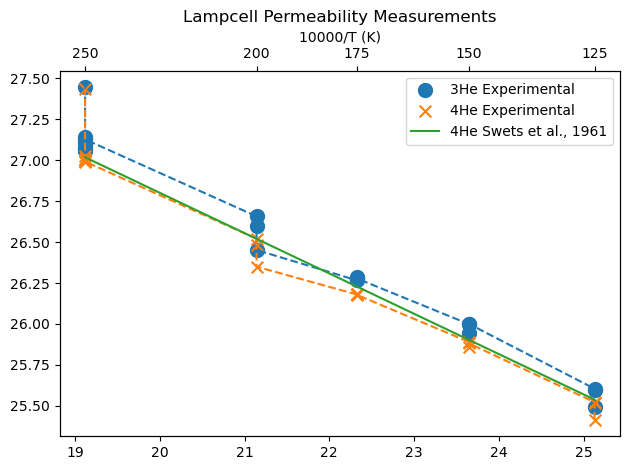

In [359]:
#### MC Permeability experiment Diff Cell Data Reduction 111923

# Sensitivities taken batch 528 or something 


Ra = 1.39E-6
sens4He = 2.899E-2 #ncc/fA
sens3He = 6.66E-3 #pcc/cps
DIFFCELL_name = '111923SmallSIlicaTubeISOTHERMALS.csv'#DIFFCELL_name
h = 1.16 #cm, length of tube
"""OD = 1131 #microns, outer diameter
ID = 736 #microns, inner diameter"""

OD = 1171
ID = 765
#remaining = [,93]

DIFFCELL = pd.read_csv(DIFFCELL_name, header = None).to_numpy()[:-1]
exclude_late_plotting = 1

ID /= 10000 #Convert to cm
OD /= 10000 #Convert to cm
V = h*np.pi*((ID/2)**2) #cc

K0 = 8.25E9/np.exp(-5115/(1.987*287))
Rcal = 1.987
RccATM = 82.06 # cc atm /mol /K
Ratoms = 1.36E-22 # cc atm /atoms /K
cold_loss_time = 0 # minutes (time in dynamic vaccuum where helium permeate is lost, accounted for in total yields)
cold_correct_method = 'measured' # For now, only "measured" is valid. Corrects on the basis of cold permeation data or later by permeability calculations




perm_times = extract_timesMC(DIFFCELL[:,2]) # function definied in dependencies, considers 1st line blank '\n' Coldtimes is of length of reldata    

metadata = DIFFCELL[1:,1] 
TempKelvin = np.array([273+pull_number(str(datum).split(' ')[2]) for datum in metadata])
He3signal = DIFFCELL[1:,4].astype('float')
He4signal = DIFFCELL[1:,6].astype('float')
#He3 = He3signal*sens3He # pccSTP
#He4 = He4signal*sens4He # nccSTP

He3, He4 = reducer.reduce(DIFFCELL[1:], form = '%m/%d/%Y  %H:%M:%S')


signals = [He3signal, He4signal]
IR = np.array((He3/(He4*1E3))/Ra)
total_yields = []

data_holder = {} # Collect Output Spreadsheets for 3He and 4He 

plotable = [] # Remove transition times
for i, Temp in enumerate(TempKelvin):
    if Temp != 273:
        plotable.append(i)
        
print(plotable)
plotable = plotable[:-exclude_late_plotting]
print(plotable)

min_T = np.min(10000/TempKelvin[plotable])
max_T = np.max(10000/TempKelvin[plotable])

fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()
Ctemps = np.array([100,125,150,175,200,250])#np.linspace(200,700, 11,dtype = int)
plt.title(f"Lampcell Permeability Measurements")

for j, He in enumerate([He3,He4]):
    name = ['3He', '4He'][j]
    signal = signals[j]
   ## Permeability Inversion!
    cumYield = [0]

    ####
    #HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
    ####
    
    model_n_n0 = []
    plotable = []
    for i, Temp in enumerate(TempKelvin):
        #print(Temp)
        if Temp != 273:
            #print('Not 273')
            plotable.append(i)
        CPps = He[i] / perm_times[i]
        cumYield.append(He[i] + (CPps*(cold_loss_time*60)) + cumYield[-1])
        model_n_n0.append(tube_permeate2(T = Temp, t = perm_times[i], OD = OD, ID = ID))
 
    plotable = plotable[:-exclude_late_plotting]           
    #total_yield = 
    total_yield = cumYield[-1]
    data_holder[f"{name} TY"] = total_yield
    cumYield = np.array(cumYield)
    fcum = cumYield/total_yield
    n0 = total_yield - cumYield
    molHe = (n0[:-1]/([1000,1][j]))/(22.4*1E12) #convert from nccSTP to moles
    PHeATM = ((molHe*RccATM*TempKelvin)/V)
    PHe = (PHeATM/1.01325)*1E6 # Conv. Atmospheres to microbars
    n_n0 = (n0[:-1]-He)/n0[:-1]


    K = ((-((ID/2)**2)*np.log(OD/ID)*np.log(n_n0))/(perm_times*Ratoms*TempKelvin*2)) # atoms / atm / cm / sec 
    
    data = [(TempKelvin-273).tolist(), (perm_times).tolist(), He, fcum[1:], n0[:-1], n_n0, K, PHe, (10000/TempKelvin).tolist(), np.log(K), model_n_n0]
    columns = ['Temp (C)', 'Time (sec)', f'{name} Yield ({["p","n"][j]}CC@STP)', 'Fcum', 'n0', 'n_n0', 'K (atom /atm /sec /cm)', 'Pressure (Bars)', '10^4/T', 'ln(K)', 'n_n0 Pred']
    Reduced_Data = pd.DataFrame()
    for i, column in enumerate(columns):
        Reduced_Data[column] = data[i]
    newDiffName = DIFFCELL_name[:-4] + f'_{name}_reduced' + '.csv'
    data_holder[name] = Reduced_Data
    Reduced_Data.to_csv(newDiffName)
    print(f"Done! Output file: {newDiffName} in {os.getcwd()}")

    ax1.plot(10000/TempKelvin[plotable], np.log(K)[plotable], linestyle='--')
    ax1.scatter(10000/TempKelvin[plotable], np.log(K)[plotable], marker=['o', 'x'][j], s= [100,70][j], label = f"{name} Experimental")

reference_K = []
for TK in TempKelvin:
    reference_K.append(swets_K(TK))
reference_K = np.array(reference_K)
    
ax1.plot(10000/TempKelvin[plotable], np.log(reference_K[plotable]), label = '4He Swets et al., 1961')
ax2.set_xticks(1E4/(Ctemps+273))
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (°C)')
#ax1.set_xlabel('10^4/T (1/°K)')
#ax1.set_ylabel('ln[D/(a^2)] (1/sec)')
ax1.legend(fontsize = 10)
plt.xlabel('10000/T (K)')
plt.ylabel('log(K) atoms/cm/sec/atm')

#plt.legend()
fig.tight_layout()
plt.savefig(f'{name}silica_permeabilityMC_Sulfur.jpg', dpi = 256)
plt.show()

0     0.073867
1     0.074670
2     0.081757
3     0.097139
4     0.117981
5     0.086425
6     0.107348
7     0.098681
8     0.103592
9     0.088683
10    0.084828
11    0.085684
12    0.099495
13    0.113950
14    0.133487
15    0.131804
16    0.138644
17    0.106758
18    0.063483
19    0.068518
20    0.022706
21         NaN
Name: ln(K), dtype: float64
0     1.076663
1     1.077529
2     1.085193
3     1.102014
4     1.125222
5     1.090270
6     1.113322
7     1.103715
8     1.109148
9     1.092734
10    1.088530
11    1.089462
12    1.104613
13    1.120696
14    1.142806
15    1.140885
16    1.148715
17    1.112665
18    1.065541
19    1.070920
20    1.022966
21         NaN
Name: K (atom /atm /sec /cm), dtype: float64


array([398., 398., 398., 273., 423., 423., 423., 448., 448., 448., 448.,
       273., 473., 473., 473., 523., 523., 523., 523., 523., 523., 523.])

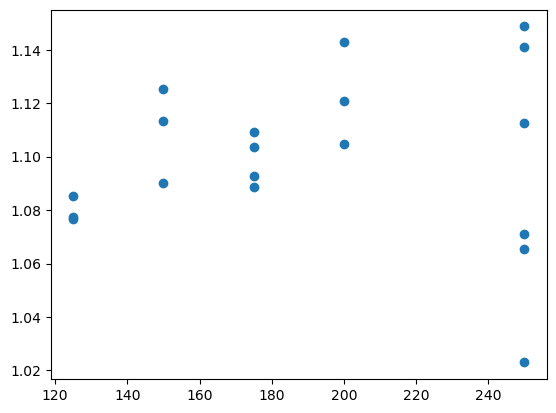

In [236]:
print(data_holder['3He']['ln(K)']-data_holder['4He']['ln(K)'])
print(data_holder['3He']['K (atom /atm /sec /cm)']/data_holder['4He']['K (atom /atm /sec /cm)'])
plt.scatter(data_holder['3He']['Temp (C)'][plotable], (data_holder['3He']['K (atom /atm /sec /cm)']/data_holder['4He']['K (atom /atm /sec /cm)'])[plotable])


TJ = []
TMS = [125, 150, 175, 200, 250]
err = []
measured_PR = []
allPR = data_holder['3He']['K (atom /atm /sec /cm)']/data_holder['4He']['K (atom /atm /sec /cm)']
    for tc in TMS:
        

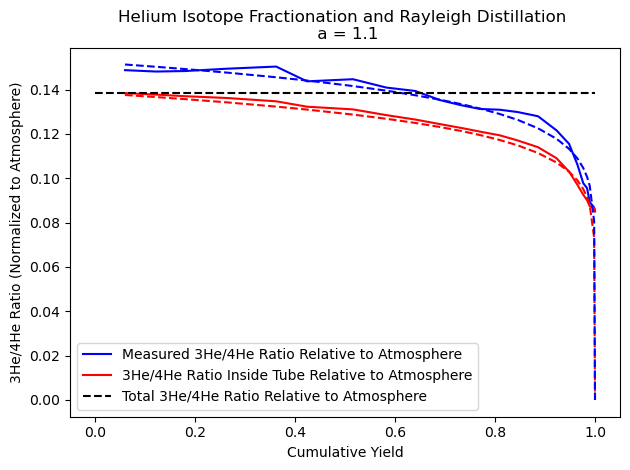

In [371]:
fig = plt.figure()
IR = (data_holder['3He TY']/(1000*data_holder['4He TY']))/1.39E-6
in_tube_IR = (data_holder['3He']['n0']/(1000*data_holder['4He']['n0']))/1.39E-6
a = 1.1#((4/3)**0.50)

rayleigh = IR*((1-data_holder['4He']['Fcum'])**(a-1))
rayleigh_top = rayleigh*(a)

plt.plot(data_holder['4He']['Fcum'], (data_holder['3He']['3He Yield (pCC@STP)']/(1000*data_holder['4He']['4He Yield (nCC@STP)']))/1.39E-6, 'blue', label = 'Measured 3He/4He Ratio Relative to Atmosphere')
plt.plot(data_holder['4He']['Fcum'], in_tube_IR, color = 'r', label = '3He/4He Ratio Inside Tube Relative to Atmosphere')
plt.plot(data_holder['4He']['Fcum'], rayleigh, color = 'r', linestyle = '--')
plt.plot(data_holder['4He']['Fcum'], rayleigh_top, color = 'blue', linestyle = '--')
plt.hlines(IR, 0,1, label = 'Total 3He/4He Ratio Relative to Atmosphere', color = 'k', linestyle = '--')
plt.legend()
plt.xlabel('Cumulative Yield')
plt.ylabel('3He/4He Ratio (Normalized to Atmosphere)')
plt.title(f'Helium Isotope Fractionation and Rayleigh Distillation \n a = {a}')
fig.tight_layout()
plt.savefig(f'Rayleigh_Distillation_a{a}.jpg', dpi = 256)
plt.show()

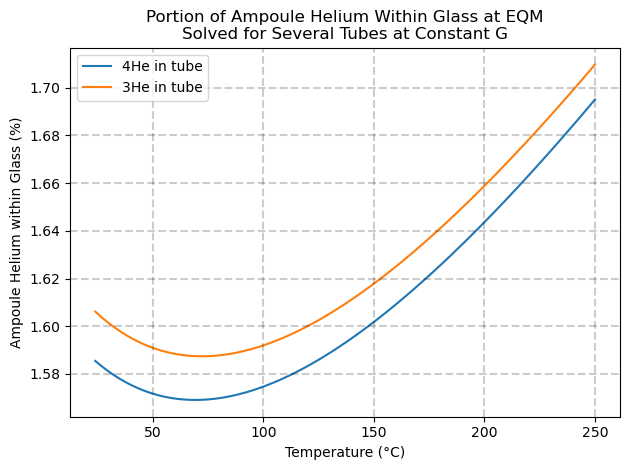

In [317]:
def S3_4(T):
    return(1.003*np.exp(6/(T*1.987)))

Ts = np.linspace(24,250,500)+273
Ss = []
for T in Ts:
    Ss.append(swets('S',T))
Ss = np.array(Ss)

colors = ['Red', 'Black', 'Green', 'Blue','Violet']

aa = 0.054/2
bb = 0.083/2
a = 0.054/2
b = 0.083/2
G = 2/((a**2)*(np.log(b/a)))
#aa = np.array([0.027,0.03,0.04,0.05])
#bb = aa*np.exp(2/(G*(aa**2)))
#Vglass_Vgas = ((bb**2)-(aa**2))/(aa**2)

D = (2*Ratoms/(aa**2))*(((bb**3)-(3*(aa**2)*bb)+(2*(aa**3)))/(6*(bb-aa)))
fig, ax = plt.subplots()
#for i, D in enumerate(Ds):
plt.plot(Ts-273,100*(1/((1/(D*Ts*Ss))+1)), label =f"4He in tube")
plt.plot(Ts-273,100*(1/((1/(D*Ts*Ss*S3_4(Ts)))+1)), label =f"3He in tube")

plt.legend()#title=f'For All Tubes: G = {round(G,1)} cm^-2', loc='best', bbox_to_anchor=(0.5, 0.25))    
plt.xlabel('Temperature (°C)')
plt.ylabel('Ampoule Helium within Glass (%)') 
plt.title('Portion of Ampoule Helium Within Glass at EQM\nSolved for Several Tubes at Constant G')
make_grid()
plt.tight_layout()
plt.savefig('PercentHeInGlassIsotopesGoeth.jpg', dpi = 256)

i:0, j:0, Quad Measured


ValueError: Invalid RGBA argument: 25.0

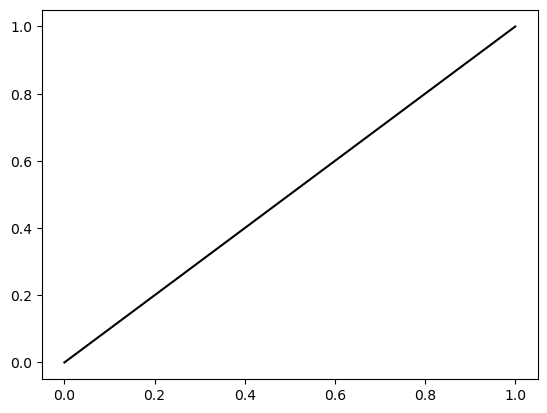

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

# Read data
predDat = pd.read_excel('plotableEmptyTubes.xlsx', sheet_name=None)
labels = ['Empty Ampoule, Quad', 'Empty Ampoule, MC']
markers = ['H', 'd']
vmin, vmax = 24, 300
fig, ax = plt.subplots()

# Add a reference line
plt.plot([0, 1], [0, 1], color='black')

# Loop through sheets and data
for i, table_name in enumerate(predDat):
    table = predDat[table_name]
    if i < 2:
        for j, He in enumerate(['4', '3']):
            print(f"i:{i}, j:{j}, {table_name}")
            if i != 0 or j != 1:
                marker = mpl.markers.MarkerStyle(markers[i], fillstyle=['bottom', 'top'][j])

                # Draw the full outline (layer 1)
                plt.scatter(
                    table[f'{He}He P nt/n0'], table[f'{He}He M nt/n0'],
                    vmin=vmin, vmax=vmax, 
                    c='none',  # Transparent fill
                    edgecolors= table['T'],  # Gradient fill based on temperature
                    cmap='viridis',  # Black outline
                    linewidths=1,  # Outline width
                    marker=markers[i],  # Marker style
                    s=100  # Marker size (adjust as needed)
                )

                # Draw the gradient-filled markers (layer 2)
                plt.scatter(
                    table[f'{He}He P nt/n0'], table[f'{He}He M nt/n0'],
                    c=table['T'],  # Gradient fill based on temperature
                    cmap='viridis',  # Colormap
                    vmin=vmin, vmax=vmax,  # Color normalization
                    marker=marker,  # Marker style
                    s=100,  # Marker size (adjust as needed)
                    label=f"{He}He, {labels[i]}"
                )

# Add colorbar
cbar = plt.colorbar()
cbar.set_label('T (°C)')

# Set plot title and limits
plt.title('Predicting Helium Permeation For Silica Glass Ampoules\nUsing EQN 1.9 and Literature Values for Helium Permeability')
plt.xlim([0, 1])
plt.ylim([0, 1])

# Add grid, legend, and axis labels
ax.grid(True)
plt.legend()
plt.xlabel(r'Predicted $\frac{n_t}{n_0}) = e^{-KGRTt}$')
plt.ylabel(r'Measured $\frac{n_t}{n_0}$')

# Adjust layout and save the figure
plt.tight_layout()
plt.savefig('PredictingPermeation1.9.jpg', dpi=256)
plt.show()

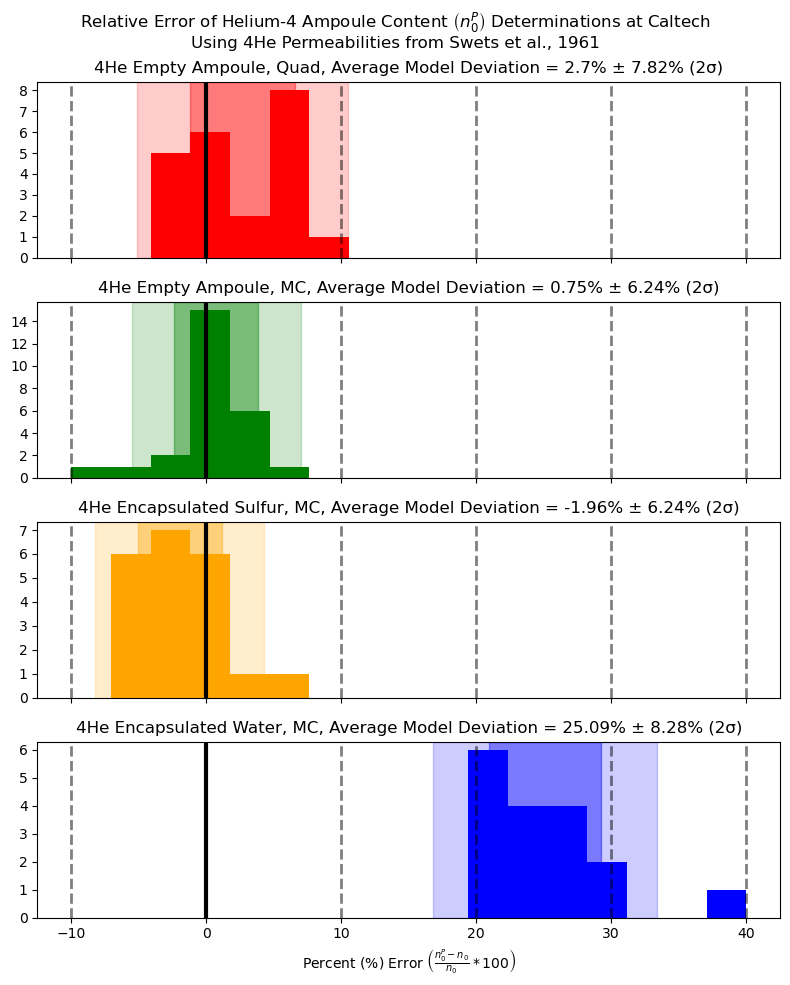

In [258]:
# Read data
predDat = pd.read_excel('plotableEmptyTubes.xlsx', sheet_name=None)
labels = ['Empty Ampoule, Quad', 'Empty Ampoule, MC', 'Encapsulated Sulfur, MC', 'Encapsulated Water, MC']
bins = np.linspace(-10, 40, 18)
colors = ['red', 'green', 'orange', 'blue']

# Create subplots with shared x-axis
fig, axes = plt.subplots(4, 1, sharex=True, figsize=(8, 10))

# Loop through sheets and data
for i, table_name in enumerate(predDat):
    table = predDat[table_name]
    #print(table['4He M% err'])
    # Plot histograms
    #print(table['4He M% err'])
    mean = np.average(table['4He M% err'])
    sd2 = np.std(table['4He M% err'])*2
    if i == 1: # Exclude outlier in MC empty tube experiment
        mean = np.average(table['4He M% err'][:-1])
        sd2 = np.std(table['4He M% err'][:-1])*2
    axes[i].hist(table['4He M% err'], bins=bins, color=colors[i], zorder = 2)
    axes[i].axvspan(mean-sd2, mean+sd2, color=colors[i], alpha=0.2, zorder = 0)
    axes[i].axvspan(mean-(sd2/2), mean+(sd2/2), color=colors[i], alpha=0.4, zorder = 1)
    axes[i].set_title(f"4He {labels[i]}, Average Model Deviation = {round(mean,2)}% ± {round(sd2,2)}% (2σ)")
    axes[i].axvline(x=0, color='black', linewidth=3, zorder = 4) 
    for xi in [-10,10,20,30,40]:
        axes[i].axvline(x=xi, linestyle = '--', color='black', alpha = 0.5, linewidth=2) 
    axes[i].yaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
    
plt.xlabel(r'Percent (%) Error $\left(\frac{n_0^P-n_{0}}{n_{0}}*100\right)$')
fig.suptitle(r'Relative Error of Helium-4 Ampoule Content $\left(n_0^P\right)$ Determinations at Caltech'+'\n'+'Using 4He Permeabilities from Swets et al., 1961')
plt.tight_layout()
plt.savefig('Histograms4He.jpg', dpi = 256)

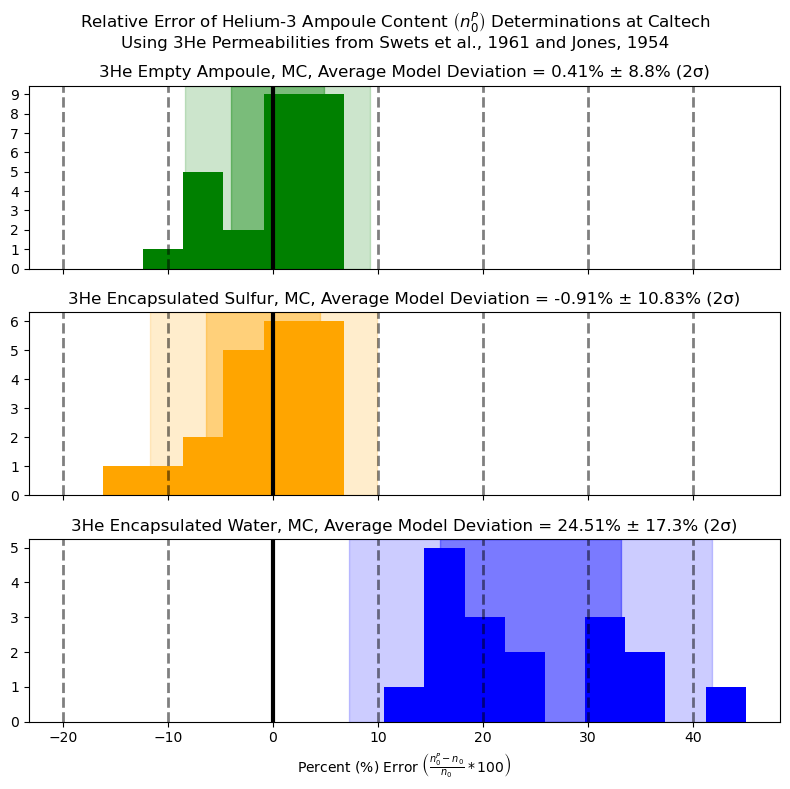

In [260]:
# Read data
predDat = pd.read_excel('plotableEmptyTubes.xlsx', sheet_name=None)
labels = ['Empty Ampoule, Quad', 'Empty Ampoule, MC', 'Encapsulated Sulfur, MC', 'Encapsulated Water, MC']
bins = np.linspace(-20, 45, 18)
colors = ['pink', 'green', 'orange', 'blue']

# Create subplots with shared x-axis
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 8))

# Loop through sheets and data
for i, table_name in enumerate(predDat):
    if i > 0:
        table = predDat[table_name]
        #print(table['4He M% err'])
        # Plot histograms
        mean = np.average(table['3He M% err'])
        sd2 = np.std(table['3He M% err'])*2
        if i == 1: # Exclude outlier in MC empty tube experiment
            mean = np.average(table['3He M% err'][:-1])
            sd2 = np.std(table['3He M% err'][:-1])*2
        axes[i-1].hist(table['3He M% err'], bins=bins, color=colors[i], zorder = 2)
        axes[i-1].axvspan(mean-sd2, mean+sd2, color=colors[i], alpha=0.2, zorder = 0)
        axes[i-1].axvspan(mean-(sd2/2), mean+(sd2/2), color=colors[i], alpha=0.4, zorder = 1)
        axes[i-1].set_title(f"3He {labels[i]}, Average Model Deviation = {round(mean,2)}% ± {round(sd2,2)}% (2σ)")
        axes[i-1].axvline(x=0, color='black', linewidth=3, zorder = 4) 
        for xi in [-20,-10,10,20,30,40]:
            axes[i-1].axvline(x=xi, linestyle = '--', color='black', alpha = 0.5, linewidth=2) 
        axes[i-1].yaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
    
plt.xlabel(r'Percent (%) Error $\left(\frac{n_0^P-n_{0}}{n_{0}}*100\right)$')
fig.suptitle(r'Relative Error of Helium-3 Ampoule Content $\left(n_0^P\right)$ Determinations at Caltech'+'\n'+'Using 3He Permeabilities from Swets et al., 1961 and Jones, 1954')
plt.tight_layout()
plt.savefig('Histograms3He.jpg', dpi = 256)

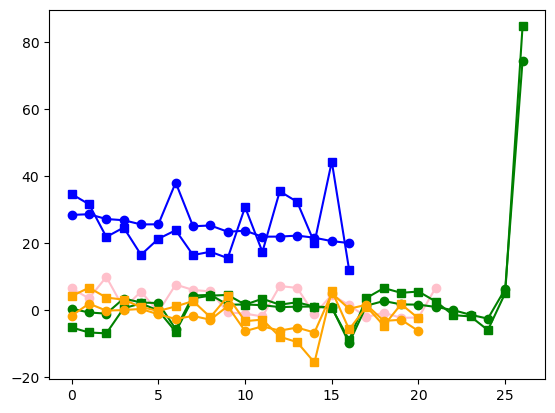

In [261]:
predDat = pd.read_excel('plotableEmptyTubes.xlsx', sheet_name=None)
labels = ['Empty Ampoule, Quad', 'Empty Ampoule, MC', 'Encapsulated Sulfur, MC', 'Encapsulated Water, MC']
bins = np.linspace(-20, 45, 18)
colors = ['pink', 'green', 'orange', 'blue']

# Loop through sheets and data
for i, table_name in enumerate(predDat):
    table = predDat[table_name]
    plt.plot(table['4He M% err'], color = colors[i], marker = 'o')
    if i > 0:
        plt.plot(table['3He M% err'], color = colors[i], marker = 's')

i:0, j:0, Quad Measured
i:0, j:1, Quad Measured
i:1, j:0, MC Measured
i:1, j:1, MC Measured
i:2, j:0, MC Sulfur
i:2, j:1, MC Sulfur
i:3, j:0, MC Water
i:3, j:1, MC Water


C:\Users\dashf\AppData\Local\Temp\ipykernel_24548\3464813860.py:33: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap('viridis')


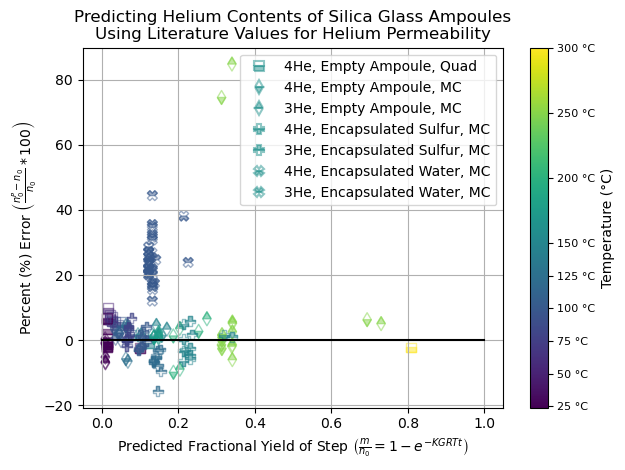

In [251]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
import numpy as np

# Read data
predDat = pd.read_excel('plotableEmptyTubes.xlsx', sheet_name=None)
labels = ['Empty Ampoule, Quad', 'Empty Ampoule, MC', 'Encapsulated Sulfur, MC', 'Encapsulated Water, MC']
markers = ['s', 'd', 'P', 'X']
vmin, vmax = 24, 300
fig, ax = plt.subplots()

# Add a reference line
plt.plot([0, 1], [0, 0], color='black')

# Collect legend handles
legend_handles = []

# Loop through sheets and data
all_temperatures = []  # To collect all temperature values for the colorbar ticks
for i, table_name in enumerate(predDat):
    table = predDat[table_name]
    all_temperatures.extend(table['T'].values)  # Collect temperatures
    for j, He in enumerate(['4', '3']):
        print(f"i:{i}, j:{j}, {table_name}")
        if i != 0 or j != 1:
            marker = mpl.markers.MarkerStyle(markers[i], fillstyle=['bottom', 'top'][j])
            marker1 = mpl.markers.MarkerStyle(markers[i], fillstyle=None)

            # Use the temperature column to define colors
            colors = table['T']
            cmap = mpl.cm.get_cmap('viridis')
            norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
            mapped_colors = cmap(norm(colors), alpha=0.5)

            # Scatter plot with matching edge and fill colors
            scatter = plt.scatter(
                1 - table[f'{He}He P nt/n0'], table[f'{He}He M% err'],
                c=colors,  # Gradient fill
                cmap='viridis',  # Colormap
                alpha=0.5,
                vmin=vmin, vmax=vmax,  # Color normalization
                marker=marker,  # Marker style
                edgecolors=mapped_colors,  # Edge colors match fill colors
                linewidths=1,  # Outline width
                s=50,  # Marker size
                label=f"{He}He, {labels[i]}"
            )

            scatter = plt.scatter(
                1 - table[f'{He}He P nt/n0'], table[f'{He}He M% err'],
                marker=marker1,  # Marker style
                facecolors='none',
                edgecolors=mapped_colors,  # Edge colors match fill colors
                linewidths=1,  # Outline width
                s=50,  # Marker size
                label=f"{He}He, {labels[i]}"
            )

            # Add legend handle for this combination
            legend_handles.append(Line2D(
                [0], [0], marker=marker, color='none',
                markerfacecolor=cmap(norm((vmin + vmax) / 2)),  # Representative color
                markeredgecolor=cmap(norm((vmin + vmax) / 2)),
                markeredgewidth=1.5,
                markersize=7,
                alpha=0.5,
                label=f"{He}He, {labels[i]}"
            ))

# Add colorbar with custom ticks
all_temperatures = [25, 50,75,100,125,150,200,250,300]  # Get unique temperature values
cbar = plt.colorbar()
cbar.set_ticks(norm(all_temperatures))  # Set colorbar ticks to match temperature values
cbar.set_ticklabels([f"{int(t)} °C" for t in all_temperatures])  # Add temperature labels
cbar.set_label('Temperature (°C)', fontsize=10)
cbar.ax.tick_params(labelsize=8)

# Set plot title and limits
plt.title('Predicting Helium Contents of Silica Glass Ampoules\nUsing Literature Values for Helium Permeability')
plt.xlabel(r'Predicted Fractional Yield of Step $\left(\frac{m}{n_0} = 1-e^{-KGRTt}\right)$')
plt.ylabel(r'Percent (%) Error $\left(\frac{n_0^P-n_{0}}{n_{0}}*100\right)$')
#plt.xlim([0,0.4])
#plt.ylim([-20,40])
# Add grid, legend, and axis labels
ax.grid(True)
plt.legend(handles=legend_handles, fontsize=10)
plt.tight_layout()

# Save and display the plot
plt.savefig('PredictingPermeation1.9_with_ticksOUT.jpg', dpi=256)
plt.show()


In [71]:
predDat = pd.read_excel('plotableEmptyTubes.xlsx', sheet_name=None)
labels = ['Empty Ampoule, Quad', 'Empty Ampoule, MC', 'Encapsulated Sulfur, MC', 'Encapsulated Water, MC']
markers = ['s', 'd', 'P', 'X']
vmin, vmax = 24, 300
fig, ax = plt.subplots()

# Add a reference line
plt.plot([0, 1], [0, 0], color='black')

# Collect legend handles
legend_handles = []

# Loop through sheets and data
all_temperatures = []  # To collect all temperature values for the colorbar ticks
for i, table_name in enumerate(predDat):
    table = predDat[table_name]
    all_temperatures.extend(table['T'].values)  # 

i:0, j:0, Quad Measured
i:0, j:1, Quad Measured
i:1, j:0, MC Measured
i:1, j:1, MC Measured


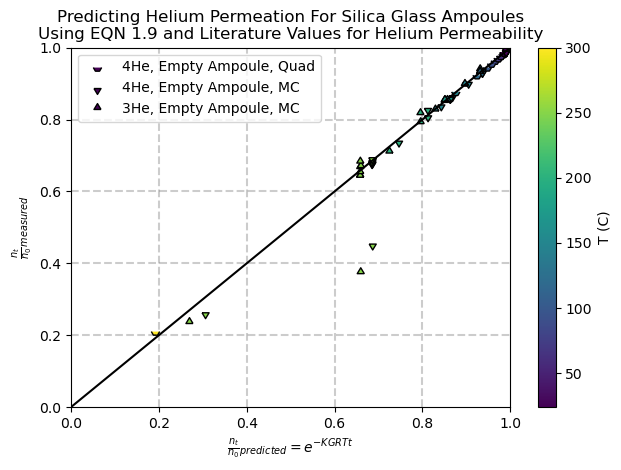

In [26]:
predDat = pd.read_excel('plotableEmptyTubes.xlsx', sheet_name = None)
labels  = ['Empty Ampoule, Quad', 'Empty Ampoule, MC']
markers = ['H','d']
vmin, vmax = 24, 300
fig, ax = plt.subplots()
plt.plot([0,1], [0,1], color = 'black')
for i, table_name in enumerate(predDat):
    table = predDat[table_name]
    if i < 2:
        for j, He in enumerate(['4','3']):
            print(f"i:{i}, j:{j}, {table_name}")
            if i != 0 or j != 1:
                #print(labels[i])
                marker = mpl.markers.MarkerStyle(markers[i],  fillstyle = ['bottom', 'top'][j])
                plt.scatter(table[f'{He}He P nt/n0'], table[f'{He}He M nt/n0'], c = table['T'], marker = marker, vmin = vmin, vmax = vmax, edgecolors = 'black', linewidth = 1, label = f"{He}He, {labels[i]}")
cbar = plt.colorbar()
cbar.set_label('T (C)')
plt.title('Predicting Helium Permeation For Silica Glass Ampoules\nUsing EQN 1.9 and Literature Values for Helium Permeability')
plt.xlim([0,1])
plt.ylim([0,1])
make_grid()
plt.legend()
plt.xlabel(r'Predicted $\frac{n_t}{n_0}) = e^{-KGRTt}$')
plt.ylabel(r'Measured $\frac{n_t}{n_0}$')
plt.tight_layout()
plt.savefig('PredictingPermeation1.9.jpg', dpi = 256)
plt.show()

In [3]:
def MC4_perm(T):
    return 8.46E13*np.exp(-5217.9/(Rcal*T))
def MC3_perm(T):
    return 9.46E13*np.exp(-5235.7/(Rcal*T))

def MC4_perm2(T):
    return 6.70E13*np.exp(-5021.15/(Rcal*T))
def MC3_perm2(T):
    return 8.78E13*np.exp(-5172/(Rcal*T))

def Jones(T):
    return 1.17*np.exp(-57/(Rcal*T))

JTK = [798.3, 682.3, 568.4, 472.6, 425.6, 356.8, 273.16]
JPR = [1.124, 1.125, 1.114, 1.1, 1.096, 1.078, 1.053]

means = []
err = []
TMS = [125, 150, 175, 200, 250]
for TM in TMS:
    isotherms = data_holder['3He']['Temp (C)'][plotable] == TM
    data = (data_holder['3He']['K (atom /atm /sec /cm)']/data_holder['4He']['K (atom /atm /sec /cm)'])[plotable][isotherms]
    means.append(np.mean(data))
    err.append((np.std(data)*2)/(len(data)**(1/2)))
    
PR = []
PR2 = []
J = []
Ts = np.linspace(200,1000,1000)
for TK in Ts:
    PR.append(MC3_perm(TK)/MC4_perm(TK))
    PR2.append(MC3_perm2(TK)/MC4_perm2(TK))
    J.append(Jones(TK))
    
#plt.plot(Ts-273, PR, label = 'Independent 3He permeability fit model')
#plt.plot(Ts-273, PR2, label = 'Independent 3He permeability fit model exclude last points')
plt.plot(Ts-273, J, label = 'Permeability Relationship Model from Jones, 1953')
#plt.scatter(data_holder['3He']['Temp (C)'][plotable], (data_holder['3He']['K (atom /atm /sec /cm)']/data_holder['4He']['K (atom /atm /sec /cm)'])[plotable], label = 'Measured Relative Permeabilities')
plt.scatter(np.array(JTK)-273, JPR, label = 'Data from Jones, 1953')
#for i, datum in enumerate((data_holder['3He']['K (atom /atm /sec /cm)']/data_holder['4He']['K (atom /atm /sec /cm)'])[plotable]):
#    plt.text((data_holder['3He']['Temp (C)'][plotable]).to_numpy()[i], datum, i)
plt.errorbar(TMS, means, err, err, linestyle = ' ', capsize=5, label = 'Measured Relative Permeabilities')
plt.legend()
plt.xlabel('Temperature (C)')
plt.ylabel('K (3He) / K (4He)')
plt.title('Relative Helium-3/4 Permeabilities')
plt.savefig("Permeability_Ratios.jpg", dpi = 256)
plt.show()

NameError: name 'data_holder' is not defined

In [231]:
bins = np.linspace(-4, 6, 20)

# Create subplots with shared x-axis
fig, axes = plt.subplots(4, 1, sharex=True, figsize=(8, 10))

# Plot histograms
axes[0].hist(data1, bins=bins, color='blue', alpha=0.7)
axes[0].set_ylabel('Frequency')
axes[0].set_title('Histogram 1')

1.0801234497346432

In [361]:
data_holder['3He']['Temp (C)'][plotable]

0     125.0
1     125.0
2     125.0
4     150.0
5     150.0
6     150.0
7     175.0
8     175.0
9     175.0
10    175.0
12    200.0
13    200.0
14    200.0
15    250.0
16    250.0
17    250.0
18    250.0
19    250.0
20    250.0
21    250.0
Name: Temp (C), dtype: float64

In [264]:
(data_holder['3He']['Temp (C)'][plotable])

0     125.0
1     125.0
2     125.0
4     150.0
5     150.0
6     150.0
7     175.0
8     175.0
9     175.0
10    175.0
12    200.0
13    200.0
14    200.0
15    250.0
16    250.0
17    250.0
18    250.0
19    250.0
20    250.0
21    250.0
Name: Temp (C), dtype: float64

C:\Users\dashf\AppData\Roaming\Python\Python38\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


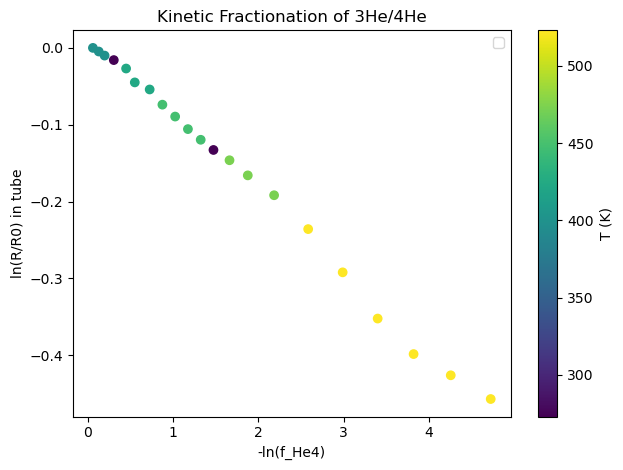

In [235]:
fig = plt.figure()
IR = (data_holder['3He TY']/(1000*data_holder['4He TY']))/1.39E-6
in_tube_IR = (data_holder['3He']['n0']/(1000*data_holder['4He']['n0']))/1.39E-6
a = 1.08#((4/3)**0.50)

rayleigh = IR*((1-data_holder['4He']['Fcum'])**(a-1))
rayleigh_top = rayleigh*(a)




#plt.plot(data_holder['4He']['Fcum'], (data_holder['3He']['3He Yield (pCC@STP)']/(1000*data_holder['4He']['4He Yield (nCC@STP)']))/1.39E-6, 'blue', label = 'Measured 3He/4He Ratio Relative to Atmosphere')
#plt.plot(data_holder['4He']['Fcum'], in_tube_IR, color = 'r', label = '3He/4He Ratio Inside Tube Relative to Atmosphere')
#plt.plot(data_holder['4He']['Fcum'], rayleigh, color = 'r', linestyle = '--')
#plt.plot(data_holder['4He']['Fcum'], rayleigh_top, color = 'blue', linestyle = '--')
#plt.hlines(IR, 0,1, label = 'Total 3He/4He Ratio Relative to Atmosphere', color = 'k', linestyle = '--')
plt.scatter(-np.log(1-data_holder['4He']['Fcum']), np.log(in_tube_IR/IR), c = TempKelvin)
cbar = plt.colorbar()
cbar.set_label('T (K)')
plt.legend()
plt.xlabel('-ln(f_He4)')
plt.ylabel('ln(R/R0) in tube')
plt.title('Kinetic Fractionation of 3He/4He')
fig.tight_layout()
plt.savefig('Kinetic3He4HePermeability.jpg')
plt.show()

In [ ]:
def swets_S(T):
    """Returns solubility of fused Silica in units: mol/cm/s/atm for a given T in Kelvin"""
    if T >= 573:
        DEa = 6613 # factor of 4 to convert from g Helium to moles
        SEa = -1174
        DFF = 7.40E-4
        SFF = 1.28E17
    else:
        DEa = 5580
        SEa = -680
        DFF = 3.04E-4
        SFF = 1.99E17
        
    D = DFF*np.exp(-DEa/(Rcal*T))
    S = SFF*np.exp(-SEa/(Rcal*T)) # K units: atom/cm/s/dP atm/
    #print(f"Solubility at T = {T-273}C: {S} atoms/cm3/atm")
    #print(f"Diffusivity at T = {T-273}C: {D} cm2/s")
    #print(f"Permeation at T = {T-273}C in mol/cm/s/atm: {D*S}")
    K = D*S#/6.022E23 #units: mol/cm/s/atm
    return S

T = np.linspace(20,1000,1000) #Kelvin
S = []
for t in T:
    S.append(swets_S(t))

# for 1 cc 1 atm
N_air = 1/(Ratoms*T)
plt.plot(T, N_air/np.array(S))
plt.title('Relative number densities of Helium in glass-gas system')
plt.ylabel('He(gas)/He(glass)')
plt.xlabel('T (K)')
plt.show()

Assuming all standards analyzed had 157.5 nCCSTP 4He and 3.57 pCCSTP 3He
[ 7.69504038e-03  0.00000000e+00  5.10379248e-03  8.96889033e-03
  1.07657471e-02  1.10086613e-02  1.33036329e-02  1.67165814e-02
  3.48687934e-06  3.98363379e-02  5.66503515e-02  3.90186707e-02
  2.85070228e-02  4.28298509e-03  0.00000000e+00  9.28612830e-05
 -2.10314951e-05  2.43278371e-02  2.87032216e-06  2.18994436e-04
  0.00000000e+00  6.19886943e-03  2.09649378e-02  3.77123251e-02
  2.11352901e-02  1.70034192e-02  1.61456590e-02  1.35377105e-02
  1.26371078e-02  9.00108825e-03  9.84297785e-03  7.52919032e-03
  4.79333654e-03  4.65709828e-03  1.04758614e-02  1.26442740e-02
  1.77049201e-02  2.04302769e-02  3.15157062e-02  1.80754620e-02
  1.74683133e-02  1.35516847e-02  1.13926286e-02  7.82361171e-03
  2.52066362e-02  3.70841326e-02  4.65490838e-02  6.04432652e-02
  6.89575445e-02  6.91229578e-02  3.80899368e-02  2.43724207e-02]
ignoring 3He step 1, real temp: 298.0, target temp: 273.0 with signal 0.0
ignorin

C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2462423878.py:84: RuntimeWarning: divide by zero encountered in log
  lnD_a2.append(np.log(frequency_factor))
C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2462423878.py:84: RuntimeWarning: invalid value encountered in log
  lnD_a2.append(np.log(frequency_factor))
C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2462423878.py:110: RuntimeWarning: divide by zero encountered in log10
  ax1.scatter(10000/realTempKelvin[good_steps], np.array(lnD_a2)[good_steps], c = np.log10(IR[real_steps][good_steps]), label = 'Data')


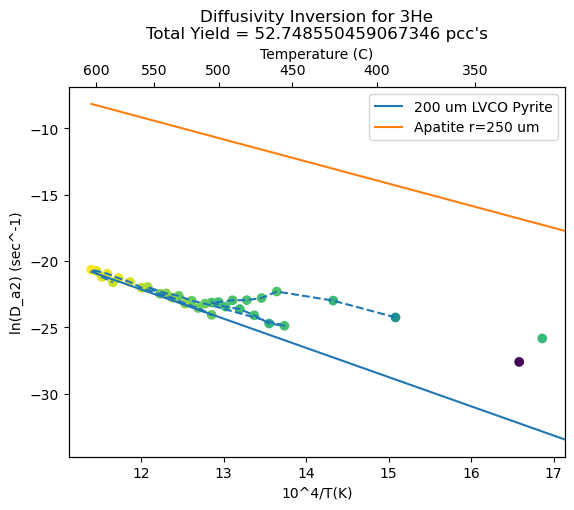

C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2462423878.py:148: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(fcum[good_steps], delta_Diff, c = np.log10(IR[real_steps][good_steps]))


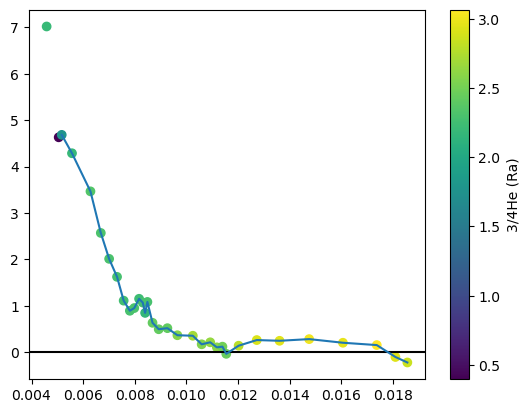

C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2462423878.py:110: RuntimeWarning: divide by zero encountered in log10
  ax1.scatter(10000/realTempKelvin[good_steps], np.array(lnD_a2)[good_steps], c = np.log10(IR[real_steps][good_steps]), label = 'Data')


[0.0867822  0.01258637 0.01779733 0.01949816 0.01589506 0.01566651
 0.01653475 0.01453541 0.0080843  0.01782228 0.02538471 0.02373236
 0.02196212 0.01988501 0.01623962 0.01024485 0.01374758 0.01227664
 0.08183047 0.0632168  0.06460135 0.07434708 0.09850111 0.12335264
 0.07410398 0.06109513 0.06109513 0.05412611 0.04622788 0.03182522
 0.04251153 0.02834738 0.0234785  0.01712302 0.02816314 0.03399684
 0.04940365 0.03939885 0.0454893  0.03547351 0.02848381 0.02429443
 0.02641015 0.02043281 0.02969386 0.03227111 0.03835658 0.04234541
 0.05365063 0.04279832 0.03147408 0.02449914]
ignoring 4He step 1, real temp: 298.0, target temp: 273.0 with signal 0.541
ignoring 4He step 8, real temp: 298.13, target temp: 273.0 with signal 0.347
ignoring 4He step 9, real temp: 299.0, target temp: 293.0 with signal 0.765
ignoring 4He step 17, real temp: 304.95, target temp: 295.0 with signal 0.528
Done! Output file: LVCOPy230630_4He_reduced.csv in C:\Users\dashf\pyrite


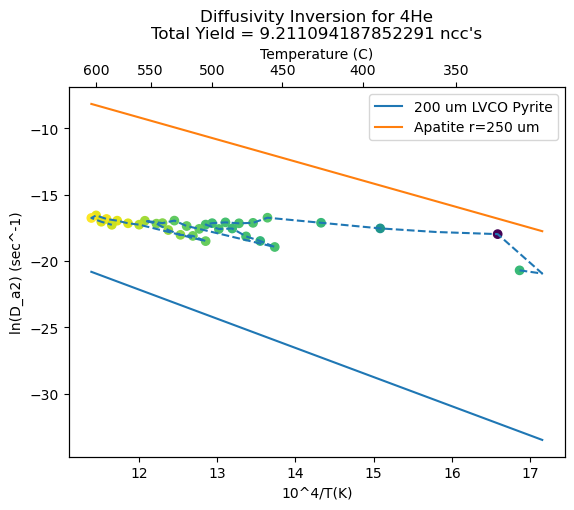

C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2462423878.py:148: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(fcum[good_steps], delta_Diff, c = np.log10(IR[real_steps][good_steps]))


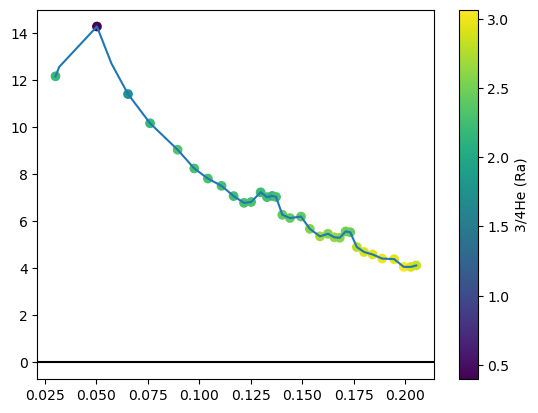

In [674]:
os.listdir('NGL Watlow Heat Log')

['16.0 Watlow.txt',
 '17.0 Watlow.txt',
 '18.0 Watlow.txt',
 '25851 Watlow.txt',
 '25885 Watlow.txt',
 '25886 Watlow.txt',
 '25913 Watlow.txt',
 '25922 Watlow.txt',
 '25923 Watlow.txt',
 '25924 Watlow.txt',
 '25928 Watlow.txt',
 '25929 Watlow.txt',
 '25971 Watlow.txt',
 '25973 Watlow.txt',
 '25974 Watlow.txt',
 '25994 Watlow.txt',
 '25995 Watlow.txt',
 '25997 Watlow.txt',
 '26000 Watlow.txt',
 '26003 Watlow.txt',
 '26005 Watlow.txt',
 '26007 Watlow.txt',
 '26009 Watlow.txt',
 '26065 Watlow.txt',
 '26073 Watlow.txt',
 '26076 Watlow.txt',
 '26077 Watlow.txt',
 '26080 Watlow.txt',
 '26081 Watlow.txt',
 '26102 Watlow.txt',
 '26104 Watlow.txt',
 '26105 Watlow.txt',
 '26108 Watlow.txt',
 '26109 Watlow.txt',
 '26111 Watlow.txt',
 '26112 Watlow.txt',
 '26116 Watlow.txt',
 '26117 Watlow.txt',
 '26119 Watlow.txt',
 '26121 Watlow.txt',
 '26124 Watlow.txt',
 '26133 Watlow.txt',
 '26135 Watlow.txt',
 '26137 Watlow.txt',
 '26139 Watlow.txt',
 '26141 Watlow.txt',
 '26144 Watlow.txt',
 '26148 Watlow.t

In [677]:
#Finding Long Steps

for file in os.listdir('NGL Watlow Heat Log'):
    with open(f'NGL Watlow Heat Log/{file}') as text:
        final_line = text.readlines()[-1]
        print(final_line)

7431.333	173.000

7431.554	174.000

7429.697	167.000

7429.379	173.000

7430.128	174.000

7429.621	167.000

7429.833	173.000

7429.806	173.000

7430.869	167.000

7429.339	172.000

7415.940	172.000

7429.717	167.000

7430.020	171.000

7415.091	171.000

7431.763	167.000

7429.360	170.000

7429.904	168.000

7430.038	167.000

7365.654	25.000

239.154	24.000

3725.982	24.000

3759.462	25.000

3760.476	24.000

3763.825	24.000

3762.821	25.000

7429.933	166.000

3812.863	60.000

3777.379	79.000

3809.836	52.000

3808.469	90.000

3826.709	63.000

3726.724	23.000

3824.727	67.000

3845.660	103.000

3761.492	24.000

3759.490	24.000

7364.579	26.000

3845.297	74.000

3813.279	109.000

3826.425	83.000

3825.685	114.000

3824.693	76.000

7207.346	20.000

3874.766	83.000

3842.423	61.000

3761.844	24.000

3762.230	25.000

7364.014	25.000

3858.587	88.000

3826.877	54.000

3844.777	107.000

3824.554	61.000

3858.388	108.000

71786.956	93.000

4019.683	102.000

3825.395	129.000

3759.440	24.000

3759.

14624.219	134.000

7927.917	321.000

14625.114	126.000

3730.128	181.000

14624.053	134.000

8528.006	313.000

14642.426	126.000

3730.265	180.000

14625.381	133.000

9130.072	314.000

14626.821	126.000

3724.443	181.000

14626.391	134.000

9727.956	307.000

14626.283	127.000

3724.403	181.000

14626.615	133.000

10330.794	304.000

281.546	25.000

14627.398	127.000

3724.576	181.000

14624.500	133.000

10925.086	302.000

14623.882	127.000

3725.716	180.000

14626.240	133.000

7326.782	334.000

14641.836	127.000

3725.613	182.000

14626.785	133.000

7326.864	346.000

14640.759	127.000

3724.407	181.000

14626.391	133.000

7327.582	358.000

14624.955	127.000

3731.629	181.000

14578.714	23.000

7326.042	372.000

120.339	25.000

14578.585	23.000

3724.389	181.000

14624.144	134.000

7326.693	373.000

14626.058	127.000

3726.455	179.000

14644.095	134.000

7321.714	363.000

14626.464	127.000

3726.815	179.000

14624.421	134.000

7325.798	356.000

14625.639	128.000

3732.025	178.000

29043.

3787.780	26.000

3825.143	185.000

3843.006	72.000

3846.575	207.000

3845.184	201.000

3858.296	81.000

7428.857	166.000

3824.918	227.000

3824.602	214.000

3877.637	153.000

3841.650	234.000

3606.757	27.000

3862.608	223.000

3878.765	179.000

3843.215	239.000

3844.461	223.000

3858.481	179.000

3843.846	238.000

7428.815	166.000

3862.595	221.000

3858.089	161.000

3877.601	194.000

3841.838	239.000

1924.396	93.000

3860.927	179.000

3858.600	175.000

3878.826	245.000

3857.325	214.000

3858.417	161.000

3840.896	247.000

175.272	24.000

3863.204	226.000

3857.957	144.000

3878.766	249.000

5066.637	227.000

197.234	26.000

3859.295	123.000

3857.456	254.000

6260.898	229.000

3873.681	117.000

3856.674	262.000

3875.801	185.000

7412.591	165.000

7461.519	224.000

5065.292	262.000

5083.067	195.000

6259.504	262.000

186.200	26.000

8674.109	223.000

6274.921	218.000

7447.408	260.000

7465.371	227.000

9252.136	222.000

8654.927	260.000

7428.817	165.000

8671.995	233.000

806

IndexError: list index out of range

In [11]:
DIFFCELL_name = 'CCpTS230630.csv'#DIFFCELL_name
DIFFCELL = pd.read_csv(DIFFCELL_name, header = None).to_numpy()
DIFFCELL

array([['He27083.txt', 'CCpTS230630: 487_240.0_200.0 199.98',
        '7/1/2023 11:56:41 PM', 0.0, 3.309145, 0.0, 4.89598, nan],
       ['He27088.txt', 'CCpTS230630: 490_60.0_0.0 27.00',
        '7/2/2023 1:48:49 AM', 0.0, 0.01460434, -0.0, 0.3691864, nan],
       ['He27094.txt', 'CCpTS230630: 493_60.0_250.0 249.98',
        '7/2/2023 4:17:04 AM', 0.0, 4.524488, 0.0, 1.48793, nan],
       ['He27098.txt', 'CCpTS230630: 496_60.0_260.0 260.01',
        '7/2/2023 6:07:36 AM', 0.0, 8.831368, 0.0, 1.162437, nan],
       ['He27103.txt', 'CCpTS230630: 499_60.0_270.0 269.99',
        '7/2/2023 7:58:05 AM', 0.0, 8.928153, 0.0, 0.9436631, nan],
       ['He27107.txt', 'CCpTS230630: 502_60.0_280.0 279.97',
        '7/2/2023 9:48:29 AM', 0.0, 10.67631, 0.0, 0.9489143, nan],
       ['He27112.txt', 'CCpTS230630: 505_60.0_290.0 289.99',
        '7/2/2023 11:39:18 AM', 0.0, 12.04167, 0.003482785, 0.8441355,
        nan],
       ['He27114.txt', 'CCpTS230630: 508_60.0_0.0 26.04',
        '7/2/2023 1:05:03

In [65]:
print(n0_modeled)
print(n1_modeled)
print(HenCC[colds])
print((n0_modeled-n1_modeled)-HenCC[colds])

[30.4114667  12.46000834 12.24029124 10.25595107  9.69821689  9.5467059
  5.0188988   4.72110382]
[30.0180117  12.26396734 12.04802824 10.09597007  9.53243389  9.3835409
  4.9397768   4.64015082]
[0.393455 0.196041 0.192263 0.159981 0.165783 0.163165 0.079122 0.080953]
[ 1.16684440e-13  5.07649478e-14  6.98052727e-14  1.25732758e-14
 -2.73114864e-14 -2.90878432e-14 -2.76167977e-14 -2.83661983e-14]


In [24]:
tot = 0
with open('heatsched.txt') as sched:
    lines = sched.readlines()
    for line in lines:
        tot += float(line.split(',')[0])
        tot += 45
print(tot/60)

70.0


In [26]:
P = 1E5 #Pa
R = 8314 # (L)(Pa)(K^-1)(mol^-1)
V = (0.5*0.1*0.1)/1000 # cc (mL) to L
T = 773
n = (P*V)/(R*T)
print((n*64)*1000) # mg's

0.004979210241239626


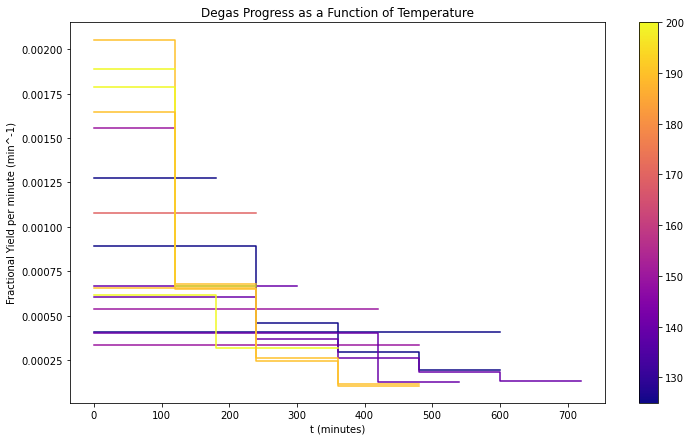

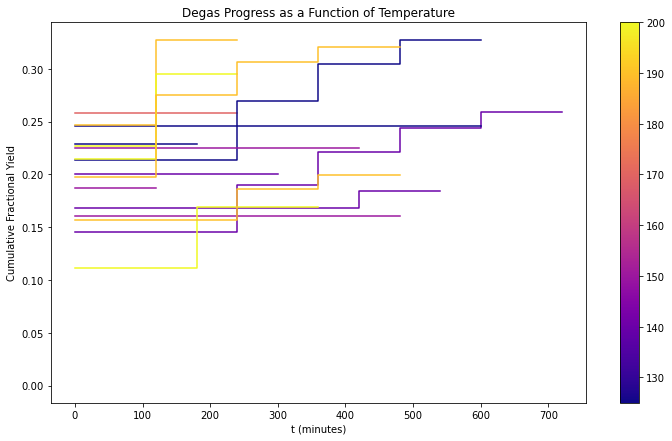

In [47]:
reextract_data = np.genfromtxt('reextract_data.csv', delimiter= ',')
import matplotlib
cmap = matplotlib.cm.get_cmap('plasma')
def get_col(T):
    col = cmap((T-125.2)/75)
    return col

reextract_data[0,0] = 140
reextract_data
prev_m = reextract_data[0,2]
prev_T = reextract_data[0,0]
X = []
Y = []
for reextract in reextract_data:
    T = reextract[0]
    F = reextract[1]
    m = reextract[2]
    if T != prev_T or m < prev_m:
        prev_m = 0
        #print(X)
        #print(Y)
        #print(T)
        plt.plot(X,Y, c = get_col(T))
        X = []
        Y = []
    X += [prev_m, m]
    Y += [F, F]
    prev_T = T
    prev_m = m
plt.plot(X,Y, c = get_col(T))
plt.xlabel('t (minutes)')
plt.ylabel('Fractional Yield per minute (min^-1)')
plt.title('Degas Progress as a Function of Temperature')
plt.colorbar(matplotlib.cm.ScalarMappable(norm = matplotlib.colors.Normalize(vmin=125, vmax=200, clip=False), cmap = 'plasma'))
#plt.legend()
fig = matplotlib.pyplot.gcf()
fig.set_size_inches(12,7)
fig.savefig('fractional_degas.png', dpi=100)
plt.show()



reextract_data[0,0] = 140
reextract_data
prev_m = reextract_data[0,2]
prev_T = reextract_data[0,0]
X = []
Y = []
F_cum = 0
for reextract in reextract_data:
    T = reextract[0]
    F = reextract[1]
    m = reextract[2]
    if T != prev_T or m < prev_m:
        prev_m = 0
        #print(X)
        #print(Y)
        #print(T)
        plt.plot(X,Y, c = get_col(T))
        X = []
        Y = []
        F_cum = 0
    F_cum += F*(m-prev_m)
    X += [prev_m, m]
    Y += [F_cum, F_cum]
    prev_T = T
    prev_m = m
plt.plot(X,Y, c = get_col(T))
plt.xlabel('t (minutes)')
plt.ylabel('Cumulative Fractional Yield')
plt.title('Degas Progress as a Function of Temperature')
plt.colorbar(matplotlib.cm.ScalarMappable(norm = matplotlib.colors.Normalize(vmin=125, vmax=200, clip=False), cmap = 'plasma'))
#plt.legend()
fig = matplotlib.pyplot.gcf()
fig.set_size_inches(12,7)
fig.savefig('fractional_degas.png', dpi=100)
plt.show()

In [6]:
AgeBlock = np.genfromtxt('pyrite_age_block.csv', delimiter=',')
print(AgeBlock)
newHE = np.append(AgeBlock, np.zeros((np.shape(AgeBlock)[0],2)), axis = 1)
namestr = '2211KC_Py_ST05_C\n2211KC_Py_ST05_A\n2211KC_Py_ST05_B\n2211KC_Py_ST05_D\n2211KC_Py_ST05_DU1\n2211KC_Py_ST05_DU2\n2211KC_Py_ST05_DU3\n12122022KCPyST05A\n12122022KCPyST05B\n12122022KCPyST05C\n12122022KCPyST05D\n2211GFr_PyA\n2211GFr_PyB\n2211StFr_PyA\n2211StFr_PyB\n2211AtmFr_PyC\n2211DApA\n2211DApC\n2211DApD\n2022StDApA\n2211HemMSA\n2211HemMSB\n'
names = namestr.split('\n')[:-1]
print(names)
print(newHE)


[[4.70798002e+02 2.35399001e+01 1.47000000e-11 8.71000000e-13
  2.68000000e-11 6.54000000e-13 3.15000000e-12 1.76000000e-13]
 [3.17914352e+02 1.58957176e+01 7.44000000e-12 1.42000000e-13
  2.92000000e-11 5.52000000e-13 2.88000000e-12 1.91000000e-13]
 [1.65000000e+02 8.25000000e+00 5.13000000e-12 3.06000000e-13
  9.49000000e-12 1.97000000e-13 2.35000000e-12 1.40000000e-13]
 [1.65819109e+02 8.29095545e+00 4.38000000e-12 1.38000000e-13
  6.18000000e-12 1.95000000e-13 4.91000000e-13 6.18000000e-14]
 [           nan            nan 5.48000000e-12 2.37000000e-13
  1.26000000e-11 3.21000000e-13 1.13000000e-12 1.12000000e-13]
 [           nan            nan 8.01000000e-12 1.37000000e-13
  2.23000000e-11 6.28000000e-13 4.13000000e-13 8.61000000e-14]
 [           nan            nan 4.55000000e-12 1.55000000e-13
  1.17000000e-11 3.37000000e-13 1.22000000e-12 1.37000000e-13]
 [1.42290215e+03 7.11451072e+01            nan            nan
             nan            nan            nan            nan]


In [21]:
filename = 'franklin_0.12ppm'
AgeBlock = pd.read_csv(filename+'.csv', header = None).to_numpy()
#print(AgeBlock)
nsamples = np.shape(AgeBlock)[0]
ncols = np.shape(AgeBlock)[1]
#BigNewHE = np.append(AgeBlock, np.zeros((nsamples,6)), axis = 1)
#namestr = '2211KC_Py_ST05_C\n2211KC_Py_ST05_A\n2211KC_Py_ST05_B\n2211KC_Py_ST05_D\n2211KC_Py_ST05_DU1\n2211KC_Py_ST05_DU2\n2211KC_Py_ST05_DU3\n12122022KCPyST05A\n12122022KCPyST05B\n12122022KCPyST05C\n12122022KCPyST05D\n2211GFr_PyA\n2211GFr_PyB\n2211StFr_PyA\n2211StFr_PyB\n2211AtmFr_PyC\n2211DApA\n2211DApC\n2211DApD\n2022StDApA\n2211HemMSA\n2211HemMSB\n'
#names = namestr.split('\n')[:-1]
dates = np.zeros((nsamples,6))
UThSm = AgeBlock[:,6:12]
t_labels = ['No Atm Corr.', 'Atm Corr.', 'Fractional Atm Corr.']
#print(UThSm)
for t in range(3):
    newHe = np.append(AgeBlock[:,(t*2):((t*2)+2)], UThSm, axis = 1)
    for i in range(nsamples):
        if np.sum(UThSm[i]) > 0 and np.sum(newHe[i,:2]) > 0:
            #try:
            dates[i,(t*2):((t*2)+2)] = MC_Age(newHe[i,:8], n = 2000)
            #except:
            #    print(f"Convergence failure for sample {i} with {t_labels[t]}... Proceeding")
            print(f"{(t*33)+((i/nsamples)*33)}% Complete")
            #print(f"Sample {name} Imported: {newHE[i,2:8]}\n Age Calculated: {newHE[i,8:10]}\n")
            #print(np.sum(UThSm))
BigNewHE = np.append(AgeBlock, dates, axis = 1)
QuadOutDF = pd.DataFrame(BigNewHE)#, index = names)
QuadOutDF.to_csv(filename+'_reduced'+'.csv')

0.0% Complete
6.6000000000000005% Complete
13.200000000000001% Complete
19.8% Complete
26.400000000000002% Complete
33.0% Complete
39.6% Complete
46.2% Complete
52.8% Complete
59.400000000000006% Complete


> **5. Manual (U-Th-Sm)/He Age Calculator**

Thermochreduction calulates ages iteratively by evaluating the He production equation (given U, Th, and Sm contents) across a searched range of ages. After each iteration, it 'zooms in' to a new, smaller range surrounding the previous best answer until an age is found that reproduces the He content within some predefined error threshold: called 'epsilon' in the code.

The equation for Helium production is:

$He_{atoms} = \left(8*U_{atoms}(e^{{}^{238}\lambda t}-1)\right)
+\left(7*\frac{U_{atoms}}{137.88}(e^{{}^{235}\lambda t}-1)\right)
+\left(6*Th_{atoms}(e^{{}^{232}\lambda t}-1)\right)
+\left(0.1449*Sm_{atoms}(e^{{}^{147}\lambda t}-1)\right)$

Errors in the age are estimated not by monte carlo, but as in following equation, where the contributions of each $2\sigma$ error to the uncertainty in the age are evaluated in isolation, then added together in quadrature. 

$\sigma_{age} = \sqrt{\frac{(age(U) - age(U - 2\sigma_U))^2}{2})
+ \frac{(age(U) - age(U + 2\sigma_U))^2}{2})
+ \frac{(age(Th) - age(Th - 2\sigma_{Th}))^2}{2})
+ \frac{(age(Th) - age(Th + 2\sigma_{Th}))^2}{2})
+ \frac{(age(Sm) - age(Sm - 2\sigma_{Sm}))^2}{2})
+ \frac{(age(Sm) - age(Sm + 2\sigma_{Sm}))^2}{2})
+ \frac{(age(He) - age(He - 2\sigma_{He}))^2}{2})
+ \frac{(age(He) - age(He + 2\sigma_{He}))^2}{2})}$

In [15]:
"""Manual He Age Calculator, the example is done in ppm to double check with HeNePROD oxides spreadsheet"""

def ppmToMol(ppm, mass, element):
    """ppm and mass are floats (scalar values), mass is in mg, element is a string"""
    grams_of_element = ppm * mass * 1E-9
    moles = grams_of_element/Formula(element).mass
    return moles

## In manual input, first number of U, Th, or Sm is abundance in moles or atoms, second is uncertainty (one sigma) in same units.
## For He, units are nccSTP. 
## ex: 'U': [*U (moles)*, *U 2sigma uncertainty (moles)*]
manual_input = {
    'U': [6.45E-12,1.31E-13], 
    'Th': [8.10E-14,5.05E-14],
    'Sm': [6.45E-12,1.31E-13],
    'He': [50,5]
}

input_arr = [50,5,6.45E-12,1.31E-13,8.10E-14,5.05E-14,6.45E-12,1.31E-13]

# Propagate errors by calculating 2 sigma upper and lower bounds in quadrature
t_ans = iterative_solver(func = He_forward, ans = manual_input['He'][0], t = 'x',
                          U_mol = manual_input['U'][0], epsilon = manual_input['He'][0]/1E7,
                          Th_mol = manual_input['Th'][0], 
                          Sm_mol = manual_input['Sm'][0], verbose = True, bounds = [-1E6,5E9])
errors = []
for key in list(manual_input.keys()):
    manual_input[key][0] = manual_input[key][0] + 2*manual_input[key][1]
    t_upper = iterative_solver(func = He_forward, ans = manual_input['He'][0], t = 'x',
                          U_mol = manual_input['U'][0], epsilon = manual_input['He'][0]/1E7,
                          Th_mol = manual_input['Th'][0], 
                          Sm_mol = manual_input['Sm'][0], verbose = False, bounds = [-1E6,5E9])
    errors.append(np.abs(t_ans-t_upper))
    manual_input[key][0] = manual_input[key][0] - 4*manual_input[key][1]
    t_lower = iterative_solver(func = He_forward, ans = manual_input['He'][0], t = 'x',
                          U_mol = manual_input['U'][0], epsilon = manual_input['He'][0]/1E7,
                          Th_mol = manual_input['Th'][0], 
                          Sm_mol = manual_input['Sm'][0], verbose = False, bounds = [-1E6,5E9])
    errors.append(np.abs(t_ans-t_lower))
    manual_input[key][0] = manual_input[key][0] + 2*manual_input[key][1]
    #print(f"{key} Uppper Bound error: {100*np.abs(t_upper - t_ans)/t_ans}%\n{key} Lower Bound:{100*np.abs(t_lower - t_ans)/t_ans}%")
error = np.sum((np.array(errors)**2)/2)**0.5 
print(f"\nThe Helium age of this sample is {t_ans} +/- {error} 2 sigma")

input_arr = np.array([1040.57,0.13,2.60E-12,8.69E-14,4.62E-13,3.23E-13,5.77E-13,4.78E-14])
iterative_solver(func = He_forward, ans = 1040.57, epsilon = 1040.57/1E7, t = 'x', U_mol = 2.60E-12,Th_mol = 4.62E-13,Sm_mol=5.77E-13,verbose = True, bounds = [-1E6,5E9])

print(MC_Age(input_arr, n=2000))

Solved: t = 258826256.41686013 which reproduces answer: 50 with 1.456006614830585e-06% error in 5 iterations

The Helium age of this sample is 258826256.41686013 +/- 51539546.74413157 2 sigma
Solved: t = 5108821201.264442 which reproduces answer: 1040.57 with 1.574829884048357e-08% error in 9 iterations


<ipython-input-14-773cee5c7116>:82: RuntimeWarning: overflow encountered in exp
  He_at = (8*(1-(1/137.88))*U_at*(np.exp(lam_U238*t)-1)) + (7*(U_at/137.88)*(np.exp(lam_U235*t)-1)) + (6*Th_at*(np.exp(lam_Th232*t)-1)) + (Sm_at*Formula('Sm').spectrum()[147][1]*(np.exp(lam_Sm147*t)-1))


[5109.00387375   59.91998927]


> 6. **Manual Alpha Recoil Retention Factor (Ft) Calculator**

Equation for Retention Factor (Ft) for a homogeneously distributed alpha-emmitting radionuclide in a sphere with radius R and average stopping distance of S:

$F_t = 1 - \frac{3S}{4R} + \frac{S^3}{16R^3}$ Eqn. 3 from Farley et al., 1996.

Average stopping distances are (non-linearly) dependent on the energy of alpha decay, and therefore are different for every alpha decay. Average stoppping distance of a decay chains can be expressed as the average of the stopping distance of each alpha-emitter within the chain. 

The Alpha retention factor Ft here is evaluated for each decay chain, since they have distinct stopping distances, and the final answer is an average of those decay-chain-specific Alpha retention factors weighted by the amount of alpha particles produced in each chain. These stopping distances also differ for different phases. Average stopping distances for commonly analysed phases are provided to Thermochreduction by Ketcham et al., 2011. Phase info is taken from the control panel 

In [ ]:
"""Manual Alpha Recoil Correction Calculator, assumes homogeneous radionuclide distributions and spherical grains"""

a_phase = phase # from above, or enter another one, chemical formulae only.
r = [60, 10] # radius in microns, 2 sigma uncertainty
abundances = { # In atoms or moles, second number is 2 sigma uncertainty
    'U': [1.47E-11, 8.71E-13],
    'Th': [2.68E-11, 6.54E-13],
    'Sm': [0, 0]
}

###
print(f"Thermochreduction knows alpha stopping distances for the following phases: {list(alpha_stopping_distances.index)}\n\n")
fts = []
rs = np.random.normal(r[0], r[1]/2, 500)
Us = np.random.normal(abundances['U'][0], abundances['U'][1]/2, 500)
Ths = np.random.normal(abundances['Th'][0], abundances['Th'][1]/2, 500)
Sms = np.random.normal(abundances['Sm'][0], abundances['Sm'][1]/2, 500)
for i in range(500):
    fts.append(Ft(R = rs[i], S = np.array(alpha_stopping_distances.loc[a_phase]), X = np.array([Us[i], Ths[i], Sms[i]])))
print(f"For a {r[0]} micron {a_phase} with the given compositions and uncertainties,\nan alpha-recoil retention factor (Ft) of {np.mean(fts)} +/- {2*np.std(fts)} 2 sigma is calculated")

<ipython-input-60-37acc686ffca>:14: RuntimeWarning: invalid value encountered in double_scalars
  III = (1/(np.pi**2*t)) * (   (((-(np.pi**2)/3) * (F - Fp))) + ( (-2*np.pi)* (((1-((np.pi/3)*F))**0.5) - ((1-((np.pi/3))*Fp)**0.5) )  )    )


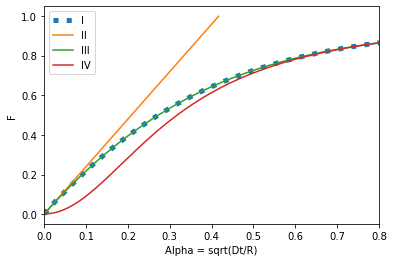

In [60]:
"""Visualizing The Fechtig and Kalbitzer 1966 diffusivity inversions"""
t = 1/501
Fps = np.arange(501)[:-1]/501
a = []
aII = []
aIII = []
aIV = []

for Fp in Fps:
    F = Fp + 1/500
    a.append(((InvertFrequencyFactor(t, F, Fp))*Fp)**0.5)
    II = ((F**2 - Fp**2)*np.pi) / (36*t)
    aII.append((II*Fp)**0.5)
    III = (1/(np.pi**2*t)) * (   (((-(np.pi**2)/3) * (F - Fp))) + ( (-2*np.pi)* (((1-((np.pi/3)*F))**0.5) - ((1-((np.pi/3))*Fp)**0.5) )  )    ) 
    aIII.append((III*Fp)**0.5)
    IV = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )
    aIV.append((IV*Fp)**0.5)
    
plt.plot(np.array(a), Fps+(1/501), linewidth = 5, linestyle = 'dotted', label = 'I',) 
plt.plot(np.array(aII), Fps+(1/501), label = 'II')
plt.plot(np.array(aIII), Fps+(1/501), label = 'III')
plt.plot(np.array(aIV), Fps+(1/501), label = 'IV')


plt.xlabel('Alpha = sqrt(Dt/R)')
plt.ylabel('F')
plt.xlim((0,0.8))
plt.legend()
plt.show()

In [ ]:
h = 1.05 #cm, length of tube
OD = 1350 #microns, outer diameter
ID = 850 #microns, inner diameter

ID /= 10000 #Convert to cm
OD /= 10000 #Convert to cm

perm_model = 'measured'
total_yield =   3.18*197.5
DIFFCELL_name = 'Batch 78.csv'#DIFFCELL_name
timestamp_names = "Batch78DApTube111623.txt"
#3rd asks the temperature at which helium starts degassing from the encapsulated phase
Tcutoff = [(26 + 273), (80 + 273), (100 + 273)] 

DIFFCELL = pd.read_csv(DIFFCELL_name)
with open(timestamp_names, "r") as TIMES:
    timestrings = TIMES.readlines()
    coldtimes = extract_times(timestrings)[skip_reducing:] # function definied in dependencies, considers 1st line blank '\n' Coldtimes is of length of reldata

V = h*np.pi*((ID/2)**2) #cc
Rcal = 1.987
RccATM = 82.06 # cc atm /mol /K
Ratoms = 1.36E-22 # cc atm /atoms /K    

Type = DIFFCELL['Analysis'].to_numpy()
reldata = ((Type == 'Diff Cell').astype('float') + (Type ==  'DiffCell').astype('float')).astype('bool')
Names = (DIFFCELL['Name'].to_numpy()[reldata])[skip_reducing:]

try:
    TempKelvin = (273+DIFFCELL['Avg Temp'].to_numpy()[reldata])[skip_reducing:]
    TimeSeconds = (60*DIFFCELL['Time (min)'].to_numpy()[reldata])[skip_reducing:]
except:
    TempKelvin = (273+DIFFCELL['CIT RefNo'].to_numpy()[reldata])[skip_reducing:]
    TimeSeconds = (60*DIFFCELL['Position'].to_numpy()[reldata])[skip_reducing:]

HenCC = (DIFFCELL['BC nCC'].to_numpy()[reldata])[skip_reducing:]
HenCC[HenCC < 0] = 0 

# Information for tube corrections
n0_modeled = [] # calc for every cold blank, cold indices apply
n1_modeled = []
n0_measured = [] # calc for consectutive cold blanks, indices in Smeas
n1_measured = []
Smeas = [] #indices of consecutive cold blanks
colds = [] #indices of all cold blanks
Smeascolds = []
M = [] #measured CB proportionality (1 - n1/n0)/sec

# Diffusivity data
fcum = []
Fp = 0
DC_indices = []
D_a2 = []
lnD_a2 = []
n1_n0_mod = []
n1_n0_mes = []

####
HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
####
prev_cold = 0
prev_inter = 0
cold_counter = -1
total_colds = 0
Rel_times = []
for i, name in enumerate(Names):
    # First, manage permeability corrections
    if TempKelvin[i] < Tcutoff[2] :
        colds.append(i)
        cold_counter += 1  
        total_colds += 1
        if TempKelvin[i] > Tcutoff[1]: # Logic to only report values where temperature control is valid. Later model room temp as cooling curve
            if perm_model == 'modeled' or perm_model == 'modelled':
                n1_n0_modeled = tube_permeate2(t = TimeSeconds[i], T = TempKelvin[i], ID = ID, OD = OD)
            elif perm_model == 'measured':
                n1_n0_modeled = tube_permeate4(t = TimeSeconds[i], T = TempKelvin[i], G = G) 
        elif (TempKelvin[i] < Tcutoff[0]) and prev_cold > 0:
            if perm_model == 'modeled' or perm_model == 'modelled':
                n1_n0_modeled = tube_permeate2(t = coldtimes[i], T = TempKelvin[i], ID = ID, OD = OD) 
            elif perm_model == 'measured':
                n1_n0_modeled = tube_permeate4(t = coldtimes[i], T = TempKelvin[i], G = G) 
        else: 
            n1_n0_modeled = 0
        n1_n0_mod.append(n1_n0_modeled)
        if n1_n0_modeled:
            n0_modeled.append(HenCC[i]/(1-n1_n0_modeled))
            n1_modeled.append(HenCC[i]/((1/n1_n0_modeled)-1))
        else:
            n0_modeled.append(0)
            n1_modeled.append(0)
        if ((prev_cold >= 2) and (TempKelvin[i] < Tcutoff[0])):# and (HenCC[i] > 0.0175)):
            Smeascolds.append(cold_counter)
            #Smeas.append(i-1)
            Smeas.append(i)
            Rel_times.append(coldtimes[i])
            n1_n0_measured = (HenCC[i]/coldtimes[i])/(HenCC[i-1]/coldtimes[i-1]) # Assume unchanging abundance, time normalize
            m = (1 - n1_n0_measured)/np.mean([coldtimes[i], coldtimes[i-1]]) # Assume n1/n0 linear: no significant degassing
            #n0_measured.append(HenCC[i-1]/(m*coldtimes[i-1]))
            #n1_measured.append(HenCC[i-1]/((1/(1-(m*coldtimes[i-1]))-1)))
            n0_measured.append(HenCC[i]/(m*coldtimes[i]))
            n1_measured.append(HenCC[i]/((1/(1-(m*coldtimes[i]))-1)))
            n1_n0_mes.append(n1_n0_measured)
            M.append(m)
            #M.append(m)
        elif ((prev_inter >= 1) and ((TempKelvin[i] > Tcutoff[1]) and (np.abs(TempKelvin[i] - TempKelvin[i-1]) < 2))):# and (HenCC[i] > 0.01)):
            Smeascolds.append(cold_counter)
            Rel_times.append(TimeSeconds[i])
            #Smeas.append(i-1)
            Smeas.append(i)
            n1_n0_measured = (HenCC[i]/TimeSeconds[i])/(HenCC[i-1]/TimeSeconds[i-1]) # Assume unchanging abundance, time normalize
            m = (1 - n1_n0_measured)/np.mean([TimeSeconds[i], TimeSeconds[i-1]]) # Assume n1/n0 linear: no significant degassing
            #n0_measured.append(HenCC[i-1]/(m*coldtimes[i-1]))
            #n1_measured.append(HenCC[i-1]/((1/(1-(m*coldtimes[i-1]))-1)))
            n0_measured.append(HenCC[i]/(m*TimeSeconds[i]))
            n1_measured.append(HenCC[i]/((1/(1-(m*TimeSeconds[i]))-1)))
            n1_n0_mes.append(n1_n0_measured)
            M.append(m)

        if (TempKelvin[i] < (Tcutoff[0]+40)):
            prev_cold += 1
            prev_inter = 0
        else:
            prev_inter += 1
            prev_cold = 0

        Names[i] = str(total_colds)+' in sequence '+ name
    else:
        prev_cold = 0
        prev_inter = 0
        total_colds = 0
n1_measured = np.array(n1_measured)
n0_measured = np.array(n0_measured)
n1_modeled = np.array(n1_modeled)
n0_modeled = np.array(n0_modeled)

n1_measured_out = np.zeros_like(n1_modeled)
n1_measured_out[Smeascolds] = n1_measured
n0_measured_out = np.zeros_like(n0_modeled)
n0_measured_out[Smeascolds] = n0_measured
n1_n0_mes_out = np.zeros_like(n0_modeled)
n1_n0_mes_out[Smeascolds] = n1_n0_mes

molHe = HenCC/(22.4*1E12) #convert from nccSTP to moles
PHeATM = ((molHe*RccATM*TempKelvin)/V)
PHe = (PHeATM/1.01325)*1E6 # Conv. Atmospheres to microbars

lambdas = -np.log((np.array(n1_measured)/np.array(n0_measured)))/(TempKelvin[Smeas]*Rel_times*Ratoms)
K_meas = (lambdas*np.log(OD/ID)*((ID/2)**2))/2
K_ref = []

for Temp in TempKelvin[Smeas]:
    K_ref.append(swets_K(Temp))
DK_swets = np.log(K_meas)-np.log(np.array(K_ref))
lnlambdas = np.log(lambdas)
lambdas_out = np.zeros_like(n0_modeled)
lnlambdas_out = np.zeros_like(n0_modeled)
lambdas_out[Smeascolds] = lambdas
lnlambdas_out[Smeascolds] = lnlambdas
K_meas_out = np.zeros_like(n0_modeled)
DK_swets_out = np.zeros_like(n0_modeled)
K_meas_out[Smeascolds] = np.array(K_meas)
DK_swets_out[Smeascolds] = DK_swets


HTind = []
prev_cold = 0
n0 = [] # Values For correction
n1 = []

for i, measured in reversed(list(enumerate(HenCC))): # Traverse steps in reverse, second/last cold step always proper temp.
#for i, measured in enumerate(HenCC):
    # First, manage permeability corrections
    if TempKelvin[i] < Tcutoff[2]:
        if prev_cold == 0:
            #print(n0_modeled[np.array(colds) == i])
            n1.append(n0_modeled[np.array(colds) == i][0]) # Collect tube contents after previous HT step
            n0.append(n1_modeled[np.array(colds) == i][0]) # Collect tube contents preceding next HT step
        else:
            n1[-1] += measured # Account for permeate lost during cold steps
        prev_cold += 1
    else:
        prev_cold = 0
        HTind.append(i)
n0.reverse()
n1.reverse()
HTind.reverse()
n0 = np.array(n0)[:-1] # Cut last preceding tube measurement
n1 = np.array(n1)[1:] # Cut first succeeding tube measurement

HT_corr = HenCC[HTind] + n1 - n0 # Correct high temperature steps for gas inside tube before and after high temperature steps

HT_corr[HT_corr<0] = 0
#print(total_yield)
if total_yield == 0: 
    total_yield = np.sum(HT_corr)
#print(f"Total yield: {total_yield}")
Fp = 0
fcum = []
D_a2 = []
lnD_a2 = []

for i, h in enumerate(HTind):
    step_yield = HT_corr[i]
    F = Fp + (step_yield/total_yield)
    frequency_factor = InvertFrequencyFactor(t = TimeSeconds[h], F = F, Fp = Fp)
    D_a2.append(frequency_factor)
    lnD_a2.append(np.log(frequency_factor))
    fcum.append(F)
    Fp = F
if plot:
    fig = plt.figure()
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twiny()
    #min_T = np.min(10000/TempKelvin)
    #max_T = np.max(10000/TempKelvin)
    Ctemps = np.array([150,200,250,300,350,400])#np.linspace(200,700, 11,dtype = int)

    min_T, max_T = ax1.get_xlim()


    min_T = np.min(10000/TempKelvin[HTind][skip_plotting:])
    max_T = np.max(10000/TempKelvin[HTind][skip_plotting:])
    ax1.plot(10000/TempKelvin[HTind][skip_plotting:], np.array(lnD_a2)[skip_plotting:], linestyle='--', marker='o', color='b', label = 'BJT Data')
    """
    #for j, no in enumerate(['3','4']): # Plot Win-G from HDM and KAF
    #    ax1.plot(Winsor_Data[f'He{no}HDM']['10^4/T'][:-1], Winsor_Data[f'He{no}HDM']['ln(D/a^2)'][:-1], linestyle='--', linewidth = 1, marker=['x','+'][j], color='g', label = f'HDM {no}He Data')
    for j, no in enumerate(['3','4']):
        ax1.plot(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], linestyle='--', color = 'grey')
        ax1.scatter(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], marker=['x','+'][j], c=Diffdat['watercum'][:-1]/max(Diffdat['watercum']), cmap = 'RdYlBu_r', label = f'KAF {no}He Data')

    cbar = plt.colorbar(mappable = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap='RdYlBu_r'))
    cbar.set_label('Cumulative Water Offgassed')"""
    reference_D0_a2 = [(10**1.5)/((150/10000)**2), (10**1.5)/((250/10000)**2)]#, np.exp(1.1939)] # /sec
    reference_Ea = [33000, 33000]#, 14701*1.987] # cal /mol

    reference_names = ['Durango B a=150 um', 'DApB a=250 um']
    R = 1.98 #cal /mol /T(K)|

    #ax1.set_xlim((1E4/(350+273), 1E4/(100+273)))
    min_T, max_T = ax1.get_xlim()

    first_only = 1
    if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
        T = [min_T, max_T]
        for i, D0_a2 in enumerate(reference_D0_a2):
            if first_only:
                Ea = reference_Ea[i]
                min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
                max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
                ax1.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[i])
                first_only = False

    ax2.set_xticks(1E4/(Ctemps+273))
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticklabels(Ctemps)
    ax2.set_xlabel('Temperature (°C)')
    ax1.set_xlabel('10^4/T (K)')
    ax1.set_ylabel('ln(D/a^2)')

    ax1.legend()
    plt.tight_layout()
    #plt.savefig('Winsor_Goethite_Diffusion_BJT_KAF.jpg', dpi = 256)
    plt.show()

In [564]:
"""Diffusion Cell Data Reduction for encapsulated phases correcting for permeation lag"""

def tube_permeate4(T,t,G):
    K = swets_K(T)
    return np.exp(-(K*G*T*Ratoms*t))


# Three temperatures for use in data reduction. 
#1st temp asks if room temperature 
#2nd asks the temp at which cold permeation is effectively negligible (permeation is 10x at 120C and 20x at 175)
#3rd asks the temperature at which helium starts degassing from the encapsulated phase
Tcutoff = [(26 + 273), (80 + 273), (120 + 273)] 



def apatite_loss(G0, a = 175, plot = False):
    G = G0[0]
    h = 1.05 #cm, length of tube
    OD = 1350 #microns, outer diameter
    ID = 850 #microns, inner diameter

    ID /= 10000 #Convert to cm
    OD /= 10000 #Convert to cm

    perm_model = 'measured'
    total_yield =   3.18*197.5
    DIFFCELL_name = 'Batch 78.csv'#DIFFCELL_name
    timestamp_names = "Batch78DApTube111623.txt"
    #3rd asks the temperature at which helium starts degassing from the encapsulated phase
    Tcutoff = [(26 + 273), (80 + 273), (100 + 273)] 
    
    DIFFCELL = pd.read_csv(DIFFCELL_name)
    with open(timestamp_names, "r") as TIMES:
        timestrings = TIMES.readlines()
        coldtimes = extract_times(timestrings)[skip_reducing:] # function definied in dependencies, considers 1st line blank '\n' Coldtimes is of length of reldata
   
    V = h*np.pi*((ID/2)**2) #cc
    Rcal = 1.987
    RccATM = 82.06 # cc atm /mol /K
    Ratoms = 1.36E-22 # cc atm /atoms /K    

    Type = DIFFCELL['Analysis'].to_numpy()
    reldata = ((Type == 'Diff Cell').astype('float') + (Type ==  'DiffCell').astype('float')).astype('bool')
    Names = (DIFFCELL['Name'].to_numpy()[reldata])[skip_reducing:]

    try:
        TempKelvin = (273+DIFFCELL['Avg Temp'].to_numpy()[reldata])[skip_reducing:]
        TimeSeconds = (60*DIFFCELL['Time (min)'].to_numpy()[reldata])[skip_reducing:]
    except:
        TempKelvin = (273+DIFFCELL['CIT RefNo'].to_numpy()[reldata])[skip_reducing:]
        TimeSeconds = (60*DIFFCELL['Position'].to_numpy()[reldata])[skip_reducing:]

    HenCC = (DIFFCELL['BC nCC'].to_numpy()[reldata])[skip_reducing:]
    HenCC[HenCC < 0] = 0 

    # Information for tube corrections
    n0_modeled = [] # calc for every cold blank, cold indices apply
    n1_modeled = []
    n0_measured = [] # calc for consectutive cold blanks, indices in Smeas
    n1_measured = []
    Smeas = [] #indices of consecutive cold blanks
    colds = [] #indices of all cold blanks
    Smeascolds = []
    M = [] #measured CB proportionality (1 - n1/n0)/sec

    # Diffusivity data
    fcum = []
    Fp = 0
    DC_indices = []
    D_a2 = []
    lnD_a2 = []
    n1_n0_mod = []
    n1_n0_mes = []

    ####
    HeSigma = HenCC*0.03 # Working with Jonathan to get ratio uncertainties in batch files in the future. Now assume 3% error, 2 sigma
    ####
    prev_cold = 0
    prev_inter = 0
    cold_counter = -1
    total_colds = 0
    Rel_times = []
    for i, name in enumerate(Names):
        # First, manage permeability corrections
        if TempKelvin[i] < Tcutoff[2] :
            colds.append(i)
            cold_counter += 1  
            total_colds += 1
            if TempKelvin[i] > Tcutoff[1]: # Logic to only report values where temperature control is valid. Later model room temp as cooling curve
                if perm_model == 'modeled' or perm_model == 'modelled':
                    n1_n0_modeled = tube_permeate2(t = TimeSeconds[i], T = TempKelvin[i], ID = ID, OD = OD)
                elif perm_model == 'measured':
                    n1_n0_modeled = tube_permeate4(t = TimeSeconds[i], T = TempKelvin[i], G = G) 
            elif (TempKelvin[i] < Tcutoff[0]) and prev_cold > 0:
                if perm_model == 'modeled' or perm_model == 'modelled':
                    n1_n0_modeled = tube_permeate2(t = coldtimes[i], T = TempKelvin[i], ID = ID, OD = OD) 
                elif perm_model == 'measured':
                    n1_n0_modeled = tube_permeate4(t = coldtimes[i], T = TempKelvin[i], G = G) 
            else: 
                n1_n0_modeled = 0
            n1_n0_mod.append(n1_n0_modeled)
            if n1_n0_modeled:
                n0_modeled.append(HenCC[i]/(1-n1_n0_modeled))
                n1_modeled.append(HenCC[i]/((1/n1_n0_modeled)-1))
            else:
                n0_modeled.append(0)
                n1_modeled.append(0)
            if ((prev_cold >= 2) and (TempKelvin[i] < Tcutoff[0])):# and (HenCC[i] > 0.0175)):
                Smeascolds.append(cold_counter)
                #Smeas.append(i-1)
                Smeas.append(i)
                Rel_times.append(coldtimes[i])
                n1_n0_measured = (HenCC[i]/coldtimes[i])/(HenCC[i-1]/coldtimes[i-1]) # Assume unchanging abundance, time normalize
                m = (1 - n1_n0_measured)/np.mean([coldtimes[i], coldtimes[i-1]]) # Assume n1/n0 linear: no significant degassing
                #n0_measured.append(HenCC[i-1]/(m*coldtimes[i-1]))
                #n1_measured.append(HenCC[i-1]/((1/(1-(m*coldtimes[i-1]))-1)))
                n0_measured.append(HenCC[i]/(m*coldtimes[i]))
                n1_measured.append(HenCC[i]/((1/(1-(m*coldtimes[i]))-1)))
                n1_n0_mes.append(n1_n0_measured)
                M.append(m)
                #M.append(m)
            elif ((prev_inter >= 1) and ((TempKelvin[i] > Tcutoff[1]) and (np.abs(TempKelvin[i] - TempKelvin[i-1]) < 2))):# and (HenCC[i] > 0.01)):
                Smeascolds.append(cold_counter)
                Rel_times.append(TimeSeconds[i])
                #Smeas.append(i-1)
                Smeas.append(i)
                n1_n0_measured = (HenCC[i]/TimeSeconds[i])/(HenCC[i-1]/TimeSeconds[i-1]) # Assume unchanging abundance, time normalize
                m = (1 - n1_n0_measured)/np.mean([TimeSeconds[i], TimeSeconds[i-1]]) # Assume n1/n0 linear: no significant degassing
                #n0_measured.append(HenCC[i-1]/(m*coldtimes[i-1]))
                #n1_measured.append(HenCC[i-1]/((1/(1-(m*coldtimes[i-1]))-1)))
                n0_measured.append(HenCC[i]/(m*TimeSeconds[i]))
                n1_measured.append(HenCC[i]/((1/(1-(m*TimeSeconds[i]))-1)))
                n1_n0_mes.append(n1_n0_measured)
                M.append(m)

            if (TempKelvin[i] < (Tcutoff[0]+40)):
                prev_cold += 1
                prev_inter = 0
            else:
                prev_inter += 1
                prev_cold = 0

            Names[i] = str(total_colds)+' in sequence '+ name
        else:
            prev_cold = 0
            prev_inter = 0
            total_colds = 0
    n1_measured = np.array(n1_measured)
    n0_measured = np.array(n0_measured)
    n1_modeled = np.array(n1_modeled)
    n0_modeled = np.array(n0_modeled)

    n1_measured_out = np.zeros_like(n1_modeled)
    n1_measured_out[Smeascolds] = n1_measured
    n0_measured_out = np.zeros_like(n0_modeled)
    n0_measured_out[Smeascolds] = n0_measured
    n1_n0_mes_out = np.zeros_like(n0_modeled)
    n1_n0_mes_out[Smeascolds] = n1_n0_mes

    molHe = HenCC/(22.4*1E12) #convert from nccSTP to moles
    PHeATM = ((molHe*RccATM*TempKelvin)/V)
    PHe = (PHeATM/1.01325)*1E6 # Conv. Atmospheres to microbars

    lambdas = -np.log((np.array(n1_measured)/np.array(n0_measured)))/(TempKelvin[Smeas]*Rel_times*Ratoms)
    K_meas = (lambdas*np.log(OD/ID)*((ID/2)**2))/2
    K_ref = []

    for Temp in TempKelvin[Smeas]:
        K_ref.append(swets_K(Temp))
    DK_swets = np.log(K_meas)-np.log(np.array(K_ref))
    lnlambdas = np.log(lambdas)
    lambdas_out = np.zeros_like(n0_modeled)
    lnlambdas_out = np.zeros_like(n0_modeled)
    lambdas_out[Smeascolds] = lambdas
    lnlambdas_out[Smeascolds] = lnlambdas
    K_meas_out = np.zeros_like(n0_modeled)
    DK_swets_out = np.zeros_like(n0_modeled)
    K_meas_out[Smeascolds] = np.array(K_meas)
    DK_swets_out[Smeascolds] = DK_swets


    HTind = []
    prev_cold = 0
    n0 = [] # Values For correction
    n1 = []

    for i, measured in reversed(list(enumerate(HenCC))): # Traverse steps in reverse, second/last cold step always proper temp.
    #for i, measured in enumerate(HenCC):
        # First, manage permeability corrections
        if TempKelvin[i] < Tcutoff[2]:
            if prev_cold == 0:
                #print(n0_modeled[np.array(colds) == i])
                n1.append(n0_modeled[np.array(colds) == i][0]) # Collect tube contents after previous HT step
                n0.append(n1_modeled[np.array(colds) == i][0]) # Collect tube contents preceding next HT step
            else:
                n1[-1] += measured # Account for permeate lost during cold steps
            prev_cold += 1
        else:
            prev_cold = 0
            HTind.append(i)
    n0.reverse()
    n1.reverse()
    HTind.reverse()
    n0 = np.array(n0)[:-1] # Cut last preceding tube measurement
    n1 = np.array(n1)[1:] # Cut first succeeding tube measurement

    HT_corr = HenCC[HTind] + n1 - n0 # Correct high temperature steps for gas inside tube before and after high temperature steps

    HT_corr[HT_corr<0] = 0
    #print(total_yield)
    if total_yield == 0: 
        total_yield = np.sum(HT_corr)
    #print(f"Total yield: {total_yield}")
    Fp = 0
    fcum = []
    D_a2 = []
    lnD_a2 = []

    for i, h in enumerate(HTind):
        step_yield = HT_corr[i]
        F = Fp + (step_yield/total_yield)
        frequency_factor = InvertFrequencyFactor(t = TimeSeconds[h], F = F, Fp = Fp)
        D_a2.append(frequency_factor)
        lnD_a2.append(np.log(frequency_factor))
        fcum.append(F)
        Fp = F
    if plot:
        fig = plt.figure()
        ax1 = fig.add_subplot(111)
        ax2 = ax1.twiny()
        #min_T = np.min(10000/TempKelvin)
        #max_T = np.max(10000/TempKelvin)
        Ctemps = np.array([150,200,250,300,350,400])#np.linspace(200,700, 11,dtype = int)

        min_T, max_T = ax1.get_xlim()


        min_T = np.min(10000/TempKelvin[HTind][skip_plotting:])
        max_T = np.max(10000/TempKelvin[HTind][skip_plotting:])
        ax1.plot(10000/TempKelvin[HTind][skip_plotting:], np.array(lnD_a2)[skip_plotting:], linestyle='--', marker='o', color='b', label = 'BJT Data')
        """
        #for j, no in enumerate(['3','4']): # Plot Win-G from HDM and KAF
        #    ax1.plot(Winsor_Data[f'He{no}HDM']['10^4/T'][:-1], Winsor_Data[f'He{no}HDM']['ln(D/a^2)'][:-1], linestyle='--', linewidth = 1, marker=['x','+'][j], color='g', label = f'HDM {no}He Data')
        for j, no in enumerate(['3','4']):
            ax1.plot(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], linestyle='--', color = 'grey')
            ax1.scatter(Winsor_Data[f'He{no}KAF']['10^4/T'][:-1], Winsor_Data[f'He{no}KAF']['ln(D/a^2)'][:-1], marker=['x','+'][j], c=Diffdat['watercum'][:-1]/max(Diffdat['watercum']), cmap = 'RdYlBu_r', label = f'KAF {no}He Data')

        cbar = plt.colorbar(mappable = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap='RdYlBu_r'))
        cbar.set_label('Cumulative Water Offgassed')"""
        reference_D0_a2 = [(10**1.5)/((150/10000)**2), (10**1.5)/((250/10000)**2)]#, np.exp(1.1939)] # /sec
        reference_Ea = [33000, 33000]#, 14701*1.987] # cal /mol

        reference_names = ['Durango B a=150 um', 'DApB a=250 um']
        R = 1.98 #cal /mol /T(K)|

        #ax1.set_xlim((1E4/(350+273), 1E4/(100+273)))
        min_T, max_T = ax1.get_xlim()

        first_only = 1
        if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
            T = [min_T, max_T]
            for i, D0_a2 in enumerate(reference_D0_a2):
                if first_only:
                    Ea = reference_Ea[i]
                    min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
                    max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
                    ax1.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[i])
                    first_only = False

        ax2.set_xticks(1E4/(Ctemps+273))
        ax2.set_xlim(ax1.get_xlim())
        ax2.set_xticklabels(Ctemps)
        ax2.set_xlabel('Temperature (°C)')
        ax1.set_xlabel('10^4/T (K)')
        ax1.set_ylabel('ln(D/a^2)')

        ax1.legend()
        plt.tight_layout()
        #plt.savefig('Winsor_Goethite_Diffusion_BJT_KAF.jpg', dpi = 256)
        plt.show()

    reference_D0_a2 = (10**1.5)/((a/10000)**2)#, np.exp(1.1939)] # /sec
    reference_Ea = 33000#, 14701*1.987] # cal /mol
    ref_lnD = np.log(reference_D0_a2*np.exp(-(reference_Ea/(1.987*TempKelvin[HTind]))))
    #print(ref_lnD)
    
    #loss = np.sum(np.abs(lnD_a2 - ref_lnD))
    inf_ID = np.isinf(lnD_a2)
    #print(np.abs(lnD_a2 - ref_lnD)[(-(inf_ID - 1)).astype(bool)])
    #print(f"INFINITY PENALIZATION: {(np.sum(inf_ID.astype(float))*3)}")
    #print(len(np.abs(lnD_a2 - ref_lnD)[-(inf_ID - 1)]))
    loss = np.sum(np.abs(lnD_a2 - ref_lnD)[(-(inf_ID - 1)).astype(bool)]) + (np.sum(inf_ID)*3)
    #print(loss)
    #print(lnD_a2)
    #print(lnD_a2)
    #print(lnD_a2)
    #print(lnD_a2)
    return loss

h = 1.05 #cm, length of tube
OD = 1350 #microns, outer diameter
ID = 850 #microns, inner diameter

ID /= 10000 #Convert to cm
OD /= 10000 #Convert to cm

G1 = 2/(np.log(OD/ID)*((ID/2)**2))

minimize_results = scipy.optimize.minimize(apatite_loss, x0 = G1, method='Nelder-Mead', options = {'maxiter':100})
print(minimize_results)

2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36
2023-11-05 09:43:36


C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2534045324.py:170: RuntimeWarning: invalid value encountered in log
  DK_swets = np.log(K_meas)-np.log(np.array(K_ref))
C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2534045324.py:171: RuntimeWarning: invalid value encountered in log
  lnlambdas = np.log(lambdas)
C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2534045324.py:170: RuntimeWarning: invalid value encountered in log
  DK_swets = np.log(K_meas)-np.log(np.array(K_ref))
C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2534045324.py:171: RuntimeWarning: invalid value encountered in log
  lnlambdas = np.log(lambdas)
C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2534045324.py:170: RuntimeWarning: invalid value encountered in log
  DK_swets = np.log(K_meas)-np.log(np.array(K_ref))
C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2534045324.py:171: RuntimeWarning: invalid value encountered in log
  lnlambdas = np.log(lambdas)
C:\Users\dashf\AppData\Local\Temp\ipykernel_28

Measured Geom, G = 2393.45
2023-11-05 09:43:36


C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2534045324.py:170: RuntimeWarning: invalid value encountered in log
  DK_swets = np.log(K_meas)-np.log(np.array(K_ref))
C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2534045324.py:171: RuntimeWarning: invalid value encountered in log
  lnlambdas = np.log(lambdas)


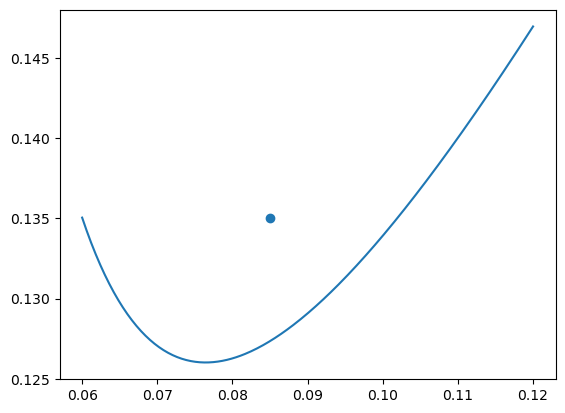

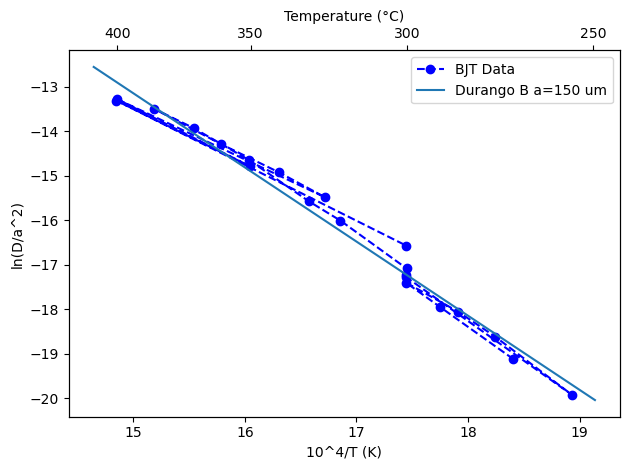

Optim Geom, G = 2739
2023-11-05 09:43:36


C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2534045324.py:170: RuntimeWarning: invalid value encountered in log
  DK_swets = np.log(K_meas)-np.log(np.array(K_ref))
C:\Users\dashf\AppData\Local\Temp\ipykernel_28028\2534045324.py:171: RuntimeWarning: invalid value encountered in log
  lnlambdas = np.log(lambdas)


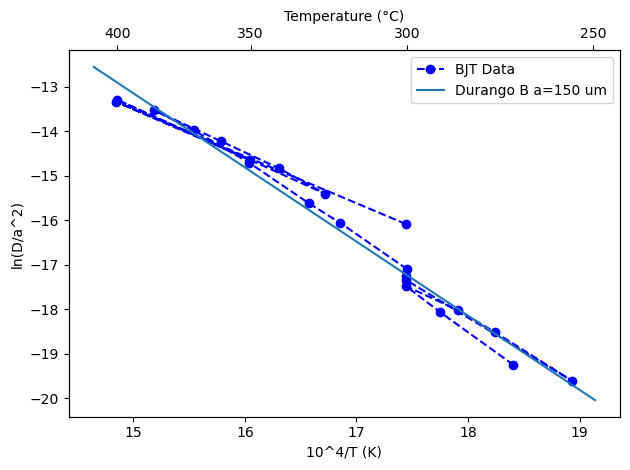

13.119104897180442

In [567]:
#G_chosen = 2102.151075537769 # 200 um
G_chosen = 2739 # 150 um, better
#G_orig = 2393.45 # measured geometry
#G_chosen = 3663 # 225 um
#G_chosen = 2456 # 175 NM
#G_chosen = 2104 # 175 block search
#G_chosen = 2417
IDs = np.linspace(600, 1200, 300)/10000
ODs = []

for ID in IDs:
    ODs.append(np.exp((2/(G_chosen*((ID/2)**2)))+np.log(ID)))

plt.plot(IDs, np.array(ODs))
plt.scatter(850/10000, 1350/10000)
print(f"Measured Geom, G = {G_orig}")
apatite_loss([G_orig], plot = True)
print(f"Optim Geom, G = {G_chosen}")
apatite_loss([G_chosen], plot = True)

In [212]:
for Tc in [90,95,100,105,110]:
    tk = Tc+273
    print(np.log(swets_K(tk)*Jones(tk)))

25.018107203522366
25.111483493038186
25.202356396776104
25.29082525544159
25.376984222235915


At 300C, helium trapped in the specified glass tube by a constant or declining source will be less than or equal to 1.0% of the total high temperature step after 58.7833668291008 hours
At 325C, helium trapped in the specified glass tube by a constant or declining source will be less than or equal to 1.0% of the total high temperature step after 46.032532375989035 hours
At 350C, helium trapped in the specified glass tube by a constant or declining source will be less than or equal to 1.0% of the total high temperature step after 36.700242001657685 hours
At 375C, helium trapped in the specified glass tube by a constant or declining source will be less than or equal to 1.0% of the total high temperature step after 29.72985070736027 hours
At 400C, helium trapped in the specified glass tube by a constant or declining source will be less than or equal to 1.0% of the total high temperature step after 24.428124177710714 hours
At 425C, helium trapped in the specified glass tube by a constant or

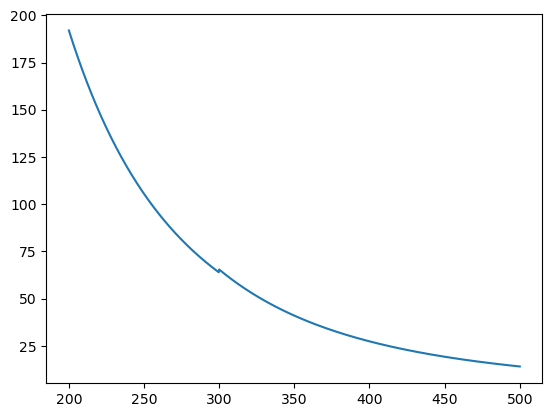

In [209]:
OD = 800/1E4
ID = 510/1E4

G = 2/(np.log(OD/ID)*((ID/2)**2))
Tk = np.linspace(200,500,1000) + 273
F = 0.01

Ks = []
for Ti in Tk:
    Ks.append(swets_K(Ti))
Ks = np.array(Ks)
transparency_time = (1/(Ks*G*Tk*F*Ratoms))/3600
plt.plot(Tk-273, transparency_time)

Tk = np.array([300,325,350,375,400,425,450,475,500]) + 273
for Ti in Tk:
    print(f"At {Ti-273}C, helium trapped in the specified glass tube by a constant or declining source will be less than or equal to {F*100}% of the total high temperature step after {(1/(swets_K(Ti)*Jones(Ti)*G*Ti*F*Ratoms))/3600} hours")
Ks = np.array(Ks)

def ssN(T, Q):
    K = swets_K(T)
    return(Q/(K*G*T*Ratoms))

print(ssN(273+250, 8.5/(10250*60)))

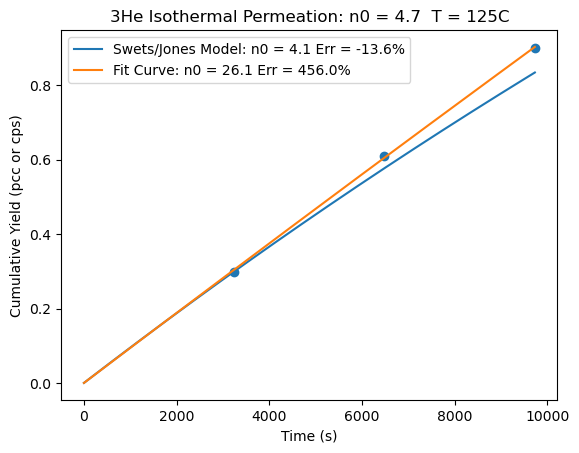

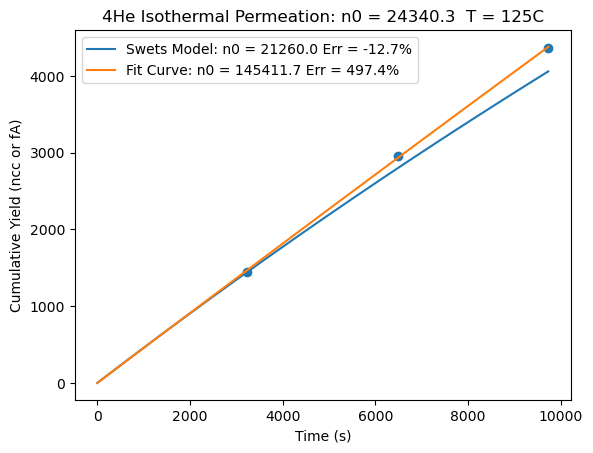

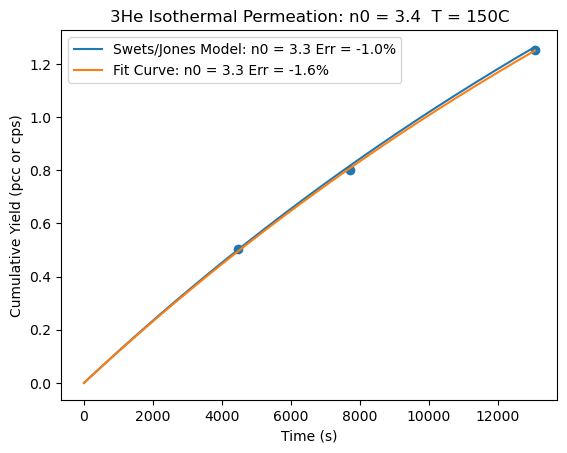

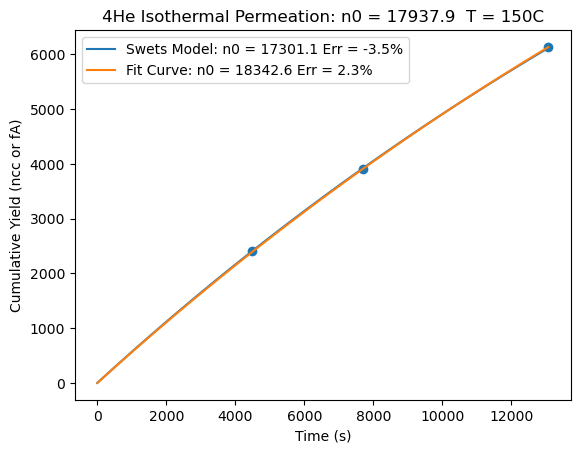

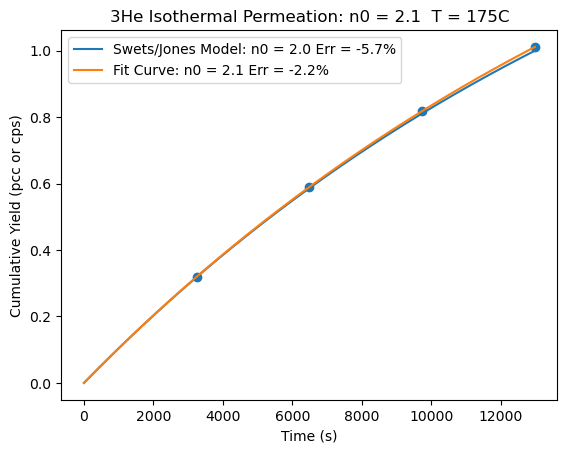

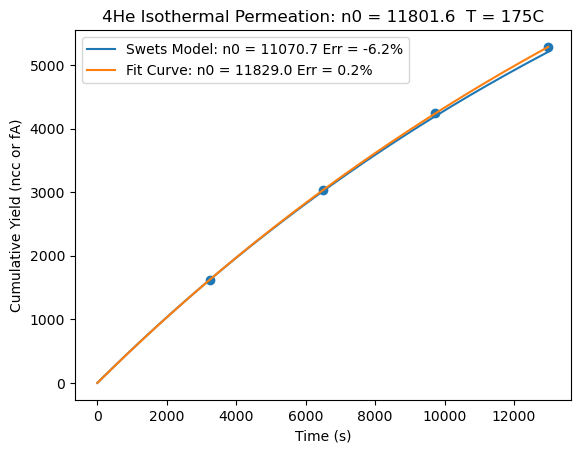

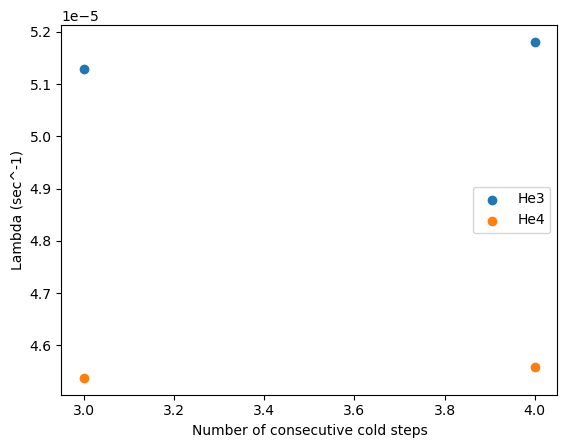

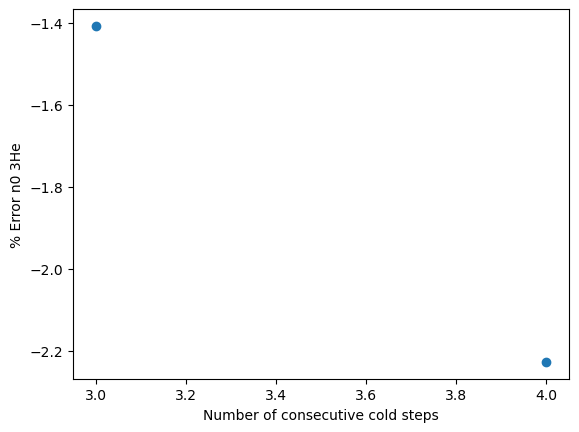

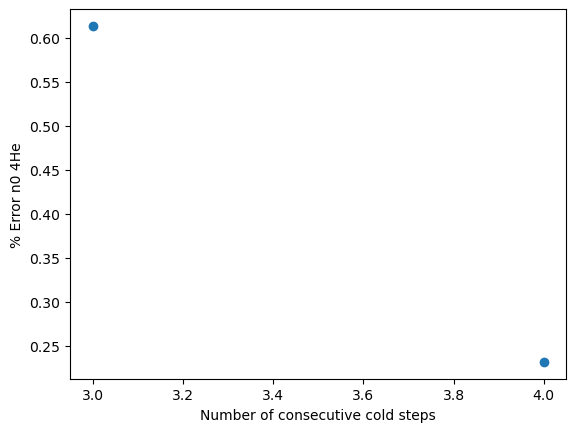

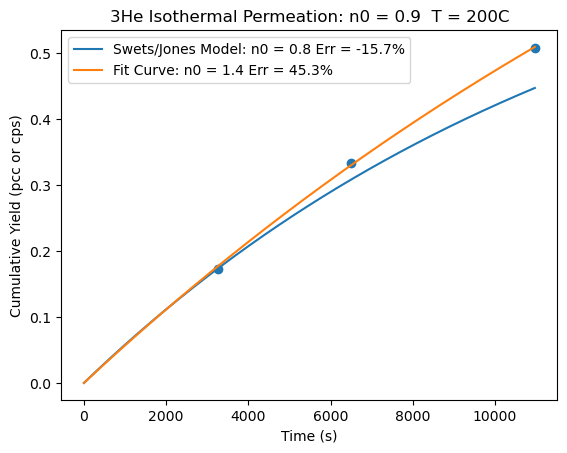

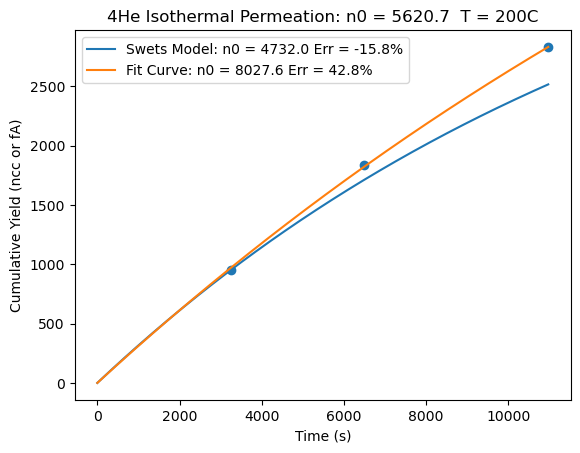

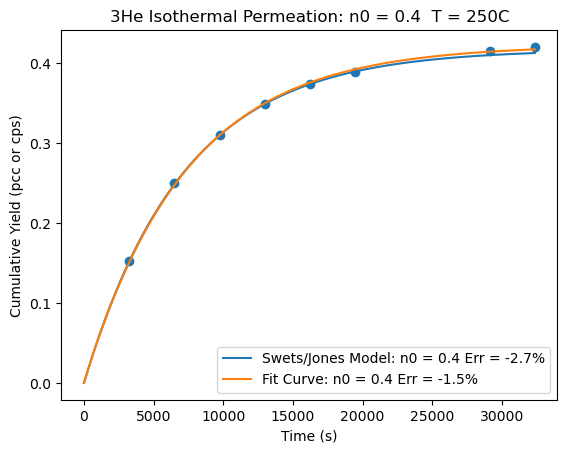

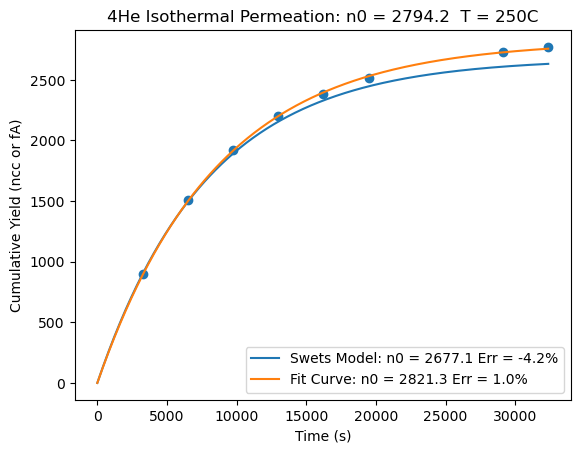

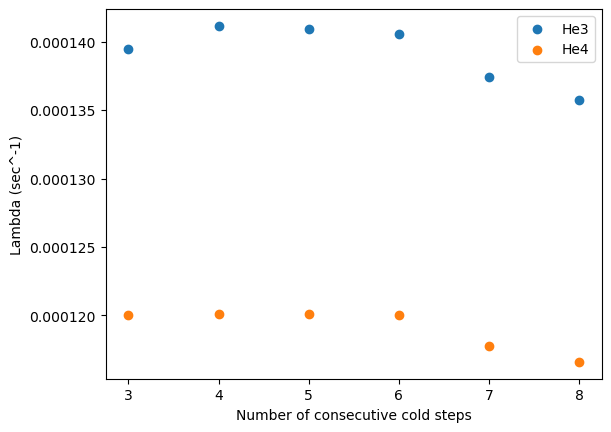

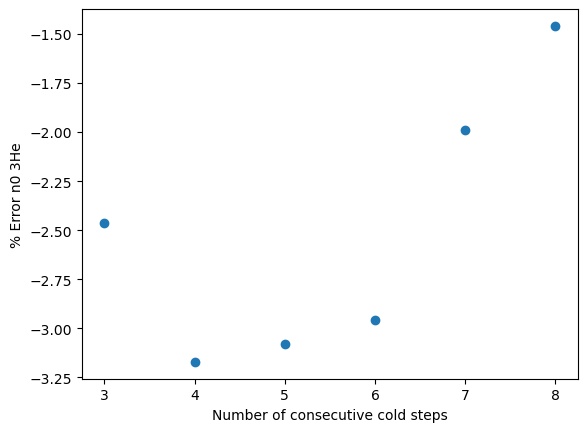

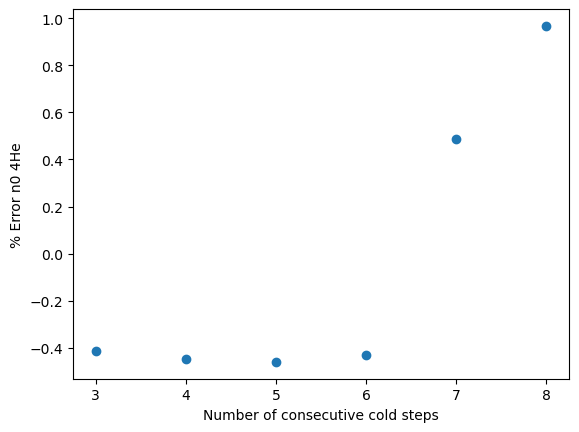

In [38]:

DATA = pd.read_csv('111923SmallSIlicaTubeISOTHERMALS.csv').to_numpy()

He3, He4 = reducer.reduce(DATA)
OD = 0.1159
ID = 0.0747

DATA[:,4] = He3
DATA[:,6] = He4

lambs3 = []
lambs4 = []
Ts = []

"""
He3 = first_H2Otube[:-1,4]
He4 = first_H2Otube[:-1,6]
tot4 = 1.48E5
tot3 = 1.02E2
t = np.array([3600]*(np.shape(first_H2Otube)[0]-1))
T = 100 + 273
"""


t = []
He3 = []
He4 = []

for r in np.arange(np.shape(DATA)[0]):
    if DATA[r,3] == 0:
        points = len(t)
        tot3 = np.sum(DATA[(r-points):,4])
        tot4 = np.sum(DATA[(r-points):,6])
        t = np.array(t)
        He3 = np.array(He3)
        He4 = np.array(He4)
        name = f'111923IsothermalT{T-273}C'
        
        
        G = 2/(np.log(OD/ID)*((ID/2)**2))
        K4 = swets_K(T)
        lamb4mod = G * K4 * (T) * Ratoms
        lamb3mod = lamb4mod*Jones(T)
        n3mod = He3[0]/(1-tube_permeate2(t=t[0],T=T,OD=OD,ID=ID, He='3He'))
        n4mod = He4[0]/(1-tube_permeate2(t=t[0],T=T,OD=OD,ID=ID, He='4He'))

        lamb3fit, n3fit = KenColdInversion(t, He3)
        lamb4fit, n4fit = KenColdInversion(t, He4)
        
        lambs3.append(lamb3fit)
        lambs4.append(lamb4fit)
        Ts.append(T)
        t_long = np.linspace(0,np.max(accumulate(t)),400)
        
        plt.scatter(accumulate(t), accumulate(He3))
        plt.plot(t_long, forward_permeate(t_long,lamb = lamb3mod, n0 = n3mod), label = f'Swets/Jones Model: n0 = {round(n3mod,1)} Err = {round((-(tot3-n3mod)/tot3)*100, 1)}%')
        plt.plot(t_long, forward_permeate(t_long,lamb = lamb3fit, n0 = n3fit), label = f'Fit Curve: n0 = {round(n3fit,1)} Err = {round((-(tot3-n3fit)/tot3)*100, 1)}%')
        plt.title(f'3He Isothermal Permeation: n0 = {round(tot3,1)}  T = {T-273}C')
        plt.xlabel('Time (s)')
        plt.ylabel('Cumulative Yield (pcc or cps)')
        plt.legend()
        plt.savefig(f"Blanks/3He_{name}.jpg", dpi = 256)
        plt.show()

        plt.scatter(accumulate(t), accumulate(He4))
        plt.plot(t_long, forward_permeate(t_long,lamb = lamb4mod, n0 = n4mod), label = f'Swets Model: n0 = {round(n4mod,1)} Err = {round((-(tot4-n4mod)/tot4)*100, 1)}%')
        plt.plot(t_long, forward_permeate(t_long,lamb = lamb4fit, n0 = n4fit), label = f'Fit Curve: n0 = {round(n4fit,1)} Err = {round((-(tot4-n4fit)/tot4)*100, 1)}%')
        plt.title(f'4He Isothermal Permeation: n0 = {round(tot4,1)}  T = {T-273}C')
        plt.xlabel('Time (s)')
        plt.ylabel('Cumulative Yield (ncc or fA)')
        plt.legend()
        plt.savefig(f"Blanks/4He_{name}.jpg", dpi = 256)
        plt.show()
    
        Ls = np.arange(3,points+1)

        lamb3 = []
        lamb4 = []
        n3 = []
        n4 = []
        if points > 3:
            for L in Ls:
                lam, n0 = KenColdInversion(t[:L], He3[:L])
                lamb3.append(lam)
                n3.append(n0)
                lam, n0 = KenColdInversion(t[:L], He4[:L])
                lamb4.append(lam)
                n4.append(n0)
            n3 = np.array(n3)
            n4 = np.array(n4)
            plt.scatter(Ls, lamb3, label = 'He3')
            plt.scatter(Ls, lamb4, label = 'He4')
            plt.legend()
            plt.xlabel('Number of consecutive cold steps')
            plt.ylabel('Lambda (sec^-1)')
            plt.show()

            plt.scatter(Ls, (-(tot3-n3)/tot3)*100)
            plt.xlabel('Number of consecutive cold steps')
            plt.ylabel('% Error n0 3He')
            plt.show()

            plt.scatter(Ls, (-(tot4-n4)/tot4)*100)
            plt.xlabel('Number of consecutive cold steps')
            plt.ylabel('% Error n0 4He')
            plt.show()
        
        t = []
        He3 = []
        He4 = []
        
    else:
        t.append(DATA[r,8])
        He3.append(DATA[r,4])
        He4.append(DATA[r,6])
        T = DATA[r,3] + 273

In [133]:
def accumulate(v):
    vnew = [v[0]]
    for vnext in v[1:]:
        vnew.append(vnext+vnew[-1])
    return np.array(vnew)

def forward_permeate(t, lamb, n0):
    return(n0*(1-np.exp(-lamb*t)))

def KenColdInversion(t, He):
    """Returns n0 and lambda for a time series of cold permeations from a tube at a single temperature, requires 3 or 4 data points"""
    cumHe = accumulate(He)
    cumt = accumulate(t)
    lamb = 6E-5 # order of magnitude estimation
    
    (out,covmat) = scipy.optimize.curve_fit(f = forward_permeate, xdata = cumt, ydata = cumHe, p0 = [lamb, He[0]/(1-np.exp(-lamb*t[0]))])
    return (out[0],out[1])
    


t = [3600]

OD = 0.09
ID = 0.075

G = 2/(np.log(OD/ID)*((ID/2)**2))
K4 = swets_K(273+100)
lamb4 = G * K4 * (273+20) * Ratoms
lamb3 = lamb4*Jones(273+20)

while len(t) < np.shape(first_H2Otube)[0]:
    t.append(t[-1] + 3600)
    
cum4 = [first_H2Otube[0,6]]
cum3 = [first_H2Otube[0,4]]
for m in first_H2Otube[1:-1,4]:
    cum3.append(m+cum3[-1])
for m in first_H2Otube[1:-1,6]:
    cum4.append(m+cum4[-1])
scipy.optimize.curve_fit(f = forward_permeate, xdata = np.array(t)[:-1], ydata = cum3, p0 = [lamb3, cum3[0]/(1-tube_permeate2(t=3600,T=273+100,OD=OD,ID=ID))])

(array([5.92366479e-05, 9.72653353e+01]),
 array([[ 6.00866474e-13, -5.47603497e-07],
        [-5.47603497e-07,  5.20777483e-01]]))

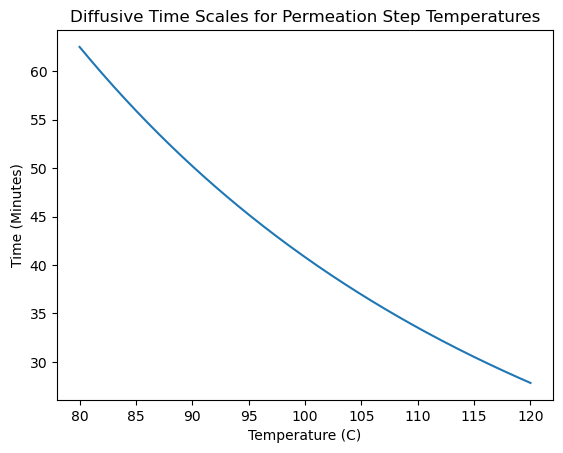

In [17]:
a = 0.02
Ts = np.linspace(80,120,200)+273
Ds = []
for T in Ts:
    Ds.append(swets_K(T, D_out = True))
    
plt.plot(Ts-273, (a**2/np.array(Ds))/60)
plt.title('Diffusive Time Scales for Permeation Step Temperatures')
plt.xlabel('Temperature (C)')
plt.ylabel('Time (Minutes)')
plt.savefig(f"DiffTimeScales.jpg", dpi = 256)

In [50]:
# Calculating decay constants for helium 3 and 4 permeating in glass tubes, units of per sec. ~ 8 Hour mean life. 
ID = 0.0487
OD = 0.0734

G = 2/(np.log(OD/ID)*((ID/2)**2))
T = 100 +273

K4 = swets_K(T)

lam4 = Ratoms * K4 * G * T
lam3 = lam4 * Jones(T)

print(f"Lambda 3He T {T-273}C: {lam3};\t4He: {lam4} ")

Lambda 3He T 100C: 3.6768924105905226e-05;	4He: 3.3938724931998686e-05 


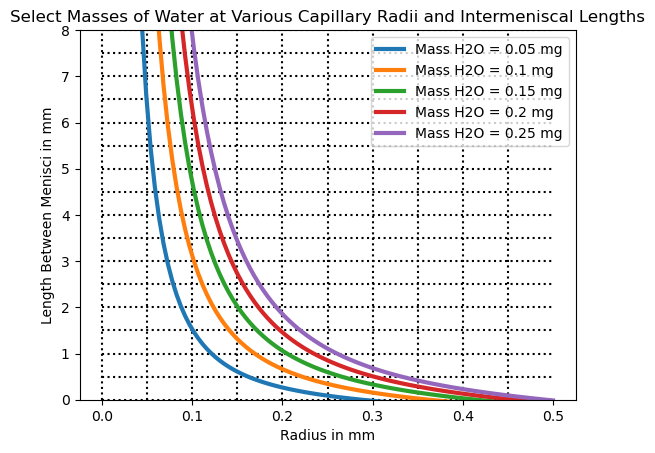

In [2]:
# Reference plot for measuring tiny amounts of liquid water using glass capilaries 

D = 1 #g/cm^3

M = [0.05,0.1,0.15,0.2,0.25] # mg
r = np.linspace(0.025,0.5,100) #mm
plt.hlines(np.arange(18)/2, 0,0.5, linestyles=':', color = 'k')
plt.vlines(np.arange(10)/20, 0,8, linestyles=':', color = 'k')
for m in M:
    plt.plot(r,10*(((m/1000)-((2/3)*np.pi*((r/10)**3)))/(np.pi*((r/10)**2))), linewidth = 3, label = f"Mass H2O = {m} mg")
    
plt.ylim((0,8))

plt.xlabel('Radius in mm')
plt.ylabel('Length Between Menisci in mm')
plt.legend()
plt.title('Select Masses of Water at Various Capillary Radii and Intermeniscal Lengths')
plt.savefig('Capillary_Cheat_Sheet.jpg', dpi = 256)

> 7. **Statement of Assumptions**

Errors are propagated arithmetically when obvious, such as simply adding uncertainties of a blank to the uncertainty of a measurement. When less obvious, Monte Carlo simulations are used to propagate errors. For example, errors are propagated though the isotope dilution equation for U and Th abundances. 

There is an exception for the age equation, because monte carlo simulations are computationally prohibitive for the iterative He age algorithm. For I propagate errors in quadrature with the formula in the notebook. I assume here that I can approximate a partial derivative with a differential. For example:

$\frac{\partial t}{\partial U}*2\sigma_U \approx \frac{(t – t(U + 2\sigma_U)) + (t – t(U - 2\sigma_U))}{2}$

Where t is the age, U is uranium content, and t is the age, and t(U +/- 2sigmaU) is the age evaluated again with the uranium contents shifted up or down 2 sigma, all else held constant. 

Then each parameter’s contribution to the error in quadrature, so the final uncertainty in the age is the square root of the sum of the squares of each parameter’s contribution to the error. This is written out explicitly before the manual age calculator.

Otherwise here are some assumptions Thermochreduction makes: 

1. There is no human error accounted for
2. All analyses are assumed to be spiked exactly the same
3. There is no uncertainty in the abundances in the Normal solution, including uncertainties in the preparation of the normal and in any dilutions when prepping for ICPMS analysis. 
4. Matrix effects are assumed to be identical between the Normal and the samples. 
5. Distributions are assumed to be normally distributed during Monte Carlo simulations
6. All errors are assumed to be independent, which is often true because of normalization. One problem where this is not true: the errors of the spike isotope ratio and the spike elemental abundance are inversely correlated, since the spike abundance is determined through isotope dilution itself and a different isotope ratio implies a different elemental abundance. This effect would be small for Uranium but potentially problematic for Th, since the U spike contributes very little 238U and therefore the abundance determination of U in the spike isn’t very sensitive to the isotope ratio, whereas this is not true with the Th spike. This means I overestimate Th errors in Thermochreduction, since this inverse correlation of uncertainties in the 232Th/230Th ratio and the Th abundance would stabilize the amount of both 232Th and 230Th contribution of the spike to the blend. 

Assumptions for the Alpha recoil corrections: 
1. Grains are spherical 
2. Alpha-emitters are homogenously distributed. 
3. Later I can add complexity to this feature requested, there’s many more thorough treatments in the literature that consider many different crystal geometries. 

Normalization takes care of systematic errors related to ionization efficiency and most instrumental drift. 

> 8. **Works Cited**

1. Shuster, D. L., Vasconcelos, P. M., Heim, J. A. & Farley, K. A. Weathering geochronology by (U-Th)/He dating of goethite. Geochimica et Cosmochimica Acta 69, 659–673 (2005).

2. Farley, K. A., Wolf, R. A. & Silver, L. T. The effects of long alpha-stopping distances on (U‐Th)/He ages. Geochimica et Cosmochimica Acta 60, 4223–4229 (1996).

3. Ketcham, R. A., Gautheron, C. & Tassan-Got, L. Accounting for long alpha-particle stopping distances in (U–Th–Sm)/He geochronology: Refinement of the baseline case. Geochimica et Cosmochimica Acta 75, 7779–7791 (2011).